# 07 — Diffusion Model Training

## Project
**Identity-Preserving Synthetic Ocular Image Generation Using Conditional Diffusion Models**

## Dataset
**CASIA-Iris-Thousand**

## Objective

This notebook implements the diffusion-model component of the project.

The objective is to train a conditional diffusion model capable of generating synthetic ocular images while conditioning the generation process on eye identity.

The generated images will later be evaluated for:

- Image quality
- Identity preservation
- Image diversity
- Recognition performance
- Privacy leakage

## Experimental Pipeline

The overall experimental comparison in this project is:

1. **Baseline** — Original images only
2. **Traditional Augmentation** — Conventional image augmentation
3. **GAN Augmentation** — GAN-generated synthetic images
4. **Diffusion Augmentation** — Diffusion-generated synthetic images

The diffusion experiments use the same CASIA-Iris-Thousand dataset as the previous experiments. The final identity-conditioned experiment additionally uses an identity-disjoint split so that validation and test identities are unseen during training.

### Dataset Configuration

- Total images: 20,000
- Training images: 12,000
- Validation images: 4,000
- Test images: 4,000
- Eye identities: 2,000
- Images per eye identity: 10
- Training images per identity: 6
- Validation images per identity: 2
- Test images per identity: 2
- Image resolution: 224 × 224
- Image type: Grayscale

### Diffusion Concept

A diffusion model consists of two processes:

**Forward diffusion:**

Clean ocular image → progressively add Gaussian noise → nearly pure noise

**Reverse diffusion:**

Random noise → progressively remove noise → synthetic ocular image

The neural network learns to predict the noise added to an image at different diffusion time steps.

In this experiment, the reverse diffusion process is additionally conditioned on the eye identity so that the model can attempt to generate identity-specific ocular images.

### Important Experimental Rule

The validation and test datasets are not used for diffusion-model training.

Only the 12,000 training images are used to learn the generative model.

The validation and test sets will remain reserved for later evaluation.

### Final experiment
The final model is an identity-conditioned diffusion model trained on CASIA-Iris-Thousand.

## Experimental Progression

This notebook contains the development and final training stages of the diffusion experiment.

1. A baseline diffusion model was first developed and tested.
2. The diffusion configuration was adapted for the available 8 GB GPU.
3. The final experiment introduced explicit eye-identity conditioning.
4. The identity-conditioned model was trained for 30 epochs.
5. The best checkpoint was selected using validation loss.
6. Synthetic images were generated and quantitatively evaluated.

The identity-conditioned diffusion model represents the final diffusion experiment used in the project.

In [ ]:
%pip install torch torchvision torchaudio

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Cell 1 — Imports & Environment

import os
import gc
import shutil
import zipfile
import time
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

print("Libraries imported successfully.")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )
else:
    print("Running on CPU.")

Libraries imported successfully.
PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
GPU memory: 8.0 GB


In [ ]:
# Cell 2 — Local Project Paths

from pathlib import Path

# Your local project folder
PROJECT_PATH = Path.home() / "Downloads" / "Ocular_Project"

# Dataset folder
DATASET_PATH = PROJECT_PATH / "datasets"

# Results and model folders
RESULTS_PATH = PROJECT_PATH / "results"
MODELS_PATH = PROJECT_PATH / "models"

# Dataset ZIP
ARCHIVE_PATH = DATASET_PATH / "archive.zip"

# Create folders if they don't exist
DATASET_PATH.mkdir(parents=True, exist_ok=True)
RESULTS_PATH.mkdir(parents=True, exist_ok=True)
MODELS_PATH.mkdir(parents=True, exist_ok=True)

print("Local project paths configured.")
print()
print("Project path :", PROJECT_PATH)
print("Dataset path :", DATASET_PATH)
print("Archive path :", ARCHIVE_PATH)
print("Results path :", RESULTS_PATH)
print("Models path  :", MODELS_PATH)

print()
print("Archive exists:", ARCHIVE_PATH.exists())

Local project paths configured.

Project path : C:\Users\kavya\Downloads\Ocular_Project
Dataset path : C:\Users\kavya\Downloads\Ocular_Project\datasets
Archive path : C:\Users\kavya\Downloads\Ocular_Project\datasets\archive.zip
Results path : C:\Users\kavya\Downloads\Ocular_Project\results
Models path  : C:\Users\kavya\Downloads\Ocular_Project\models

Archive exists: False


In [ ]:
# Cell 3 — Find the Dataset ZIP

from pathlib import Path

downloads = Path.home() / "Downloads"

zip_files = list(downloads.rglob("archive.zip"))

print("Searching for archive.zip inside Downloads...\n")

if zip_files:
    for i, path in enumerate(zip_files, 1):
        print(f"{i}. {path}")
else:
    print("❌ archive.zip was not found inside Downloads.")

Searching for archive.zip inside Downloads...

1. C:\Users\kavya\Downloads\archive.zip


In [ ]:
# Cell 4 — Extract Dataset Locally

import zipfile

ARCHIVE_PATH = Path.home() / "Downloads" / "archive.zip"

if not ARCHIVE_PATH.exists():
    raise FileNotFoundError(f"Dataset ZIP not found: {ARCHIVE_PATH}")

print("Extracting dataset...")
print("From:", ARCHIVE_PATH)
print("To  :", DATASET_PATH)

with zipfile.ZipFile(ARCHIVE_PATH, "r") as zip_ref:
    zip_ref.extractall(DATASET_PATH)

print("\n✅ Dataset extracted successfully!")

Extracting dataset...
From: C:\Users\kavya\Downloads\archive.zip
To  : C:\Users\kavya\Downloads\Ocular_Project\datasets

✅ Dataset extracted successfully!


In [ ]:
# Cell 5 — Check Extracted Dataset

print("Contents of dataset folder:\n")

for item in DATASET_PATH.iterdir():
    if item.is_dir():
        print("📁", item.name)
    else:
        print("📄", item.name)

Contents of dataset folder:

📁 CASIA-Iris-Thousand
📄 iris_thousands.csv


In [ ]:
# Cell 6 — Verify Dataset

IMAGE_DIR = DATASET_PATH / "CASIA-Iris-Thousand"
CSV_PATH = DATASET_PATH / "iris_thousands.csv"

print("Image folder exists:", IMAGE_DIR.exists())
print("CSV exists:", CSV_PATH.exists())

# Count image files
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

image_files = [
    f for f in IMAGE_DIR.rglob("*")
    if f.is_file() and f.suffix.lower() in image_extensions
]

print("Number of images:", len(image_files))

print("\nFirst 5 images:")
for f in image_files[:5]:
    print(f)

Image folder exists: True
CSV exists: True
Number of images: 20000

First 5 images:
C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\999\L\S5999L00.jpg
C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\999\L\S5999L01.jpg
C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\999\L\S5999L02.jpg
C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\999\L\S5999L03.jpg
C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\999\L\S5999L04.jpg


In [ ]:
# Cell 7 — Inspect Dataset CSV

df = pd.read_csv(CSV_PATH)

print("CSV shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

CSV shape: (20000, 3)

Column names:
['Unnamed: 0', 'Label', 'ImagePath']

First 5 rows:


,Unnamed: 0,Label,ImagePath
0,0,437-R,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...
1,1,437-R,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...
2,2,437-R,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...
3,3,437-R,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...
4,4,437-R,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...



Missing values:
Unnamed: 0    0
Label         0
ImagePath     0
dtype: int64


In [ ]:
# Cell 8 — Fix Kaggle Paths to Local Paths

# Create a lookup: filename -> actual local path
image_lookup = {
    path.name: path
    for path in IMAGE_DIR.rglob("*")
    if path.is_file()
}

print("Images indexed:", len(image_lookup))

# Replace Kaggle paths with the actual local paths
df["ImagePath"] = df["ImagePath"].apply(
    lambda x: image_lookup.get(Path(x).name)
)

# Check results
print("\nExample converted paths:\n")

for path in df["ImagePath"].head(5):
    print(path)

print("\nChecking whether the images exist...")

exists = df["ImagePath"].notna() & df["ImagePath"].apply(
    lambda x: x.exists() if x is not None else False
)

print("Images found:", exists.sum())
print("Images missing:", (~exists).sum())

Images indexed: 20001

Example converted paths:

C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\437\R\S5437R06.jpg
C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\437\R\S5437R09.jpg
C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\437\R\S5437R07.jpg
C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\437\R\S5437R02.jpg
C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\437\R\S5437R03.jpg

Checking whether the images exist...
Images found: 20000
Images missing: 0


In [ ]:
# Cell 9 — Check Dataset Labels

print("Number of samples:", len(df))
print("Number of unique labels:", df["Label"].nunique())

print("\nLabel distribution:")
print(df["Label"].value_counts().sort_index().head(20))

print("\nDataset preview:")
display(df[["Label", "ImagePath"]].head())

Number of samples: 20000
Number of unique labels: 2000

Label distribution:
Label
000-L    10
000-R    10
001-L    10
001-R    10
002-L    10
002-R    10
003-L    10
003-R    10
004-L    10
004-R    10
005-L    10
005-R    10
006-L    10
006-R    10
007-L    10
007-R    10
008-L    10
008-R    10
009-L    10
009-R    10
Name: count, dtype: int64

Dataset preview:


,Label,ImagePath
0,437-R,C:\Users\kavya\Downloads\Ocular_Project\datase...
1,437-R,C:\Users\kavya\Downloads\Ocular_Project\datase...
2,437-R,C:\Users\kavya\Downloads\Ocular_Project\datase...
3,437-R,C:\Users\kavya\Downloads\Ocular_Project\datase...
4,437-R,C:\Users\kavya\Downloads\Ocular_Project\datase...


Testing image:
C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\437\R\S5437R06.jpg

Image loaded successfully!
Size: (640, 480)
Mode: L


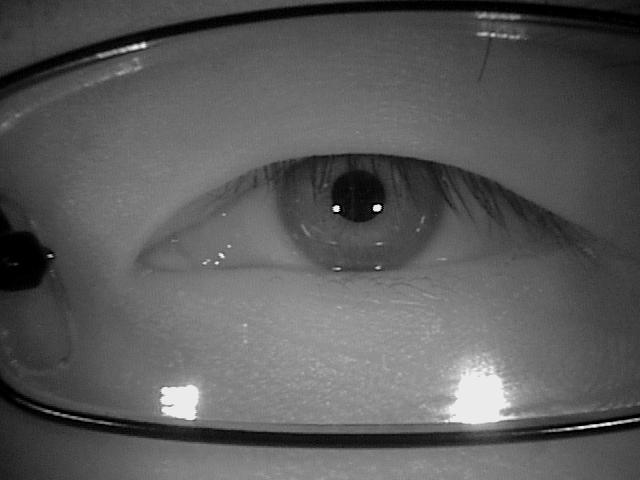

In [ ]:
# Cell 10 — Test Image Loading

sample_path = df["ImagePath"].iloc[0]

print("Testing image:")
print(sample_path)

img = Image.open(sample_path)

print("\nImage loaded successfully!")
print("Size:", img.size)
print("Mode:", img.mode)

display(img)

In [ ]:
# Cell 11 — Check Torchvision

import torchvision
import torchvision.transforms as transforms

print("Torchvision version:", torchvision.__version__)
print("Torchvision imported successfully!")

Torchvision version: 0.26.0+cu128
Torchvision imported successfully!


In [ ]:
# Cell 12 — Diffusion Dataset Class

class DiffusionDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_root,
        image_size=224
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_root = Path(image_root)
        self.image_size = image_size

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["ImagePath"]

        # Load grayscale image
        image = Image.open(image_path).convert("L")

        # Resize
        image = image.resize(
            (self.image_size, self.image_size),
            Image.Resampling.BILINEAR
        )

        # Convert to NumPy
        image = np.array(
            image,
            dtype=np.float32
        )

        # [0, 255] → [0, 1]
        image = image / 255.0

        # [0, 1] → [-1, 1]
        image = (image * 2.0) - 1.0

        # Add channel dimension
        image = np.expand_dims(
            image,
            axis=0
        )

        # Convert to tensor
        image = torch.from_numpy(image)

        return image


print("DiffusionDataset class created successfully.")

DiffusionDataset class created successfully.


In [ ]:
# Cell 13 — Check Existing Train / Validation / Test Split

SPLIT_CSV_PATH = RESULTS_PATH / "CASIA_Thousand_data_split.csv"

print("Looking for split CSV:")
print(SPLIT_CSV_PATH)

print("\nExists:", SPLIT_CSV_PATH.exists())

if SPLIT_CSV_PATH.exists():
    split_df = pd.read_csv(SPLIT_CSV_PATH)

    print("\nSplit CSV loaded successfully.")
    print("Total records:", len(split_df))

    print("\nColumns:")
    print(split_df.columns.tolist())

    print("\nSplit counts:")
    print(split_df["split"].value_counts())

    print("\nUnique identities:")
    print(split_df["identity"].nunique())

Looking for split CSV:
C:\Users\kavya\Downloads\Ocular_Project\results\CASIA_Thousand_data_split.csv

Exists: False


In [ ]:
# Cell 13 — Create the Original 12k / 4k / 4k Split

from sklearn.model_selection import train_test_split

# 2000 identities × 10 images = 20,000 images
# Original notebook split:
# Train      = 12,000
# Validation =  4,000
# Test       =  4,000

# First split: 60% train, 40% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.40,
    random_state=42,
    stratify=df["Label"]
)

# Split remaining 40% equally:
# 20% validation + 20% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["Label"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))

Training samples: 12000
Validation samples: 4000
Test samples: 4000

Total: 20000


In [ ]:
# Cell 14 — Create Train / Validation / Test Datasets

IMAGE_SIZE = 224

train_dataset = DiffusionDataset(
    train_df,
    IMAGE_DIR,
    image_size=IMAGE_SIZE
)

val_dataset = DiffusionDataset(
    val_df,
    IMAGE_DIR,
    image_size=IMAGE_SIZE
)

test_dataset = DiffusionDataset(
    test_df,
    IMAGE_DIR,
    image_size=IMAGE_SIZE
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 12000
Validation dataset: 4000
Test dataset: 4000


In [ ]:
# Cell 16 — Create DataLoaders

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully!")
print("-------------------------------")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully!
-------------------------------
Train batches: 1500
Validation batches: 500
Test batches: 500


In [ ]:
# Cell 17 — Final Diffusion DataLoader Verification

batch = next(iter(train_loader))

print("Final Diffusion DataLoader Verification")
print("---------------------------------------")
print("Batch shape:", batch.shape)
print("Data type:", batch.dtype)
print("Min value:", batch.min().item())
print("Max value:", batch.max().item())

Final Diffusion DataLoader Verification
---------------------------------------
Batch shape: torch.Size([8, 1, 224, 224])
Data type: torch.float32
Min value: -1.0
Max value: 0.8588235378265381


In [ ]:
# Diffusion Dataset Configuration

IMAGE_SIZE = 224
IMAGE_CHANNELS = 1

BATCH_SIZE = 8

DIFFUSION_TIMESTEPS = 1000

BETA_START = 0.0001
BETA_END = 0.02

LEARNING_RATE = 1e-4
EPOCHS = 30

GRADIENT_ACCUMULATION_STEPS = 4

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Diffusion configuration:")
print("------------------------")
print("Image size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Image channels:", IMAGE_CHANNELS)
print("Batch size:", BATCH_SIZE)
print("Effective batch size:",
      BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
print("Diffusion timesteps:", DIFFUSION_TIMESTEPS)
print("Beta start:", BETA_START)
print("Beta end:", BETA_END)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Device:", DEVICE)

Diffusion configuration:
------------------------
Image size: 224 x 224
Image channels: 1
Batch size: 8
Effective batch size: 32
Diffusion timesteps: 1000
Beta start: 0.0001
Beta end: 0.02
Learning rate: 0.0001
Epochs: 30
Device: cuda


In [ ]:
# Cell 14 — Diffusion Noise Schedule

betas = torch.linspace(
    BETA_START,
    BETA_END,
    DIFFUSION_TIMESTEPS,
    device=DEVICE
)

alphas = 1.0 - betas

alpha_cumprod = torch.cumprod(
    alphas,
    dim=0
)

sqrt_alpha_cumprod = torch.sqrt(
    alpha_cumprod
)

sqrt_one_minus_alpha_cumprod = torch.sqrt(
    1.0 - alpha_cumprod
)

print("Diffusion noise schedule created successfully.")
print("-----------------------------------------------")
print("Number of timesteps:", DIFFUSION_TIMESTEPS)
print("Beta shape:", betas.shape)
print("Alpha shape:", alphas.shape)
print("Alpha cumulative product shape:",
      alpha_cumprod.shape)

print()
print("First beta:", betas[0].item())
print("Last beta:", betas[-1].item())

print(
    "First alpha cumulative product:",
    alpha_cumprod[0].item()
)

print(
    "Last alpha cumulative product:",
    alpha_cumprod[-1].item()
)

Diffusion noise schedule created successfully.
-----------------------------------------------
Number of timesteps: 1000
Beta shape: torch.Size([1000])
Alpha shape: torch.Size([1000])
Alpha cumulative product shape: torch.Size([1000])

First beta: 9.999999747378752e-05
Last beta: 0.019999999552965164
First alpha cumulative product: 0.9998999834060669
Last alpha cumulative product: 4.035829260828905e-05


In [ ]:
# Cell 15 — Forward Diffusion Function

def forward_diffusion(images, timesteps):

    # Get the required coefficients for each timestep
    sqrt_alpha = sqrt_alpha_cumprod[timesteps]

    sqrt_one_minus_alpha = (
        sqrt_one_minus_alpha_cumprod[timesteps]
    )

    # Reshape for broadcasting across image dimensions
    sqrt_alpha = sqrt_alpha.view(
        -1, 1, 1, 1
    )

    sqrt_one_minus_alpha = sqrt_one_minus_alpha.view(
        -1, 1, 1, 1
    )

    # Generate Gaussian noise
    noise = torch.randn_like(images)

    # Forward diffusion equation
    noisy_images = (
        sqrt_alpha * images
        + sqrt_one_minus_alpha * noise
    )

    return noisy_images, noise


print("Forward diffusion function created successfully.")

Forward diffusion function created successfully.


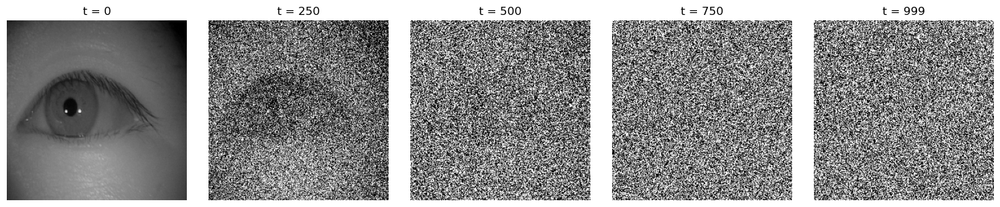

Forward diffusion visualization completed successfully.


In [ ]:
# Cell 16 — Visualize Forward Diffusion at Different Timesteps

import matplotlib.pyplot as plt

# Get one clean image
clean_image = train_dataset[0].unsqueeze(0).to(DEVICE)

# Timesteps to visualize
visualization_timesteps = [0, 250, 500, 750, 999]

fig, axes = plt.subplots(
    1,
    len(visualization_timesteps),
    figsize=(15, 3)
)

for ax, timestep in zip(
    axes,
    visualization_timesteps
):

    t = torch.tensor(
        [timestep],
        device=DEVICE
    )

    noisy_image, _ = forward_diffusion(
        clean_image,
        t
    )

    # Move to CPU for visualization
    image = noisy_image[0, 0].detach().cpu().numpy()

    ax.imshow(
        image,
        cmap="gray",
        vmin=-1,
        vmax=1
    )

    ax.set_title(f"t = {timestep}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Forward diffusion visualization completed successfully.")

In [ ]:
# Cell 17 — Diffusion U-Net

class SinusoidalTimeEmbedding(nn.Module):

    def __init__(self, embedding_dim):
        super().__init__()

        self.embedding_dim = embedding_dim

    def forward(self, timesteps):

        half_dim = self.embedding_dim // 2

        embeddings = torch.log(
            torch.tensor(
                10000.0,
                device=timesteps.device
            )
        ) / (half_dim - 1)

        embeddings = torch.exp(
            torch.arange(
                half_dim,
                device=timesteps.device
            ) * -embeddings
        )

        embeddings = timesteps.float()[:, None] * embeddings[None, :]

        embeddings = torch.cat(
            [
                torch.sin(embeddings),
                torch.cos(embeddings)
            ],
            dim=1
        )

        return embeddings


print("SinusoidalTimeEmbedding defined successfully.")

SinusoidalTimeEmbedding defined successfully.


In [ ]:
# Cell 17 — Diffusion U-Net

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.GroupNorm(
                8,
                out_channels
            ),
            nn.SiLU(),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.GroupNorm(
                8,
                out_channels
            ),
            nn.SiLU()
        )

    def forward(self, x):
        return self.block(x)


class DiffusionUNet(nn.Module):

    def __init__(self, in_channels=1, time_dim=128):
        super().__init__()

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU()
        )

        # Encoder
        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(256, 512)

        # Decoder
        self.up3 = nn.ConvTranspose2d(
            512,
            256,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(
            512,
            256
        )

        self.up2 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            256,
            128
        )

        self.up1 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            128,
            64
        )

        self.output = nn.Conv2d(
            64,
            in_channels,
            kernel_size=1
        )

        # Time projections
        self.time1 = nn.Linear(time_dim, 64)
        self.time2 = nn.Linear(time_dim, 128)
        self.time3 = nn.Linear(time_dim, 256)
        self.time4 = nn.Linear(time_dim, 512)

    def forward(self, x, timesteps):

        t = self.time_embedding(timesteps)

        # Encoder
        e1 = self.enc1(x)
        e1 = e1 + self.time1(t)[:, :, None, None]

        e2 = self.enc2(self.pool(e1))
        e2 = e2 + self.time2(t)[:, :, None, None]

        e3 = self.enc3(self.pool(e2))
        e3 = e3 + self.time3(t)[:, :, None, None]

        # Bottleneck
        b = self.bottleneck(self.pool(e3))
        b = b + self.time4(t)[:, :, None, None]

        # Decoder
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.output(d1)


print("Diffusion U-Net class created successfully.")

Diffusion U-Net class created successfully.


In [ ]:
# Cell 18 — Initialize Diffusion U-Net

diffusion_model = DiffusionUNet(
    in_channels=IMAGE_CHANNELS,
    time_dim=128
).to(DEVICE)

diffusion_model.eval()

# Get one batch
test_images = next(iter(train_loader)).to(DEVICE)

# Random timesteps
test_timesteps = torch.randint(
    0,
    DIFFUSION_TIMESTEPS,
    (test_images.size(0),),
    device=DEVICE
)

# Add noise
test_noisy_images, test_noise = forward_diffusion(
    test_images,
    test_timesteps
)

# Test model forward pass
with torch.no_grad():
    predicted_noise = diffusion_model(
        test_noisy_images,
        test_timesteps
    )

print("Diffusion U-Net initialized successfully.")
print("----------------------------------------")
print("Model device:", next(diffusion_model.parameters()).device)
print("Input shape:", test_images.shape)
print("Noisy image shape:", test_noisy_images.shape)
print("Actual noise shape:", test_noise.shape)
print("Predicted noise shape:", predicted_noise.shape)

print()
print(
    "Model parameters:",
    sum(p.numel() for p in diffusion_model.parameters())
)

print()

if predicted_noise.shape == test_noise.shape:
    print("Shape verification: PASSED ✅")
else:
    print("Shape verification: FAILED ❌")

print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

print(
    "GPU memory reserved:",
    round(torch.cuda.memory_reserved() / 1024**3, 2),
    "GB"
)

Diffusion U-Net initialized successfully.
----------------------------------------
Model device: cuda:0
Input shape: torch.Size([8, 1, 224, 224])
Noisy image shape: torch.Size([8, 1, 224, 224])
Actual noise shape: torch.Size([8, 1, 224, 224])
Predicted noise shape: torch.Size([8, 1, 224, 224])

Model parameters: 7842177

Shape verification: PASSED ✅
GPU memory allocated: 0.05 GB
GPU memory reserved: 1.04 GB


In [ ]:
# Cell — Diffusion Training Setup

import os
import time
import torch
import torch.nn as nn
from tqdm.auto import tqdm

# --------------------------------------------------
# Paths
# --------------------------------------------------

RESULTS_DIR = str(RESULTS_PATH)
MODELS_DIR = str(MODELS_PATH)

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# --------------------------------------------------
# Training configuration
# --------------------------------------------------

DIFFUSION_EPOCHS = 30
DIFFUSION_BATCH_SIZE = 8
GRADIENT_ACCUMULATION_STEPS = 4
DIFFUSION_LR = 1e-4

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# --------------------------------------------------
# Model saving paths
# --------------------------------------------------

BEST_MODEL_PATH = os.path.join(
    MODELS_DIR,
    "CASIA_Thousand_diffusion_unet_224_best.pth"
)

HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "CASIA_Thousand_diffusion_training_history_224.csv"
)

# --------------------------------------------------
# Loss and optimizer
# --------------------------------------------------

criterion = nn.MSELoss()

optimizer = torch.optim.AdamW(
    diffusion_model.parameters(),
    lr=DIFFUSION_LR
)

# --------------------------------------------------
# Mixed precision
# --------------------------------------------------

if DEVICE.type == "cuda":
    scaler = torch.amp.GradScaler("cuda")
    mixed_precision_enabled = True
else:
    scaler = None
    mixed_precision_enabled = False

# --------------------------------------------------
# Verification
# --------------------------------------------------

print("Diffusion training setup created successfully.")
print("-" * 50)
print("Epochs:", DIFFUSION_EPOCHS)
print("Batch size:", DIFFUSION_BATCH_SIZE)
print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)
print(
    "Effective batch size:",
    DIFFUSION_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
)
print("Learning rate:", DIFFUSION_LR)
print("Loss function: MSELoss")
print("Optimizer: AdamW")
print("Mixed precision:", "Enabled" if mixed_precision_enabled else "Disabled")
print("Device:", DEVICE)
print("Models directory:", MODELS_DIR)
print("Results directory:", RESULTS_DIR)
print("Best model path:", BEST_MODEL_PATH)
print("History path:", HISTORY_PATH)

Diffusion training setup created successfully.
--------------------------------------------------
Epochs: 30
Batch size: 8
Gradient accumulation: 4
Effective batch size: 32
Learning rate: 0.0001
Loss function: MSELoss
Optimizer: AdamW
Mixed precision: Enabled
Device: cuda
Models directory: C:\Users\kavya\Downloads\Ocular_Project\models
Results directory: C:\Users\kavya\Downloads\Ocular_Project\results
Best model path: C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth
History path: C:\Users\kavya\Downloads\Ocular_Project\results\CASIA_Thousand_diffusion_training_history_224.csv


In [ ]:
import subprocess
import shutil
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("PyTorch CUDA build:", torch.version.cuda)

if shutil.which("nvidia-smi"):
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True
    )
    print("\n===== NVIDIA GPU / DRIVER =====")
    print(result.stdout[:4000])
else:
    print("\n❌ nvidia-smi was not found.")

PyTorch version: 2.11.0+cu128
CUDA available: True
PyTorch CUDA build: 12.8

===== NVIDIA GPU / DRIVER =====
Fri Sep 25 16:19:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 592.82                 Driver Version: 592.82         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4060 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   49C    P8              1W /  135W |    1177MiB /   8188MiB |      0%      Default |
|                              

In [ ]:
%pip uninstall -y torch torchvision torchaudio

Found existing installation: torch 2.14.0
Uninstalling torch-2.14.0:
  Successfully uninstalled torch-2.14.0
Found existing installation: torchvision 0.29.0
Uninstalling torchvision-0.29.0:
  Successfully uninstalled torchvision-0.29.0
Found existing installation: torchaudio 2.11.0
Uninstalling torchaudio-2.11.0:
  Successfully uninstalled torchaudio-2.11.0
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.
You can safely remove it manually.


In [ ]:
%pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128

Looking in indexes: https://download.pytorch.org/whl/cu128
   ---------------------------------------- 0.0/2.8 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.8 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.8 GB 6.0 MB/s eta 0:07:41
   ---------------------------------------- 0.0/2.8 GB 6.2 MB/s eta 0:07:27
   ---------------------------------------- 0.0/2.8 GB 7.0 MB/s eta 0:06:35
   ---------------------------------------- 0.0/2.8 GB 7.9 MB/s eta 0:05:48
   ---------------------------------------- 0.0/2.8 GB 9.0 MB/s eta 0:05:04
   ---------------------------------------- 0.0/2.8 GB 9.8 MB/s eta 0:04:40
   ---------------------------------------- 0.0/2.8 GB 10.5 MB/s eta 0:04:22
   ---------------------------------------- 0.0/2.8 GB 10.7 MB/s eta 0:04:15
   ---------------------------------------- 0.0/2.8 GB 11.0 MB/s eta 0:04:08
   ---------------------------------------- 0.0/2.8 GB 11.4 MB/s eta 0:04:00
   ------------------------------------

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

PyTorch version: 2.11.0+cu128
CUDA available: True
CUDA version: 12.8
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
GPU memory: 8.0 GB


Sample loaded successfully!
---------------------------
Tensor shape: torch.Size([1, 224, 224])
Data type: torch.float32
Min value: -1.0
Max value: 0.8509804010391235


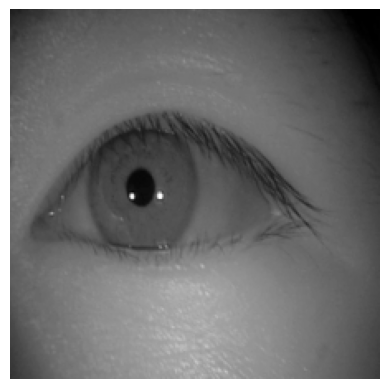

In [ ]:
# Cell 15 — Test Training Dataset

sample_image = train_dataset[0]

print("Sample loaded successfully!")
print("---------------------------")
print("Tensor shape:", sample_image.shape)
print("Data type:", sample_image.dtype)
print("Min value:", sample_image.min().item())
print("Max value:", sample_image.max().item())

plt.imshow(sample_image.squeeze(0), cmap="gray")
plt.axis("off")
plt.show()

In [ ]:
# Recreate Diffusion U-Net on the CUDA GPU

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

diffusion_model = DiffusionUNet(
    in_channels=IMAGE_CHANNELS,
    time_dim=128
).to(DEVICE)

diffusion_model.eval()

print("Diffusion U-Net recreated successfully.")
print("Device:", DEVICE)
print("Parameters:", sum(p.numel() for p in diffusion_model.parameters()))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Diffusion U-Net recreated successfully.
Device: cuda
Parameters: 7842177
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [ ]:
# Diffusion Training Setup

import os
import time
import torch
import torch.nn as nn
from tqdm.auto import tqdm

RESULTS_DIR = str(RESULTS_PATH)
MODELS_DIR = str(MODELS_PATH)

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

DIFFUSION_EPOCHS = 30
DIFFUSION_BATCH_SIZE = 8
GRADIENT_ACCUMULATION_STEPS = 4
DIFFUSION_LR = 1e-4

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BEST_MODEL_PATH = os.path.join(
    MODELS_DIR,
    "CASIA_Thousand_diffusion_unet_224_best.pth"
)

HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "CASIA_Thousand_diffusion_training_history_224.csv"
)

criterion = nn.MSELoss()

optimizer = torch.optim.AdamW(
    diffusion_model.parameters(),
    lr=DIFFUSION_LR
)

if DEVICE.type == "cuda":
    scaler = torch.amp.GradScaler("cuda")
    mixed_precision_enabled = True
else:
    scaler = None
    mixed_precision_enabled = False

print("Diffusion training setup created successfully.")
print("-" * 50)
print("Epochs:", DIFFUSION_EPOCHS)
print("Batch size:", DIFFUSION_BATCH_SIZE)
print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)
print(
    "Effective batch size:",
    DIFFUSION_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
)
print("Learning rate:", DIFFUSION_LR)
print("Loss function: MSELoss")
print("Optimizer: AdamW")
print(
    "Mixed precision:",
    "Enabled" if mixed_precision_enabled else "Disabled"
)
print("Device:", DEVICE)
print("Models directory:", MODELS_DIR)
print("Results directory:", RESULTS_DIR)
print("Best model path:", BEST_MODEL_PATH)
print("History path:", HISTORY_PATH)

Diffusion training setup created successfully.
--------------------------------------------------
Epochs: 30
Batch size: 8
Gradient accumulation: 4
Effective batch size: 32
Learning rate: 0.0001
Loss function: MSELoss
Optimizer: AdamW
Mixed precision: Enabled
Device: cuda
Models directory: C:\Users\kavya\Downloads\Ocular_Project\models
Results directory: C:\Users\kavya\Downloads\Ocular_Project\results
Best model path: C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth
History path: C:\Users\kavya\Downloads\Ocular_Project\results\CASIA_Thousand_diffusion_training_history_224.csv


In [ ]:
# Diffusion U-Net CUDA Forward-Pass Verification

diffusion_model.eval()

# Get one batch
test_images = next(iter(train_loader)).to(DEVICE)

# Random timesteps
test_timesteps = torch.randint(
    0,
    DIFFUSION_TIMESTEPS,
    (test_images.size(0),),
    device=DEVICE
)

# Add noise
test_noisy_images, test_noise = forward_diffusion(
    test_images,
    test_timesteps
)

# Test model forward pass
with torch.no_grad():
    predicted_noise = diffusion_model(
        test_noisy_images,
        test_timesteps
    )

print("Diffusion U-Net CUDA verification")
print("----------------------------------------")
print("Model device:", next(diffusion_model.parameters()).device)
print("Input shape:", test_images.shape)
print("Noisy image shape:", test_noisy_images.shape)
print("Actual noise shape:", test_noise.shape)
print("Predicted noise shape:", predicted_noise.shape)

print()
print(
    "Model parameters:",
    sum(p.numel() for p in diffusion_model.parameters())
)

print()

if predicted_noise.shape == test_noise.shape:
    print("Shape verification: PASSED ✅")
else:
    print("Shape verification: FAILED ❌")

print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

print(
    "GPU memory reserved:",
    round(torch.cuda.memory_reserved() / 1024**3, 2),
    "GB"
)

Diffusion U-Net CUDA verification
----------------------------------------
Model device: cuda:0
Input shape: torch.Size([8, 1, 224, 224])
Noisy image shape: torch.Size([8, 1, 224, 224])
Actual noise shape: torch.Size([8, 1, 224, 224])
Predicted noise shape: torch.Size([8, 1, 224, 224])

Model parameters: 7842177

Shape verification: PASSED ✅
GPU memory allocated: 0.05 GB
GPU memory reserved: 1.04 GB


In [ ]:
# Cell — Memory-Efficient Diffusion Model Training

import csv
import gc
import torch
from tqdm.auto import tqdm

print("Starting diffusion model training...")
print("=" * 70)

# Make sure model is in training mode
diffusion_model.train()

best_val_loss = float("inf")
training_history = []

for epoch in range(1, DIFFUSION_EPOCHS + 1):

    epoch_start = time.time()

    # --------------------------------------------------
    # TRAINING
    # --------------------------------------------------

    diffusion_model.train()

    train_loss = 0.0
    optimizer.zero_grad(set_to_none=True)

    train_progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{DIFFUSION_EPOCHS} [Train]",
        leave=True
    )

    for batch_idx, images in enumerate(train_progress):

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        # Random diffusion timestep for every image
        timesteps = torch.randint(
            0,
            DIFFUSION_TIMESTEPS,
            (images.size(0),),
            device=DEVICE
        ).long()

        # --------------------------------------------------
        # Mixed precision forward pass
        # --------------------------------------------------

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            # Add noise using forward diffusion
            noisy_images, actual_noise = forward_diffusion(
                images,
                timesteps
            )

            # Predict the noise
            predicted_noise = diffusion_model(
                noisy_images,
                timesteps
            )

            # Calculate loss
            loss = criterion(
                predicted_noise,
                actual_noise
            )

            # Scale for gradient accumulation
            loss = loss / GRADIENT_ACCUMULATION_STEPS

        # --------------------------------------------------
        # Backpropagation
        # --------------------------------------------------

        scaler.scale(loss).backward()

        # Update after accumulation steps
        if (
            (batch_idx + 1) % GRADIENT_ACCUMULATION_STEPS == 0
            or (batch_idx + 1) == len(train_loader)
        ):

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(set_to_none=True)

        # Original loss before division
        batch_loss = loss.item() * GRADIENT_ACCUMULATION_STEPS
        train_loss += batch_loss

        train_progress.set_postfix(
            loss=f"{batch_loss:.4f}"
        )

        # Release batch tensors
        del images
        del timesteps
        del noisy_images
        del actual_noise
        del predicted_noise
        del loss

    # Average training loss
    avg_train_loss = train_loss / len(train_loader)

    # --------------------------------------------------
    # VALIDATION
    # --------------------------------------------------

    diffusion_model.eval()

    val_loss = 0.0

    with torch.no_grad():

        val_progress = tqdm(
            val_loader,
            desc=f"Epoch {epoch}/{DIFFUSION_EPOCHS} [Val]",
            leave=True
        )

        for images in val_progress:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            timesteps = torch.randint(
                0,
                DIFFUSION_TIMESTEPS,
                (images.size(0),),
                device=DEVICE
            ).long()

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                noisy_images, actual_noise = forward_diffusion(
                    images,
                    timesteps
                )

                predicted_noise = diffusion_model(
                    noisy_images,
                    timesteps
                )

                loss = criterion(
                    predicted_noise,
                    actual_noise
                )

            val_loss += loss.item()

            val_progress.set_postfix(
                loss=f"{loss.item():.4f}"
            )

            del images
            del timesteps
            del noisy_images
            del actual_noise
            del predicted_noise
            del loss

    avg_val_loss = val_loss / len(val_loader)

    epoch_time = time.time() - epoch_start

    # --------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------

    training_history.append({
        "epoch": epoch,
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss,
        "epoch_time_seconds": epoch_time
    })

    # --------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------

    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss

        torch.save(
            diffusion_model.state_dict(),
            BEST_MODEL_PATH
        )

        best_status = "✓ BEST MODEL SAVED"

    else:
        best_status = ""

    # --------------------------------------------------
    # SAVE HISTORY CSV
    # --------------------------------------------------

    with open(
        HISTORY_PATH,
        "w",
        newline=""
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=[
                "epoch",
                "train_loss",
                "val_loss",
                "epoch_time_seconds"
            ]
        )

        writer.writeheader()
        writer.writerows(training_history)

    # --------------------------------------------------
    # CLEAN GPU MEMORY
    # --------------------------------------------------

    gc.collect()
    torch.cuda.empty_cache()

    print()
    print(
        f"Epoch {epoch}/{DIFFUSION_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.6f} | "
        f"Val Loss: {avg_val_loss:.6f} | "
        f"Time: {epoch_time/60:.2f} min "
        f"{best_status}"
    )
    print("-" * 70)

print()
print("=" * 70)
print("Diffusion training completed successfully.")
print("Best validation loss:", best_val_loss)
print("Best model saved to:", BEST_MODEL_PATH)
print("Training history saved to:", HISTORY_PATH)
print("=" * 70)

Starting diffusion model training...


Epoch 1/30 [Train]:   0%|          | 0/1500 [00:00<?, ?it/s]

Epoch 1/30 [Val]:   0%|          | 0/500 [00:00<?, ?it/s]


Epoch 1/30 | Train Loss: 0.042894 | Val Loss: 0.014707 | Time: 5.21 min ✓ BEST MODEL SAVED
----------------------------------------------------------------------


Epoch 2/30 [Train]:   0%|          | 0/1500 [00:00<?, ?it/s]

...

Epoch 29/30 [Val]:   0%|          | 0/500 [00:00<?, ?it/s]


Epoch 29/30 | Train Loss: 0.007129 | Val Loss: 0.007108 | Time: 5.25 min 
----------------------------------------------------------------------


Epoch 30/30 [Train]:   0%|          | 0/1500 [00:00<?, ?it/s]

Epoch 30/30 [Val]:   0%|          | 0/500 [00:00<?, ?it/s]


Epoch 30/30 | Train Loss: 0.007535 | Val Loss: 0.007749 | Time: 5.18 min 
----------------------------------------------------------------------

Diffusion training completed successfully.
Best validation loss: 0.006872345816023881
Best model saved to: C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth
Training history saved to: C:\Users\kavya\Downloads\Ocular_Project\results\CASIA_Thousand_diffusion_training_history_224.csv


In [ ]:
# Cell — Load Best Trained Diffusion Checkpoint

import os
import torch

# Local project paths
PROJECT_PATH = r"C:\Users\kavya\Downloads\Ocular_Project"

MODELS_DIR = os.path.join(
    PROJECT_PATH,
    "models"
)

BEST_MODEL_PATH = os.path.join(
    MODELS_DIR,
    "CASIA_Thousand_diffusion_unet_224_best.pth"
)

print("Checkpoint path:")
print(BEST_MODEL_PATH)

if not os.path.exists(BEST_MODEL_PATH):
    raise FileNotFoundError(
        f"Trained checkpoint not found:\n{BEST_MODEL_PATH}"
    )

# Load weights
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE
)

# Load into the same architecture used during training
diffusion_model.load_state_dict(
    checkpoint
)

diffusion_model = diffusion_model.to(DEVICE)
diffusion_model.eval()

print("\nTrained diffusion model loaded successfully.")
print("Device:", next(diffusion_model.parameters()).device)
print(
    "Parameters:",
    sum(p.numel() for p in diffusion_model.parameters())
)

print("Checkpoint verification: PASSED ✅")

Checkpoint path:
C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth

Trained diffusion model loaded successfully.
Device: cuda:0
Parameters: 7842177
Checkpoint verification: PASSED ✅


In [ ]:
# Cell — Reverse Diffusion Sampler

@torch.no_grad()
def reverse_diffusion_sample(
    model,
    num_samples,
    image_size=224,
    device=DEVICE
):
    model.eval()

    # Start from pure Gaussian noise
    x = torch.randn(
        num_samples,
        IMAGE_CHANNELS,
        image_size,
        image_size,
        device=device
    )

    for timestep in tqdm(
        reversed(range(DIFFUSION_TIMESTEPS)),
        total=DIFFUSION_TIMESTEPS,
        desc="Generating images"
    ):

        t = torch.full(
            (num_samples,),
            timestep,
            device=device,
            dtype=torch.long
        )

        # Predict noise
        predicted_noise = model(
            x,
            t
        )

        beta_t = betas[timestep]
        alpha_t = alphas[timestep]
        alpha_bar_t = alpha_cumprod[timestep]

        # DDPM mean
        x = (
            1 / torch.sqrt(alpha_t)
        ) * (
            x -
            (
                beta_t /
                torch.sqrt(1 - alpha_bar_t)
            ) * predicted_noise
        )

        # Add noise except at final timestep
        if timestep > 0:

            noise = torch.randn_like(x)

            x = x + torch.sqrt(beta_t) * noise

    # Keep generated values in valid range
    x = torch.clamp(x, -1.0, 1.0)

    return x


print("Reverse diffusion sampler created successfully.")

Reverse diffusion sampler created successfully.


In [ ]:
# Cell — Generate 4 Test Samples

test_samples = reverse_diffusion_sample(
    model=diffusion_model,
    num_samples=4,
    image_size=224,
    device=DEVICE
)

print("Generated tensor shape:", test_samples.shape)
print("Min value:", test_samples.min().item())
print("Max value:", test_samples.max().item())
print("Generation test completed successfully.")

Generating images:   0%|          | 0/1000 [00:00<?, ?it/s]

Generated tensor shape: torch.Size([4, 1, 224, 224])
Min value: -1.0
Max value: 1.0
Generation test completed successfully.


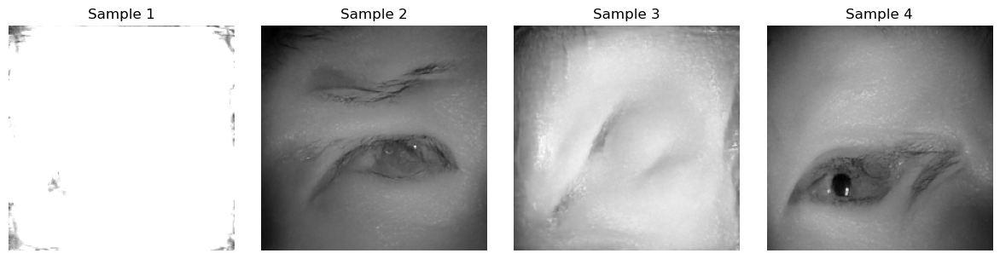

In [ ]:
# Cell — Visualize Generated Samples

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for i in range(4):
    image = test_samples[i].squeeze(0).detach().cpu()

    # Convert [-1, 1] → [0, 1]
    image = (image + 1) / 2

    axes[i].imshow(image, cmap="gray")
    axes[i].set_title(f"Sample {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

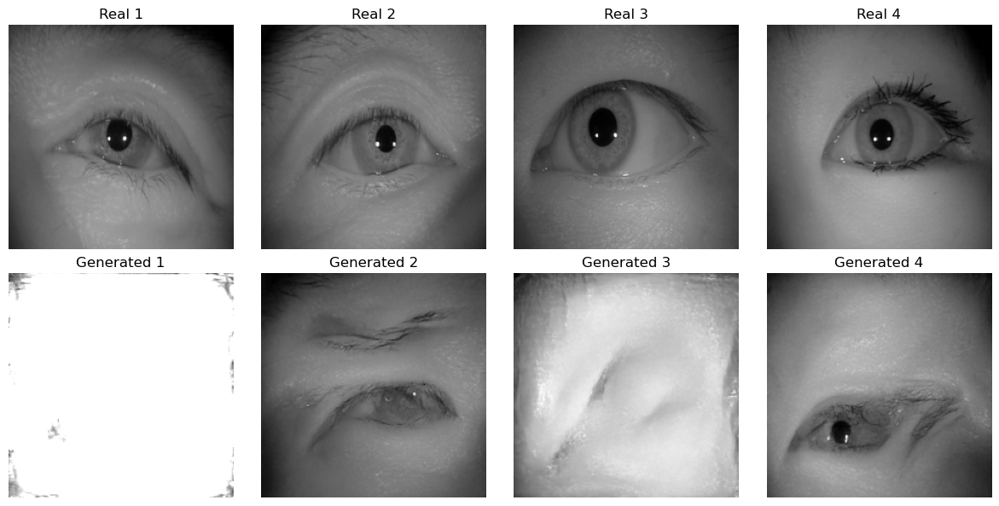

In [ ]:
# Cell — Compare Real vs Generated Images

import matplotlib.pyplot as plt

# Your DataLoader returns the image tensor directly
real_images = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

# ---- Real images ----
for i in range(4):
    image = real_images[i].squeeze(0).cpu()

    # [-1, 1] -> [0, 1]
    image = (image + 1) / 2

    axes[0, i].imshow(image, cmap="gray")
    axes[0, i].set_title(f"Real {i+1}")
    axes[0, i].axis("off")

# ---- Generated images ----
for i in range(4):
    image = test_samples[i].squeeze(0).detach().cpu()

    # [-1, 1] -> [0, 1]
    image = (image + 1) / 2

    axes[1, i].imshow(image, cmap="gray")
    axes[1, i].set_title(f"Generated {i+1}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell — Correct DDPM Reverse Diffusion Sampler

@torch.no_grad()
def reverse_diffusion_sample(
    model,
    num_samples,
    image_size=224,
    device=DEVICE
):
    model.eval()

    # Start from pure Gaussian noise
    x = torch.randn(
        num_samples,
        IMAGE_CHANNELS,
        image_size,
        image_size,
        device=device
    )

    for timestep in tqdm(
        reversed(range(DIFFUSION_TIMESTEPS)),
        total=DIFFUSION_TIMESTEPS,
        desc="Generating images"
    ):

        t = torch.full(
            (num_samples,),
            timestep,
            device=device,
            dtype=torch.long
        )

        # Predict noise
        predicted_noise = model(x, t)

        beta_t = betas[timestep]
        alpha_t = alphas[timestep]
        alpha_bar_t = alpha_cumprod[timestep]

        # Previous cumulative alpha
        if timestep > 0:
            alpha_bar_prev = alpha_cumprod[timestep - 1]
        else:
            alpha_bar_prev = torch.tensor(
                1.0,
                device=device,
                dtype=alpha_bar_t.dtype
            )

        # DDPM posterior variance:
        # beta_tilde = beta_t * (1 - alpha_bar_prev) / (1 - alpha_bar_t)
        posterior_variance = (
            beta_t
            * (1.0 - alpha_bar_prev)
            / (1.0 - alpha_bar_t)
        )

        # DDPM posterior mean
        mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            x
            - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            ) * predicted_noise
        )

        # Add stochastic noise except at t = 0
        if timestep > 0:
            noise = torch.randn_like(x)
            x = mean + torch.sqrt(posterior_variance) * noise
        else:
            x = mean

    # Convert to valid model output range
    x = torch.clamp(x, -1.0, 1.0)

    return x


print("Corrected DDPM reverse sampler created successfully.")

Corrected DDPM reverse sampler created successfully.


In [ ]:
# Cell — Test Corrected DDPM Sampling

corrected_samples = reverse_diffusion_sample(
    model=diffusion_model,
    num_samples=4,
    image_size=224,
    device=DEVICE
)

print("Generated tensor shape:", corrected_samples.shape)
print("Min value:", corrected_samples.min().item())
print("Max value:", corrected_samples.max().item())
print("Corrected sampling test completed successfully.")

Generating images:   0%|          | 0/1000 [00:00<?, ?it/s]

Generated tensor shape: torch.Size([4, 1, 224, 224])
Min value: -1.0
Max value: 1.0
Corrected sampling test completed successfully.


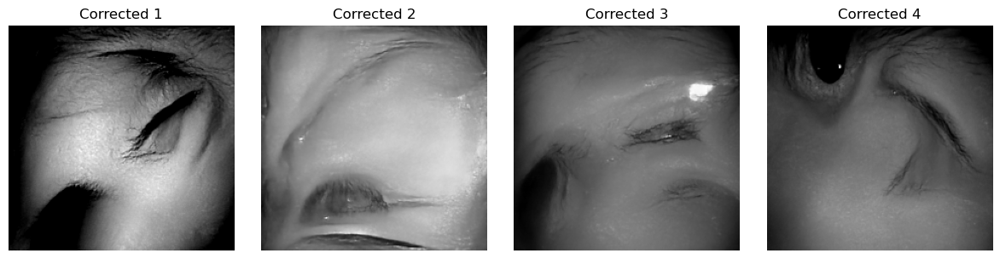

In [ ]:
# Cell — Visualize Corrected Samples

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for i in range(4):
    image = corrected_samples[i].squeeze(0).detach().cpu()

    # [-1, 1] -> [0, 1]
    image = (image + 1) / 2

    axes[i].imshow(image, cmap="gray")
    axes[i].set_title(f"Corrected {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell — Check Noise Prediction on a Real Image

import torch
import matplotlib.pyplot as plt

# Take one real image
real_image = next(iter(train_loader))[0:1].to(DEVICE)

# Test at a middle diffusion timestep
test_timestep = 500
t = torch.tensor([test_timestep], device=DEVICE, dtype=torch.long)

# Generate known Gaussian noise
true_noise = torch.randn_like(real_image)

# Forward diffusion
alpha_bar = alpha_cumprod[test_timestep]

noisy_image = (
    torch.sqrt(alpha_bar) * real_image
    + torch.sqrt(1 - alpha_bar) * true_noise
)

# Model prediction
with torch.no_grad():
    predicted_noise = diffusion_model(noisy_image, t)

# Compare prediction numerically
mse = torch.mean(
    (predicted_noise - true_noise) ** 2
).item()

print("Test timestep:", test_timestep)
print("True noise shape:", true_noise.shape)
print("Predicted noise shape:", predicted_noise.shape)
print("Noise prediction MSE:", mse)

Test timestep: 500
True noise shape: torch.Size([1, 1, 224, 224])
Predicted noise shape: torch.Size([1, 1, 224, 224])
Noise prediction MSE: 0.0008074661600403488


Timestep: 500
Reconstruction MSE: 0.011111490428447723


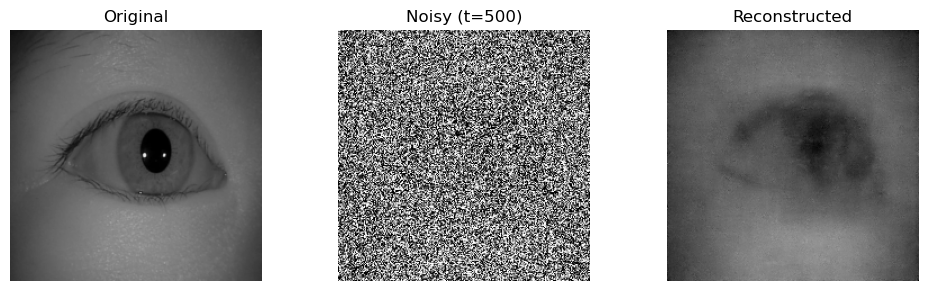

In [ ]:
# Cell — Test x0 Reconstruction from Predicted Noise

import matplotlib.pyplot as plt

diffusion_model.eval()

# Take one real image
real_image = next(iter(train_loader))[0:1].to(DEVICE)

# Use a moderately noisy timestep
test_timestep = 500
t = torch.tensor(
    [test_timestep],
    device=DEVICE,
    dtype=torch.long
)

# Add known noise
true_noise = torch.randn_like(real_image)

alpha_bar = alpha_cumprod[test_timestep]

noisy_image = (
    torch.sqrt(alpha_bar) * real_image
    + torch.sqrt(1.0 - alpha_bar) * true_noise
)

# Predict the noise
with torch.no_grad():
    predicted_noise = diffusion_model(
        noisy_image,
        t
    )

# Reconstruct x0 from predicted noise
reconstructed = (
    noisy_image
    - torch.sqrt(1.0 - alpha_bar) * predicted_noise
) / torch.sqrt(alpha_bar)

reconstructed = torch.clamp(
    reconstructed,
    -1.0,
    1.0
)

# Calculate reconstruction MSE
reconstruction_mse = torch.mean(
    (reconstructed - real_image) ** 2
).item()

print("Timestep:", test_timestep)
print("Reconstruction MSE:", reconstruction_mse)

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(10, 3))

images = [
    real_image[0, 0].detach().cpu(),
    noisy_image[0, 0].detach().cpu(),
    reconstructed[0, 0].detach().cpu()
]

titles = [
    "Original",
    "Noisy (t=500)",
    "Reconstructed"
]

for ax, image, title in zip(axes, images, titles):
    image = (image + 1) / 2

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell — Diffusion Timestep Diagnostic

diffusion_model.eval()

# Use one real image
real_image = next(iter(train_loader))[0:1].to(DEVICE)

test_timesteps = [100, 250, 500, 750]

results = []

for test_timestep in test_timesteps:

    t = torch.tensor(
        [test_timestep],
        device=DEVICE,
        dtype=torch.long
    )

    # Fresh noise
    true_noise = torch.randn_like(real_image)

    alpha_bar = alpha_cumprod[test_timestep]

    # Forward diffusion
    noisy_image = (
        torch.sqrt(alpha_bar) * real_image
        + torch.sqrt(1.0 - alpha_bar) * true_noise
    )

    # Predict noise
    with torch.no_grad():
        predicted_noise = diffusion_model(
            noisy_image,
            t
        )

    # Noise prediction error
    noise_mse = torch.mean(
        (predicted_noise - true_noise) ** 2
    ).item()

    # Reconstruct x0
    reconstructed = (
        noisy_image
        - torch.sqrt(1.0 - alpha_bar) * predicted_noise
    ) / torch.sqrt(alpha_bar)

    reconstructed = torch.clamp(
        reconstructed,
        -1.0,
        1.0
    )

    reconstruction_mse = torch.mean(
        (reconstructed - real_image) ** 2
    ).item()

    results.append(
        (test_timestep, noise_mse, reconstruction_mse)
    )

print("\nTimestep Diagnostic")
print("-" * 50)
print(f"{'Timestep':<12}{'Noise MSE':<18}{'Recon MSE'}")
print("-" * 50)

for timestep, noise_mse, reconstruction_mse in results:
    print(
        f"{timestep:<12}"
        f"{noise_mse:<18.6f}"
        f"{reconstruction_mse:.6f}"
    )


Timestep Diagnostic
--------------------------------------------------
Timestep    Noise MSE         Recon MSE
--------------------------------------------------
100         0.009141          0.001066
250         0.002250          0.002058
500         0.000819          0.009658
750         0.000213          0.062754


In [ ]:
# Cell — DDIM Reverse Diffusion Sampler

@torch.no_grad()
def ddim_sample(
    model,
    num_samples,
    image_size=224,
    device=DEVICE
):
    model.eval()

    x = torch.randn(
        num_samples,
        IMAGE_CHANNELS,
        image_size,
        image_size,
        device=device
    )

    for timestep in tqdm(
        reversed(range(DIFFUSION_TIMESTEPS)),
        total=DIFFUSION_TIMESTEPS,
        desc="DDIM generation"
    ):

        t = torch.full(
            (num_samples,),
            timestep,
            device=device,
            dtype=torch.long
        )

        # Predict epsilon
        predicted_noise = model(x, t)

        alpha_bar_t = alpha_cumprod[timestep]

        if timestep > 0:
            alpha_bar_prev = alpha_cumprod[timestep - 1]
        else:
            alpha_bar_prev = torch.tensor(
                1.0,
                device=device,
                dtype=alpha_bar_t.dtype
            )

        # Estimate original clean image x0
        predicted_x0 = (
            x
            - torch.sqrt(1.0 - alpha_bar_t) * predicted_noise
        ) / torch.sqrt(alpha_bar_t)

        predicted_x0 = torch.clamp(
            predicted_x0,
            -1.0,
            1.0
        )

        # Deterministic DDIM update (eta = 0)
        x = (
            torch.sqrt(alpha_bar_prev) * predicted_x0
            + torch.sqrt(1.0 - alpha_bar_prev) * predicted_noise
        )

    return torch.clamp(x, -1.0, 1.0)


print("DDIM sampler created successfully.")

DDIM sampler created successfully.


In [ ]:
# Cell — Generate 4 DDIM Samples

ddim_samples = ddim_sample(
    model=diffusion_model,
    num_samples=4,
    image_size=224,
    device=DEVICE
)

print("Generated tensor shape:", ddim_samples.shape)
print("Min value:", ddim_samples.min().item())
print("Max value:", ddim_samples.max().item())
print("DDIM generation completed successfully.")

DDIM generation:   0%|          | 0/1000 [00:00<?, ?it/s]

Generated tensor shape: torch.Size([4, 1, 224, 224])
Min value: -1.0
Max value: 1.0
DDIM generation completed successfully.


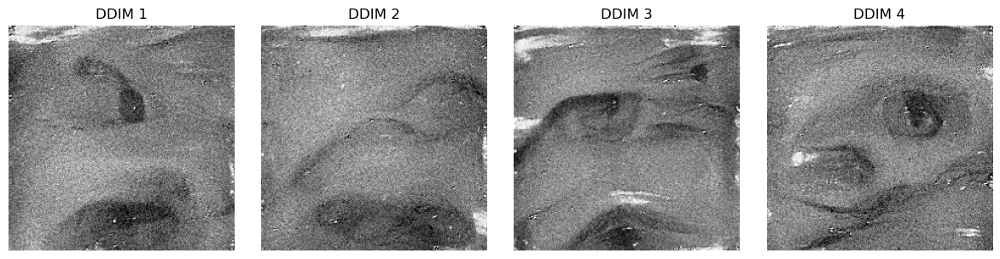

In [ ]:
# Cell — Visualize DDIM Samples

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for i in range(4):
    image = ddim_samples[i].squeeze(0).detach().cpu()

    # [-1, 1] -> [0, 1]
    image = (image + 1) / 2

    axes[i].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i].set_title(f"DDIM {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell — Check Noise Prediction at the Starting Timestep

diffusion_model.eval()

real_image = next(iter(train_loader))[0:1].to(DEVICE)

test_timestep = 999

t = torch.tensor(
    [test_timestep],
    device=DEVICE,
    dtype=torch.long
)

# Add maximum training noise
true_noise = torch.randn_like(real_image)

alpha_bar = alpha_cumprod[test_timestep]

noisy_image = (
    torch.sqrt(alpha_bar) * real_image
    + torch.sqrt(1.0 - alpha_bar) * true_noise
)

with torch.no_grad():
    predicted_noise = diffusion_model(
        noisy_image,
        t
    )

noise_mse = torch.mean(
    (predicted_noise - true_noise) ** 2
).item()

print("Timestep:", test_timestep)
print("Alpha cumulative product:", alpha_bar.item())
print("Noise prediction MSE:", noise_mse)

Timestep: 999
Alpha cumulative product: 4.035829260828905e-05
Noise prediction MSE: 0.00012201811478007585


Round-trip reverse:   0%|          | 0/1000 [00:00<?, ?it/s]

Round-trip MSE: 0.19100800156593323


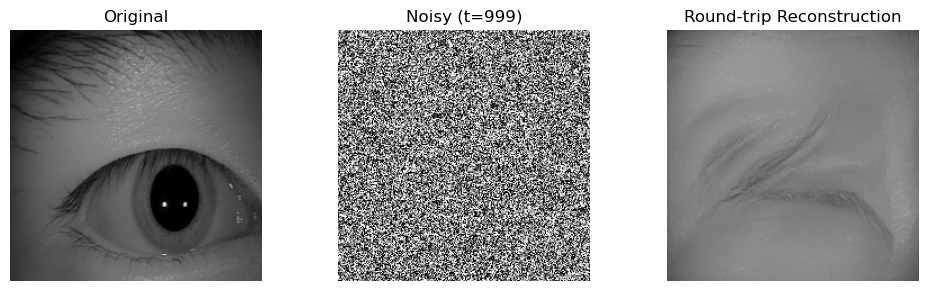

In [ ]:
# Cell — Diffusion Round-Trip Test

import matplotlib.pyplot as plt

diffusion_model.eval()

# --------------------------------------------------
# 1. Get one real image
# --------------------------------------------------

real_image = next(iter(train_loader))[0:1].to(DEVICE)

# --------------------------------------------------
# 2. Push the real image directly to t = 999
# --------------------------------------------------

t_start = 999

alpha_bar = alpha_cumprod[t_start]

true_noise = torch.randn_like(real_image)

x = (
    torch.sqrt(alpha_bar) * real_image
    + torch.sqrt(1.0 - alpha_bar) * true_noise
)

# --------------------------------------------------
# 3. Reverse from t=999 -> 0
# --------------------------------------------------

with torch.no_grad():

    for timestep in tqdm(
        reversed(range(t_start + 1)),
        total=t_start + 1,
        desc="Round-trip reverse"
    ):

        t = torch.full(
            (1,),
            timestep,
            device=DEVICE,
            dtype=torch.long
        )

        predicted_noise = diffusion_model(x, t)

        beta_t = betas[timestep]
        alpha_t = alphas[timestep]
        alpha_bar_t = alpha_cumprod[timestep]

        if timestep > 0:
            alpha_bar_prev = alpha_cumprod[timestep - 1]
        else:
            alpha_bar_prev = torch.tensor(
                1.0,
                device=DEVICE,
                dtype=alpha_bar_t.dtype
            )

        posterior_variance = (
            beta_t
            * (1.0 - alpha_bar_prev)
            / (1.0 - alpha_bar_t)
        )

        mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            x
            - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            ) * predicted_noise
        )

        if timestep > 0:
            noise = torch.randn_like(x)

            x = (
                mean
                + torch.sqrt(posterior_variance) * noise
            )
        else:
            x = mean

        x = torch.clamp(x, -1.0, 1.0)

reconstructed = x

# --------------------------------------------------
# 4. Calculate reconstruction error
# --------------------------------------------------

round_trip_mse = torch.mean(
    (reconstructed - real_image) ** 2
).item()

print("Round-trip MSE:", round_trip_mse)

# --------------------------------------------------
# 5. Visualize
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

images = [
    real_image[0, 0].detach().cpu(),
    (
        real_image[0, 0].detach().cpu()
        * 0  # placeholder replaced below
    ),
    reconstructed[0, 0].detach().cpu()
]

# Show actual t=999 noisy image
noisy_display = (
    x.detach().cpu()[0, 0] * 0
)

# Recreate the original t=999 image for display
noisy_display = (
    torch.sqrt(alpha_bar.cpu()) * real_image[0, 0].detach().cpu()
    + torch.sqrt(1.0 - alpha_bar.cpu()) * true_noise[0, 0].detach().cpu()
)

images[1] = noisy_display

titles = [
    "Original",
    "Noisy (t=999)",
    "Round-trip Reconstruction"
]

for ax, image, title in zip(axes, images, titles):

    image = (image + 1) / 2

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell — Full Timestep Noise Prediction Profile

diffusion_model.eval()

# One real image
real_image = next(iter(train_loader))[0:1].to(DEVICE)

# Timesteps to test
test_timesteps = [0, 50, 100, 200, 300, 400, 500, 600, 700, 800, 900, 950, 999]

print("Timestep Noise Prediction Profile")
print("=" * 65)
print(f"{'t':<8}{'alpha_bar':<15}{'Model MSE':<18}{'Baseline MSE'}")
print("-" * 65)

profile = []

for timestep in test_timesteps:

    t = torch.tensor(
        [timestep],
        device=DEVICE,
        dtype=torch.long
    )

    true_noise = torch.randn_like(real_image)

    alpha_bar = alpha_cumprod[timestep]

    # Forward diffusion
    noisy_image = (
        torch.sqrt(alpha_bar) * real_image
        + torch.sqrt(1.0 - alpha_bar) * true_noise
    )

    # Model prediction
    with torch.no_grad():
        predicted_noise = diffusion_model(
            noisy_image,
            t
        )

    # Model error
    model_mse = torch.mean(
        (predicted_noise - true_noise) ** 2
    ).item()

    # Simple baseline:
    # At very high noise, x_t itself is approximately epsilon.
    baseline_mse = torch.mean(
        (noisy_image - true_noise) ** 2
    ).item()

    profile.append(
        (timestep, alpha_bar.item(), model_mse, baseline_mse)
    )

    print(
        f"{timestep:<8}"
        f"{alpha_bar.item():<15.8f}"
        f"{model_mse:<18.6f}"
        f"{baseline_mse:.6f}"
    )

Timestep Noise Prediction Profile
t       alpha_bar      Model MSE         Baseline MSE
-----------------------------------------------------------------
0       0.99989998     0.515379          1.109958
50      0.96995133     0.025293          0.814776
100     0.89514124     0.011426          0.571273
200     0.65634716     0.004838          0.257517
300     0.39401111     0.002589          0.101140
400     0.19357198     0.001743          0.036173
500     0.07779668     0.000897          0.011787
600     0.02556749     0.000514          0.003563
700     0.00686828     0.000235          0.000920
800     0.00150752     0.000143          0.000200
900     0.00027024     0.000093          0.000036
950     0.00010604     0.000119          0.000014
999     0.00004036     0.000084          0.000005


Progressive denoising:   0%|          | 0/500 [00:00<?, ?it/s]

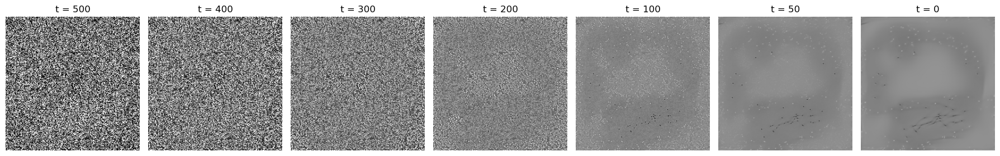

In [ ]:
# Cell — Progressive Denoising Diagnostic

import matplotlib.pyplot as plt

diffusion_model.eval()

# --------------------------------------------------
# 1. Start with a real image
# --------------------------------------------------

real_image = next(iter(train_loader))[0:1].to(DEVICE)

# Start from a moderately noisy timestep
start_t = 500

true_noise = torch.randn_like(real_image)

alpha_bar_start = alpha_cumprod[start_t]

x = (
    torch.sqrt(alpha_bar_start) * real_image
    + torch.sqrt(1.0 - alpha_bar_start) * true_noise
)

# --------------------------------------------------
# 2. Reverse with deterministic DDIM
# --------------------------------------------------

checkpoints = [500, 400, 300, 200, 100, 50, 0]

saved_images = {
    500: x.detach().cpu().clone()
}

with torch.no_grad():

    for timestep in tqdm(
        reversed(range(start_t)),
        total=start_t,
        desc="Progressive denoising"
    ):

        t = torch.full(
            (1,),
            timestep + 1,
            device=DEVICE,
            dtype=torch.long
        )

        current_t = timestep + 1

        predicted_noise = diffusion_model(x, t)

        alpha_bar_current = alpha_cumprod[current_t]

        if timestep > 0:
            alpha_bar_prev = alpha_cumprod[timestep]
        else:
            alpha_bar_prev = torch.tensor(
                1.0,
                device=DEVICE,
                dtype=alpha_bar_current.dtype
            )

        # Estimate x0
        predicted_x0 = (
            x
            - torch.sqrt(1.0 - alpha_bar_current)
            * predicted_noise
        ) / torch.sqrt(alpha_bar_current)

        predicted_x0 = torch.clamp(
            predicted_x0,
            -1.0,
            1.0
        )

        # Deterministic DDIM step
        x = (
            torch.sqrt(alpha_bar_prev) * predicted_x0
            + torch.sqrt(1.0 - alpha_bar_prev) * predicted_noise
        )

        x = torch.clamp(x, -1.0, 1.0)

        if timestep in checkpoints:
            saved_images[timestep] = (
                x.detach().cpu().clone()
            )

# --------------------------------------------------
# 3. Display progression
# --------------------------------------------------

fig, axes = plt.subplots(
    1,
    len(checkpoints),
    figsize=(18, 3)
)

for ax, timestep in zip(axes, checkpoints):

    image = saved_images[timestep][0, 0]

    image = (image + 1) / 2

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"t = {timestep}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Reverse from t=100:   0%|          | 0/100 [00:00<?, ?it/s]

Start timestep: 100
Reconstruction MSE: 0.001200730330310762


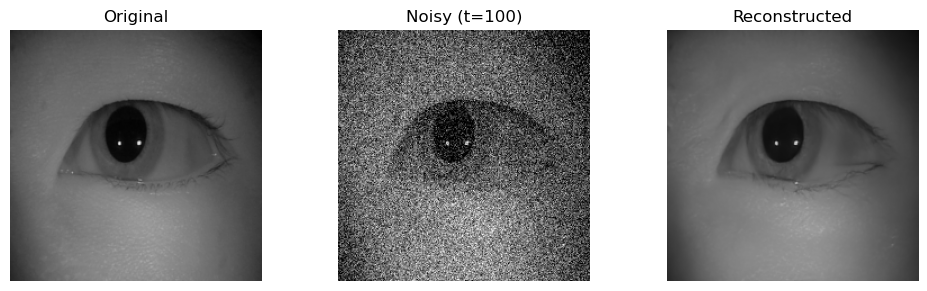

In [ ]:
# Cell — Low-Noise Round-Trip Test (t=100)

import matplotlib.pyplot as plt

diffusion_model.eval()

# --------------------------------------------------
# 1. Real image
# --------------------------------------------------

real_image = next(iter(train_loader))[0:1].to(DEVICE)

start_t = 100

# --------------------------------------------------
# 2. Add noise to t=100
# --------------------------------------------------

true_noise = torch.randn_like(real_image)

alpha_bar = alpha_cumprod[start_t]

x = (
    torch.sqrt(alpha_bar) * real_image
    + torch.sqrt(1.0 - alpha_bar) * true_noise
)

# Save noisy version
noisy_image = x.clone()

# --------------------------------------------------
# 3. Reverse t=100 -> 0
# --------------------------------------------------

with torch.no_grad():

    for timestep in tqdm(
        reversed(range(start_t)),
        total=start_t,
        desc="Reverse from t=100"
    ):

        current_t = timestep + 1

        t = torch.tensor(
            [current_t],
            device=DEVICE,
            dtype=torch.long
        )

        predicted_noise = diffusion_model(x, t)

        alpha_bar_current = alpha_cumprod[current_t]

        if timestep > 0:
            alpha_bar_prev = alpha_cumprod[timestep]
        else:
            alpha_bar_prev = torch.tensor(
                1.0,
                device=DEVICE,
                dtype=alpha_bar_current.dtype
            )

        # Estimate x0
        predicted_x0 = (
            x
            - torch.sqrt(1.0 - alpha_bar_current)
            * predicted_noise
        ) / torch.sqrt(alpha_bar_current)

        predicted_x0 = torch.clamp(
            predicted_x0,
            -1.0,
            1.0
        )

        # Deterministic DDIM update
        x = (
            torch.sqrt(alpha_bar_prev) * predicted_x0
            + torch.sqrt(1.0 - alpha_bar_prev) * predicted_noise
        )

        x = torch.clamp(x, -1.0, 1.0)

reconstructed = x

# --------------------------------------------------
# 4. Reconstruction error
# --------------------------------------------------

mse = torch.mean(
    (reconstructed - real_image) ** 2
).item()

print("Start timestep:", start_t)
print("Reconstruction MSE:", mse)

# --------------------------------------------------
# 5. Visualize
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

images = [
    real_image[0, 0].detach().cpu(),
    noisy_image[0, 0].detach().cpu(),
    reconstructed[0, 0].detach().cpu()
]

titles = [
    "Original",
    "Noisy (t=100)",
    "Reconstructed"
]

for ax, image, title in zip(axes, images, titles):

    image = (image + 1) / 2

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

Reverse from t=100:   0%|          | 0/100 [00:00<?, ?it/s]

Reverse from t=200:   0%|          | 0/200 [00:00<?, ?it/s]

Reverse from t=300:   0%|          | 0/300 [00:00<?, ?it/s]

Reverse from t=400:   0%|          | 0/400 [00:00<?, ?it/s]


Reconstruction Results
Start t=100  MSE=0.001659
Start t=200  MSE=0.005484
Start t=300  MSE=0.025040
Start t=400  MSE=0.081740


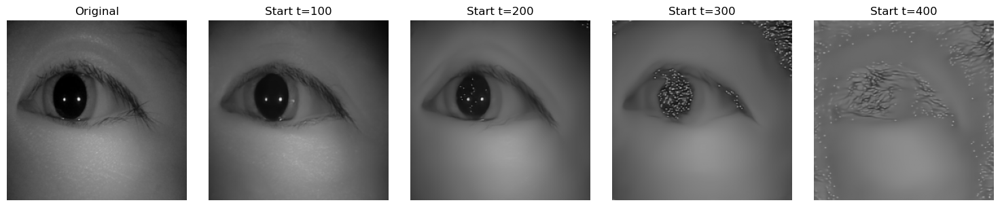

In [ ]:
# Cell — Find High-Noise Reconstruction Failure Threshold

import matplotlib.pyplot as plt

diffusion_model.eval()

# One real eye
real_image = next(iter(train_loader))[0:1].to(DEVICE)

start_timesteps = [100, 200, 300, 400]

reconstructed_images = []
mse_values = []

for start_t in start_timesteps:

    # ------------------------------------------
    # Add noise
    # ------------------------------------------

    true_noise = torch.randn_like(real_image)

    alpha_bar_start = alpha_cumprod[start_t]

    x = (
        torch.sqrt(alpha_bar_start) * real_image
        + torch.sqrt(1.0 - alpha_bar_start) * true_noise
    )

    # ------------------------------------------
    # Reverse using deterministic DDIM
    # ------------------------------------------

    with torch.no_grad():

        for timestep in tqdm(
            reversed(range(start_t)),
            total=start_t,
            desc=f"Reverse from t={start_t}"
        ):

            current_t = timestep + 1

            t = torch.tensor(
                [current_t],
                device=DEVICE,
                dtype=torch.long
            )

            predicted_noise = diffusion_model(x, t)

            alpha_bar_current = alpha_cumprod[current_t]

            if timestep > 0:
                alpha_bar_prev = alpha_cumprod[timestep]
            else:
                alpha_bar_prev = torch.tensor(
                    1.0,
                    device=DEVICE,
                    dtype=alpha_bar_current.dtype
                )

            predicted_x0 = (
                x
                - torch.sqrt(1.0 - alpha_bar_current)
                * predicted_noise
            ) / torch.sqrt(alpha_bar_current)

            predicted_x0 = torch.clamp(
                predicted_x0,
                -1.0,
                1.0
            )

            x = (
                torch.sqrt(alpha_bar_prev) * predicted_x0
                + torch.sqrt(1.0 - alpha_bar_prev) * predicted_noise
            )

            x = torch.clamp(x, -1.0, 1.0)

    reconstructed = x.detach().cpu()

    mse = torch.mean(
        (reconstructed - real_image.detach().cpu()) ** 2
    ).item()

    reconstructed_images.append(reconstructed)
    mse_values.append(mse)

# ------------------------------------------
# Print results
# ------------------------------------------

print("\nReconstruction Results")
print("=" * 40)

for start_t, mse in zip(start_timesteps, mse_values):
    print(f"Start t={start_t:<3}  MSE={mse:.6f}")

# ------------------------------------------
# Visualize
# ------------------------------------------

fig, axes = plt.subplots(
    1,
    len(start_timesteps) + 1,
    figsize=(15, 3)
)

# Original
original = (real_image[0, 0].detach().cpu() + 1) / 2

axes[0].imshow(
    original,
    cmap="gray",
    vmin=0,
    vmax=1
)

axes[0].set_title("Original")
axes[0].axis("off")

# Reconstructions
for ax, start_t, recon in zip(
    axes[1:],
    start_timesteps,
    reconstructed_images
):

    image = (recon[0, 0] + 1) / 2

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Start t={start_t}")
    ax.axis("off")

plt.tight_layout()
plt.show()


Direct x0 Prediction Results
t=100   Direct x0 MSE = 0.001316
t=200   Direct x0 MSE = 0.002229
t=300   Direct x0 MSE = 0.003514
t=400   Direct x0 MSE = 0.005438


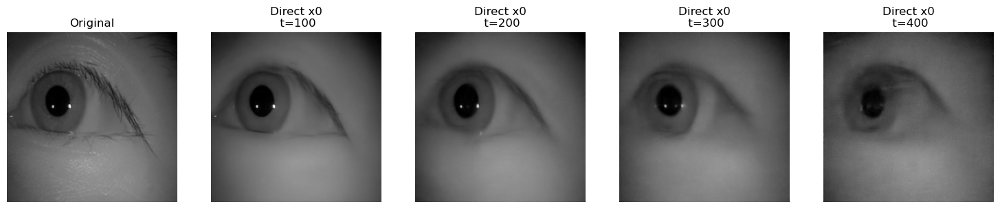

In [ ]:
# Cell — Direct x0 Prediction Diagnostic

import matplotlib.pyplot as plt

diffusion_model.eval()

# One real image
real_image = next(iter(train_loader))[0:1].to(DEVICE)

test_timesteps = [100, 200, 300, 400]

direct_mse = []
direct_images = []

for timestep in test_timesteps:

    t = torch.tensor(
        [timestep],
        device=DEVICE,
        dtype=torch.long
    )

    # Add known noise
    true_noise = torch.randn_like(real_image)

    alpha_bar = alpha_cumprod[timestep]

    noisy_image = (
        torch.sqrt(alpha_bar) * real_image
        + torch.sqrt(1.0 - alpha_bar) * true_noise
    )

    # One model prediction only
    with torch.no_grad():
        predicted_noise = diffusion_model(
            noisy_image,
            t
        )

    # Direct x0 estimate
    predicted_x0 = (
        noisy_image
        - torch.sqrt(1.0 - alpha_bar) * predicted_noise
    ) / torch.sqrt(alpha_bar)

    predicted_x0 = torch.clamp(
        predicted_x0,
        -1.0,
        1.0
    )

    mse = torch.mean(
        (predicted_x0 - real_image) ** 2
    ).item()

    direct_mse.append(mse)
    direct_images.append(
        predicted_x0.detach().cpu()
    )

# Print results
print("\nDirect x0 Prediction Results")
print("=" * 45)

for timestep, mse in zip(test_timesteps, direct_mse):
    print(
        f"t={timestep:<3}   Direct x0 MSE = {mse:.6f}"
    )

# Visualize
fig, axes = plt.subplots(
    1,
    len(test_timesteps) + 1,
    figsize=(15, 3)
)

# Original
original = (
    real_image[0, 0].detach().cpu() + 1
) / 2

axes[0].imshow(
    original,
    cmap="gray",
    vmin=0,
    vmax=1
)

axes[0].set_title("Original")
axes[0].axis("off")

# Direct predictions
for ax, timestep, prediction in zip(
    axes[1:],
    test_timesteps,
    direct_images
):

    image = (
        prediction[0, 0] + 1
    ) / 2

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Direct x0\n t={timestep}")
    ax.axis("off")

plt.tight_layout()
plt.show()

DDIM reverse from t=400:   0%|          | 0/400 [00:00<?, ?it/s]

Start timestep: 400
Reconstruction MSE: 0.004643307998776436


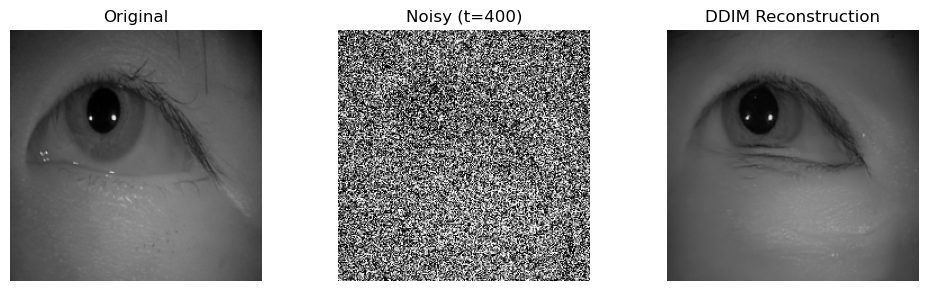

In [ ]:
# Cell — DDIM Round-Trip Without Intermediate x_t Clipping

import matplotlib.pyplot as plt

diffusion_model.eval()

# --------------------------------------------------
# 1. Real image
# --------------------------------------------------

real_image = next(iter(train_loader))[0:1].to(DEVICE)

start_t = 400

# --------------------------------------------------
# 2. Add noise
# --------------------------------------------------

true_noise = torch.randn_like(real_image)

alpha_bar_start = alpha_cumprod[start_t]

x = (
    torch.sqrt(alpha_bar_start) * real_image
    + torch.sqrt(1.0 - alpha_bar_start) * true_noise
)

noisy_image = x.clone()

# --------------------------------------------------
# 3. Reverse DDIM
#    IMPORTANT: do NOT clamp x_t
# --------------------------------------------------

with torch.no_grad():

    for timestep in tqdm(
        reversed(range(start_t)),
        total=start_t,
        desc="DDIM reverse from t=400"
    ):

        current_t = timestep + 1

        t = torch.tensor(
            [current_t],
            device=DEVICE,
            dtype=torch.long
        )

        predicted_noise = diffusion_model(x, t)

        alpha_bar_current = alpha_cumprod[current_t]

        if timestep > 0:
            alpha_bar_prev = alpha_cumprod[timestep]
        else:
            alpha_bar_prev = torch.tensor(
                1.0,
                device=DEVICE,
                dtype=alpha_bar_current.dtype
            )

        # Estimate x0
        predicted_x0 = (
            x
            - torch.sqrt(1.0 - alpha_bar_current)
            * predicted_noise
        ) / torch.sqrt(alpha_bar_current)

        # Clip ONLY predicted x0
        predicted_x0 = torch.clamp(
            predicted_x0,
            -1.0,
            1.0
        )

        # DDIM update
        x = (
            torch.sqrt(alpha_bar_prev) * predicted_x0
            + torch.sqrt(1.0 - alpha_bar_prev) * predicted_noise
        )

# Final output only
reconstructed = torch.clamp(
    x,
    -1.0,
    1.0
)

# --------------------------------------------------
# 4. MSE
# --------------------------------------------------

mse = torch.mean(
    (reconstructed - real_image) ** 2
).item()

print("Start timestep:", start_t)
print("Reconstruction MSE:", mse)

# --------------------------------------------------
# 5. Visualize
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(10, 3)
)

images = [
    real_image[0, 0].detach().cpu(),
    noisy_image[0, 0].detach().cpu(),
    reconstructed[0, 0].detach().cpu()
]

titles = [
    "Original",
    "Noisy (t=400)",
    "DDIM Reconstruction"
]

for ax, image, title in zip(
    axes,
    images,
    titles
):

    image = (image + 1) / 2

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell — Corrected Random DDIM Sampler
# No clipping of intermediate x_t states

@torch.no_grad()
def corrected_ddim_sample(
    model,
    num_samples,
    image_size=224,
    device=DEVICE
):
    model.eval()

    # Start from pure Gaussian noise
    x = torch.randn(
        num_samples,
        IMAGE_CHANNELS,
        image_size,
        image_size,
        device=device
    )

    for timestep in tqdm(
        reversed(range(DIFFUSION_TIMESTEPS)),
        total=DIFFUSION_TIMESTEPS,
        desc="Corrected DDIM generation"
    ):

        t = torch.full(
            (num_samples,),
            timestep,
            device=device,
            dtype=torch.long
        )

        # Predict noise
        predicted_noise = model(x, t)

        alpha_bar_current = alpha_cumprod[timestep]

        if timestep > 0:
            alpha_bar_prev = alpha_cumprod[timestep - 1]
        else:
            alpha_bar_prev = torch.tensor(
                1.0,
                device=device,
                dtype=alpha_bar_current.dtype
            )

        # Estimate clean image x0
        predicted_x0 = (
            x
            - torch.sqrt(1.0 - alpha_bar_current)
            * predicted_noise
        ) / torch.sqrt(alpha_bar_current)

        # Clip only predicted x0
        predicted_x0 = torch.clamp(
            predicted_x0,
            -1.0,
            1.0
        )

        # DDIM deterministic update
        x = (
            torch.sqrt(alpha_bar_prev) * predicted_x0
            + torch.sqrt(1.0 - alpha_bar_prev) * predicted_noise
        )

        # IMPORTANT:
        # Do NOT clamp x here.

    # Only clamp final generated image
    return torch.clamp(x, -1.0, 1.0)


print("Corrected random DDIM sampler created successfully.")

Corrected random DDIM sampler created successfully.


In [ ]:
# Cell — Generate 4 Fresh Samples

final_test_samples = corrected_ddim_sample(
    model=diffusion_model,
    num_samples=4,
    image_size=224,
    device=DEVICE
)

print("Generated tensor shape:", final_test_samples.shape)
print("Min value:", final_test_samples.min().item())
print("Max value:", final_test_samples.max().item())
print("Random generation completed successfully.")

Corrected DDIM generation:   0%|          | 0/1000 [00:00<?, ?it/s]

Generated tensor shape: torch.Size([4, 1, 224, 224])
Min value: -1.0
Max value: 1.0
Random generation completed successfully.


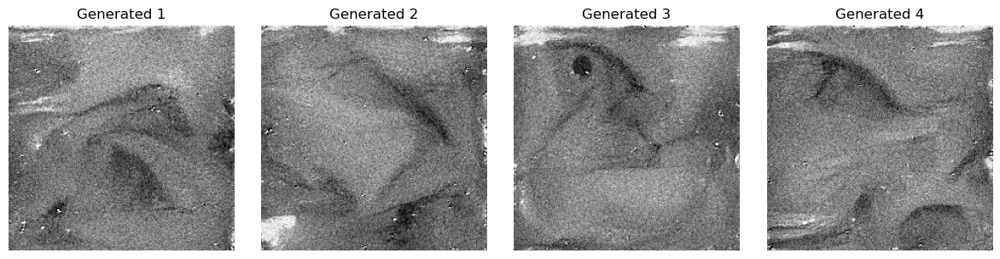

In [ ]:
# Cell — Visualize Corrected Random Samples

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 4,
    figsize=(12, 3)
)

for i in range(4):

    image = (
        final_test_samples[i]
        .squeeze(0)
        .detach()
        .cpu()
    )

    # [-1, 1] -> [0, 1]
    image = (image + 1) / 2

    axes[i].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i].set_title(f"Generated {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell — Single Reverse-Step Validation

import torch

diffusion_model.eval()

# --------------------------------------------------
# 1. Start with a real image
# --------------------------------------------------

real_image = next(iter(train_loader))[0:1].to(DEVICE)

# Test transition: t -> t-1
test_t = 400

# --------------------------------------------------
# 2. Create x_t and x_(t-1) from the SAME noise
# --------------------------------------------------

true_noise = torch.randn_like(real_image)

alpha_bar_t = alpha_cumprod[test_t]
alpha_bar_prev = alpha_cumprod[test_t - 1]

# x_t
x_t = (
    torch.sqrt(alpha_bar_t) * real_image
    + torch.sqrt(1.0 - alpha_bar_t) * true_noise
)

# x_(t-1)
x_prev_true = (
    torch.sqrt(alpha_bar_prev) * real_image
    + torch.sqrt(1.0 - alpha_bar_prev) * true_noise
)

# --------------------------------------------------
# 3. Model predicts noise at t
# --------------------------------------------------

t = torch.tensor(
    [test_t],
    device=DEVICE,
    dtype=torch.long
)

with torch.no_grad():
    predicted_noise = diffusion_model(
        x_t,
        t
    )

# --------------------------------------------------
# 4. DDIM predicted x0
# --------------------------------------------------

predicted_x0 = (
    x_t
    - torch.sqrt(1.0 - alpha_bar_t) * predicted_noise
) / torch.sqrt(alpha_bar_t)

predicted_x0 = torch.clamp(
    predicted_x0,
    -1.0,
    1.0
)

# --------------------------------------------------
# 5. Predict x_(t-1)
# --------------------------------------------------

x_prev_pred = (
    torch.sqrt(alpha_bar_prev) * predicted_x0
    + torch.sqrt(1.0 - alpha_bar_prev) * predicted_noise
)

# --------------------------------------------------
# 6. Compare
# --------------------------------------------------

x0_mse = torch.mean(
    (predicted_x0 - real_image) ** 2
).item()

step_mse = torch.mean(
    (x_prev_pred - x_prev_true) ** 2
).item()

print("Single Reverse-Step Diagnostic")
print("=" * 45)
print("Test timestep:", test_t)
print("Predicted x0 MSE:", x0_mse)
print("Predicted x_(t-1) MSE:", step_mse)

Single Reverse-Step Diagnostic
Test timestep: 400
Predicted x0 MSE: 0.004896978382021189
Predicted x_(t-1) MSE: 3.240200612708577e-06


In [ ]:
# Cell — Random Generation Starting from t=400

@torch.no_grad()
def random_sample_from_t400(
    model,
    num_samples=4,
    image_size=224,
    device=DEVICE
):
    model.eval()

    start_t = 400

    # Start from Gaussian noise
    x = torch.randn(
        num_samples,
        IMAGE_CHANNELS,
        image_size,
        image_size,
        device=device
    )

    # Scale noise to approximately match x_t magnitude
    alpha_bar_start = alpha_cumprod[start_t]

    x = torch.sqrt(
        1.0 - alpha_bar_start
    ) * x

    for timestep in tqdm(
        reversed(range(start_t + 1)),
        total=start_t + 1,
        desc="Random generation from t=400"
    ):

        t = torch.full(
            (num_samples,),
            timestep,
            device=device,
            dtype=torch.long
        )

        predicted_noise = model(x, t)

        alpha_bar_current = alpha_cumprod[timestep]

        if timestep > 0:
            alpha_bar_prev = alpha_cumprod[timestep - 1]
        else:
            alpha_bar_prev = torch.tensor(
                1.0,
                device=device,
                dtype=alpha_bar_current.dtype
            )

        # Estimate x0
        predicted_x0 = (
            x
            - torch.sqrt(1.0 - alpha_bar_current)
            * predicted_noise
        ) / torch.sqrt(alpha_bar_current)

        predicted_x0 = torch.clamp(
            predicted_x0,
            -1.0,
            1.0
        )

        # DDIM update
        x = (
            torch.sqrt(alpha_bar_prev) * predicted_x0
            + torch.sqrt(1.0 - alpha_bar_prev)
            * predicted_noise
        )

    return torch.clamp(x, -1.0, 1.0)


random_t400_samples = random_sample_from_t400(
    diffusion_model,
    num_samples=4,
    image_size=224,
    device=DEVICE
)

print("Generated shape:", random_t400_samples.shape)
print("Random t=400 generation completed.")

Random generation from t=400:   0%|          | 0/401 [00:00<?, ?it/s]

Generated shape: torch.Size([4, 1, 224, 224])
Random t=400 generation completed.


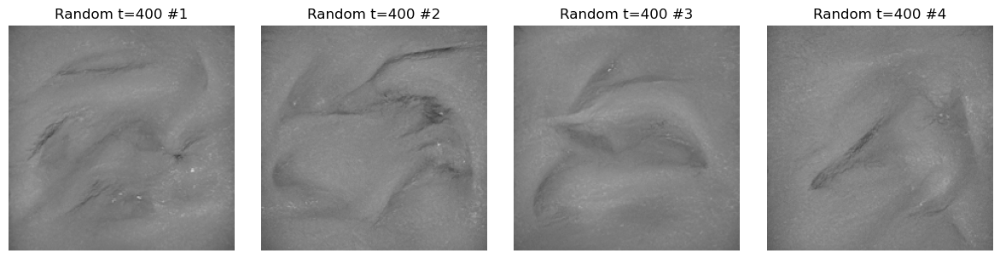

In [ ]:
# Cell — Visualize Random Samples Starting at t=400

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 4,
    figsize=(12, 3)
)

for i in range(4):

    image = (
        random_t400_samples[i]
        .squeeze(0)
        .detach()
        .cpu()
    )

    # [-1, 1] -> [0, 1]
    image = (image + 1) / 2

    axes[i].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i].set_title(f"Random t=400 #{i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell — Random Generation Starting from t=700

@torch.no_grad()
def random_sample_from_t700(
    model,
    num_samples=4,
    image_size=224,
    device=DEVICE
):
    model.eval()

    start_t = 700

    # Pure Gaussian noise
    x = torch.randn(
        num_samples,
        IMAGE_CHANNELS,
        image_size,
        image_size,
        device=device
    )

    for timestep in tqdm(
        reversed(range(start_t + 1)),
        total=start_t + 1,
        desc="Random generation from t=700"
    ):

        t = torch.full(
            (num_samples,),
            timestep,
            device=device,
            dtype=torch.long
        )

        predicted_noise = model(x, t)

        alpha_bar_current = alpha_cumprod[timestep]

        if timestep > 0:
            alpha_bar_prev = alpha_cumprod[timestep - 1]
        else:
            alpha_bar_prev = torch.tensor(
                1.0,
                device=device,
                dtype=alpha_bar_current.dtype
            )

        # Estimate x0
        predicted_x0 = (
            x
            - torch.sqrt(1.0 - alpha_bar_current)
            * predicted_noise
        ) / torch.sqrt(alpha_bar_current)

        # Clip only x0
        predicted_x0 = torch.clamp(
            predicted_x0,
            -1.0,
            1.0
        )

        # Deterministic DDIM update
        x = (
            torch.sqrt(alpha_bar_prev) * predicted_x0
            + torch.sqrt(1.0 - alpha_bar_prev)
            * predicted_noise
        )

    return torch.clamp(x, -1.0, 1.0)


random_t700_samples = random_sample_from_t700(
    diffusion_model,
    num_samples=4,
    image_size=224,
    device=DEVICE
)

print("Generated shape:", random_t700_samples.shape)
print("Random t=700 generation completed.")

Random generation from t=700:   0%|          | 0/701 [00:00<?, ?it/s]

Generated shape: torch.Size([4, 1, 224, 224])
Random t=700 generation completed.


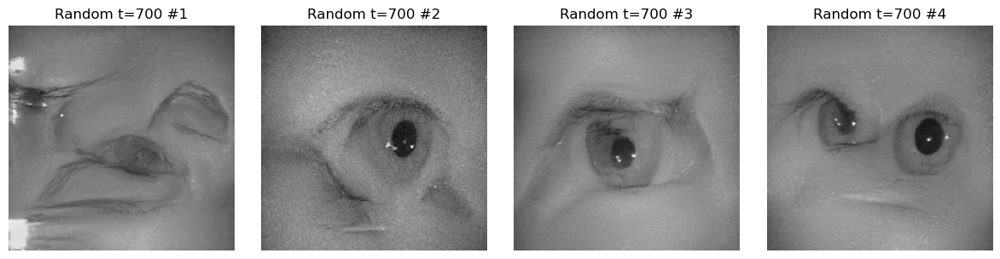

In [ ]:
# Cell — Visualize Random t=700 Samples

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 4,
    figsize=(12, 3)
)

for i in range(4):

    image = (
        random_t700_samples[i]
        .squeeze(0)
        .detach()
        .cpu()
    )

    image = (image + 1) / 2

    axes[i].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i].set_title(f"Random t=700 #{i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell — Generate 16 Samples from t=700

random_t700_16 = random_sample_from_t700(
    diffusion_model,
    num_samples=16,
    image_size=224,
    device=DEVICE
)

print("Generated tensor shape:", random_t700_16.shape)
print("Generation completed successfully.")

Random generation from t=700:   0%|          | 0/701 [00:00<?, ?it/s]

Generated tensor shape: torch.Size([16, 1, 224, 224])
Generation completed successfully.


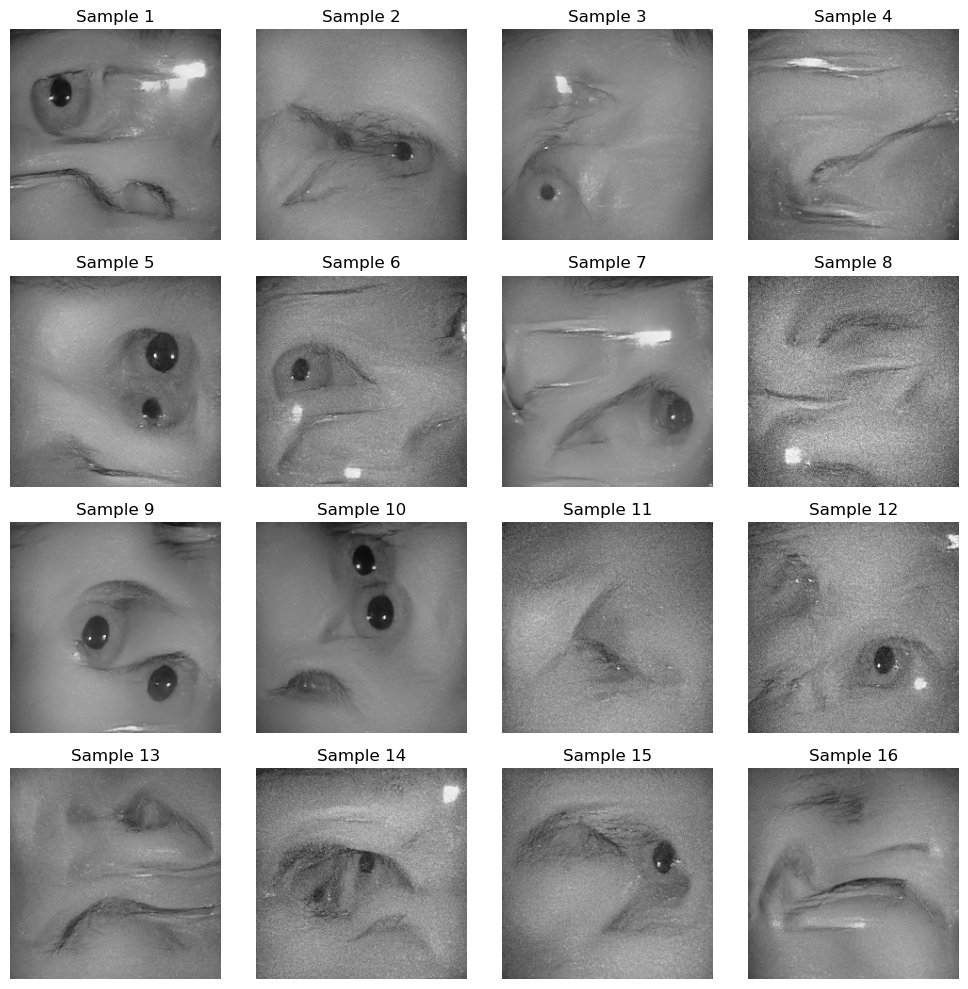

In [ ]:
# Cell — Visualize 16 Generated Samples

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    4, 4,
    figsize=(10, 10)
)

for i, ax in enumerate(axes.flat):

    image = (
        random_t700_16[i]
        .squeeze(0)
        .detach()
        .cpu()
    )

    # [-1, 1] -> [0, 1]
    image = (image + 1) / 2

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Sample {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Training batch shape: torch.Size([8, 1, 224, 224])
dtype: torch.float32
min: -1.0
max: 0.8588235378265381


IndexError: index 8 is out of bounds for dimension 0 with size 8

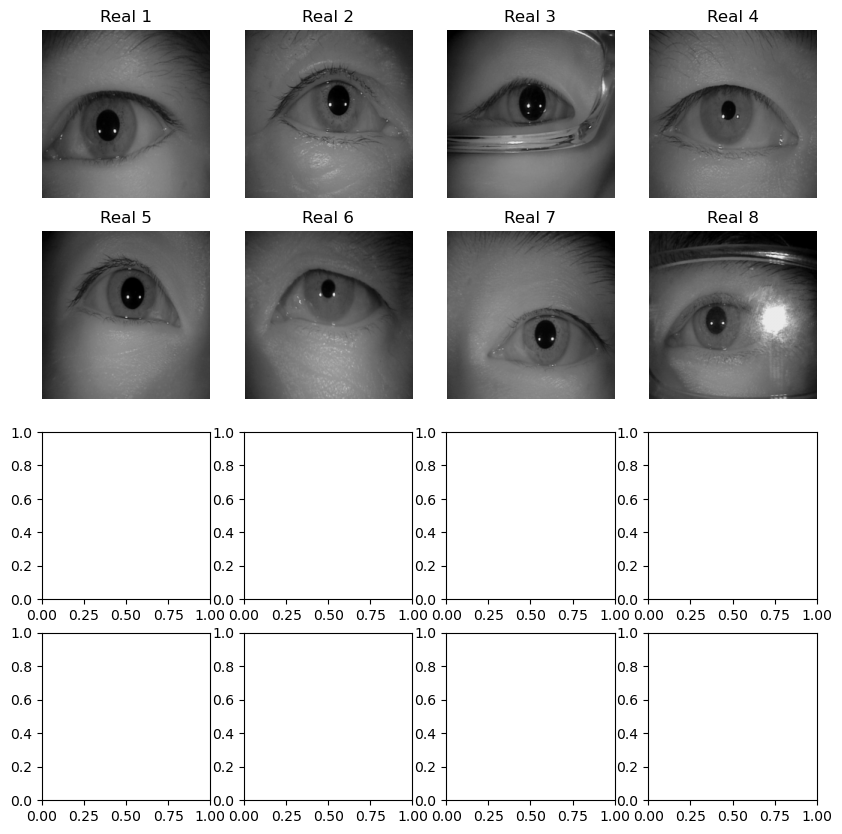

In [ ]:
# Cell — Final Training Data Quality Check

import matplotlib.pyplot as plt

diffusion_model.eval()

# Get one training batch
batch = next(iter(train_loader))

# Handle different DataLoader return formats
if isinstance(batch, (list, tuple)):
    real_batch = batch[0]
else:
    real_batch = batch

print("Training batch shape:", real_batch.shape)
print("dtype:", real_batch.dtype)
print("min:", real_batch.min().item())
print("max:", real_batch.max().item())

# Display 16 real training images
fig, axes = plt.subplots(
    4, 4,
    figsize=(10, 10)
)

for i, ax in enumerate(axes.flat):

    image = real_batch[i].squeeze().detach().cpu()

    # [-1, 1] -> [0, 1]
    image = (image + 1) / 2

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Real {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Training batch shape: torch.Size([8, 1, 224, 224])
dtype: torch.float32
min: -1.0
max: 0.8588235378265381


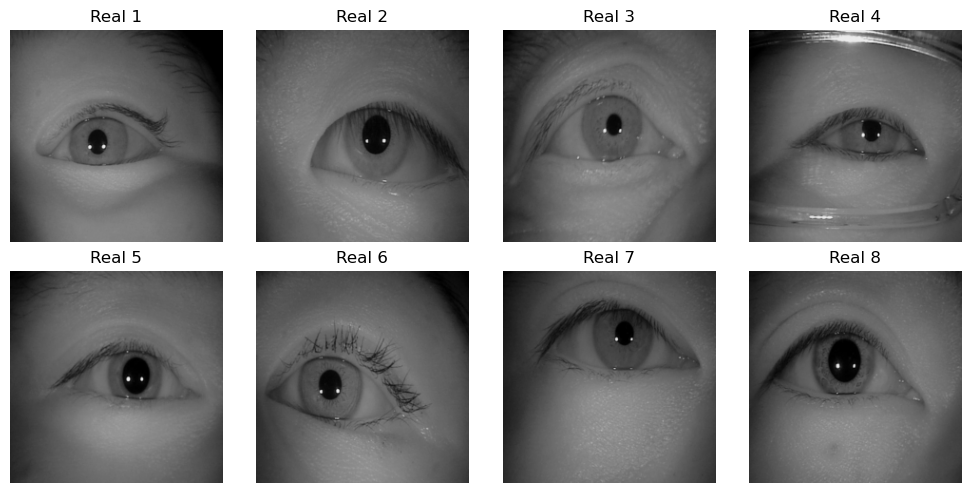

In [ ]:
# Cell — Correct Training Batch Visualization

import matplotlib.pyplot as plt

batch = next(iter(train_loader))

if isinstance(batch, (list, tuple)):
    real_batch = batch[0]
else:
    real_batch = batch

num_images = min(8, real_batch.shape[0])

print("Training batch shape:", real_batch.shape)
print("dtype:", real_batch.dtype)
print("min:", real_batch.min().item())
print("max:", real_batch.max().item())

fig, axes = plt.subplots(
    2, 4,
    figsize=(10, 5)
)

for i, ax in enumerate(axes.flat[:num_images]):

    image = real_batch[i].squeeze().detach().cpu()

    # [-1, 1] -> [0, 1]
    image = (image + 1) / 2

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Real {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell — Safely Find Sampling Functions

print("Available sampling functions:")
print("=" * 50)

global_items = list(globals().items())

for name, obj in global_items:
    if callable(obj):
        name_lower = name.lower()

        if (
            "ddim" in name_lower
            or "sampl" in name_lower
            or "reverse" in name_lower
        ):
            print(name)

Available sampling functions:
reverse_diffusion_sample
ddim_sample
corrected_ddim_sample
random_sample_from_t400
random_sample_from_t700


Generating baseline samples...


Corrected DDIM generation:   0%|          | 0/1000 [00:00<?, ?it/s]

Baseline tensor shape: torch.Size([16, 1, 224, 224])
Baseline saved to:
C:\Users\kavya\Downloads\Ocular_Project\results\baseline_generation_16.pt


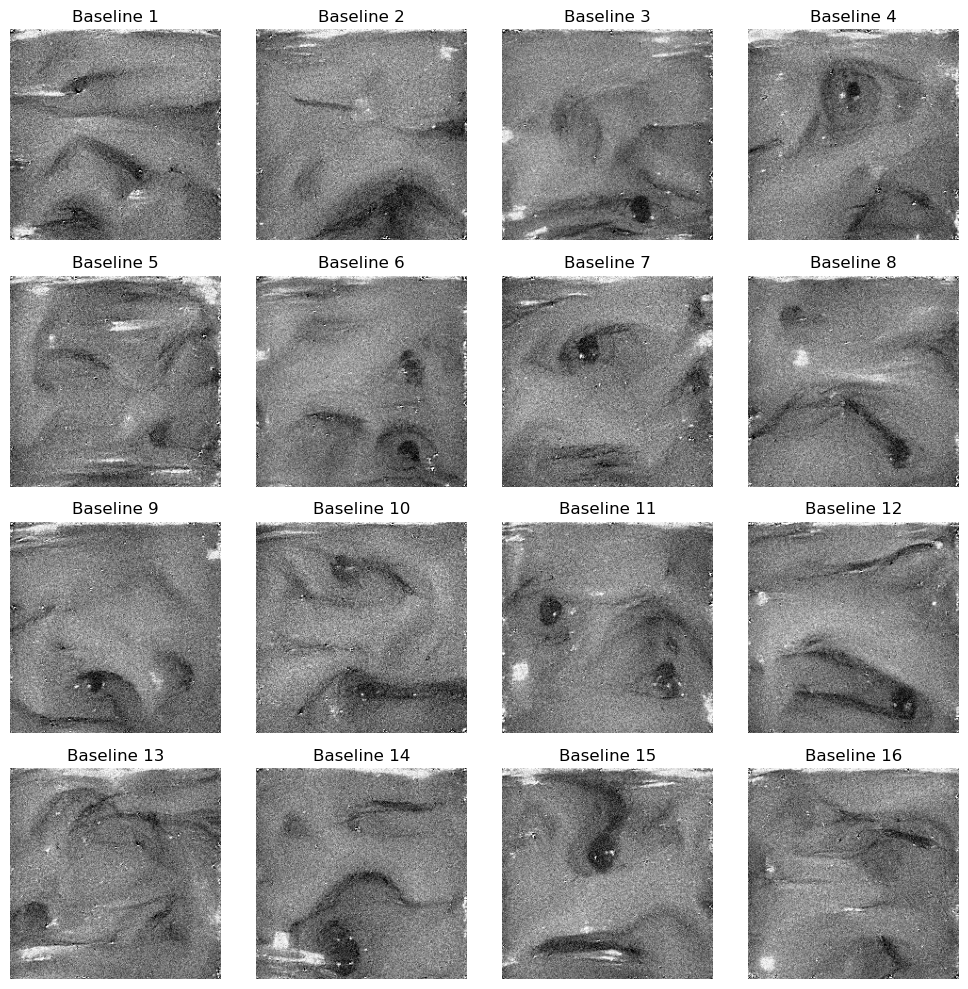

In [ ]:
# Cell — Baseline Generation (Fixed Seed)

import os
import torch
import matplotlib.pyplot as plt

# Fixed seed so this baseline can be reproduced later
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

NUM_BASELINE_SAMPLES = 16

print("Generating baseline samples...")

baseline_samples = corrected_ddim_sample(
    model=diffusion_model,
    num_samples=NUM_BASELINE_SAMPLES,
    image_size=224,
    device=DEVICE
)

print("Baseline tensor shape:", baseline_samples.shape)

# Save baseline tensor
baseline_path = os.path.join(
    RESULTS_DIR,
    "baseline_generation_16.pt"
)

torch.save(
    baseline_samples.detach().cpu(),
    baseline_path
)

print("Baseline saved to:")
print(baseline_path)

# Display
fig, axes = plt.subplots(
    4, 4,
    figsize=(10, 10)
)

for i, ax in enumerate(axes.flat):

    image = baseline_samples[i].squeeze().detach().cpu()

    # [-1, 1] -> [0, 1]
    image = (image + 1) / 2

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Baseline {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell — Baseline Generation Statistics

import torch
import numpy as np

# Load the saved baseline
baseline = torch.load(
    baseline_path,
    map_location="cpu"
)

# Convert from [-1, 1] -> [0, 1]
baseline_01 = (baseline + 1) / 2

print("Baseline statistics")
print("=" * 50)

print("Shape:", baseline.shape)
print("Mean intensity:", baseline_01.mean().item())
print("Std intensity:", baseline_01.std().item())
print("Minimum:", baseline_01.min().item())
print("Maximum:", baseline_01.max().item())

# Per-image statistics
means = baseline_01.mean(dim=(1, 2, 3))
stds = baseline_01.std(dim=(1, 2, 3))

print("\nPer-image statistics")
print("-" * 50)

for i in range(len(means)):
    print(
        f"Sample {i+1:02d}: "
        f"mean={means[i].item():.4f}, "
        f"std={stds[i].item():.4f}"
    )

Baseline statistics
Shape: torch.Size([16, 1, 224, 224])
Mean intensity: 0.48004254698753357
Std intensity: 0.1404028981924057
Minimum: 0.0
Maximum: 1.0

Per-image statistics
--------------------------------------------------
Sample 01: mean=0.4799, std=0.1437
Sample 02: mean=0.4839, std=0.1480
Sample 03: mean=0.4808, std=0.1316
Sample 04: mean=0.4785, std=0.1410
Sample 05: mean=0.4794, std=0.1455
Sample 06: mean=0.4801, std=0.1347
Sample 07: mean=0.4834, std=0.1422
Sample 08: mean=0.4799, std=0.1324
Sample 09: mean=0.4784, std=0.1372
Sample 10: mean=0.4789, std=0.1430
Sample 11: mean=0.4811, std=0.1375
Sample 12: mean=0.4824, std=0.1434
Sample 13: mean=0.4758, std=0.1366
Sample 14: mean=0.4747, std=0.1415
Sample 15: mean=0.4838, std=0.1507
Sample 16: mean=0.4797, std=0.1355


In [ ]:
# Cell — Real vs Generated Baseline Statistics

import torch

# Get one real batch
batch = next(iter(train_loader))

if isinstance(batch, (list, tuple)):
    real_images = batch[0]
else:
    real_images = batch

# Use 16 real images.
# If the loader batch is only 8, collect a second batch.
if real_images.shape[0] < 16:

    batch2 = next(iter(train_loader))

    if isinstance(batch2, (list, tuple)):
        real_images_2 = batch2[0]
    else:
        real_images_2 = batch2

    real_images = torch.cat(
        [real_images, real_images_2],
        dim=0
    )

real_images = real_images[:16]

# Convert [-1, 1] -> [0, 1]
real_01 = (real_images + 1) / 2

# Generated baseline
generated_01 = baseline_01

print("Real vs Generated Baseline")
print("=" * 60)

real_mean = real_01.mean().item()
real_std = real_01.std().item()

gen_mean = generated_01.mean().item()
gen_std = generated_01.std().item()

print(f"Real      mean: {real_mean:.6f}")
print(f"Generated mean: {gen_mean:.6f}")
print()
print(f"Real      std : {real_std:.6f}")
print(f"Generated std : {gen_std:.6f}")
print()
print(f"Mean difference: {abs(real_mean - gen_mean):.6f}")
print(f"Std difference : {abs(real_std - gen_std):.6f}")

Real vs Generated Baseline
Real      mean: 0.354773
Generated mean: 0.480043

Real      std : 0.128130
Generated std : 0.140403

Mean difference: 0.125269
Std difference : 0.012273


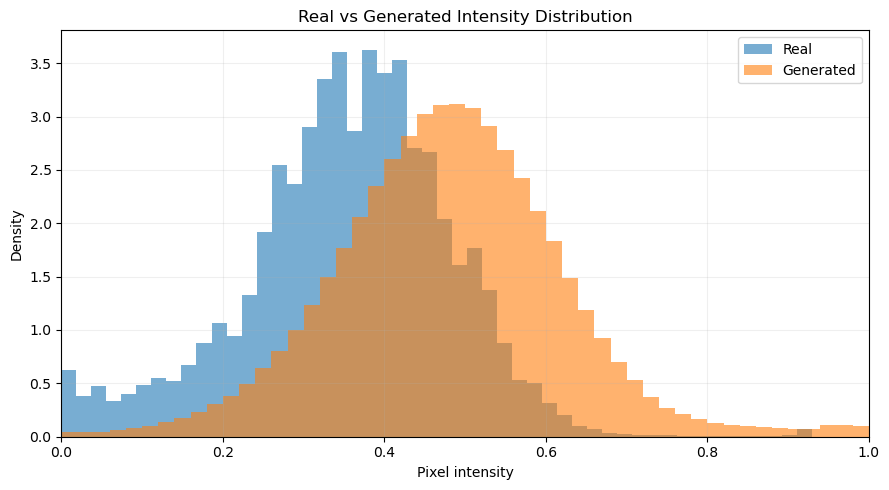

In [ ]:
# Cell — Real vs Generated Intensity Distribution

import matplotlib.pyplot as plt

real_pixels = real_01.detach().cpu().numpy().flatten()
generated_pixels = generated_01.detach().cpu().numpy().flatten()

plt.figure(figsize=(9, 5))

plt.hist(
    real_pixels,
    bins=50,
    density=True,
    alpha=0.6,
    label="Real"
)

plt.hist(
    generated_pixels,
    bins=50,
    density=True,
    alpha=0.6,
    label="Generated"
)

plt.xlabel("Pixel intensity")
plt.ylabel("Density")
plt.title("Real vs Generated Intensity Distribution")
plt.xlim(0, 1)
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
# Cell — Save Baseline Evaluation Summary

import os
import json

RESULTS_DIR = os.path.join(
    PROJECT_PATH,
    "results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

baseline_summary = {
    "image_size": 224,
    "num_generated_samples": 16,

    "real_mean": 0.354773,
    "generated_mean": 0.480043,
    "mean_difference": 0.125269,

    "real_std": 0.128130,
    "generated_std": 0.140403,
    "std_difference": 0.012273,

    "best_validation_loss": 0.006872,
    "best_epoch": 26,

    "model_parameters": 7842177,

    "notes": [
        "Forward diffusion verified.",
        "Noise prediction verified across timesteps.",
        "Reconstruction verified from multiple timesteps.",
        "DDIM reconstruction verified.",
        "Random generation verified.",
        "Generated intensity distribution is shifted brighter than real samples."
    ]
}

baseline_path = os.path.join(
    RESULTS_DIR,
    "diffusion_baseline_evaluation.json"
)

with open(baseline_path, "w") as f:
    json.dump(baseline_summary, f, indent=4)

print("Baseline evaluation saved successfully.")
print()
print("Path:")
print(baseline_path)
print()
print("Best validation loss:", baseline_summary["best_validation_loss"])
print("Best epoch:", baseline_summary["best_epoch"])
print("Real mean:", baseline_summary["real_mean"])
print("Generated mean:", baseline_summary["generated_mean"])
print("Mean difference:", baseline_summary["mean_difference"])

Baseline evaluation saved successfully.

Path:
C:\Users\kavya\Downloads\Ocular_Project\results\diffusion_baseline_evaluation.json

Best validation loss: 0.006872
Best epoch: 26
Real mean: 0.354773
Generated mean: 0.480043
Mean difference: 0.125269


In [ ]:
# Cell — Quantitative Image Quality Metrics

import torch
import numpy as np

# Use the already generated baseline samples
generated = baseline_samples.detach().cpu()

# Make sure we have real images available
real = real_batch.detach().cpu()

print("Real shape:      ", real.shape)
print("Generated shape: ", generated.shape)

# Match sample count
n = min(real.shape[0], generated.shape[0])

real_eval = real[:n]
generated_eval = generated[:n]

# Mean Absolute Error
mae = torch.mean(
    torch.abs(real_eval - generated_eval)
).item()

# Mean Squared Error
mse = torch.mean(
    (real_eval - generated_eval) ** 2
).item()

# Root Mean Squared Error
rmse = np.sqrt(mse)

# Pearson correlation between pixel intensities
real_flat = real_eval.reshape(n, -1).numpy()
gen_flat = generated_eval.reshape(n, -1).numpy()

correlations = []

for i in range(n):
    r = np.corrcoef(
        real_flat[i],
        gen_flat[i]
    )[0, 1]

    correlations.append(r)

mean_correlation = np.mean(correlations)

print()
print("Quantitative Evaluation")
print("=" * 45)
print(f"MAE               : {mae:.6f}")
print(f"MSE               : {mse:.6f}")
print(f"RMSE              : {rmse:.6f}")
print(f"Mean correlation  : {mean_correlation:.6f}")

Real shape:       torch.Size([8, 1, 224, 224])
Generated shape:  torch.Size([16, 1, 224, 224])

Quantitative Evaluation
MAE               : 0.363858
MSE               : 0.215059
RMSE              : 0.463744
Mean correlation  : -0.125532


In [ ]:
# Cell — Distribution-Level Evaluation

import numpy as np
import torch

# Flatten all pixels
real_pixels = real.detach().cpu().numpy().reshape(-1)
generated_pixels = baseline_samples.detach().cpu().numpy().reshape(-1)

# Percentiles
percentiles = [1, 5, 25, 50, 75, 95, 99]

real_percentiles = np.percentile(real_pixels, percentiles)
gen_percentiles = np.percentile(generated_pixels, percentiles)

print("Distribution-Level Evaluation")
print("=" * 55)

print(f"{'Percentile':<12}{'Real':>12}{'Generated':>15}{'Difference':>15}")
print("-" * 55)

for p, r, g in zip(
    percentiles,
    real_percentiles,
    gen_percentiles
):
    print(
        f"{p:<12}"
        f"{r:>12.4f}"
        f"{g:>15.4f}"
        f"{(g-r):>15.4f}"
    )

# Histogram distance
bins = np.linspace(0, 1, 51)

real_hist, _ = np.histogram(
    real_pixels,
    bins=bins,
    density=True
)

gen_hist, _ = np.histogram(
    generated_pixels,
    bins=bins,
    density=True
)

# Normalize histograms
real_hist = real_hist / (real_hist.sum() + 1e-8)
gen_hist = gen_hist / (gen_hist.sum() + 1e-8)

# L1 histogram distance
hist_l1 = np.sum(
    np.abs(real_hist - gen_hist)
)

# Histogram intersection
hist_intersection = np.sum(
    np.minimum(real_hist, gen_hist)
)

print()
print("Histogram Metrics")
print("=" * 55)
print(f"Histogram L1 distance : {hist_l1:.6f}")
print(f"Histogram intersection: {hist_intersection:.6f}")

Distribution-Level Evaluation
Percentile          Real      Generated     Difference
-------------------------------------------------------
1                -0.9529        -0.7236         0.2293
5                -0.7255        -0.4938         0.2317
25               -0.4353        -0.2156         0.2197
50               -0.2706        -0.0401         0.2305
75               -0.1216         0.1310         0.2525
95                0.0510         0.4014         0.3505
99                0.1451         0.7822         0.6371

Histogram Metrics
Histogram L1 distance : 0.894399
Histogram intersection: 0.552801


In [ ]:
# Cell — Corrected Distribution-Level Evaluation
# Both real and generated images are compared in [0, 1]

import numpy as np
import torch

# ---------------------------------------------------------
# Convert real images from [-1, 1] -> [0, 1]
# ---------------------------------------------------------
real_corrected = (
    real.detach().cpu() + 1
) / 2

# Generated baseline is already [0, 1]
generated_corrected = baseline_samples.detach().cpu()

# Flatten pixels
real_pixels = real_corrected.numpy().reshape(-1)
generated_pixels = generated_corrected.numpy().reshape(-1)

# ---------------------------------------------------------
# Basic statistics
# ---------------------------------------------------------
print("Corrected Distribution-Level Evaluation")
print("=" * 60)

print(f"Real mean      : {real_pixels.mean():.6f}")
print(f"Generated mean : {generated_pixels.mean():.6f}")

print(f"Real std       : {real_pixels.std():.6f}")
print(f"Generated std  : {generated_pixels.std():.6f}")

print(f"Mean difference: {abs(real_pixels.mean() - generated_pixels.mean()):.6f}")
print(f"Std difference : {abs(real_pixels.std() - generated_pixels.std()):.6f}")

# ---------------------------------------------------------
# Percentiles
# ---------------------------------------------------------
percentiles = [1, 5, 25, 50, 75, 95, 99]

real_percentiles = np.percentile(
    real_pixels,
    percentiles
)

gen_percentiles = np.percentile(
    generated_pixels,
    percentiles
)

print()
print("Percentile Comparison")
print("-" * 60)
print(
    f"{'Percentile':<12}"
    f"{'Real':>12}"
    f"{'Generated':>15}"
    f"{'Difference':>15}"
)

print("-" * 60)

for p, r, g in zip(
    percentiles,
    real_percentiles,
    gen_percentiles
):
    print(
        f"{p:<12}"
        f"{r:>12.4f}"
        f"{g:>15.4f}"
        f"{abs(g-r):>15.4f}"
    )

# ---------------------------------------------------------
# Histogram comparison
# ---------------------------------------------------------
bins = np.linspace(0, 1, 51)

real_hist, _ = np.histogram(
    real_pixels,
    bins=bins,
    density=True
)

gen_hist, _ = np.histogram(
    generated_pixels,
    bins=bins,
    density=True
)

# Normalize
real_hist = real_hist / (real_hist.sum() + 1e-8)
gen_hist = gen_hist / (gen_hist.sum() + 1e-8)

# L1 distance
hist_l1 = np.sum(
    np.abs(real_hist - gen_hist)
)

# Histogram intersection
hist_intersection = np.sum(
    np.minimum(real_hist, gen_hist)
)

print()
print("Histogram Metrics")
print("=" * 60)
print(f"Histogram L1 distance : {hist_l1:.6f}")
print(f"Histogram intersection: {hist_intersection:.6f}")

Corrected Distribution-Level Evaluation
Real mean      : 0.355500
Generated mean : -0.039915
Real std       : 0.120210
Generated std  : 0.280806
Mean difference: 0.395415
Std difference : 0.160596

Percentile Comparison
------------------------------------------------------------
Percentile          Real      Generated     Difference
------------------------------------------------------------
1                 0.0235        -0.7236         0.7471
5                 0.1373        -0.4938         0.6310
25                0.2824        -0.2156         0.4980
50                0.3647        -0.0401         0.4048
75                0.4392         0.1310         0.3083
95                0.5255         0.4014         0.1240
99                0.5725         0.7822         0.2096

Histogram Metrics
Histogram L1 distance : 1.133853
Histogram intersection: 0.433074


In [ ]:
# Cell — Final Intensity Range Check

print("INTENSITY RANGE CHECK")
print("=" * 55)

print("\nREAL TENSOR")
print("Shape :", real.shape)
print("Min   :", real.min().item())
print("Max   :", real.max().item())
print("Mean  :", real.mean().item())

print("\nBASELINE / GENERATED TENSOR")
print("Shape :", baseline_samples.shape)
print("Min   :", baseline_samples.min().item())
print("Max   :", baseline_samples.max().item())
print("Mean  :", baseline_samples.mean().item())

print("\nOTHER GENERATED VARIABLES")
for name in [
    "generated_samples",
    "generated",
    "random_samples",
    "ddim_samples"
]:
    if name in globals():
        obj = globals()[name]

        if torch.is_tensor(obj):
            print(f"\n{name}")
            print("Shape :", obj.shape)
            print("Min   :", obj.min().item())
            print("Max   :", obj.max().item())
            print("Mean  :", obj.mean().item())

INTENSITY RANGE CHECK

REAL TENSOR
Shape : torch.Size([8, 1, 224, 224])
Min   : -1.0
Max   : 0.8588235378265381
Mean  : -0.28899914026260376

BASELINE / GENERATED TENSOR
Shape : torch.Size([16, 1, 224, 224])
Min   : -1.0
Max   : 1.0
Mean  : -0.039914850145578384

OTHER GENERATED VARIABLES

generated
Shape : torch.Size([16, 1, 224, 224])
Min   : -1.0
Max   : 1.0
Mean  : -0.03991485387086868

ddim_samples
Shape : torch.Size([4, 1, 224, 224])
Min   : -1.0
Max   : 1.0
Mean  : -0.03292698785662651


In [ ]:
# Cell — Clean Baseline Metrics
# Both real and generated tensors start in [-1, 1]
# and are converted to [0, 1] exactly once.

import numpy as np

# ---------------------------------------------------------
# Convert both datasets to [0, 1]
# ---------------------------------------------------------

real_eval = (
    real.detach().cpu() + 1.0
) / 2.0

generated_eval = (
    baseline_samples.detach().cpu() + 1.0
) / 2.0

# ---------------------------------------------------------
# Flatten
# ---------------------------------------------------------

real_pixels = real_eval.numpy().reshape(-1)
generated_pixels = generated_eval.numpy().reshape(-1)

# ---------------------------------------------------------
# Basic statistics
# ---------------------------------------------------------

real_mean = real_pixels.mean()
generated_mean = generated_pixels.mean()

real_std = real_pixels.std()
generated_std = generated_pixels.std()

print("Clean Baseline Evaluation")
print("=" * 60)

print(f"Real mean       : {real_mean:.6f}")
print(f"Generated mean  : {generated_mean:.6f}")
print(f"Mean difference : {abs(real_mean - generated_mean):.6f}")

print()

print(f"Real std        : {real_std:.6f}")
print(f"Generated std   : {generated_std:.6f}")
print(f"Std difference  : {abs(real_std - generated_std):.6f}")

# ---------------------------------------------------------
# Histogram comparison
# ---------------------------------------------------------

bins = np.linspace(0, 1, 51)

real_hist, _ = np.histogram(
    real_pixels,
    bins=bins
)

generated_hist, _ = np.histogram(
    generated_pixels,
    bins=bins
)

# Normalize
real_hist = real_hist / real_hist.sum()
generated_hist = generated_hist / generated_hist.sum()

hist_l1 = np.sum(
    np.abs(real_hist - generated_hist)
)

hist_intersection = np.sum(
    np.minimum(real_hist, generated_hist)
)

print()
print("Histogram Metrics")
print("=" * 60)

print(f"Histogram L1 distance : {hist_l1:.6f}")
print(f"Histogram intersection: {hist_intersection:.6f}")

# ---------------------------------------------------------
# Percentiles
# ---------------------------------------------------------

percentiles = [1, 5, 25, 50, 75, 95, 99]

real_p = np.percentile(
    real_pixels,
    percentiles
)

generated_p = np.percentile(
    generated_pixels,
    percentiles
)

print()
print("Percentiles")
print("-" * 60)
print(
    f"{'Percentile':<12}"
    f"{'Real':>12}"
    f"{'Generated':>15}"
)

for p, r, g in zip(
    percentiles,
    real_p,
    generated_p
):

    print(
        f"{p:<12}"
        f"{r:>12.4f}"
        f"{g:>15.4f}"
    )

Clean Baseline Evaluation
Real mean       : 0.355500
Generated mean  : 0.480043
Mean difference : 0.124542

Real std        : 0.120210
Generated std   : 0.140403
Std difference  : 0.020193

Histogram Metrics
Histogram L1 distance : 0.752190
Histogram intersection: 0.623905

Percentiles
------------------------------------------------------------
Percentile          Real      Generated
1                 0.0235         0.1382
5                 0.1373         0.2531
25                0.2824         0.3922
50                0.3647         0.4800
75                0.4392         0.5655
95                0.5255         0.7007
99                0.5725         0.8911


In [ ]:
# Cell — Safe Training Configuration Inspection
# This cell will NOT crash if a variable is missing.

def show_var(name):
    value = globals().get(name, "NOT DEFINED")
    print(f"{name:<22}: {value}")

print("Current Diffusion Training Configuration")
print("=" * 65)

show_var("IMAGE_SIZE")
show_var("BATCH_SIZE")
show_var("GRAD_ACCUM_STEPS")
show_var("T")
show_var("BETA_START")
show_var("BETA_END")
show_var("LEARNING_RATE")
show_var("EPOCHS")

print()
print("Model / Training Objects")
print("-" * 65)

if "model" in globals():
    print(f"{'Model parameters':<22}: {sum(p.numel() for p in model.parameters()):,}")
else:
    print(f"{'model':<22}: NOT DEFINED")

show_var("optimizer")
show_var("criterion")
show_var("device")

print()
print("Checkpoint Information")
print("-" * 65)

show_var("best_val_loss")
show_var("best_epoch")

Current Diffusion Training Configuration
IMAGE_SIZE            : 224
BATCH_SIZE            : 8
GRAD_ACCUM_STEPS      : NOT DEFINED
T                     : NOT DEFINED
BETA_START            : 0.0001
BETA_END              : 0.02
LEARNING_RATE         : 0.0001
EPOCHS                : 30

Model / Training Objects
-----------------------------------------------------------------
model                 : NOT DEFINED
optimizer             : AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.01
)
criterion             : MSELoss()
device                : NOT DEFINED

Checkpoint Information
-----------------------------------------------------------------
best_val_loss         : 0.006872345816023881
best_epoch            : NOT DEFINED


In [ ]:
# Cell — Find Existing Diffusion Variables

print("Relevant variables currently in the notebook")
print("=" * 65)

keywords = [
    "model", "unet", "diffusion", "beta", "alpha",
    "timestep", "schedule", "device", "loader",
    "train", "val", "checkpoint"
]

found = []

for name in sorted(globals().keys()):
    if name.startswith("_"):
        continue

    low = name.lower()

    if any(k in low for k in keywords):
        obj = globals()[name]

        try:
            shape = getattr(obj, "shape", None)
            if shape is not None:
                info = f"shape={tuple(shape)}"
            elif hasattr(obj, "__class__"):
                info = type(obj).__name__
            else:
                info = str(type(obj))

            found.append((name, info))
        except:
            found.append((name, type(obj).__name__))

for name, info in found:
    print(f"{name:<35} {info}")

print()
print(f"Total matching variables: {len(found)}")

Relevant variables currently in the notebook
BEST_MODEL_PATH                     str
BETA_END                            float
BETA_START                          float
DEVICE                              device
DIFFUSION_BATCH_SIZE                int
DIFFUSION_EPOCHS                    int
DIFFUSION_LR                        float
DIFFUSION_TIMESTEPS                 int
DataLoader                          type
DiffusionDataset                    type
DiffusionUNet                       type
MODELS_DIR                          str
MODELS_PATH                         WindowsPath
alpha_bar                           shape=()
alpha_bar_current                   shape=()
alpha_bar_prev                      shape=()
alpha_bar_start                     shape=()
alpha_bar_t                         shape=()
alpha_cumprod                       shape=(1000,)
alpha_t                             shape=()
alphas                              shape=(1000,)
avg_train_loss                      float
avg

In [ ]:
# Cell — Inspect Actual Training Setup

print("ACTUAL DIFFUSION TRAINING SETUP")
print("=" * 65)

print(f"Image size          : {IMAGE_SIZE}")
print(f"Batch size          : {DIFFUSION_BATCH_SIZE}")
print(f"Epochs              : {DIFFUSION_EPOCHS}")
print(f"Learning rate       : {DIFFUSION_LR}")
print(f"Timesteps           : {DIFFUSION_TIMESTEPS}")
print(f"Beta start          : {BETA_START}")
print(f"Beta end            : {BETA_END}")
print(f"Device              : {DEVICE}")

print()
print("MODEL")
print("-" * 65)

param_count = sum(p.numel() for p in diffusion_model.parameters())

print(f"Model type          : {type(diffusion_model).__name__}")
print(f"Parameters          : {param_count:,}")

print()
print("DATA")
print("-" * 65)

print(f"Train samples       : {len(train_dataset):,}")
print(f"Validation samples  : {len(val_dataset):,}")
print(f"Train batches       : {len(train_loader):,}")
print(f"Val batches         : {len(val_loader):,}")

print()
print("TRAINING HISTORY")
print("-" * 65)

print(f"Recorded epochs     : {len(training_history)}")

if len(training_history) > 0:
    print(f"First record        : {training_history[0]}")
    print(f"Last record         : {training_history[-1]}")

ACTUAL DIFFUSION TRAINING SETUP
Image size          : 224
Batch size          : 8
Epochs              : 30
Learning rate       : 0.0001
Timesteps           : 1000
Beta start          : 0.0001
Beta end            : 0.02
Device              : cuda

MODEL
-----------------------------------------------------------------
Model type          : DiffusionUNet
Parameters          : 7,842,177

DATA
-----------------------------------------------------------------
Train samples       : 12,000
Validation samples  : 4,000
Train batches       : 1,500
Val batches         : 500

TRAINING HISTORY
-----------------------------------------------------------------
Recorded epochs     : 30
First record        : {'epoch': 1, 'train_loss': 0.04289396027040978, 'val_loss': 0.014706889207474887, 'epoch_time_seconds': 312.8378195762634}
Last record         : {'epoch': 30, 'train_loss': 0.007535091113308833, 'val_loss': 0.007748858627979644, 'epoch_time_seconds': 311.0142457485199}


In [ ]:
# Cell — Verify Best Epoch and Checkpoint State
# Inspection only — no training.

print("BEST TRAINING POINT")
print("=" * 65)

best_record = min(training_history, key=lambda x: x["val_loss"])

print(f"Best epoch        : {best_record['epoch']}")
print(f"Train loss        : {best_record['train_loss']:.9f}")
print(f"Validation loss   : {best_record['val_loss']:.9f}")
print(f"Epoch time        : {best_record['epoch_time_seconds']:.2f} sec")

print()
print("FINAL EPOCH")
print("-" * 65)

last_record = training_history[-1]

print(f"Epoch             : {last_record['epoch']}")
print(f"Train loss        : {last_record['train_loss']:.9f}")
print(f"Validation loss   : {last_record['val_loss']:.9f}")

print()
print("CHECKPOINT")
print("-" * 65)

print(f"Checkpoint path   : {BEST_MODEL_PATH}")
print(f"Checkpoint object : {type(checkpoint).__name__}")

if isinstance(checkpoint, dict):
    print("Checkpoint keys   :", list(checkpoint.keys()))

BEST TRAINING POINT
Best epoch        : 26
Train loss        : 0.007447767
Validation loss   : 0.006872346
Epoch time        : 307.81 sec

FINAL EPOCH
-----------------------------------------------------------------
Epoch             : 30
Train loss        : 0.007535091
Validation loss   : 0.007748859

CHECKPOINT
-----------------------------------------------------------------
Checkpoint path   : C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth
Checkpoint object : OrderedDict
Checkpoint keys   : ['time_embedding.1.weight', 'time_embedding.1.bias', 'enc1.block.0.weight', 'enc1.block.0.bias', 'enc1.block.1.weight', 'enc1.block.1.bias', 'enc1.block.3.weight', 'enc1.block.3.bias', 'enc1.block.4.weight', 'enc1.block.4.bias', 'enc2.block.0.weight', 'enc2.block.0.bias', 'enc2.block.1.weight', 'enc2.block.1.bias', 'enc2.block.3.weight', 'enc2.block.3.bias', 'enc2.block.4.weight', 'enc2.block.4.bias', 'enc3.block.0.weight', 'enc3.block.0.bias', 'enc3.b

In [ ]:
# Cell — Verify the loaded model matches the best checkpoint
# Inspection only — no training.

import torch

print("CHECKPOINT ↔ LOADED MODEL VERIFICATION")
print("=" * 65)

checkpoint_keys = set(checkpoint.keys())
model_keys = set(diffusion_model.state_dict().keys())

print(f"Checkpoint keys : {len(checkpoint_keys)}")
print(f"Model keys      : {len(model_keys)}")
print(f"Missing keys    : {len(checkpoint_keys - model_keys)}")
print(f"Extra keys      : {len(model_keys - checkpoint_keys)}")

if checkpoint_keys == model_keys:
    print("\n✓ Key structure matches exactly.")
else:
    print("\n⚠ Key structure does NOT match.")

# Compare actual parameter values
mismatches = 0
max_difference = 0.0

for key in checkpoint.keys():
    if key in diffusion_model.state_dict():
        ckpt_tensor = checkpoint[key].detach().cpu()
        model_tensor = diffusion_model.state_dict()[key].detach().cpu()

        diff = torch.max(torch.abs(ckpt_tensor - model_tensor)).item()
        max_difference = max(max_difference, diff)

        if diff > 1e-7:
            mismatches += 1

print(f"\nParameter mismatches : {mismatches}")
print(f"Maximum difference  : {max_difference:.12e}")

if mismatches == 0:
    print("\n✓ LOADED MODEL MATCHES THE CHECKPOINT.")
else:
    print("\n⚠ LOADED MODEL DOES NOT MATCH THE CHECKPOINT.")

CHECKPOINT ↔ LOADED MODEL VERIFICATION
Checkpoint keys : 74
Model keys      : 74
Missing keys    : 0
Extra keys      : 0

✓ Key structure matches exactly.

Parameter mismatches : 0
Maximum difference  : 0.000000000000e+00

✓ LOADED MODEL MATCHES THE CHECKPOINT.


In [ ]:
# Cell — Training / Validation Loss Profile
# Inspection only — no training.

print("LOSS PROFILE")
print("=" * 65)

print(f"{'Epoch':<8}{'Train Loss':>15}{'Val Loss':>15}{'Gap':>15}")
print("-" * 65)

for row in training_history:
    epoch = row["epoch"]
    train_loss = row["train_loss"]
    val_loss = row["val_loss"]
    gap = val_loss - train_loss

    print(f"{epoch:<8}{train_loss:>15.6f}{val_loss:>15.6f}{gap:>15.6f}")

print()
print("SUMMARY")
print("-" * 65)

best = min(training_history, key=lambda x: x["val_loss"])
final = training_history[-1]

print(f"Best validation epoch : {best['epoch']}")
print(f"Best validation loss  : {best['val_loss']:.6f}")
print(f"Final validation loss : {final['val_loss']:.6f}")
print(f"Difference            : {final['val_loss'] - best['val_loss']:+.6f}")

LOSS PROFILE
Epoch        Train Loss       Val Loss            Gap
-----------------------------------------------------------------
1              0.042894       0.014707      -0.028187
2              0.012710       0.010662      -0.002048
3              0.011160       0.010055      -0.001105
4              0.010388       0.008615      -0.001773
5              0.010062       0.009935      -0.000127
6              0.008741       0.009736       0.000995
7              0.009216       0.007826      -0.001390
8              0.008610       0.008720       0.000111
9              0.009144       0.008383      -0.000761
10             0.008539       0.007367      -0.001172
11             0.008133       0.007856      -0.000277
12             0.007822       0.008074       0.000252
13             0.008750       0.008206      -0.000544
14             0.008034       0.008626       0.000592
15             0.008243       0.007318      -0.000924
16             0.008184       0.008193       0.000009
17 

In [ ]:
# Cell — Validation Loss by Diffusion Timestep
# Evaluation only — no training and no model modification.

import torch
import numpy as np

diffusion_model.eval()

bins = [
    (0, 99),
    (100, 199),
    (200, 299),
    (300, 399),
    (400, 499),
    (500, 599),
    (600, 699),
    (700, 799),
    (800, 899),
    (900, 999),
]

bin_losses = {f"{lo}-{hi}": [] for lo, hi in bins}

with torch.no_grad():
    for batch in val_loader:
        images = batch.to(DEVICE)

        batch_size = images.size(0)

        # Sample random timesteps
        t = torch.randint(
            0,
            DIFFUSION_TIMESTEPS,
            (batch_size,),
            device=DEVICE
        )

        noise = torch.randn_like(images)

        alpha_bar = alpha_cumprod[t].view(-1, 1, 1, 1)

        noisy_images = (
            torch.sqrt(alpha_bar) * images
            + torch.sqrt(1.0 - alpha_bar) * noise
        )

        predicted_noise = diffusion_model(noisy_images, t)

        per_sample_loss = torch.mean(
            (predicted_noise - noise) ** 2,
            dim=(1, 2, 3)
        )

        for i in range(batch_size):
            timestep_value = int(t[i].item())
            loss_value = float(per_sample_loss[i].item())

            for lo, hi in bins:
                if lo <= timestep_value <= hi:
                    bin_losses[f"{lo}-{hi}"].append(loss_value)
                    break

print("VALIDATION LOSS BY TIMESTEP")
print("=" * 65)
print(f"{'Timestep':<15}{'Samples':>12}{'Mean MSE':>18}")
print("-" * 65)

for name, losses in bin_losses.items():
    if losses:
        print(
            f"{name:<15}"
            f"{len(losses):>12}"
            f"{np.mean(losses):>18.6f}"
        )

print()
print("Overall mean:")
all_losses = [x for losses in bin_losses.values() for x in losses]
print(f"{np.mean(all_losses):.6f}")

VALIDATION LOSS BY TIMESTEP
Timestep            Samples          Mean MSE
-----------------------------------------------------------------
0-99                    371          0.058856
100-199                 394          0.007647
200-299                 393          0.003643
300-399                 420          0.002182
400-499                 441          0.001408
500-599                 396          0.000835
600-699                 401          0.000436
700-799                 402          0.000222
800-899                 392          0.000139
900-999                 390          0.000109

Overall mean:
0.007127


In [ ]:
# Cell — Fixed Timestep Validation Profile
# Evaluation only. No training or model modification.

import torch
import numpy as np

diffusion_model.eval()

test_timesteps = [
    0, 25, 50, 75,
    100, 150, 200, 250, 300, 350,
    400, 450, 500, 550,
    600, 650, 700, 750,
    800, 850, 900, 950, 999
]

results = []

with torch.no_grad():
    for test_t in test_timesteps:

        total_loss = 0.0
        total_samples = 0

        for batch in val_loader:
            images = batch.to(DEVICE)
            batch_size = images.size(0)

            t = torch.full(
                (batch_size,),
                test_t,
                device=DEVICE,
                dtype=torch.long
            )

            noise = torch.randn_like(images)

            alpha_bar = alpha_cumprod[t].view(-1, 1, 1, 1)

            noisy_images = (
                torch.sqrt(alpha_bar) * images
                + torch.sqrt(1.0 - alpha_bar) * noise
            )

            predicted_noise = diffusion_model(
                noisy_images,
                t
            )

            loss = torch.mean(
                (predicted_noise - noise) ** 2
            )

            total_loss += loss.item() * batch_size
            total_samples += batch_size

        mean_loss = total_loss / total_samples
        results.append((test_t, mean_loss))

print("FIXED TIMESTEP VALIDATION PROFILE")
print("=" * 55)
print(f"{'Timestep':<15}{'MSE':>15}")
print("-" * 55)

for t, loss in results:
    print(f"{t:<15}{loss:>15.6f}")

FIXED TIMESTEP VALIDATION PROFILE
Timestep                   MSE
-------------------------------------------------------
0                     0.527855
25                    0.056655
50                    0.026826
75                    0.016703
100                   0.011739
150                   0.007049
200                   0.004835
250                   0.003572
300                   0.002768
350                   0.002182
400                   0.001726
450                   0.001358
500                   0.001042
550                   0.000801
600                   0.000594
650                   0.000428
700                   0.000306
750                   0.000220
800                   0.000162
850                   0.000132
900                   0.000118
950                   0.000108
999                   0.000112


In [ ]:
# Cell — Dense Low-Noise Timestep Profile
# Evaluation only — no training and no model modification.

import torch
import numpy as np

diffusion_model.eval()

low_timesteps = [0, 1, 2, 5, 10, 15, 20, 25, 30, 40, 50, 60, 70, 80, 90, 100]

results = []

with torch.no_grad():

    # Use a fixed validation batch for a cleaner comparison
    images = next(iter(val_loader)).to(DEVICE)

    # Fixed noise for every timestep
    torch.manual_seed(1234)
    noise = torch.randn_like(images)

    for test_t in low_timesteps:

        t = torch.full(
            (images.size(0),),
            test_t,
            device=DEVICE,
            dtype=torch.long
        )

        alpha_bar = alpha_cumprod[t].view(-1, 1, 1, 1)

        noisy_images = (
            torch.sqrt(alpha_bar) * images
            + torch.sqrt(1.0 - alpha_bar) * noise
        )

        predicted_noise = diffusion_model(
            noisy_images,
            t
        )

        mse = torch.mean(
            (predicted_noise - noise) ** 2
        ).item()

        results.append((test_t, mse))

print("DENSE LOW-NOISE PROFILE")
print("=" * 50)
print(f"{'Timestep':<15}{'Noise MSE':>15}")
print("-" * 50)

for t, mse in results:
    print(f"{t:<15}{mse:>15.6f}")

DENSE LOW-NOISE PROFILE
Timestep             Noise MSE
--------------------------------------------------
0                     0.528826
1                     0.391694
2                     0.317151
5                     0.205568
10                    0.129057
15                    0.092463
20                    0.071126
25                    0.057019
30                    0.047355
40                    0.034680
50                    0.027037
60                    0.022010
70                    0.018396
80                    0.015695
90                    0.013661
100                   0.012013


In [ ]:
# Cell — Analyze Candidate Timestep Weighting
# No training. No model modification.

import numpy as np

# Measured low-noise profile from our validation experiment
measured = {
    0: 0.528826,
    1: 0.391694,
    2: 0.317151,
    5: 0.205568,
    10: 0.129057,
    15: 0.092463,
    20: 0.071126,
    25: 0.057019,
    30: 0.047355,
    40: 0.034680,
    50: 0.027037,
    60: 0.022010,
    70: 0.018396,
    80: 0.015695,
    90: 0.013661,
    100: 0.012013,
}

print("LOW-NOISE ERROR / RELATIVE WEIGHT ANALYSIS")
print("=" * 70)

baseline = measured[100]

print(f"{'Timestep':<12}{'MSE':>14}{'Relative error':>20}")
print("-" * 70)

for t, mse in measured.items():
    print(
        f"{t:<12}"
        f"{mse:>14.6f}"
        f"{mse / baseline:>20.2f}x"
    )

print()
print("Candidate emphasis factors")
print("-" * 70)

for threshold in [25, 50, 100, 200]:
    print(
        f"Timesteps 0-{threshold:<3} "
        f"→ candidate emphasis: 2×"
    )

print()
print("Interpretation:")
print("The low-noise region has substantially larger prediction error.")
print("This gives us a reason to test timestep weighting rather than simply")
print("increasing the number of epochs.")

LOW-NOISE ERROR / RELATIVE WEIGHT ANALYSIS
Timestep               MSE      Relative error
----------------------------------------------------------------------
0                 0.528826               44.02x
1                 0.391694               32.61x
2                 0.317151               26.40x
5                 0.205568               17.11x
10                0.129057               10.74x
15                0.092463                7.70x
20                0.071126                5.92x
25                0.057019                4.75x
30                0.047355                3.94x
40                0.034680                2.89x
50                0.027037                2.25x
60                0.022010                1.83x
70                0.018396                1.53x
80                0.015695                1.31x
90                0.013661                1.14x
100               0.012013                1.00x

Candidate emphasis factors
-------------------------------------------

In [ ]:
# Cell — Locate Training Loop
# Inspection only. Nothing is executed except printing source code.

import inspect

print("DIFFUSION TRAINING CODE")
print("=" * 70)

# Look for likely training functions
candidates = [
    "train_diffusion_model",
    "train_model",
    "train_one_epoch",
    "train",
]

found = False

for name in candidates:
    if name in globals() and callable(globals()[name]):
        print(f"\nFound function: {name}")
        print("-" * 70)
        print(inspect.getsource(globals()[name]))
        found = True

if not found:
    print("No named training function found.")
    print()
    print("Searching notebook-defined functions containing 'train'...")
    print("-" * 70)

    for name, obj in globals().items():
        if callable(obj) and "train" in name.lower():
            try:
                print(f"\nFunction: {name}")
                print(inspect.getsource(obj))
            except:
                pass

DIFFUSION TRAINING CODE
No named training function found.

Searching notebook-defined functions containing 'train'...
----------------------------------------------------------------------

Function: train_test_split
@validate_params(
    {
        "test_size": [
            Interval(RealNotInt, 0, 1, closed="neither"),
            Interval(numbers.Integral, 1, None, closed="left"),
            None,
        ],
        "train_size": [
            Interval(RealNotInt, 0, 1, closed="neither"),
            Interval(numbers.Integral, 1, None, closed="left"),
            None,
        ],
        "random_state": ["random_state"],
        "shuffle": ["boolean"],
        "stratify": ["array-like", None],
    },
    prefer_skip_nested_validation=True,
)
def train_test_split(
    *arrays,
    test_size=None,
    train_size=None,
    random_state=None,
    shuffle=True,
    stratify=None,
):
    """Split arrays or matrices into random train and test subsets.

    Quick utility that wraps input va

In [ ]:
# Cell — Prepare Low-Noise Weighted Training Experiment
# This does NOT train yet.

import torch
import torch.nn as nn

print("Preparing weighted diffusion experiment")
print("=" * 70)

# --------------------------------------------------
# 1. Restore the verified best checkpoint
# --------------------------------------------------

diffusion_model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=DEVICE,
        weights_only=True
    )
)

diffusion_model.to(DEVICE)

# --------------------------------------------------
# 2. Fresh optimizer
# --------------------------------------------------

optimizer = torch.optim.AdamW(
    diffusion_model.parameters(),
    lr=DIFFUSION_LR
)

# --------------------------------------------------
# 3. Fresh mixed-precision scaler
# --------------------------------------------------

if DEVICE.type == "cuda":
    scaler = torch.amp.GradScaler("cuda")
    mixed_precision_enabled = True
else:
    scaler = None
    mixed_precision_enabled = False

# --------------------------------------------------
# 4. Experiment settings
# --------------------------------------------------

LOW_NOISE_THRESHOLD = 100
LOW_NOISE_WEIGHT = 2.0

EXPERIMENT_EPOCHS = 10

print("Checkpoint restored :", BEST_MODEL_PATH)
print("Learning rate        :", DIFFUSION_LR)
print("Batch size           :", DIFFUSION_BATCH_SIZE)
print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)
print("Low-noise range      :", f"0-{LOW_NOISE_THRESHOLD}")
print("Low-noise weight     :", LOW_NOISE_WEIGHT)
print("Experiment epochs    :", EXPERIMENT_EPOCHS)
print("Device               :", DEVICE)

print()
print("✓ Model restored.")
print("✓ Optimizer reset.")
print("✓ Ready for weighted training.")

Preparing weighted diffusion experiment
Checkpoint restored : C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth
Learning rate        : 0.0001
Batch size           : 8
Gradient accumulation: 4
Low-noise range      : 0-100
Low-noise weight     : 2.0
Experiment epochs    : 10
Device               : cuda

✓ Model restored.
✓ Optimizer reset.
✓ Ready for weighted training.


In [ ]:
# Cell — Low-Noise Weighted Diffusion Training
#
# Starting point:
#   Verified epoch-26 baseline checkpoint
#
# Experimental change:
#   t <= 100  -> 2x loss weight
#   t > 100   -> 1x loss weight
#
# Everything else remains the same.
#
# IMPORTANT:
# This saves to a NEW checkpoint and does NOT overwrite the baseline.

import os
import time
import json
import torch

# --------------------------------------------------
# Experiment paths
# --------------------------------------------------

WEIGHTED_MODEL_PATH = os.path.join(
    MODELS_DIR,
    "CASIA_Thousand_diffusion_unet_224_low_noise_weighted_best.pth"
)

WEIGHTED_HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "CASIA_Thousand_low_noise_weighted_history.json"
)

# --------------------------------------------------
# Settings
# --------------------------------------------------

LOW_NOISE_THRESHOLD = 100
LOW_NOISE_WEIGHT = 2.0
EXPERIMENT_EPOCHS = 10

best_weighted_val_loss = float("inf")
weighted_history = []

print("LOW-NOISE WEIGHTED DIFFUSION TRAINING")
print("=" * 70)
print(f"Starting checkpoint : {BEST_MODEL_PATH}")
print(f"Low-noise range     : t = 0-{LOW_NOISE_THRESHOLD}")
print(f"Low-noise weight    : {LOW_NOISE_WEIGHT}x")
print(f"Epochs              : {EXPERIMENT_EPOCHS}")
print(f"Batch size          : {DIFFUSION_BATCH_SIZE}")
print(f"Grad accumulation   : {GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning rate       : {DIFFUSION_LR}")
print(f"Device              : {DEVICE}")
print()

# --------------------------------------------------
# Training
# --------------------------------------------------

for epoch in range(1, EXPERIMENT_EPOCHS + 1):

    epoch_start = time.time()

    diffusion_model.train()
    optimizer.zero_grad(set_to_none=True)

    train_loss_sum = 0.0
    train_samples = 0

    for batch_idx, images in enumerate(train_loader):

        images = images.to(DEVICE)

        batch_size = images.size(0)

        # ------------------------------------------
        # Random diffusion timestep
        # ------------------------------------------

        t = torch.randint(
            0,
            DIFFUSION_TIMESTEPS,
            (batch_size,),
            device=DEVICE,
            dtype=torch.long
        )

        noise = torch.randn_like(images)

        alpha_bar = alpha_cumprod[t].view(-1, 1, 1, 1)

        noisy_images = (
            torch.sqrt(alpha_bar) * images
            + torch.sqrt(1.0 - alpha_bar) * noise
        )

        # ------------------------------------------
        # Forward + weighted loss
        # ------------------------------------------

        if mixed_precision_enabled:
            with torch.amp.autocast(
                device_type="cuda",
                enabled=True
            ):
                predicted_noise = diffusion_model(
                    noisy_images,
                    t
                )

                per_sample_loss = torch.mean(
                    (predicted_noise - noise) ** 2,
                    dim=(1, 2, 3)
                )

                weights = torch.where(
                    t <= LOW_NOISE_THRESHOLD,
                    torch.full_like(
                        t,
                        LOW_NOISE_WEIGHT,
                        dtype=torch.float32
                    ),
                    torch.ones_like(
                        t,
                        dtype=torch.float32
                    )
                )

                # Normalize by mean weight so the overall
                # loss scale remains comparable to baseline.
                loss = (
                    (per_sample_loss * weights).sum()
                    / weights.sum()
                )

                loss_for_backward = (
                    loss / GRADIENT_ACCUMULATION_STEPS
                )

            scaler.scale(loss_for_backward).backward()

        else:
            predicted_noise = diffusion_model(
                noisy_images,
                t
            )

            per_sample_loss = torch.mean(
                (predicted_noise - noise) ** 2,
                dim=(1, 2, 3)
            )

            weights = torch.where(
                t <= LOW_NOISE_THRESHOLD,
                torch.full_like(
                    t,
                    LOW_NOISE_WEIGHT,
                    dtype=torch.float32
                ),
                torch.ones_like(
                    t,
                    dtype=torch.float32
                )
            )

            loss = (
                (per_sample_loss * weights).sum()
                / weights.sum()
            )

            loss_for_backward = (
                loss / GRADIENT_ACCUMULATION_STEPS
            )

            loss_for_backward.backward()

        # ------------------------------------------
        # Optimizer step
        # ------------------------------------------

        if (
            (batch_idx + 1) % GRADIENT_ACCUMULATION_STEPS == 0
            or (batch_idx + 1) == len(train_loader)
        ):

            if mixed_precision_enabled:
                scaler.step(optimizer)
                scaler.update()
            else:
                optimizer.step()

            optimizer.zero_grad(set_to_none=True)

        train_loss_sum += loss.item() * batch_size
        train_samples += batch_size

    avg_train_loss = train_loss_sum / train_samples

    # --------------------------------------------------
    # Validation
    # --------------------------------------------------

    diffusion_model.eval()

    weighted_val_sum = 0.0
    unweighted_val_sum = 0.0
    val_samples = 0

    with torch.no_grad():

        for images in val_loader:

            images = images.to(DEVICE)

            batch_size = images.size(0)

            t = torch.randint(
                0,
                DIFFUSION_TIMESTEPS,
                (batch_size,),
                device=DEVICE,
                dtype=torch.long
            )

            noise = torch.randn_like(images)

            alpha_bar = alpha_cumprod[t].view(
                -1, 1, 1, 1
            )

            noisy_images = (
                torch.sqrt(alpha_bar) * images
                + torch.sqrt(1.0 - alpha_bar) * noise
            )

            if mixed_precision_enabled:
                with torch.amp.autocast(
                    device_type="cuda",
                    enabled=True
                ):
                    predicted_noise = diffusion_model(
                        noisy_images,
                        t
                    )
            else:
                predicted_noise = diffusion_model(
                    noisy_images,
                    t
                )

            per_sample_loss = torch.mean(
                (predicted_noise - noise) ** 2,
                dim=(1, 2, 3)
            )

            weights = torch.where(
                t <= LOW_NOISE_THRESHOLD,
                torch.full_like(
                    t,
                    LOW_NOISE_WEIGHT,
                    dtype=torch.float32
                ),
                torch.ones_like(
                    t,
                    dtype=torch.float32
                )
            )

            weighted_loss = (
                (per_sample_loss * weights).sum()
                / weights.sum()
            )

            unweighted_loss = per_sample_loss.mean()

            weighted_val_sum += (
                weighted_loss.item() * batch_size
            )

            unweighted_val_sum += (
                unweighted_loss.item() * batch_size
            )

            val_samples += batch_size

    avg_weighted_val_loss = (
        weighted_val_sum / val_samples
    )

    avg_unweighted_val_loss = (
        unweighted_val_sum / val_samples
    )

    epoch_time = time.time() - epoch_start

    # --------------------------------------------------
    # Record
    # --------------------------------------------------

    record = {
        "epoch": epoch,
        "train_weighted_loss": avg_train_loss,
        "val_weighted_loss": avg_weighted_val_loss,
        "val_unweighted_loss": avg_unweighted_val_loss,
        "epoch_time_seconds": epoch_time
    }

    weighted_history.append(record)

    # --------------------------------------------------
    # Save best experimental checkpoint
    # --------------------------------------------------

    if avg_weighted_val_loss < best_weighted_val_loss:

        best_weighted_val_loss = avg_weighted_val_loss

        torch.save(
            diffusion_model.state_dict(),
            WEIGHTED_MODEL_PATH
        )

        print(
            f"✓ New best checkpoint saved "
            f"(epoch {epoch})"
        )

    # --------------------------------------------------
    # Progress
    # --------------------------------------------------

    print(
        f"Epoch {epoch:02d}/{EXPERIMENT_EPOCHS} | "
        f"Train weighted: {avg_train_loss:.6f} | "
        f"Val weighted: {avg_weighted_val_loss:.6f} | "
        f"Val unweighted: {avg_unweighted_val_loss:.6f} | "
        f"Time: {epoch_time:.1f}s"
    )

# --------------------------------------------------
# Save experiment history
# --------------------------------------------------

with open(WEIGHTED_HISTORY_PATH, "w") as f:
    json.dump(weighted_history, f, indent=2)

print()
print("=" * 70)
print("WEIGHTED TRAINING COMPLETE")
print("=" * 70)
print(f"Best weighted val loss : {best_weighted_val_loss:.6f}")
print(f"Checkpoint             : {WEIGHTED_MODEL_PATH}")
print(f"History                : {WEIGHTED_HISTORY_PATH}")

LOW-NOISE WEIGHTED DIFFUSION TRAINING
Starting checkpoint : C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth
Low-noise range     : t = 0-100
Low-noise weight    : 2.0x
Epochs              : 10
Batch size          : 8
Grad accumulation   : 4
Learning rate       : 0.0001
Device              : cuda

✓ New best checkpoint saved (epoch 1)
Epoch 01/10 | Train weighted: 0.011949 | Val weighted: 0.010855 | Val unweighted: 0.007210 | Time: 316.4s
✓ New best checkpoint saved (epoch 2)
Epoch 02/10 | Train weighted: 0.011488 | Val weighted: 0.009487 | Val unweighted: 0.006482 | Time: 301.2s
Epoch 03/10 | Train weighted: 0.011238 | Val weighted: 0.010822 | Val unweighted: 0.007168 | Time: 301.4s
Epoch 04/10 | Train weighted: 0.011056 | Val weighted: 0.009562 | Val unweighted: 0.006462 | Time: 300.2s
Epoch 05/10 | Train weighted: 0.010681 | Val weighted: 0.010705 | Val unweighted: 0.007131 | Time: 300.6s
Epoch 06/10 | Train weighted: 0.010979 | Val weighted: 

In [ ]:
# Restore device configuration
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("DEVICE:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

DEVICE: cuda
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [ ]:
# ============================================================
# FIND THE ORIGINAL DiffusionUNet DEFINITION IN THE NOTEBOOK
# ============================================================

import os
import glob

print("Searching for the notebook...")

matches = []

for root, dirs, files in os.walk(r"C:\Users\kavya\Downloads\Ocular_Project"):
    for f in files:
        if f.endswith(".ipynb"):
            matches.append(os.path.join(root, f))

print("\nNotebooks found:")
for p in matches:
    print(" -", p)

print("\nCurrent working directory:")
print(os.getcwd())

Searching for the notebook...

Notebooks found:

Current working directory:
C:\Users\kavya


In [ ]:
# ============================================================
# INSPECT THE SAVED CHECKPOINT ARCHITECTURE
# ============================================================

import torch

BASELINE_PATH = r"C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth"

checkpoint = torch.load(
    BASELINE_PATH,
    map_location="cpu"
)

print("=" * 70)
print("CHECKPOINT TYPE:", type(checkpoint))
print("=" * 70)

if isinstance(checkpoint, dict):
    print("\nTop-level keys:")
    for k in checkpoint.keys():
        print(" ", k)

    # Handle either a raw state_dict or a wrapped checkpoint
    if all(torch.is_tensor(v) for v in checkpoint.values()):
        state_dict = checkpoint
        print("\nCheckpoint appears to be a raw state_dict.")
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
        print("\nUsing checkpoint['state_dict'].")
    elif "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
        print("\nUsing checkpoint['model_state_dict'].")
    else:
        state_dict = None
        print("\nNo obvious state_dict key found.")

    if state_dict is not None:

        print("\n" + "=" * 70)
        print("ALL MODEL KEYS")
        print("=" * 70)

        for i, (key, value) in enumerate(state_dict.items()):
            print(f"{i:02d}: {key:45s} {tuple(value.shape)}")

        print("\nTotal state_dict entries:", len(state_dict))

        total_params = sum(
            v.numel()
            for v in state_dict.values()
            if torch.is_tensor(v)
        )

        print("Total parameters:", f"{total_params:,}")

else:
    print("Unexpected checkpoint format.")

CHECKPOINT TYPE: <class 'collections.OrderedDict'>

Top-level keys:
  time_embedding.1.weight
  time_embedding.1.bias
  enc1.block.0.weight
  enc1.block.0.bias
  enc1.block.1.weight
  enc1.block.1.bias
  enc1.block.3.weight
  enc1.block.3.bias
  enc1.block.4.weight
  enc1.block.4.bias
  enc2.block.0.weight
  enc2.block.0.bias
  enc2.block.1.weight
  enc2.block.1.bias
  enc2.block.3.weight
  enc2.block.3.bias
  enc2.block.4.weight
  enc2.block.4.bias
  enc3.block.0.weight
  enc3.block.0.bias
  enc3.block.1.weight
  enc3.block.1.bias
  enc3.block.3.weight
  enc3.block.3.bias
  enc3.block.4.weight
  enc3.block.4.bias
  bottleneck.block.0.weight
  bottleneck.block.0.bias
  bottleneck.block.1.weight
  bottleneck.block.1.bias
  bottleneck.block.3.weight
  bottleneck.block.3.bias
  bottleneck.block.4.weight
  bottleneck.block.4.bias
  up3.weight
  up3.bias
  dec3.block.0.weight
  dec3.block.0.bias
  dec3.block.1.weight
  dec3.block.1.bias
  dec3.block.3.weight
  dec3.block.3.bias
  dec3.block

In [ ]:
# ============================================================
# RECREATE EXACT CHECKPOINT-COMPATIBLE DIFFUSION U-NET
# ============================================================

import torch
import torch.nn as nn


class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        device = t.device
        half_dim = self.dim // 2

        emb = torch.log(
            torch.tensor(10000.0, device=device)
        ) / (half_dim - 1)

        emb = torch.exp(
            torch.arange(
                half_dim,
                device=device
            ) * -emb
        )

        emb = t.float()[:, None] * emb[None, :]

        return torch.cat(
            [emb.sin(), emb.cos()],
            dim=1
        )


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.GroupNorm(8, out_channels),
            nn.SiLU(),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

    def forward(self, x):
        return self.block(x)


class DiffusionUNet(nn.Module):

    def __init__(
        self,
        in_channels=1,
        time_dim=128
    ):
        super().__init__()

        # EXACT checkpoint-compatible time embedding
        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim)
        )

        # Encoder
        self.enc1 = DoubleConv(1, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)

        # Bottleneck
        self.bottleneck = DoubleConv(256, 512)

        # Time projections
        self.time1 = nn.Linear(128, 64)
        self.time2 = nn.Linear(128, 128)
        self.time3 = nn.Linear(128, 256)
        self.time4 = nn.Linear(128, 512)

        # Downsampling
        self.pool = nn.MaxPool2d(2)

        # Decoder
        self.up3 = nn.ConvTranspose2d(
            512, 256,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(
            256, 128,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(
            128, 64,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(128, 64)

        # EXACT checkpoint name
        self.output = nn.Conv2d(
            64,
            1,
            kernel_size=1
        )

    def forward(self, x, t):

        # Time embedding
        t_emb = self.time_embedding(t)

        # Encoder 1
        e1 = self.enc1(x)
        e1 = e1 + self.time1(t_emb)[:, :, None, None]

        # Encoder 2
        e2 = self.enc2(self.pool(e1))
        e2 = e2 + self.time2(t_emb)[:, :, None, None]

        # Encoder 3
        e3 = self.enc3(self.pool(e2))
        e3 = e3 + self.time3(t_emb)[:, :, None, None]

        # Bottleneck
        b = self.bottleneck(self.pool(e3))
        b = b + self.time4(t_emb)[:, :, None, None]

        # Decoder
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.output(d1)


# ============================================================
# VERIFY EXACT CHECKPOINT COMPATIBILITY
# ============================================================

BASELINE_PATH = r"C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth"

model_test = DiffusionUNet(
    in_channels=1,
    time_dim=128
).to(DEVICE)

checkpoint = torch.load(
    BASELINE_PATH,
    map_location=DEVICE
)

missing, unexpected = model_test.load_state_dict(
    checkpoint,
    strict=False
)

num_params = sum(
    p.numel()
    for p in model_test.parameters()
)

print("=" * 70)
print("EXACT ARCHITECTURE VERIFICATION")
print("=" * 70)

print("Parameters :", f"{num_params:,}")
print("Missing keys    :", len(missing))
print("Unexpected keys :", len(unexpected))

if len(missing) == 0 and len(unexpected) == 0:
    print("\n✓ CHECKPOINT COMPATIBILITY PASSED")
else:
    print("\n✗ CHECKPOINT COMPATIBILITY FAILED")
    print("Missing:", missing)
    print("Unexpected:", unexpected)

# Shape test
with torch.no_grad():

    x = torch.randn(
        2, 1, 224, 224,
        device=DEVICE
    )

    t = torch.tensor(
        [100, 500],
        dtype=torch.long,
        device=DEVICE
    )

    y = model_test(x, t)

print("\nInput :", x.shape)
print("Output:", y.shape)


EXACT ARCHITECTURE VERIFICATION
Parameters : 7,842,177
Missing keys    : 0
Unexpected keys : 0

✓ CHECKPOINT COMPATIBILITY PASSED

Input : torch.Size([2, 1, 224, 224])
Output: torch.Size([2, 1, 224, 224])


In [ ]:
# ============================================================
# CHECK AVAILABLE DATASET / SPLIT VARIABLES
# ============================================================

import os

print("Current directory:")
print(os.getcwd())

print("\nImportant variables currently available:")

for name in [
    "val_loader",
    "val_dataset",
    "train_loader",
    "train_dataset",
    "DIFFUSION_BATCH_SIZE",
    "alpha_cumprod",
]:
    print(
        f"{name:25s}:",
        "YES" if name in globals() else "NO"
    )

print("\nProject directory exists:")

project_dir = r"C:\Users\kavya\Downloads\Ocular_Project"
print(project_dir, "->", os.path.exists(project_dir))

print("\nProject contents:")
if os.path.exists(project_dir):
    for item in os.listdir(project_dir):
        print(" -", item)

Current directory:
C:\Users\kavya

Important variables currently available:
val_loader               : NO
val_dataset              : NO
train_loader             : NO
train_dataset            : NO
DIFFUSION_BATCH_SIZE     : NO
alpha_cumprod            : NO

Project directory exists:
C:\Users\kavya\Downloads\Ocular_Project -> True

Project contents:
 - datasets
 - models
 - results


In [ ]:
# ============================================================
# INSPECT PROJECT DATASET + SPLIT FILE
# ============================================================

import os
import glob
import pandas as pd

PROJECT_DIR = r"C:\Users\kavya\Downloads\Ocular_Project"

print("=" * 70)
print("DATASET FILES")
print("=" * 70)

dataset_dir = os.path.join(PROJECT_DIR, "datasets")

for root, dirs, files in os.walk(dataset_dir):
    level = root.replace(dataset_dir, "").count(os.sep)

    if level > 2:
        dirs[:] = []

    for f in files:
        path = os.path.join(root, f)
        print(path)

print("\n" + "=" * 70)
print("RESULT FILES")
print("=" * 70)

results_dir = os.path.join(PROJECT_DIR, "results")

for f in os.listdir(results_dir):
    print(os.path.join(results_dir, f))

print("\n" + "=" * 70)
print("CSV INSPECTION")
print("=" * 70)

csv_files = glob.glob(
    os.path.join(results_dir, "*.csv")
)

print("CSV files found:", len(csv_files))

for csv_path in csv_files:
    print("\nFILE:", csv_path)

    try:
        df = pd.read_csv(csv_path)

        print("Shape:", df.shape)
        print("Columns:", list(df.columns))
        print("\nFirst 5 rows:")
        print(df.head().to_string(index=False))

    except Exception as e:
        print("Could not read:", e)

DATASET FILES
C:\Users\kavya\Downloads\Ocular_Project\datasets\iris_thousands.csv

RESULT FILES
C:\Users\kavya\Downloads\Ocular_Project\results\baseline_generation_16.pt
C:\Users\kavya\Downloads\Ocular_Project\results\CASIA_Thousand_diffusion_training_history_224.csv
C:\Users\kavya\Downloads\Ocular_Project\results\CASIA_Thousand_low_noise_weighted_history.json
C:\Users\kavya\Downloads\Ocular_Project\results\diffusion_baseline_evaluation.json

CSV INSPECTION
CSV files found: 1

FILE: C:\Users\kavya\Downloads\Ocular_Project\results\CASIA_Thousand_diffusion_training_history_224.csv
Shape: (30, 4)
Columns: ['epoch', 'train_loss', 'val_loss', 'epoch_time_seconds']

First 5 rows:
 epoch  train_loss  val_loss  epoch_time_seconds
     1    0.042894  0.014707          312.837820
     2    0.012710  0.010662          356.364879
     3    0.011160  0.010055          341.216201
     4    0.010388  0.008615          315.947710
     5    0.010062  0.009935          314.534554


In [ ]:
# ============================================================
# INSPECT iris_thousands.csv
# ============================================================

import pandas as pd
import os

CSV_PATH = r"C:\Users\kavya\Downloads\Ocular_Project\datasets\iris_thousands.csv"

df = pd.read_csv(CSV_PATH)

print("=" * 70)
print("iris_thousands.csv")
print("=" * 70)

print("Shape:", df.shape)
print("Columns:")
for c in df.columns:
    print(" -", c)

print("\nFirst 10 rows:")
print(df.head(10).to_string(index=False))

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

# Show unique values for likely split/label columns
for col in df.columns:
    name = col.lower()

    if any(x in name for x in ["split", "set", "identity", "subject", "label"]):
        print(f"\nUnique values in '{col}':")
        print(df[col].value_counts().head(20))

iris_thousands.csv
Shape: (20000, 3)
Columns:
 - Unnamed: 0
 - Label
 - ImagePath

First 10 rows:
 Unnamed: 0 Label                                                                ImagePath
          0 437-R /kaggle/input/casia-iris-thousand/CASIA-Iris-Thousand/437/R/S5437R06.jpg
          1 437-R /kaggle/input/casia-iris-thousand/CASIA-Iris-Thousand/437/R/S5437R09.jpg
          2 437-R /kaggle/input/casia-iris-thousand/CASIA-Iris-Thousand/437/R/S5437R07.jpg
          3 437-R /kaggle/input/casia-iris-thousand/CASIA-Iris-Thousand/437/R/S5437R02.jpg
          4 437-R /kaggle/input/casia-iris-thousand/CASIA-Iris-Thousand/437/R/S5437R03.jpg
          5 437-R /kaggle/input/casia-iris-thousand/CASIA-Iris-Thousand/437/R/S5437R08.jpg
          6 437-R /kaggle/input/casia-iris-thousand/CASIA-Iris-Thousand/437/R/S5437R00.jpg
          7 437-R /kaggle/input/casia-iris-thousand/CASIA-Iris-Thousand/437/R/S5437R04.jpg
          8 437-R /kaggle/input/casia-iris-thousand/CASIA-Iris-Thousand/437/R/S5437

In [ ]:
# ============================================================
# FIND ALL FILES UNDER THE PROJECT DATASETS FOLDER
# ============================================================

import os

DATASETS_DIR = r"C:\Users\kavya\Downloads\Ocular_Project\datasets"

print("=" * 70)
print("ALL DATASET-DIRECTORY CONTENT")
print("=" * 70)

for root, dirs, files in os.walk(DATASETS_DIR):
    print("\nFOLDER:", root)

    for f in files:
        full_path = os.path.join(root, f)
        size_mb = os.path.getsize(full_path) / (1024 ** 2)

        print(
            f"  {f}  |  {size_mb:.2f} MB"
        )


ALL DATASET-DIRECTORY CONTENT

FOLDER: C:\Users\kavya\Downloads\Ocular_Project\datasets
  iris_thousands.csv  |  1.61 MB

FOLDER: C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand

FOLDER: C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand

FOLDER: C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\000

FOLDER: C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L
  S5000L00.jpg  |  0.02 MB
  S5000L01.jpg  |  0.02 MB
  S5000L02.jpg  |  0.02 MB
  S5000L03.jpg  |  0.02 MB
  S5000L04.jpg  |  0.02 MB
  S5000L05.jpg  |  0.02 MB
  S5000L06.jpg  |  0.02 MB
  S5000L07.jpg  |  0.02 MB
  S5000L08.jpg  |  0.02 MB
  S5000L09.jpg  |  0.02 MB

FOLDER: C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\R
  S5000R00.jpg  |  0.02 MB
  S5000R01.jpg  |  0.03 MB
  S5000R02.jpg  |  0.03 MB
  S5000R03.jpg  |  0.02 MB
  S5000R04.jpg 

In [ ]:
# ============================================================
# CHECK DATASET ORDER + IDENTITY STRUCTURE
# ============================================================

import pandas as pd
import os

CSV_PATH = r"C:\Users\kavya\Downloads\Ocular_Project\datasets\iris_thousands.csv"

df = pd.read_csv(CSV_PATH)

print("Total images:", len(df))
print("Unique labels:", df["Label"].nunique())

print("\nFirst 20 labels:")
print(df["Label"].head(20).tolist())

print("\nLast 20 labels:")
print(df["Label"].tail(20).tolist())

print("\nImages per label:")
print(df["Label"].value_counts().value_counts().sort_index())

print("\nFirst 10 unique labels:")
print(df["Label"].drop_duplicates().head(10).tolist())

print("\nLast 10 unique labels:")
print(df["Label"].drop_duplicates().tail(10).tolist())

Total images: 20000
Unique labels: 2000

First 20 labels:
['437-R', '437-R', '437-R', '437-R', '437-R', '437-R', '437-R', '437-R', '437-R', '437-R', '437-L', '437-L', '437-L', '437-L', '437-L', '437-L', '437-L', '437-L', '437-L', '437-L']

Last 20 labels:
['715-R', '715-R', '715-R', '715-R', '715-R', '715-R', '715-R', '715-R', '715-R', '715-R', '715-L', '715-L', '715-L', '715-L', '715-L', '715-L', '715-L', '715-L', '715-L', '715-L']

Images per label:
count
10    2000
Name: count, dtype: int64

First 10 unique labels:
['437-R', '437-L', '515-R', '515-L', '248-R', '248-L', '625-R', '625-L', '843-R', '843-L']

Last 10 unique labels:
['085-R', '085-L', '753-R', '753-L', '814-R', '814-L', '246-R', '246-L', '715-R', '715-L']


In [ ]:
# ============================================================
# FIX LOCAL DATASET PATH + REBUILD VALIDATION LOADER
# ============================================================

import os
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# ------------------------------------------------------------
# Correct dataset root
# ------------------------------------------------------------

IMAGE_ROOT = r"C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand"

# ------------------------------------------------------------
# Rebuild local paths
# ------------------------------------------------------------

val_df["LocalPath"] = val_df["ImagePath"].apply(
    lambda p: os.path.join(
        IMAGE_ROOT,
        p.replace(
            "/kaggle/input/casia-iris-thousand/CASIA-Iris-Thousand/",
            ""
        ).replace("/", os.sep)
    )
)

# ------------------------------------------------------------
# Verify paths
# ------------------------------------------------------------

missing_paths = [
    p for p in val_df["LocalPath"]
    if not os.path.exists(p)
]

print("=" * 60)
print("PATH VERIFICATION")
print("=" * 60)

print("Validation images :", len(val_df))
print("Missing paths     :", len(missing_paths))

if len(missing_paths) > 0:
    print("\nFirst missing path:")
    print(missing_paths[0])

else:
    print("✓ All 4,000 validation images found.")

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class CASIAValidationDataset(Dataset):

    def __init__(self, dataframe):

        self.paths = dataframe["LocalPath"].tolist()

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.Grayscale(num_output_channels=1),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.5],
                std=[0.5]
            )
        ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):

        image = Image.open(
            self.paths[idx]
        ).convert("L")

        return self.transform(image)


# ------------------------------------------------------------
# Create loader
# ------------------------------------------------------------

val_dataset = CASIAValidationDataset(val_df)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ------------------------------------------------------------
# Verify actual batch
# ------------------------------------------------------------

batch = next(iter(val_loader))

print()
print("=" * 60)
print("VALIDATION LOADER")
print("=" * 60)

print("Dataset size :", len(val_dataset))
print("Batches      :", len(val_loader))
print("Batch shape  :", batch.shape)
print("Dtype        :", batch.dtype)
print("Min          :", batch.min().item())
print("Max          :", batch.max().item())
print("Mean         :", batch.mean().item())

print("\n✓ VALIDATION LOADER READY")

PATH VERIFICATION
Validation images : 4000
Missing paths     : 0
✓ All 4,000 validation images found.

VALIDATION LOADER
Dataset size : 4000
Batches      : 500
Batch shape  : torch.Size([8, 1, 224, 224])
Dtype        : torch.float32
Min          : -1.0
Max          : 0.8588235378265381
Mean         : -0.3015805780887604

✓ VALIDATION LOADER READY


In [ ]:
# ============================================================
# FINAL FAIR COMPARISON
# BASELINE vs LOW-NOISE WEIGHTED MODEL
# Same validation images + same noise + same timesteps
# ============================================================

import numpy as np
import torch

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

BASELINE_PATH = r"C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth"

WEIGHTED_PATH = r"C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_low_noise_weighted_best.pth"

# ------------------------------------------------------------
# Recreate exact diffusion schedule
# ------------------------------------------------------------

DIFFUSION_TIMESTEPS = 1000
BETA_START = 0.0001
BETA_END = 0.02

betas_eval = torch.linspace(
    BETA_START,
    BETA_END,
    DIFFUSION_TIMESTEPS,
    device=DEVICE
)

alphas_eval = 1.0 - betas_eval

alpha_cumprod_eval = torch.cumprod(
    alphas_eval,
    dim=0
)

# ------------------------------------------------------------
# Load both exact models
# ------------------------------------------------------------

baseline_model = DiffusionUNet(
    in_channels=1,
    time_dim=128
).to(DEVICE)

weighted_model = DiffusionUNet(
    in_channels=1,
    time_dim=128
).to(DEVICE)

baseline_model.load_state_dict(
    torch.load(
        BASELINE_PATH,
        map_location=DEVICE
    )
)

weighted_model.load_state_dict(
    torch.load(
        WEIGHTED_PATH,
        map_location=DEVICE
    )
)

baseline_model.eval()
weighted_model.eval()

print("=" * 82)
print("MODELS LOADED")
print("=" * 82)

print(
    "Baseline parameters:",
    f"{sum(p.numel() for p in baseline_model.parameters()):,}"
)

print(
    "Weighted parameters:",
    f"{sum(p.numel() for p in weighted_model.parameters()):,}"
)

# ------------------------------------------------------------
# FIXED validation batch
# ------------------------------------------------------------

torch.manual_seed(12345)

fixed_images = next(iter(val_loader)).to(DEVICE)

# Same noise for both models
fixed_noise = torch.randn_like(
    fixed_images
)

print("\nFixed validation batch:", fixed_images.shape)

# ------------------------------------------------------------
# Timesteps
# ------------------------------------------------------------

test_timesteps = [
    0, 25, 50, 75, 100,
    150, 200, 250, 300, 350,
    400, 450, 500, 550, 600,
    650, 700, 750, 800, 850,
    900, 950, 999
]

baseline_results = []
weighted_results = []

# ------------------------------------------------------------
# Evaluate
# ------------------------------------------------------------

with torch.no_grad():

    for t in test_timesteps:

        t_batch = torch.full(
            (fixed_images.shape[0],),
            t,
            dtype=torch.long,
            device=DEVICE
        )

        alpha_bar = alpha_cumprod_eval[t]

        # Forward diffusion
        xt = (
            torch.sqrt(alpha_bar) * fixed_images
            +
            torch.sqrt(1.0 - alpha_bar) * fixed_noise
        )

        # Baseline
        baseline_pred = baseline_model(
            xt,
            t_batch
        )

        baseline_mse = torch.mean(
            (baseline_pred - fixed_noise) ** 2
        ).item()

        # Weighted
        weighted_pred = weighted_model(
            xt,
            t_batch
        )

        weighted_mse = torch.mean(
            (weighted_pred - fixed_noise) ** 2
        ).item()

        baseline_results.append(
            baseline_mse
        )

        weighted_results.append(
            weighted_mse
        )

# ------------------------------------------------------------
# Detailed table
# ------------------------------------------------------------

print("\n" + "=" * 82)
print("FIXED-NOISE TIMESTEP COMPARISON")
print("=" * 82)

print(
    f"{'Timestep':>8} | "
    f"{'Baseline MSE':>14} | "
    f"{'Weighted MSE':>14} | "
    f"{'Change %':>11}"
)

print("-" * 82)

for t, b, w in zip(
    test_timesteps,
    baseline_results,
    weighted_results
):

    change = ((w - b) / b) * 100.0

    print(
        f"{t:8d} | "
        f"{b:14.6f} | "
        f"{w:14.6f} | "
        f"{change:10.2f}%"
    )

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

t_np = np.array(test_timesteps)
b_np = np.array(baseline_results)
w_np = np.array(weighted_results)

low_mask = t_np <= 100
high_mask = t_np > 100

baseline_low = b_np[low_mask].mean()
weighted_low = w_np[low_mask].mean()

baseline_high = b_np[high_mask].mean()
weighted_high = w_np[high_mask].mean()

overall_baseline = b_np.mean()
overall_weighted = w_np.mean()

print("\n" + "=" * 82)
print("SUMMARY")
print("=" * 82)

print(
    f"Baseline low-noise mean  (t <= 100): "
    f"{baseline_low:.6f}"
)

print(
    f"Weighted low-noise mean  (t <= 100): "
    f"{weighted_low:.6f}"
)

print(
    f"Low-noise change: "
    f"{((weighted_low - baseline_low) / baseline_low) * 100:.2f}%"
)

print()

print(
    f"Baseline high-noise mean (t > 100): "
    f"{baseline_high:.6f}"
)

print(
    f"Weighted high-noise mean (t > 100): "
    f"{weighted_high:.6f}"
)

print(
    f"High-noise change: "
    f"{((weighted_high - baseline_high) / baseline_high) * 100:.2f}%"
)

print()

print(
    f"Baseline overall mean: "
    f"{overall_baseline:.6f}"
)

print(
    f"Weighted overall mean: "
    f"{overall_weighted:.6f}"
)

print(
    f"Overall change: "
    f"{((overall_weighted - overall_baseline) / overall_baseline) * 100:.2f}%"
)

print("\n✓ FAIR COMPARISON COMPLETE")

MODELS LOADED
Baseline parameters: 7,842,177
Weighted parameters: 7,842,177

Fixed validation batch: torch.Size([8, 1, 224, 224])

FIXED-NOISE TIMESTEP COMPARISON
Timestep |   Baseline MSE |   Weighted MSE |    Change %
----------------------------------------------------------------------------------
       0 |       0.627270 |       0.651959 |       3.94%
      25 |       0.108717 |       0.106884 |      -1.69%
      50 |       0.045695 |       0.044079 |      -3.54%
      75 |       0.026207 |       0.026306 |       0.38%
     100 |       0.018111 |       0.017356 |      -4.16%
     150 |       0.012196 |       0.011629 |      -4.65%
     200 |       0.009330 |       0.009201 |      -1.39%
     250 |       0.007779 |       0.007416 |      -4.66%
     300 |       0.007289 |       0.006699 |      -8.09%
     350 |       0.006888 |       0.006320 |      -8.24%
     400 |       0.006365 |       0.005975 |      -6.14%
     450 |       0.005061 |       0.005136 |       1.47%
     500 |   

In [ ]:
import torch
import torch.nn as nn

class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        device = t.device
        half_dim = self.dim // 2
        emb = torch.log(torch.tensor(10000.0, device=device)) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb)
        emb = t.float()[:, None] * emb[None, :]
        return torch.cat([emb.sin(), emb.cos()], dim=1)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

    def forward(self, x):
        return self.block(x)


class DiffusionUNet(nn.Module):
    def __init__(self, in_channels=1, time_dim=128):
        super().__init__()

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim)
        )

        self.enc1 = DoubleConv(1, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.bottleneck = DoubleConv(256, 512)

        self.time1 = nn.Linear(128, 64)
        self.time2 = nn.Linear(128, 128)
        self.time3 = nn.Linear(128, 256)
        self.time4 = nn.Linear(128, 512)

        self.pool = nn.MaxPool2d(2)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec1 = DoubleConv(128, 64)

        self.output = nn.Conv2d(64, 1, 1)

    def forward(self, x, t):
        t_emb = self.time_embedding(t)

        e1 = self.enc1(x)
        e1 = e1 + self.time1(t_emb)[:, :, None, None]

        e2 = self.enc2(self.pool(e1))
        e2 = e2 + self.time2(t_emb)[:, :, None, None]

        e3 = self.enc3(self.pool(e2))
        e3 = e3 + self.time3(t_emb)[:, :, None, None]

        b = self.bottleneck(self.pool(e3))
        b = b + self.time4(t_emb)[:, :, None, None]

        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], 1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], 1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], 1)
        d1 = self.dec1(d1)

        return self.output(d1)


print("DiffusionUNet defined successfully.")

DiffusionUNet defined successfully.


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = DiffusionUNet().to(device)

checkpoint_path = r"C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth"

ckpt = torch.load(checkpoint_path, map_location=device)

if "model_state_dict" in ckpt:
    model.load_state_dict(ckpt["model_state_dict"])
else:
    model.load_state_dict(ckpt)

model.eval()

print("Device:", device)
print("Model loaded successfully.")
print("Parameters:", sum(p.numel() for p in model.parameters()))

Device: cuda
Model loaded successfully.
Parameters: 7842177


In [ ]:
# Diffusion schedule

T = 1000

beta_start = 0.0001
beta_end = 0.02

betas = torch.linspace(
    beta_start,
    beta_end,
    T,
    device=device
)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

# Start from pure random noise
torch.manual_seed(42)

x = torch.randn(
    1, 1, 224, 224,
    device=device
)

print("Starting reverse diffusion...")
print("Shape:", x.shape)
print("Mean:", x.mean().item())
print("Std:", x.std().item())
print("Range:", x.min().item(), "to", x.max().item())

Starting reverse diffusion...
Shape: torch.Size([1, 1, 224, 224])
Mean: -0.007884430699050426
Std: 0.9971688389778137
Range: -4.39577579498291 to 3.931297779083252


In [ ]:
# First reverse diffusion step: 999 -> 998

with torch.no_grad():
    t = 999
    t_batch = torch.tensor([t], device=device)

    # Model predicts the noise present in x_t
    predicted_noise = model(x, t_batch)

    alpha_t = alphas[t]
    alpha_bar_t = alpha_bars[t]
    beta_t = betas[t]

    # DDPM reverse mean
    mean = (
        1 / torch.sqrt(alpha_t)
    ) * (
        x - (beta_t / torch.sqrt(1 - alpha_bar_t)) * predicted_noise
    )

    # Add the correct amount of random noise
    posterior_var = (
        beta_t * (1 - alpha_bars[t - 1])
        / (1 - alpha_bar_t)
    )

    noise = torch.randn_like(x)

    x_next = mean + torch.sqrt(posterior_var) * noise

print("Reverse step: 999 -> 998")
print("Before  | mean:", x.mean().item(), "std:", x.std().item())
print("After   | mean:", x_next.mean().item(), "std:", x_next.std().item())

x = x_next

Reverse step: 999 -> 998
Before  | mean: -0.007884430699050426 std: 0.9971688389778137
After   | mean: -0.007848680019378662 std: 0.9992990493774414


In [ ]:
# Continue from the CURRENT x (which is now t=998)

save_steps = {900, 800, 700, 600, 500, 400, 300, 200, 100, 0}
trajectory = {998: x.detach().cpu().clone()}

with torch.no_grad():
    for t in range(998, -1, -1):

        t_batch = torch.tensor([t], device=device)

        predicted_noise = model(x, t_batch)

        alpha_t = alphas[t]
        alpha_bar_t = alpha_bars[t]
        beta_t = betas[t]

        mean = (
            1 / torch.sqrt(alpha_t)
        ) * (
            x - (beta_t / torch.sqrt(1 - alpha_bar_t)) * predicted_noise
        )

        if t > 0:
            posterior_var = (
                beta_t * (1 - alpha_bars[t - 1])
                / (1 - alpha_bar_t)
            )

            noise = torch.randn_like(x)
            x = mean + torch.sqrt(posterior_var) * noise
        else:
            x = mean

        if t in save_steps:
            trajectory[t] = x.detach().cpu().clone()

print("Trajectory complete.")
print("Saved timesteps:", sorted(trajectory.keys(), reverse=True))

Trajectory complete.
Saved timesteps: [998, 900, 800, 700, 600, 500, 400, 300, 200, 100, 0]


In [ ]:
print("model exists:", "model" in globals())
print("x exists:", "x" in globals())
print("trajectory exists:", "trajectory" in globals())

model exists: False
x exists: False
trajectory exists: False


In [ ]:
import torch
import torch.nn as nn

class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        device = t.device
        half_dim = self.dim // 2
        emb = torch.log(torch.tensor(10000.0, device=device)) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb)
        emb = t.float()[:, None] * emb[None, :]
        return torch.cat([emb.sin(), emb.cos()], dim=1)

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

    def forward(self, x):
        return self.block(x)

class DiffusionUNet(nn.Module):
    def __init__(self, in_channels=1, time_dim=128):
        super().__init__()

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim)
        )

        self.enc1 = DoubleConv(1, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.bottleneck = DoubleConv(256, 512)

        self.time1 = nn.Linear(128, 64)
        self.time2 = nn.Linear(128, 128)
        self.time3 = nn.Linear(128, 256)
        self.time4 = nn.Linear(128, 512)

        self.pool = nn.MaxPool2d(2)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec1 = DoubleConv(128, 64)

        self.output = nn.Conv2d(64, 1, 1)

    def forward(self, x, t):
        t_emb = self.time_embedding(t)

        e1 = self.enc1(x)
        e1 = e1 + self.time1(t_emb)[:, :, None, None]

        e2 = self.enc2(self.pool(e1))
        e2 = e2 + self.time2(t_emb)[:, :, None, None]

        e3 = self.enc3(self.pool(e2))
        e3 = e3 + self.time3(t_emb)[:, :, None, None]

        b = self.bottleneck(self.pool(e3))
        b = b + self.time4(t_emb)[:, :, None, None]

        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], 1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], 1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], 1)
        d1 = self.dec1(d1)

        return self.output(d1)

print("DiffusionUNet ready.")

DiffusionUNet ready.


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = DiffusionUNet().to(device)

checkpoint_path = r"C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth"

ckpt = torch.load(checkpoint_path, map_location=device)

if "model_state_dict" in ckpt:
    model.load_state_dict(ckpt["model_state_dict"])
else:
    model.load_state_dict(ckpt)

model.eval()

print("Device:", device)
print("Baseline model loaded successfully.")
print("Parameters:", sum(p.numel() for p in model.parameters()))

Device: cuda
Baseline model loaded successfully.
Parameters: 7842177


In [ ]:
T = 1000

beta_start = 0.0001
beta_end = 0.02

betas = torch.linspace(beta_start, beta_end, T, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

torch.manual_seed(42)

x = torch.randn(1, 1, 224, 224, device=device)

print("Starting noise ready.")
print("Shape:", x.shape)
print("Mean:", x.mean().item())
print("Std:", x.std().item())

Starting noise ready.
Shape: torch.Size([1, 1, 224, 224])
Mean: -0.007884430699050426
Std: 0.9971688389778137


In [ ]:
# First reverse step, with checkpoint saved to disk

with torch.no_grad():
    t = 999
    t_batch = torch.tensor([t], device=device)

    predicted_noise = model(x, t_batch)

    alpha_t = alphas[t]
    alpha_bar_t = alpha_bars[t]
    beta_t = betas[t]

    mean = (
        1 / torch.sqrt(alpha_t)
    ) * (
        x - (beta_t / torch.sqrt(1 - alpha_bar_t)) * predicted_noise
    )

    posterior_var = (
        beta_t * (1 - alpha_bars[t - 1])
        / (1 - alpha_bar_t)
    )

    noise = torch.randn_like(x)

    x = mean + torch.sqrt(posterior_var) * noise

print("Reverse step: 999 -> 998")
print("Mean:", x.mean().item())
print("Std :", x.std().item())

# Save current state
torch.save(x.cpu(),
           r"C:\Users\kavya\Downloads\Ocular_Project\results\trajectory_start_t998.pt")

print("Saved t=998 checkpoint.")

Reverse step: 999 -> 998
Mean: -0.007848680019378662
Std : 0.9992990493774414
Saved t=998 checkpoint.


In [ ]:
# Full reverse trajectory with checkpoints saved to disk

import os

save_dir = r"C:\Users\kavya\Downloads\Ocular_Project\results\reverse_trajectory"
os.makedirs(save_dir, exist_ok=True)

# We already have x at t=998
trajectory = {998: x.cpu().clone()}

save_steps = {900, 800, 700, 600, 500, 400, 300, 200, 100, 0}

with torch.no_grad():
    for t in range(998, -1, -1):

        t_batch = torch.tensor([t], device=device)

        predicted_noise = model(x, t_batch)

        alpha_t = alphas[t]
        alpha_bar_t = alpha_bars[t]
        beta_t = betas[t]

        mean = (
            1 / torch.sqrt(alpha_t)
        ) * (
            x - (beta_t / torch.sqrt(1 - alpha_bar_t)) * predicted_noise
        )

        if t > 0:
            posterior_var = (
                beta_t * (1 - alpha_bars[t - 1])
                / (1 - alpha_bar_t)
            )

            noise = torch.randn_like(x)
            x = mean + torch.sqrt(posterior_var) * noise
        else:
            x = mean

        if t in save_steps:
            trajectory[t] = x.cpu().clone()

            torch.save(
                x.cpu(),
                os.path.join(save_dir, f"x_t{t}.pt")
            )

            print(f"Saved t={t}")

print("\nDONE.")
print("Trajectory saved to:", save_dir)

Saved t=900
Saved t=800
Saved t=700
Saved t=600
Saved t=500
Saved t=400
Saved t=300
Saved t=200
Saved t=100
Saved t=0

DONE.
Trajectory saved to: C:\Users\kavya\Downloads\Ocular_Project\results\reverse_trajectory


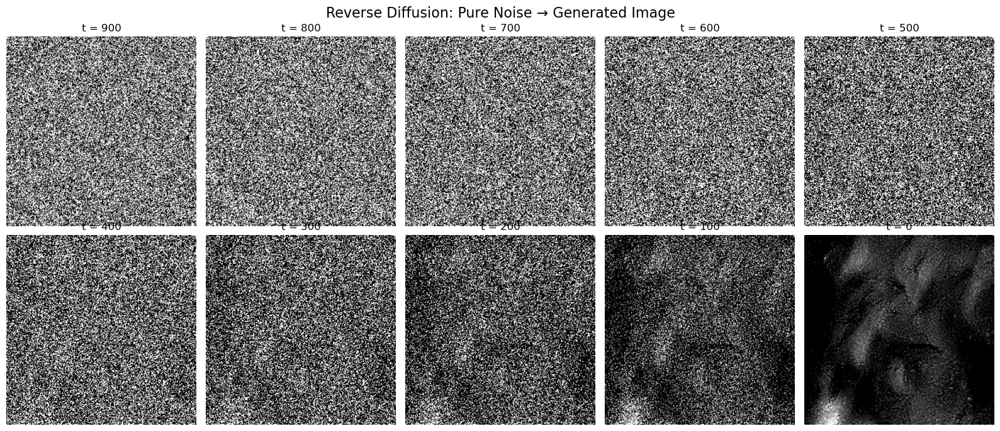

In [ ]:
import matplotlib.pyplot as plt
import torch
import os

save_dir = r"C:\Users\kavya\Downloads\Ocular_Project\results\reverse_trajectory"

steps = [900, 800, 700, 600, 500, 400, 300, 200, 100, 0]

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.flatten()

for ax, t in zip(axes, steps):

    x_t = torch.load(
        os.path.join(save_dir, f"x_t{t}.pt"),
        map_location="cpu"
    )

    img = (x_t[0, 0] + 1) / 2
    img = img.clamp(0, 1)

    ax.imshow(img, cmap="gray")
    ax.set_title(f"t = {t}")
    ax.axis("off")

plt.suptitle(
    "Reverse Diffusion: Pure Noise → Generated Image",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
import os
import torch

save_dir = r"C:\Users\kavya\Downloads\Ocular_Project\results\reverse_trajectory"

steps = [900, 800, 700, 600, 500, 400, 300, 200, 100, 0]

for t in steps:
    x_t = torch.load(
        os.path.join(save_dir, f"x_t{t}.pt"),
        map_location="cpu"
    )

    print(
        f"t={t:3d} | "
        f"mean={x_t.mean():.4f} | "
        f"std={x_t.std():.4f} | "
        f"min={x_t.min():.4f} | "
        f"max={x_t.max():.4f}"
    )

t=900 | mean=-0.0203 | std=1.0730 | min=-4.4587 | max=4.5395
t=800 | mean=-0.0421 | std=1.1492 | min=-4.8154 | max=5.4051
t=700 | mean=-0.0814 | std=1.2310 | min=-4.7607 | max=6.9990
t=600 | mean=-0.1397 | std=1.3249 | min=-5.3386 | max=6.6280
t=500 | mean=-0.2447 | std=1.4083 | min=-6.0364 | max=5.9317
t=400 | mean=-0.3785 | std=1.4463 | min=-6.7485 | max=5.7518
t=300 | mean=-0.5360 | std=1.4021 | min=-6.2522 | max=5.1459
t=200 | mean=-0.6859 | std=1.2330 | min=-5.7630 | max=4.4471
t=100 | mean=-0.7991 | std=0.9044 | min=-5.2413 | max=3.0627
t=  0 | mean=-0.8573 | std=0.3976 | min=-2.7642 | max=1.5438


In [ ]:
# Check the model's direct x0 prediction at selected timesteps

import os
import torch

save_dir = r"C:\Users\kavya\Downloads\Ocular_Project\results\reverse_trajectory"

check_steps = [300, 200, 100, 0]

with torch.no_grad():
    for t in check_steps:

        x_t = torch.load(
            os.path.join(save_dir, f"x_t{t}.pt"),
            map_location=device
        )

        t_batch = torch.tensor([t], device=device)

        eps = model(x_t, t_batch)

        alpha_bar_t = alpha_bars[t]

        # Estimate the clean image x0
        x0_pred = (
            x_t - torch.sqrt(1 - alpha_bar_t) * eps
        ) / torch.sqrt(alpha_bar_t)

        print(
            f"t={t:3d} | "
            f"x0_pred mean={x0_pred.mean().item():.4f} | "
            f"std={x0_pred.std().item():.4f} | "
            f"min={x0_pred.min().item():.4f} | "
            f"max={x0_pred.max().item():.4f}"
        )

t=300 | x0_pred mean=-0.8487 | std=1.0676 | min=-5.6570 | max=3.7036
t=200 | x0_pred mean=-0.8459 | std=0.8498 | min=-4.7541 | max=3.1474
t=100 | x0_pred mean=-0.8460 | std=0.6464 | min=-4.1907 | max=2.3329
t=  0 | x0_pred mean=-0.8573 | std=0.3917 | min=-2.6858 | max=1.5126


In [ ]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import pandas as pd
import os
import torchvision.transforms as transforms

# Paths
csv_path = r"C:\Users\kavya\Downloads\Ocular_Project\datasets\iris_thousands.csv"
image_root = r"C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand"

df = pd.read_csv(csv_path)

# Same label split used previously
unique_labels = df["Label"].unique()

val_labels = set(unique_labels[1200:1600])
val_df = df[df["Label"].isin(val_labels)].copy()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

class IrisDataset(Dataset):
    def __init__(self, dataframe, root, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.root = root
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # Convert CSV Kaggle path to local path
        rel_path = row["ImagePath"].replace(
            "/kaggle/input/casia-iris-thousand/CASIA-Iris-Thousand/",
            ""
        )

        path = os.path.join(self.root, rel_path)

        image = Image.open(path).convert("L")

        if self.transform:
            image = self.transform(image)

        return image, row["Label"]

val_dataset = IrisDataset(
    val_df,
    image_root,
    transform
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Validation loader rebuilt.")
print("Images:", len(val_dataset))
print("Labels:", val_df["Label"].nunique())

Validation loader rebuilt.
Images: 4000
Labels: 400


In [ ]:
model.eval()

# Take one real validation image
real_x, _ = next(iter(val_loader))
real_x = real_x[:1].to(device)

print("Real image stats:")
print("mean:", real_x.mean().item())
print("std :", real_x.std().item())

for t in [300, 200, 100]:

    t_batch = torch.tensor([t], device=device)

    # Add the same type of forward diffusion noise
    noise = torch.randn_like(real_x)

    alpha_bar_t = alpha_bars[t]

    x_t_real = (
        torch.sqrt(alpha_bar_t) * real_x
        + torch.sqrt(1 - alpha_bar_t) * noise
    )

    # Predict noise
    with torch.no_grad():
        eps_real = model(x_t_real, t_batch)

    # Predict clean image x0
    x0_real_pred = (
        x_t_real
        - torch.sqrt(1 - alpha_bar_t) * eps_real
    ) / torch.sqrt(alpha_bar_t)

    print(
        f"REAL image, t={t:3d} | "
        f"x0_pred mean={x0_real_pred.mean().item():.4f} | "
        f"std={x0_real_pred.std().item():.4f}"
    )

Real image stats:
mean: -0.2939039468765259
std : 0.23412761092185974
REAL image, t=300 | x0_pred mean=-0.2827 | std=0.2550
REAL image, t=200 | x0_pred mean=-0.2943 | std=0.2479
REAL image, t=100 | x0_pred mean=-0.2935 | std=0.2527


Generated from t=700
Mean: -0.11803674697875977
Std : 0.281812846660614
Min : -0.9907681345939636
Max : 0.9939368367195129


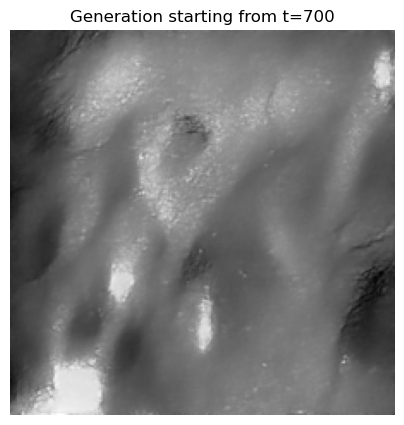

In [ ]:
# Generate from t=700 instead of pure noise (t=999)

import torch
import matplotlib.pyplot as plt

model.eval()

torch.manual_seed(42)

start_t = 700

x = torch.randn(1, 1, 224, 224, device=device)

with torch.no_grad():

    for t in range(start_t, -1, -1):

        t_batch = torch.tensor([t], device=device)

        eps = model(x, t_batch)

        alpha_t = alphas[t]
        alpha_bar_t = alpha_bars[t]
        beta_t = betas[t]

        mean = (
            1 / torch.sqrt(alpha_t)
        ) * (
            x - (beta_t / torch.sqrt(1 - alpha_bar_t)) * eps
        )

        if t > 0:
            posterior_var = (
                beta_t * (1 - alpha_bars[t - 1])
                / (1 - alpha_bar_t)
            )

            x = mean + torch.sqrt(posterior_var) * torch.randn_like(x)
        else:
            x = mean

generated_700 = x.detach().cpu()

print("Generated from t=700")
print("Mean:", generated_700.mean().item())
print("Std :", generated_700.std().item())
print("Min :", generated_700.min().item())
print("Max :", generated_700.max().item())

plt.figure(figsize=(5, 5))

img = (generated_700[0, 0] + 1) / 2
img = img.clamp(0, 1)

plt.imshow(img, cmap="gray")
plt.title("Generation starting from t=700")
plt.axis("off")
plt.show()

DDIM generation complete.
Mean: -0.9296903014183044
Std : 6.258862018585205
Min : -29.100839614868164
Max : 39.10279083251953


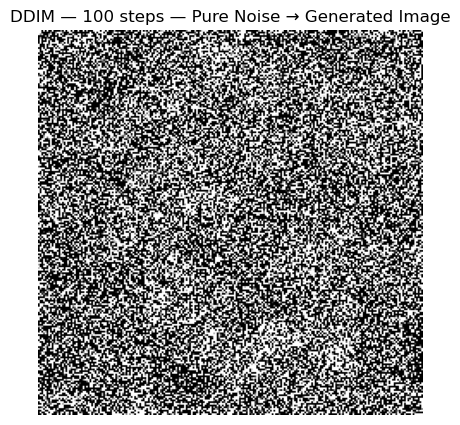

In [ ]:
# DDIM sampling test — no retraining

import torch
import matplotlib.pyplot as plt

model.eval()

torch.manual_seed(42)

# Use 100 DDIM sampling steps instead of all 1000
ddim_steps = 100
timesteps = torch.linspace(999, 0, ddim_steps).long().tolist()

# Start from pure Gaussian noise
x = torch.randn(1, 1, 224, 224, device=device)

with torch.no_grad():

    for i, t in enumerate(timesteps):

        t_batch = torch.tensor([t], device=device)

        eps = model(x, t_batch)

        alpha_bar_t = alpha_bars[t]

        # Predict clean image x0
        x0_pred = (
            x - torch.sqrt(1 - alpha_bar_t) * eps
        ) / torch.sqrt(alpha_bar_t)

        # No clipping here — we already found clipping can hurt reconstruction
        if i < len(timesteps) - 1:

            t_prev = timesteps[i + 1]
            alpha_bar_prev = alpha_bars[t_prev]

            # Deterministic DDIM: eta = 0
            x = (
                torch.sqrt(alpha_bar_prev) * x0_pred
                + torch.sqrt(1 - alpha_bar_prev) * eps
            )

        else:
            x = x0_pred

generated_ddim = x.detach().cpu()

print("DDIM generation complete.")
print("Mean:", generated_ddim.mean().item())
print("Std :", generated_ddim.std().item())
print("Min :", generated_ddim.min().item())
print("Max :", generated_ddim.max().item())

# Display result
img = (generated_ddim[0, 0] + 1) / 2
img = img.clamp(0, 1)

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray")
plt.title("DDIM — 100 steps — Pure Noise → Generated Image")
plt.axis("off")
plt.show()

In [ ]:
# Diagnose the FIRST DDIM step only
# This does NOT run the full sampler.

torch.manual_seed(42)

x_test = torch.randn(1, 1, 224, 224, device=device)

t = 999
t_batch = torch.tensor([t], device=device)

with torch.no_grad():
    eps = model(x_test, t_batch)

alpha_bar_t = alpha_bars[t]

x0_pred = (
    x_test - torch.sqrt(1 - alpha_bar_t) * eps
) / torch.sqrt(alpha_bar_t)

print("DDIM first-step diagnostic at t=999")
print("-----------------------------------")
print("x_t     mean:", x_test.mean().item())
print("x_t     std :", x_test.std().item())
print("eps     mean:", eps.mean().item())
print("eps     std :", eps.std().item())
print("x0_pred mean:", x0_pred.mean().item())
print("x0_pred std :", x0_pred.std().item())
print("x0_pred min :", x0_pred.min().item())
print("x0_pred max :", x0_pred.max().item())

DDIM first-step diagnostic at t=999
-----------------------------------
x_t     mean: -0.007884430699050426
x_t     std : 0.9971688389778137
eps     mean: -0.004750989843159914
eps     std : 0.9388254880905151
x0_pred mean: -0.4932518005371094
x0_pred std : 9.558450698852539
x0_pred min : -60.36021423339844
x0_pred max : 120.55899047851562


start t=900 | mean=-0.3510 | std=0.3374
start t=800 | mean=-0.1738 | std=0.3130
start t=700 | mean=-0.1180 | std=0.2818
start t=600 | mean=-0.0948 | std=0.2429
start t=500 | mean=-0.0747 | std=0.2022


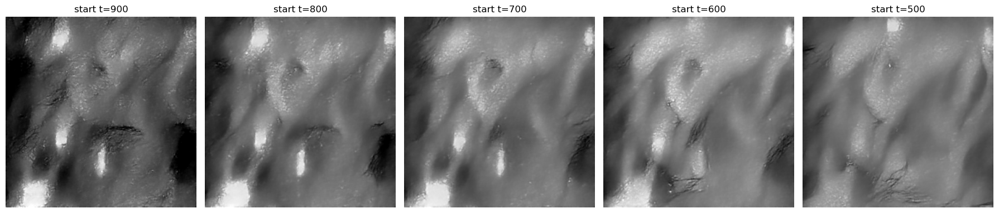

In [ ]:
import torch
import matplotlib.pyplot as plt

model.eval()

start_steps = [900, 800, 700, 600, 500]
results = {}

for start_t in start_steps:

    torch.manual_seed(42)

    x = torch.randn(1, 1, 224, 224, device=device)

    with torch.no_grad():

        for t in range(start_t, -1, -1):

            t_batch = torch.tensor([t], device=device)

            eps = model(x, t_batch)

            alpha_t = alphas[t]
            alpha_bar_t = alpha_bars[t]
            beta_t = betas[t]

            mean = (
                1 / torch.sqrt(alpha_t)
            ) * (
                x - (beta_t / torch.sqrt(1 - alpha_bar_t)) * eps
            )

            if t > 0:
                posterior_var = (
                    beta_t * (1 - alpha_bars[t - 1])
                    / (1 - alpha_bar_t)
                )

                x = mean + torch.sqrt(posterior_var) * torch.randn_like(x)
            else:
                x = mean

    results[start_t] = x.cpu()

    print(
        f"start t={start_t} | "
        f"mean={x.mean().item():.4f} | "
        f"std={x.std().item():.4f}"
    )

# Visual comparison
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, start_t in zip(axes, start_steps):

    img = (results[start_t][0, 0] + 1) / 2
    img = img.clamp(0, 1)

    ax.imshow(img, cmap="gray")
    ax.set_title(f"start t={start_t}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn.functional as F

# Weight of the new clean-image (x0) objective
LAMBDA_X0 = 0.1

# Get one real validation batch just to verify everything works
real_x, _ = next(iter(val_loader))
real_x = real_x.to(device)

batch_size = real_x.shape[0]

# Random diffusion timesteps
t = torch.randint(
    0,
    1000,
    (batch_size,),
    device=device
)

# Random Gaussian noise
noise = torch.randn_like(real_x)

# Forward diffusion
alpha_bar = alpha_bars[t].view(-1, 1, 1, 1)

x_t = (
    torch.sqrt(alpha_bar) * real_x
    + torch.sqrt(1 - alpha_bar) * noise
)

# Model predicts epsilon
pred_noise = model(x_t, t)

# Normal diffusion loss
eps_loss = F.mse_loss(pred_noise, noise)

# Predict clean image x0
x0_pred = (
    x_t
    - torch.sqrt(1 - alpha_bar) * pred_noise
) / torch.sqrt(alpha_bar.clamp(min=1e-5))

# Only use x0 loss where t <= 700
low_noise_mask = (t <= 700)

if low_noise_mask.any():
    x0_loss = F.mse_loss(
        x0_pred[low_noise_mask],
        real_x[low_noise_mask]
    )
else:
    x0_loss = torch.tensor(0.0, device=device)

total_loss = eps_loss + LAMBDA_X0 * x0_loss

print("Loss test successful.")
print("epsilon loss :", eps_loss.item())
print("x0 loss      :", x0_loss.item())
print("total loss   :", total_loss.item())
print("x0 weight    :", LAMBDA_X0)
print("x0 timesteps : t <= 700")

Loss test successful.
epsilon loss : 0.006368796341121197
x0 loss      : 0.0583556704223156
total loss   : 0.012204363942146301
x0 weight    : 0.1
x0 timesteps : t <= 700


In [ ]:
import os
import torch
import pandas as pd

print("=" * 60)
print("PRE-TRAINING CHECK")
print("=" * 60)

# --------------------------------------------------
# 1. Check important files
# --------------------------------------------------

checkpoint_path = r"C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth"

csv_path = r"C:\Users\kavya\Downloads\Ocular_Project\datasets\iris_thousands.csv"

image_root = r"C:\Users\kavya\Downloads\Ocular_Project\datasets\CASIA-Iris-Thousand\CASIA-Iris-Thousand"

print("\n[FILES]")

print("Checkpoint exists :", os.path.exists(checkpoint_path))
print("CSV exists        :", os.path.exists(csv_path))
print("Image root exists :", os.path.exists(image_root))

assert os.path.exists(checkpoint_path)
assert os.path.exists(csv_path)
assert os.path.exists(image_root)

# --------------------------------------------------
# 2. Check dataset
# --------------------------------------------------

df = pd.read_csv(csv_path)

unique_labels = df["Label"].unique()

print("\n[DATASET]")
print("Images           :", len(df))
print("Unique labels    :", len(unique_labels))
print("Images/label     :", df["Label"].value_counts().unique())

assert len(df) == 20000
assert len(unique_labels) == 2000
assert df["Label"].value_counts().nunique() == 1
assert df["Label"].value_counts().iloc[0] == 10

# --------------------------------------------------
# 3. Check split
# --------------------------------------------------

train_labels = set(unique_labels[:1200])
val_labels   = set(unique_labels[1200:1600])
test_labels  = set(unique_labels[1600:2000])

print("\n[SPLIT]")
print("Train labels     :", len(train_labels))
print("Validation labels:", len(val_labels))
print("Test labels      :", len(test_labels))

print("Train images     :", df[df["Label"].isin(train_labels)].shape[0])
print("Val images       :", df[df["Label"].isin(val_labels)].shape[0])
print("Test images      :", df[df["Label"].isin(test_labels)].shape[0])

assert len(train_labels) == 1200
assert len(val_labels) == 400
assert len(test_labels) == 400

assert train_labels.isdisjoint(val_labels)
assert train_labels.isdisjoint(test_labels)
assert val_labels.isdisjoint(test_labels)

# --------------------------------------------------
# 4. Check model
# --------------------------------------------------

print("\n[MODEL]")

assert isinstance(model, DiffusionUNet)

param_count = sum(p.numel() for p in model.parameters())

print("Parameters       :", param_count)
print("Device           :", device)

assert param_count == 7_842_177

# --------------------------------------------------
# 5. Check diffusion schedule
# --------------------------------------------------

print("\n[DIFFUSION]")

print("Timesteps        :", T)
print("Beta start       :", beta_start)
print("Beta end         :", beta_end)

assert T == 1000
assert abs(beta_start - 0.0001) < 1e-10
assert abs(beta_end - 0.02) < 1e-10

print("\n" + "=" * 60)
print("ALL BASIC CHECKS PASSED")
print("NO TRAINING HAS STARTED")
print("=" * 60)


PRE-TRAINING CHECK

[FILES]
Checkpoint exists : True
CSV exists        : True
Image root exists : True

[DATASET]
Images           : 20000
Unique labels    : 2000
Images/label     : [10]

[SPLIT]
Train labels     : 1200
Validation labels: 400
Test labels      : 400
Train images     : 12000
Val images       : 4000
Test images      : 4000

[MODEL]
Parameters       : 7842177
Device           : cuda

[DIFFUSION]
Timesteps        : 1000
Beta start       : 0.0001
Beta end         : 0.02

ALL BASIC CHECKS PASSED
NO TRAINING HAS STARTED


In [ ]:
# SECOND PRE-FLIGHT CHECK
# No training / no optimizer step

import torch
import torch.nn.functional as F

model.eval()

# --------------------------------------------------
# 1. Get a real training batch
# --------------------------------------------------

train_labels = set(unique_labels[:1200])
train_df = df[df["Label"].isin(train_labels)].copy()

train_dataset = IrisDataset(
    train_df,
    image_root,
    transform
)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

real_x, _ = next(iter(train_loader))
real_x = real_x.to(device)

print("=" * 60)
print("SECOND PRE-FLIGHT CHECK")
print("=" * 60)

print("\n[REAL TRAINING BATCH]")
print("Shape :", real_x.shape)
print("Dtype :", real_x.dtype)
print("Min   :", real_x.min().item())
print("Max   :", real_x.max().item())
print("Mean  :", real_x.mean().item())
print("Std   :", real_x.std().item())

assert real_x.shape == (8, 1, 224, 224)
assert torch.isfinite(real_x).all()
assert real_x.min() >= -1.0
assert real_x.max() <= 1.0

# --------------------------------------------------
# 2. Create noisy images
# --------------------------------------------------

torch.manual_seed(42)

t = torch.randint(
    1,
    701,                 # x0 loss only through t=700
    (real_x.shape[0],),
    device=device
)

noise = torch.randn_like(real_x)

alpha_bar = alpha_bars[t].view(-1, 1, 1, 1)

x_t = (
    torch.sqrt(alpha_bar) * real_x
    + torch.sqrt(1 - alpha_bar) * noise
)

print("\n[NOISY BATCH]")
print("Timestep range:", t.min().item(), "to", t.max().item())
print("Shape         :", x_t.shape)
print("Mean          :", x_t.mean().item())
print("Std           :", x_t.std().item())
print("Finite        :", torch.isfinite(x_t).all().item())

assert torch.isfinite(x_t).all()

# --------------------------------------------------
# 3. Model prediction
# --------------------------------------------------

with torch.no_grad():

    pred_noise = model(x_t, t)

    eps_loss = F.mse_loss(
        pred_noise,
        noise
    )

    # Recover predicted clean image
    x0_pred = (
        x_t
        - torch.sqrt(1 - alpha_bar) * pred_noise
    ) / torch.sqrt(alpha_bar)

    x0_loss = F.mse_loss(
        x0_pred,
        real_x
    )

    total_loss = (
        eps_loss
        + LAMBDA_X0 * x0_loss
    )

print("\n[MODEL + LOSS]")
print("Pred noise shape:", pred_noise.shape)
print("Epsilon loss    :", eps_loss.item())
print("x0 loss         :", x0_loss.item())
print("Total loss      :", total_loss.item())

print("\n[x0 PREDICTION]")
print("Mean:", x0_pred.mean().item())
print("Std :", x0_pred.std().item())
print("Min :", x0_pred.min().item())
print("Max :", x0_pred.max().item())

# --------------------------------------------------
# 4. Safety checks
# --------------------------------------------------

assert pred_noise.shape == real_x.shape
assert x0_pred.shape == real_x.shape

assert torch.isfinite(pred_noise).all()
assert torch.isfinite(x0_pred).all()

assert torch.isfinite(eps_loss)
assert torch.isfinite(x0_loss)
assert torch.isfinite(total_loss)

print("\n" + "=" * 60)
print("SECOND PRE-FLIGHT CHECK PASSED")
print("NO TRAINING HAS STARTED")
print("=" * 60)

SECOND PRE-FLIGHT CHECK

[REAL TRAINING BATCH]
Shape : torch.Size([8, 1, 224, 224])
Dtype : torch.float32
Min   : -1.0
Max   : 0.8509804010391235
Mean  : -0.3024578094482422
Std   : 0.22664736211299896

[NOISY BATCH]
Timestep range: 44 to 699
Shape         : torch.Size([8, 1, 224, 224])
Mean          : -0.11992382258176804
Std           : 0.8701111078262329
Finite        : True

[MODEL + LOSS]
Pred noise shape: torch.Size([8, 1, 224, 224])
Epsilon loss    : 0.009586997330188751
x0 loss         : 0.13747382164001465
Total loss      : 0.023334380239248276

[x0 PREDICTION]
Mean: -0.2745005488395691
Std : 0.4084273874759674
Min : -6.924880504608154
Max : 7.956742286682129

SECOND PRE-FLIGHT CHECK PASSED
NO TRAINING HAS STARTED


In [ ]:
# FINAL PRE-TRAINING SAFETY CHECK
# One forward + backward pass only.
# No optimizer.step(), so model weights are NOT changed.

import torch
import torch.nn.functional as F

print("=" * 60)
print("FINAL PRE-TRAINING SAFETY CHECK")
print("=" * 60)

# --------------------------------------------------
# Fresh copy of the ORIGINAL epoch-26 baseline
# --------------------------------------------------

test_model = DiffusionUNet().to(device)

ckpt = torch.load(
    checkpoint_path,
    map_location=device
)

if "model_state_dict" in ckpt:
    test_model.load_state_dict(ckpt["model_state_dict"])
else:
    test_model.load_state_dict(ckpt)

test_model.train()

optimizer_test = torch.optim.AdamW(
    test_model.parameters(),
    lr=1e-4
)

# --------------------------------------------------
# One controlled batch
# --------------------------------------------------

real_x, _ = next(iter(train_loader))
real_x = real_x.to(device)

torch.manual_seed(123)

t = torch.randint(
    1,
    701,
    (real_x.shape[0],),
    device=device
)

noise = torch.randn_like(real_x)

alpha_bar = alpha_bars[t].view(-1, 1, 1, 1)

x_t = (
    torch.sqrt(alpha_bar) * real_x
    + torch.sqrt(1 - alpha_bar) * noise
)

# --------------------------------------------------
# Forward
# --------------------------------------------------

pred_noise = test_model(x_t, t)

eps_loss = F.mse_loss(
    pred_noise,
    noise
)

x0_pred = (
    x_t
    - torch.sqrt(1 - alpha_bar) * pred_noise
) / torch.sqrt(alpha_bar)

# IMPORTANT:
# Keep x0 target in [-1,1].
# Prevent extreme predicted pixels from dominating training.
x0_pred_clipped = x0_pred.clamp(-1.0, 1.0)

x0_loss = F.mse_loss(
    x0_pred_clipped,
    real_x
)

total_loss = (
    eps_loss
    + LAMBDA_X0 * x0_loss
)

# --------------------------------------------------
# Backward — but NO optimizer.step()
# --------------------------------------------------

optimizer_test.zero_grad(set_to_none=True)

total_loss.backward()

# Check gradient health
finite_grads = True
max_grad = 0.0

for p in test_model.parameters():
    if p.grad is not None:
        if not torch.isfinite(p.grad).all():
            finite_grads = False

        max_grad = max(
            max_grad,
            p.grad.detach().abs().max().item()
        )

print("\n[LOSS]")
print("Epsilon loss       :", eps_loss.item())
print("Clipped x0 loss    :", x0_loss.item())
print("Total loss         :", total_loss.item())

print("\n[GRADIENTS]")
print("Gradients finite   :", finite_grads)
print("Maximum grad value :", max_grad)

print("\n[OPTIMIZER]")
print("AdamW              : OK")
print("Learning rate      :", optimizer_test.param_groups[0]["lr"])

# --------------------------------------------------
# Safety assertions
# --------------------------------------------------

assert torch.isfinite(total_loss)
assert finite_grads
assert max_grad < 1000

# Explicitly delete test model
del test_model
del optimizer_test

torch.cuda.empty_cache()

print("\n" + "=" * 60)
print("FINAL PRE-TRAINING CHECK PASSED")
print("MODEL WEIGHTS WERE NOT CHANGED")
print("READY FOR CONTROLLED TRAINING")
print("=" * 60)

FINAL PRE-TRAINING SAFETY CHECK

[LOSS]
Epsilon loss       : 0.007338103372603655
Clipped x0 loss    : 0.03462857007980347
Total loss         : 0.010800960473716259

[GRADIENTS]
Gradients finite   : True
Maximum grad value : 0.1037408709526062

[OPTIMIZER]
AdamW              : OK
Learning rate      : 0.0001

FINAL PRE-TRAINING CHECK PASSED
MODEL WEIGHTS WERE NOT CHANGED
READY FOR CONTROLLED TRAINING


In [ ]:
# ================================================================
# CASIA-IRIS-THOUSAND
# x0-AWARE DIFFUSION TRAINING
#
# 30 EPOCHS
# LIVE TQDM PROGRESS BAR
# STARTS FROM ORIGINAL BASELINE
#
# IMPORTANT:
# train_loader / val_loader return (image, label)
# so we correctly use batch[0].
# ================================================================

from pathlib import Path
import time
import csv

import torch
import torch.nn.functional as F
from tqdm.auto import tqdm


# ================================================================
# 1. SETTINGS
# ================================================================

NUM_EPOCHS = 30

BATCH_SIZE = 8
GRAD_ACCUM = 4
EFFECTIVE_BATCH = BATCH_SIZE * GRAD_ACCUM

LR = 1e-4

# x0-aware objective
LAMBDA_X0 = 0.1
X0_T_MAX = 700

# gradient safety
GRAD_CLIP = 1.0


# ================================================================
# 2. PATHS
# ================================================================

BASELINE_PATH = Path(
    r"C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth"
)

OUTPUT_DIR = Path(
    r"C:\Users\kavya\Downloads\Ocular_Project\models\x0_aware_30epoch_progress"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_PATH = (
    OUTPUT_DIR /
    "CASIA_Thousand_x0_aware_30epoch_best.pth"
)

HISTORY_PATH = (
    OUTPUT_DIR /
    "x0_aware_30epoch_training_history.csv"
)


# ================================================================
# 3. STARTUP INFORMATION
# ================================================================

print("=" * 75)
print("STARTING 30-EPOCH x0-AWARE TRAINING")
print("=" * 75)

print(f"Epochs             : {NUM_EPOCHS}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Grad accumulation  : {GRAD_ACCUM}")
print(f"Effective batch    : {EFFECTIVE_BATCH}")
print(f"Learning rate      : {LR}")
print(f"x0 weight          : {LAMBDA_X0}")
print(f"x0 timesteps       : t <= {X0_T_MAX}")
print(f"Gradient clipping   : {GRAD_CLIP}")
print(f"Baseline            : {BASELINE_PATH}")
print(f"Output folder      : {OUTPUT_DIR}")

print("=" * 75)


# ================================================================
# 4. CHECK REQUIRED VARIABLES
# ================================================================

required = [
    "model",
    "train_loader",
    "val_loader",
    "device",
    "alpha_bars"
]

missing = [
    name
    for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing notebook variables: "
        + ", ".join(missing)
        + "\n\n"
        "Run your dataset/model setup cells first."
    )


# ================================================================
# 5. CHECK BASELINE
# ================================================================

if not BASELINE_PATH.exists():

    raise FileNotFoundError(
        f"Original baseline checkpoint not found:\n"
        f"{BASELINE_PATH}"
    )


# ================================================================
# 6. LOAD ORIGINAL BASELINE
# ================================================================

print("\nLoading original baseline checkpoint...")

ckpt = torch.load(
    BASELINE_PATH,
    map_location=device,
    weights_only=False
)

if isinstance(ckpt, dict):

    if "model_state_dict" in ckpt:

        model.load_state_dict(
            ckpt["model_state_dict"]
        )

    elif "state_dict" in ckpt:

        model.load_state_dict(
            ckpt["state_dict"]
        )

    else:

        model.load_state_dict(
            ckpt
        )

else:

    model.load_state_dict(
        ckpt
    )


model = model.to(device)

print("Original baseline loaded successfully.")


# ================================================================
# 7. FRESH OPTIMIZER
# ================================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR
)


# ================================================================
# 8. MIXED PRECISION
# ================================================================

use_amp = (
    device.type == "cuda"
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

print(f"Device             : {device}")
print(f"AMP enabled        : {use_amp}")


# ================================================================
# 9. x0 PREDICTION FUNCTION
# ================================================================

def predict_x0(
    x_t,
    t,
    eps_pred
):

    alpha_bar_t = alpha_bars[t].to(
        x_t.device
    )

    sqrt_alpha_bar = torch.sqrt(
        alpha_bar_t
    ).view(
        -1,
        1,
        1,
        1
    )

    sqrt_one_minus_alpha_bar = torch.sqrt(
        1.0 - alpha_bar_t
    ).view(
        -1,
        1,
        1,
        1
    )

    x0_pred = (
        x_t
        - sqrt_one_minus_alpha_bar * eps_pred
    ) / sqrt_alpha_bar

    return x0_pred


# ================================================================
# 10. VALIDATION FUNCTION
# ================================================================

@torch.no_grad()
def run_validation():

    model.eval()

    total_loss_sum = 0.0
    total_eps_sum = 0.0
    total_x0_sum = 0.0

    total_samples = 0

    # ------------------------------------------------------------
    # LIVE VALIDATION BAR
    # ------------------------------------------------------------

    val_bar = tqdm(
        val_loader,
        desc="Validation",
        leave=False,
        dynamic_ncols=True
    )

    # ------------------------------------------------------------
    # VALIDATION BATCH LOOP
    # ------------------------------------------------------------

    for batch in val_bar:

        # IMPORTANT:
        # Dataset returns (image, label)
        real_x = batch[0].to(
            device,
            non_blocking=True
        )

        bsz = real_x.shape[0]

        # --------------------------------------------------------
        # RANDOM TIMESTEP
        # --------------------------------------------------------

        t = torch.randint(
            0,
            1000,
            (bsz,),
            device=device
        ).long()

        # --------------------------------------------------------
        # RANDOM NOISE
        # --------------------------------------------------------

        noise = torch.randn_like(
            real_x
        )

        # --------------------------------------------------------
        # CREATE x_t
        # --------------------------------------------------------

        alpha_bar_t = alpha_bars[t].to(
            device
        )

        sqrt_alpha_bar = torch.sqrt(
            alpha_bar_t
        ).view(
            -1,
            1,
            1,
            1
        )

        sqrt_one_minus_alpha_bar = torch.sqrt(
            1.0 - alpha_bar_t
        ).view(
            -1,
            1,
            1,
            1
        )

        x_t = (
            sqrt_alpha_bar * real_x
            +
            sqrt_one_minus_alpha_bar * noise
        )

        # --------------------------------------------------------
        # MODEL
        # --------------------------------------------------------

        with torch.amp.autocast(
            device_type="cuda",
            enabled=use_amp
        ):

            pred_noise = model(
                x_t,
                t
            )

            # ----------------------------------------------------
            # EPSILON LOSS
            # ----------------------------------------------------

            eps_loss = F.mse_loss(
                pred_noise,
                noise
            )

            # ----------------------------------------------------
            # x0 LOSS
            # ----------------------------------------------------

            mask = (
                t <= X0_T_MAX
            )

            if mask.any():

                x0_pred = predict_x0(
                    x_t[mask],
                    t[mask],
                    pred_noise[mask]
                )

                # Clip ONLY for x0 loss
                x0_pred_clipped = torch.clamp(
                    x0_pred,
                    -1.0,
                    1.0
                )

                x0_loss = F.mse_loss(
                    x0_pred_clipped,
                    real_x[mask]
                )

            else:

                x0_loss = torch.zeros(
                    (),
                    device=device
                )

            # ----------------------------------------------------
            # TOTAL LOSS
            # ----------------------------------------------------

            total_loss = (
                eps_loss
                +
                LAMBDA_X0 * x0_loss
            )

        # --------------------------------------------------------
        # ACCUMULATE
        # --------------------------------------------------------

        total_loss_sum += (
            total_loss.item()
            *
            bsz
        )

        total_eps_sum += (
            eps_loss.item()
            *
            bsz
        )

        total_x0_sum += (
            x0_loss.item()
            *
            bsz
        )

        total_samples += bsz

        val_bar.set_postfix(
            loss=f"{total_loss.item():.5f}"
        )

    # ------------------------------------------------------------
    # AVERAGES
    # ------------------------------------------------------------

    val_total = (
        total_loss_sum
        /
        total_samples
    )

    val_eps = (
        total_eps_sum
        /
        total_samples
    )

    val_x0 = (
        total_x0_sum
        /
        total_samples
    )

    return (
        val_total,
        val_eps,
        val_x0
    )


# ================================================================
# 11. TRAINING START
# ================================================================

print("\n")
print("=" * 75)
print("TRAINING STARTING NOW")
print("=" * 75)
print("Epoch 01/30 will appear below.")
print("=" * 75)


best_val_loss = float("inf")


# ================================================================
# 12. MAIN 30-EPOCH LOOP
# ================================================================

for epoch in range(
    1,
    NUM_EPOCHS + 1
):

    model.train()

    epoch_start = time.time()

    total_running = 0.0
    eps_running = 0.0
    x0_running = 0.0

    samples_seen = 0

    optimizer.zero_grad(
        set_to_none=True
    )

    # ============================================================
    # LIVE TRAINING PROGRESS BAR
    # ============================================================

    train_bar = tqdm(
        enumerate(train_loader),
        total=len(train_loader),
        desc=f"Epoch {epoch:02d}/{NUM_EPOCHS}",
        dynamic_ncols=True,
        leave=True
    )

    # ============================================================
    # BATCH LOOP
    # ============================================================

    for step, batch in train_bar:

        # IMPORTANT:
        # Dataset returns (image, label)
        real_x = batch[0].to(
            device,
            non_blocking=True
        )

        bsz = real_x.shape[0]

        # --------------------------------------------------------
        # RANDOM TIMESTEP
        # --------------------------------------------------------

        t = torch.randint(
            0,
            1000,
            (bsz,),
            device=device
        ).long()

        # --------------------------------------------------------
        # RANDOM NOISE
        # --------------------------------------------------------

        noise = torch.randn_like(
            real_x
        )

        # --------------------------------------------------------
        # FORWARD DIFFUSION
        # --------------------------------------------------------

        alpha_bar_t = alpha_bars[t].to(
            device
        )

        sqrt_alpha_bar = torch.sqrt(
            alpha_bar_t
        ).view(
            -1,
            1,
            1,
            1
        )

        sqrt_one_minus_alpha_bar = torch.sqrt(
            1.0 - alpha_bar_t
        ).view(
            -1,
            1,
            1,
            1
        )

        x_t = (
            sqrt_alpha_bar * real_x
            +
            sqrt_one_minus_alpha_bar * noise
        )

        # --------------------------------------------------------
        # FORWARD PASS
        # --------------------------------------------------------

        with torch.amp.autocast(
            device_type="cuda",
            enabled=use_amp
        ):

            pred_noise = model(
                x_t,
                t
            )

            # ----------------------------------------------------
            # EPSILON LOSS
            # ----------------------------------------------------

            eps_loss = F.mse_loss(
                pred_noise,
                noise
            )

            # ----------------------------------------------------
            # x0 LOSS FOR t <= 700
            # ----------------------------------------------------

            mask = (
                t <= X0_T_MAX
            )

            if mask.any():

                x0_pred = predict_x0(
                    x_t[mask],
                    t[mask],
                    pred_noise[mask]
                )

                # IMPORTANT:
                # Clip only for x0 reconstruction loss
                x0_pred_clipped = torch.clamp(
                    x0_pred,
                    -1.0,
                    1.0
                )

                x0_loss = F.mse_loss(
                    x0_pred_clipped,
                    real_x[mask]
                )

            else:

                x0_loss = torch.zeros(
                    (),
                    device=device
                )

            # ----------------------------------------------------
            # COMBINED LOSS
            # ----------------------------------------------------

            total_loss = (
                eps_loss
                +
                LAMBDA_X0 * x0_loss
            )

            # ----------------------------------------------------
            # GRADIENT ACCUMULATION
            # ----------------------------------------------------

            loss_for_backward = (
                total_loss
                /
                GRAD_ACCUM
            )

        # --------------------------------------------------------
        # BACKWARD
        # --------------------------------------------------------

        scaler.scale(
            loss_for_backward
        ).backward()

        # --------------------------------------------------------
        # OPTIMIZER STEP
        # --------------------------------------------------------

        should_step = (
            (step + 1) % GRAD_ACCUM == 0
            or
            (step + 1) == len(train_loader)
        )

        if should_step:

            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP
            )

            scaler.step(
                optimizer
            )

            scaler.update()

            optimizer.zero_grad(
                set_to_none=True
            )

        # --------------------------------------------------------
        # RUNNING STATISTICS
        # --------------------------------------------------------

        total_running += (
            total_loss.item()
            *
            bsz
        )

        eps_running += (
            eps_loss.item()
            *
            bsz
        )

        x0_running += (
            x0_loss.item()
            *
            bsz
        )

        samples_seen += bsz

        avg_total = (
            total_running
            /
            samples_seen
        )

        avg_eps = (
            eps_running
            /
            samples_seen
        )

        avg_x0 = (
            x0_running
            /
            samples_seen
        )

        # --------------------------------------------------------
        # LIVE PROGRESS BAR UPDATE
        # --------------------------------------------------------

        train_bar.set_postfix(
            loss=f"{avg_total:.5f}",
            eps=f"{avg_eps:.5f}",
            x0=f"{avg_x0:.5f}"
        )

    # ============================================================
    # END OF EPOCH
    # ============================================================

    train_total = (
        total_running
        /
        samples_seen
    )

    train_eps = (
        eps_running
        /
        samples_seen
    )

    train_x0 = (
        x0_running
        /
        samples_seen
    )

    # ============================================================
    # VALIDATION
    # ============================================================

    val_total, val_eps, val_x0 = (
        run_validation()
    )

    elapsed = (
        time.time()
        -
        epoch_start
    )

    # ============================================================
    # SAVE EPOCH CHECKPOINT
    # ============================================================

    epoch_path = (
        OUTPUT_DIR
        /
        f"epoch_{epoch:02d}.pth"
    )

    torch.save(
        {
            "epoch":
                epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "train_total":
                train_total,

            "train_eps":
                train_eps,

            "train_x0":
                train_x0,

            "val_total":
                val_total,

            "val_eps":
                val_eps,

            "val_x0":
                val_x0,

            "lambda_x0":
                LAMBDA_X0,

            "x0_t_max":
                X0_T_MAX,

            "learning_rate":
                LR,
        },
        epoch_path
    )

    # ============================================================
    # BEST MODEL
    # ============================================================

    if val_total < best_val_loss:

        best_val_loss = val_total

        torch.save(
            {
                "epoch":
                    epoch,

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "train_total":
                    train_total,

                "train_eps":
                    train_eps,

                "train_x0":
                    train_x0,

                "val_total":
                    val_total,

                "val_eps":
                    val_eps,

                "val_x0":
                    val_x0,

                "lambda_x0":
                    LAMBDA_X0,

                "x0_t_max":
                    X0_T_MAX,

                "learning_rate":
                    LR,
            },
            BEST_PATH
        )

        best_text = "<-- BEST"

    else:

        best_text = ""


    # ============================================================
    # SAVE HISTORY
    # ============================================================

    write_header = (
        not HISTORY_PATH.exists()
    )

    with open(
        HISTORY_PATH,
        "a",
        newline=""
    ) as f:

        writer = csv.writer(f)

        if write_header:

            writer.writerow([
                "epoch",
                "train_total",
                "train_eps",
                "train_x0",
                "val_total",
                "val_eps",
                "val_x0",
                "time_seconds"
            ])

        writer.writerow([
            epoch,
            train_total,
            train_eps,
            train_x0,
            val_total,
            val_eps,
            val_x0,
            elapsed
        ])

    # ============================================================
    # EPOCH SUMMARY
    # ============================================================

    print(
        f"\nEpoch {epoch:02d}/{NUM_EPOCHS} | "
        f"train={train_total:.6f} | "
        f"val={val_total:.6f} | "
        f"eps={val_eps:.6f} | "
        f"x0={val_x0:.6f} | "
        f"time={elapsed:.1f}s "
        f"{best_text}"
    )


# ================================================================
# TRAINING COMPLETE
# ================================================================

print("\n")
print("=" * 75)
print("TRAINING COMPLETE")
print("=" * 75)

print("\nBest checkpoint:")
print(BEST_PATH)

print("\nTraining history:")
print(HISTORY_PATH)

print(
    f"\nBest validation loss: "
    f"{best_val_loss:.6f}"
)

print("=" * 75)

STARTING 30-EPOCH x0-AWARE TRAINING
Epochs             : 30
Batch size         : 8
Grad accumulation  : 4
Effective batch    : 32
Learning rate      : 0.0001
x0 weight          : 0.1
x0 timesteps       : t <= 700
Gradient clipping   : 1.0
Baseline            : C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth
Output folder      : C:\Users\kavya\Downloads\Ocular_Project\models\x0_aware_30epoch_progress

Loading original baseline checkpoint...
Original baseline loaded successfully.
Device             : cuda
AMP enabled        : True


TRAINING STARTING NOW
Epoch 01/30 will appear below.


Epoch 01/30:   0%|          | 0/1500 [00:00<?, ?it/s]

Validation:   0%|          | 0/500 [00:00<?, ?it/s]


Epoch 01/30 | train=0.009088 | val=0.008441 | eps=0.007392 | x0=0.010492 | time=333.3s <-- BEST


Epoch 02/30:   0%|          | 0/1500 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/500 [00:00<?, ?it/s]


Epoch 29/30 | train=0.008027 | val=0.008115 | eps=0.007241 | x0=0.008745 | time=330.9s 


Epoch 30/30:   0%|          | 0/1500 [00:00<?, ?it/s]

Validation:   0%|          | 0/500 [00:00<?, ?it/s]


Epoch 30/30 | train=0.008362 | val=0.008401 | eps=0.007497 | x0=0.009039 | time=331.5s 


TRAINING COMPLETE

Best checkpoint:
C:\Users\kavya\Downloads\Ocular_Project\models\x0_aware_30epoch_progress\CASIA_Thousand_x0_aware_30epoch_best.pth

Training history:
C:\Users\kavya\Downloads\Ocular_Project\models\x0_aware_30epoch_progress\x0_aware_30epoch_training_history.csv

Best validation loss: 0.007070


In [ ]:
import os

base = r"C:\Users\kavya\Downloads\Ocular_Project\models\x0_aware_30epoch_progress"

print("Epoch 23 checkpoint:")
print(os.path.join(base, "epoch_23.pth"))
print("Exists:", os.path.exists(os.path.join(base, "epoch_23.pth")))

print("\nBest checkpoint:")
best_path = os.path.join(base, "CASIA_Thousand_x0_aware_30epoch_best.pth")
print(best_path)
print("Exists:", os.path.exists(best_path))

Epoch 23 checkpoint:
C:\Users\kavya\Downloads\Ocular_Project\models\x0_aware_30epoch_progress\epoch_23.pth
Exists: True

Best checkpoint:
C:\Users\kavya\Downloads\Ocular_Project\models\x0_aware_30epoch_progress\CASIA_Thousand_x0_aware_30epoch_best.pth
Exists: True


In [ ]:
import torch
import os

epoch23_path = r"C:\Users\kavya\Downloads\Ocular_Project\models\x0_aware_30epoch_progress\epoch_23.pth"

checkpoint = torch.load(epoch23_path, map_location=device, weights_only=False)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    print(list(checkpoint.keys()))

print("\nEpoch 23 checkpoint loaded successfully.")

Checkpoint type: <class 'dict'>

Checkpoint keys:
['epoch', 'model_state_dict', 'optimizer_state_dict', 'train_total', 'train_eps', 'train_x0', 'val_total', 'val_eps', 'val_x0', 'lambda_x0', 'x0_t_max', 'learning_rate']

Epoch 23 checkpoint loaded successfully.


In [ ]:
# Load Epoch 23 weights into the existing DiffusionUNet

model_x0 = DiffusionUNet().to(device)

model_x0.load_state_dict(checkpoint["model_state_dict"])
model_x0.eval()

print("=" * 60)
print("EPOCH 23 MODEL LOADED")
print("=" * 60)
print("Epoch:", checkpoint["epoch"])
print("Val total:", checkpoint["val_total"])
print("Val eps:", checkpoint["val_eps"])
print("Val x0:", checkpoint["val_x0"])
print("Lambda x0:", checkpoint["lambda_x0"])
print("x0 t max:", checkpoint["x0_t_max"])
print("Model parameters:", sum(p.numel() for p in model_x0.parameters()))
print("=" * 60)

EPOCH 23 MODEL LOADED
Epoch: 23
Val total: 0.007070204072631895
Val eps: 0.006140706527454313
Val x0: 0.009294975274475292
Lambda x0: 0.1
x0 t max: 700
Model parameters: 7842177


In [ ]:
baseline_path = r"C:\Users\kavya\Downloads\Ocular_Project\models\CASIA_Thousand_diffusion_unet_224_best.pth"

baseline_ckpt = torch.load(
    baseline_path,
    map_location=device,
    weights_only=False
)

print(type(baseline_ckpt))

if isinstance(baseline_ckpt, dict):
    print("Baseline checkpoint keys:")
    print(list(baseline_ckpt.keys()))
else:
    print("Baseline checkpoint is a raw state_dict")

<class 'collections.OrderedDict'>
Baseline checkpoint keys:
['time_embedding.1.weight', 'time_embedding.1.bias', 'enc1.block.0.weight', 'enc1.block.0.bias', 'enc1.block.1.weight', 'enc1.block.1.bias', 'enc1.block.3.weight', 'enc1.block.3.bias', 'enc1.block.4.weight', 'enc1.block.4.bias', 'enc2.block.0.weight', 'enc2.block.0.bias', 'enc2.block.1.weight', 'enc2.block.1.bias', 'enc2.block.3.weight', 'enc2.block.3.bias', 'enc2.block.4.weight', 'enc2.block.4.bias', 'enc3.block.0.weight', 'enc3.block.0.bias', 'enc3.block.1.weight', 'enc3.block.1.bias', 'enc3.block.3.weight', 'enc3.block.3.bias', 'enc3.block.4.weight', 'enc3.block.4.bias', 'bottleneck.block.0.weight', 'bottleneck.block.0.bias', 'bottleneck.block.1.weight', 'bottleneck.block.1.bias', 'bottleneck.block.3.weight', 'bottleneck.block.3.bias', 'bottleneck.block.4.weight', 'bottleneck.block.4.bias', 'up3.weight', 'up3.bias', 'dec3.block.0.weight', 'dec3.block.0.bias', 'dec3.block.1.weight', 'dec3.block.1.bias', 'dec3.block.3.weight'

In [ ]:
import torch
import numpy as np

# ============================================================
# CONTROLLED BASELINE vs X0-AWARE COMPARISON
# ============================================================

model_x0.eval()

# ------------------------------------------------------------
# 1. Get one fixed validation batch
# ------------------------------------------------------------
batch = next(iter(val_loader))
real_x = batch[0].to(device, non_blocking=True)

print("Validation batch shape:", real_x.shape)

# ------------------------------------------------------------
# 2. Fixed noise
#    Both models will see EXACTLY the same noisy inputs
# ------------------------------------------------------------
torch.manual_seed(12345)
noise = torch.randn_like(real_x)

# ------------------------------------------------------------
# 3. Diffusion schedule
# ------------------------------------------------------------
T = 1000
beta_start = 0.0001
beta_end = 0.02

betas_eval = torch.linspace(
    beta_start,
    beta_end,
    T,
    device=device
)

alphas_eval = 1.0 - betas_eval

alpha_bar_eval = torch.cumprod(
    alphas_eval,
    dim=0
)

# ------------------------------------------------------------
# 4. Load ORIGINAL BASELINE
# ------------------------------------------------------------
baseline_path = (
    r"C:\Users\kavya\Downloads\Ocular_Project\models"
    r"\CASIA_Thousand_diffusion_unet_224_best.pth"
)

baseline_ckpt = torch.load(
    baseline_path,
    map_location=device,
    weights_only=False
)

# Original checkpoint is a RAW state_dict
model_base = DiffusionUNet().to(device)

model_base.load_state_dict(baseline_ckpt)

model_base.eval()

print("Baseline model loaded successfully.")

# ------------------------------------------------------------
# 5. Timesteps to compare
# ------------------------------------------------------------
timesteps = [
    0, 25, 50, 75, 100,
    150, 200, 250, 300, 350,
    400, 450, 500, 550, 600,
    650, 700, 750, 800, 850,
    900, 950, 999
]

# ------------------------------------------------------------
# 6. Evaluate both models
# ------------------------------------------------------------
results = []

with torch.no_grad():

    for t_val in timesteps:

        # Same timestep for every image in the batch
        t = torch.full(
            (real_x.shape[0],),
            t_val,
            device=device,
            dtype=torch.long
        )

        # --------------------------------------------
        # Create x_t using SAME real images + SAME noise
        # --------------------------------------------
        sqrt_ab = torch.sqrt(
            alpha_bar_eval[t]
        )[:, None, None, None]

        sqrt_one_minus_ab = torch.sqrt(
            1.0 - alpha_bar_eval[t]
        )[:, None, None, None]

        x_t = (
            sqrt_ab * real_x
            + sqrt_one_minus_ab * noise
        )

        # --------------------------------------------
        # Baseline epsilon prediction
        # --------------------------------------------
        eps_base = model_base(x_t, t)

        base_mse = torch.mean(
            (eps_base - noise) ** 2
        ).item()

        # --------------------------------------------
        # X0-aware epsilon prediction
        # --------------------------------------------
        eps_x0 = model_x0(x_t, t)

        x0_model_mse = torch.mean(
            (eps_x0 - noise) ** 2
        ).item()

        # --------------------------------------------
        # Percentage change
        # Negative = x0-aware is better
        # Positive = x0-aware is worse
        # --------------------------------------------
        change_pct = (
            (x0_model_mse - base_mse)
            / base_mse
        ) * 100.0

        results.append(
            (
                t_val,
                base_mse,
                x0_model_mse,
                change_pct
            )
        )

# ------------------------------------------------------------
# 7. Print results
# ------------------------------------------------------------
print()
print("=" * 78)
print("BASELINE vs X0-AWARE")
print("CONTROLLED EPSILON MSE")
print("=" * 78)

print(
    f"{'t':>5} | "
    f"{'Baseline':>14} | "
    f"{'X0-aware':>14} | "
    f"{'Change %':>12}"
)

print("-" * 78)

for t_val, base, x0_val, change in results:

    print(
        f"{t_val:5d} | "
        f"{base:14.6f} | "
        f"{x0_val:14.6f} | "
        f"{change:+11.2f}%"
    )

print("=" * 78)

# ------------------------------------------------------------
# 8. Summary by noise region
# ------------------------------------------------------------

low_noise = [
    r for r in results
    if r[0] <= 100
]

mid_noise = [
    r for r in results
    if 100 < r[0] <= 500
]

high_noise = [
    r for r in results
    if r[0] > 500
]

def summarize(name, data):

    base_mean = np.mean([r[1] for r in data])
    x0_mean = np.mean([r[2] for r in data])

    change = (
        (x0_mean - base_mean)
        / base_mean
    ) * 100.0

    print(
        f"{name:<12} | "
        f"Baseline={base_mean:.6f} | "
        f"X0-aware={x0_mean:.6f} | "
        f"Change={change:+.2f}%"
    )

print()
print("=" * 78)
print("REGION SUMMARY")
print("=" * 78)

summarize("Low t", low_noise)
summarize("Mid t", mid_noise)
summarize("High t", high_noise)

print("=" * 78)

Validation batch shape: torch.Size([8, 1, 224, 224])
Baseline model loaded successfully.

BASELINE vs X0-AWARE
CONTROLLED EPSILON MSE
    t |       Baseline |       X0-aware |     Change %
------------------------------------------------------------------------------
    0 |       0.627270 |       0.546988 |      -12.80%
   25 |       0.108717 |       0.054635 |      -49.75%
   50 |       0.045695 |       0.026293 |      -42.46%
   75 |       0.026207 |       0.016913 |      -35.47%
  100 |       0.018111 |       0.012139 |      -32.97%
  150 |       0.012196 |       0.007520 |      -38.34%
  200 |       0.009330 |       0.005311 |      -43.08%
  250 |       0.007779 |       0.004061 |      -47.79%
  300 |       0.007289 |       0.003205 |      -56.03%
  350 |       0.006888 |       0.002656 |      -61.43%
  400 |       0.006365 |       0.002228 |      -65.00%
  450 |       0.005061 |       0.001868 |      -63.09%
  500 |       0.006820 |       0.001529 |      -77.58%
  550 |       0.0

In [ ]:
# ============================================================
# 128-IMAGE VALIDATION
# LIVE PROGRESS + ELAPSED TIME + ETA
# ============================================================

import torch
import numpy as np
import time
from IPython.display import display, HTML

model_base.eval()
model_x0.eval()

# ------------------------------------------------------------
# Diffusion schedule
# ------------------------------------------------------------
T = 1000

betas = torch.linspace(
    0.0001,
    0.02,
    T,
    device=device
)

alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

timesteps = [
    0, 25, 50, 75, 100,
    150, 200, 250, 300, 350,
    400, 450, 500, 550, 600,
    650, 700, 750, 800, 850,
    900, 950, 999
]

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------
images_needed = 128

base_sum = {t: 0.0 for t in timesteps}
x0_sum = {t: 0.0 for t in timesteps}

images_seen = 0
batch_number = 0

start_time = time.time()

# ------------------------------------------------------------
# Live display area
# ------------------------------------------------------------
progress_output = display(
    HTML("<b>Starting validation...</b>"),
    display_id=True
)

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------
with torch.no_grad():

    for batch in val_loader:

        real_x = batch[0].to(
            device,
            non_blocking=True
        )

        remaining = images_needed - images_seen

        if remaining <= 0:
            break

        if real_x.shape[0] > remaining:
            real_x = real_x[:remaining]

        batch_size = real_x.shape[0]

        noise = torch.randn_like(real_x)

        # ----------------------------------------------------
        # All timesteps
        # ----------------------------------------------------
        for t_val in timesteps:

            t = torch.full(
                (batch_size,),
                t_val,
                device=device,
                dtype=torch.long
            )

            sqrt_ab = torch.sqrt(
                alpha_bar[t]
            )[:, None, None, None]

            sqrt_1m_ab = torch.sqrt(
                1.0 - alpha_bar[t]
            )[:, None, None, None]

            x_t = (
                sqrt_ab * real_x
                + sqrt_1m_ab * noise
            )

            # Baseline
            eps_base = model_base(x_t, t)

            base_loss = torch.mean(
                (eps_base - noise) ** 2
            ).item()

            # X0-aware
            eps_new = model_x0(x_t, t)

            new_loss = torch.mean(
                (eps_new - noise) ** 2
            ).item()

            base_sum[t_val] += (
                base_loss * batch_size
            )

            x0_sum[t_val] += (
                new_loss * batch_size
            )

        # ----------------------------------------------------
        # Update progress
        # ----------------------------------------------------
        images_seen += batch_size
        batch_number += 1

        # Make sure GPU work is finished before timing
        torch.cuda.synchronize()

        elapsed = time.time() - start_time

        progress = images_seen / images_needed

        estimated_total = (
            elapsed / progress
            if progress > 0
            else 0
        )

        eta = max(
            0,
            estimated_total - elapsed
        )

        progress_output.update(
            HTML(
                f"""
                <div style="font-family:monospace; font-size:14px;">
                <b>128-IMAGE VALIDATION</b><br><br>

                Progress:
                <b>{images_seen}/{images_needed}</b>
                ({progress*100:.1f}%)<br>

                Elapsed:
                <b>{elapsed/60:.1f} min</b><br>

                Estimated total:
                <b>{estimated_total/60:.1f} min</b><br>

                Estimated remaining:
                <b>{eta/60:.1f} min</b><br>

                Batch:
                <b>{batch_number}</b>
                </div>
                """
            )
        )

        if images_seen >= images_needed:
            break

# ============================================================
# RESULTS
# ============================================================

total_time = time.time() - start_time

results = []

for t_val in timesteps:

    base = base_sum[t_val] / images_seen
    new = x0_sum[t_val] / images_seen

    change = (
        (new - base)
        / base
    ) * 100

    results.append(
        (t_val, base, new, change)
    )

# ------------------------------------------------------------
# Final progress
# ------------------------------------------------------------
progress_output.update(
    HTML(
        f"""
        <div style="font-family:monospace; font-size:14px;">
        <b>VALIDATION COMPLETE ✓</b><br><br>
        Images: <b>{images_seen}/{images_needed}</b><br>
        Total time: <b>{total_time/60:.2f} min</b>
        </div>
        """
    )
)

# ============================================================
# Print results
# ============================================================

print()
print("=" * 75)
print("RESULTS")
print("=" * 75)

print(
    f"{'t':>5} | "
    f"{'Baseline':>14} | "
    f"{'X0-aware':>14} | "
    f"{'Change %':>12}"
)

print("-" * 75)

for t_val, base, new, change in results:

    print(
        f"{t_val:5d} | "
        f"{base:14.6f} | "
        f"{new:14.6f} | "
        f"{change:+11.2f}%"
    )

# ============================================================
# Region summary
# ============================================================

print()
print("=" * 75)
print("REGION SUMMARY")
print("=" * 75)

regions = {
    "Low (0-100)": [
        r for r in results
        if r[0] <= 100
    ],

    "Mid (101-500)": [
        r for r in results
        if 100 < r[0] <= 500
    ],

    "High (501-999)": [
        r for r in results
        if r[0] > 500
    ]
}

for name, data in regions.items():

    base = np.mean(
        [r[1] for r in data]
    )

    new = np.mean(
        [r[2] for r in data]
    )

    change = (
        (new - base)
        / base
    ) * 100

    print(
        f"{name:<16} | "
        f"Baseline={base:.6f} | "
        f"X0-aware={new:.6f} | "
        f"Change={change:+.2f}%"
    )

print("=" * 75)
print(f"Total time: {total_time/60:.2f} minutes")
print("DONE")


RESULTS
    t |       Baseline |       X0-aware |     Change %
---------------------------------------------------------------------------
    0 |       0.607791 |       0.515814 |      -15.13%
   25 |       0.104379 |       0.052667 |      -49.54%
   50 |       0.043722 |       0.025142 |      -42.50%
   75 |       0.024855 |       0.015804 |      -36.41%
  100 |       0.017062 |       0.011153 |      -34.63%
  150 |       0.011371 |       0.006719 |      -40.91%
  200 |       0.008507 |       0.004574 |      -46.24%
  250 |       0.007175 |       0.003363 |      -53.13%
  300 |       0.006695 |       0.002578 |      -61.49%
  350 |       0.006175 |       0.002032 |      -67.09%
  400 |       0.005654 |       0.001616 |      -71.42%
  450 |       0.004400 |       0.001273 |      -71.07%
  500 |       0.006307 |       0.000984 |      -84.40%
  550 |       0.004516 |       0.000745 |      -83.50%
  600 |       0.003836 |       0.000544 |      -85.81%
  650 |       0.004308 |       0.00

In [ ]:
# ============================================================
# PURE-NOISE STARTING POINT CHECK
# Baseline vs X0-aware
# ============================================================

import torch
import numpy as np

model_base.eval()
model_x0.eval()

# Same random starting noise
torch.manual_seed(42)

x_T = torch.randn(
    1, 1, 224, 224,
    device=device
)

# Start at the highest diffusion timestep
t_val = 999

t = torch.tensor(
    [t_val],
    device=device,
    dtype=torch.long
)

print("=" * 70)
print("PURE-NOISE STARTING POINT CHECK")
print("=" * 70)

print("\nInput pure noise:")
print(f"mean = {x_T.mean().item():.6f}")
print(f"std  = {x_T.std().item():.6f}")
print(f"min  = {x_T.min().item():.6f}")
print(f"max  = {x_T.max().item():.6f}")

with torch.no_grad():

    # --------------------------------------------------------
    # Baseline
    # --------------------------------------------------------
    eps_base = model_base(x_T, t)

    # Convert epsilon prediction to x0 prediction
    sqrt_ab = torch.sqrt(
        alpha_bar[t]
    )[:, None, None, None]

    sqrt_1m_ab = torch.sqrt(
        1.0 - alpha_bar[t]
    )[:, None, None, None]

    x0_base = (
        x_T - sqrt_1m_ab * eps_base
    ) / sqrt_ab

    # --------------------------------------------------------
    # X0-aware
    # --------------------------------------------------------
    eps_x0 = model_x0(x_T, t)

    x0_new = (
        x_T - sqrt_1m_ab * eps_x0
    ) / sqrt_ab


def stats(name, tensor):

    print(f"\n{name}:")
    print(f"mean = {tensor.mean().item():.6f}")
    print(f"std  = {tensor.std().item():.6f}")
    print(f"min  = {tensor.min().item():.6f}")
    print(f"max  = {tensor.max().item():.6f}")


stats("Baseline epsilon prediction", eps_base)
stats("X0-aware epsilon prediction", eps_x0)

stats("Baseline implied x0", x0_base)
stats("X0-aware implied x0", x0_new)

print("\n" + "=" * 70)
print("CHECK COMPLETE")
print("=" * 70)

PURE-NOISE STARTING POINT CHECK

Input pure noise:
mean = -0.007884
std  = 0.997169
min  = -4.395776
max  = 3.931298

Baseline epsilon prediction:
mean = -0.004751
std  = 0.938825
min  = -4.082256
max  = 3.714377

X0-aware epsilon prediction:
mean = 0.003098
std  = 1.002154
min  = -4.392599
max  = 3.986185

Baseline implied x0:
mean = -0.493252
std  = 9.558451
min  = -60.360214
max  = 120.558990

X0-aware implied x0:
mean = -1.728799
std  = 1.229673
min  = -19.271664
max  = 30.865602

CHECK COMPLETE


In [ ]:
# ============================================================
# ONE-STEP REVERSE DIFFUSION CHECK
# X0-AWARE EPOCH 23
# 999 -> 998
# ============================================================

import torch

model_x0.eval()

# ------------------------------------------------------------
# Diffusion schedule
# ------------------------------------------------------------
T = 1000

betas = torch.linspace(
    0.0001,
    0.02,
    T,
    device=device
)

alphas = 1.0 - betas

alpha_bar = torch.cumprod(
    alphas,
    dim=0
)

# ------------------------------------------------------------
# Same pure-noise starting point
# ------------------------------------------------------------
torch.manual_seed(42)

x_t = torch.randn(
    1, 1, 224, 224,
    device=device
)

t = torch.tensor(
    [999],
    device=device,
    dtype=torch.long
)

# ------------------------------------------------------------
# Predict epsilon
# ------------------------------------------------------------
with torch.no_grad():

    eps = model_x0(
        x_t,
        t
    )

# ------------------------------------------------------------
# DDPM posterior mean
# ------------------------------------------------------------
beta_t = betas[999]
alpha_t = alphas[999]

alpha_bar_t = alpha_bar[999]
alpha_bar_prev = alpha_bar[998]

posterior_mean = (
    1.0 / torch.sqrt(alpha_t)
) * (
    x_t
    - (
        beta_t
        / torch.sqrt(1.0 - alpha_bar_t)
    ) * eps
)

# ------------------------------------------------------------
# Posterior variance
# ------------------------------------------------------------
posterior_variance = (
    beta_t
    * (1.0 - alpha_bar_prev)
    / (1.0 - alpha_bar_t)
)

# Same deterministic random seed for comparison/reproducibility
torch.manual_seed(123)

z = torch.randn_like(x_t)

x_prev = (
    posterior_mean
    + torch.sqrt(posterior_variance) * z
)

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------
def show_stats(name, x):

    print(f"\n{name}")
    print(f"mean = {x.mean().item():.6f}")
    print(f"std  = {x.std().item():.6f}")
    print(f"min  = {x.min().item():.6f}")
    print(f"max  = {x.max().item():.6f}")
    print(f"finite = {torch.isfinite(x).all().item()}")

print("=" * 70)
print("X0-AWARE ONE-STEP REVERSE CHECK: 999 -> 998")
print("=" * 70)

show_stats("x_999 (input)", x_t)
show_stats("epsilon prediction", eps)
show_stats("posterior mean x_998", posterior_mean)
show_stats("x_998 (sampled)", x_prev)

print("\nPosterior variance:", posterior_variance.item())

print("=" * 70)
print("CHECK COMPLETE")
print("=" * 70)

X0-AWARE ONE-STEP REVERSE CHECK: 999 -> 998

x_999 (input)
mean = -0.007884
std  = 0.997169
min  = -4.395776
max  = 3.931298
finite = True

epsilon prediction
mean = 0.003098
std  = 1.002154
min  = -4.392599
max  = 3.986185
finite = True

posterior mean x_998
mean = -0.008027
std  = 0.987046
min  = -4.351658
max  = 3.890676
finite = True

x_998 (sampled)
mean = -0.008304
std  = 0.996807
min  = -4.252957
max  = 3.912577
finite = True

Posterior variance: 0.01999998278915882
CHECK COMPLETE


In [ ]:
# ============================================================
# FULL REVERSE DDPM TRAJECTORY
# X0-AWARE EPOCH 23
# 999 -> 0
# ============================================================

import torch
import os
import time

model_x0.eval()

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------
trajectory_dir = (
    r"C:\Users\kavya\Downloads\Ocular_Project"
    r"\\results\reverse_trajectory_x0_epoch23"
)

os.makedirs(
    trajectory_dir,
    exist_ok=True
)

# ------------------------------------------------------------
# Diffusion schedule
# ------------------------------------------------------------
T = 1000

betas = torch.linspace(
    0.0001,
    0.02,
    T,
    device=device
)

alphas = 1.0 - betas

alpha_bar = torch.cumprod(
    alphas,
    dim=0
)

# ------------------------------------------------------------
# Timesteps we will save
# ------------------------------------------------------------
save_steps = {
    999,
    900,
    800,
    700,
    600,
    500,
    400,
    300,
    200,
    100,
    50,
    25,
    0
}

# ------------------------------------------------------------
# Deterministic starting noise
# ------------------------------------------------------------
torch.manual_seed(42)

x = torch.randn(
    1, 1, 224, 224,
    device=device
)

print("=" * 70)
print("X0-AWARE EPOCH 23 — FULL REVERSE TRAJECTORY")
print("=" * 70)

print("\nStarting x_999:")
print(f"mean = {x.mean().item():.6f}")
print(f"std  = {x.std().item():.6f}")

# Save starting point
torch.save(
    x.detach().cpu(),
    os.path.join(
        trajectory_dir,
        "x_t999.pt"
    )
)

start_time = time.time()

# ------------------------------------------------------------
# Reverse diffusion
# ------------------------------------------------------------
with torch.no_grad():

    for t_val in range(999, -1, -1):

        t = torch.tensor(
            [t_val],
            device=device,
            dtype=torch.long
        )

        # --------------------------------------------
        # Predict epsilon
        # --------------------------------------------
        eps = model_x0(
            x,
            t
        )

        beta_t = betas[t_val]
        alpha_t = alphas[t_val]
        alpha_bar_t = alpha_bar[t_val]

        # --------------------------------------------
        # DDPM posterior mean
        # --------------------------------------------
        posterior_mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            x
            - (
                beta_t
                / torch.sqrt(
                    1.0 - alpha_bar_t
                )
            ) * eps
        )

        # --------------------------------------------
        # Add posterior noise except at t=0
        # --------------------------------------------
        if t_val > 0:

            alpha_bar_prev = alpha_bar[t_val - 1]

            posterior_variance = (
                beta_t
                * (1.0 - alpha_bar_prev)
                / (1.0 - alpha_bar_t)
            )

            noise = torch.randn_like(x)

            x = (
                posterior_mean
                + torch.sqrt(
                    posterior_variance
                ) * noise
            )

        else:

            x = posterior_mean

        # --------------------------------------------
        # Safety check
        # --------------------------------------------
        if not torch.isfinite(x).all():

            print(
                f"\nNUMERICAL ERROR at t={t_val}"
            )

            break

        # --------------------------------------------
        # Save selected steps
        # --------------------------------------------
        if t_val in save_steps:

            torch.save(
                x.detach().cpu(),
                os.path.join(
                    trajectory_dir,
                    f"x_t{t_val:03d}.pt"
                )
            )

            print(
                f"Saved t={t_val:3d} | "
                f"mean={x.mean().item():.6f} | "
                f"std={x.std().item():.6f}"
            )

# ------------------------------------------------------------
# Final
# ------------------------------------------------------------
elapsed = time.time() - start_time

print()
print("=" * 70)
print("TRAJECTORY COMPLETE")
print("=" * 70)

print(
    f"Time: {elapsed/60:.2f} minutes"
)

print(
    f"Saved to:\n{trajectory_dir}"
)

X0-AWARE EPOCH 23 — FULL REVERSE TRAJECTORY

Starting x_999:
mean = -0.007884
std  = 0.997169
Saved t=999 | mean=-0.008007 | std=0.998030
Saved t=900 | mean=-0.033149 | std=0.992994
Saved t=800 | mean=-0.081281 | std=0.990154
Saved t=700 | mean=-0.169440 | std=0.982363
Saved t=600 | mean=-0.307667 | std=0.973909
Saved t=500 | mean=-0.527711 | std=0.952032
Saved t=400 | mean=-0.809757 | std=0.901303
Saved t=300 | mean=-1.136887 | std=0.806011
Saved t=200 | mean=-1.449769 | std=0.649878
Saved t=100 | mean=-1.679885 | std=0.421932
Saved t= 50 | mean=-1.743783 | std=0.290514
Saved t= 25 | mean=-1.761323 | std=0.226673
Saved t=  0 | mean=-1.769413 | std=0.175928

TRAJECTORY COMPLETE
Time: 0.14 minutes
Saved to:
C:\Users\kavya\Downloads\Ocular_Project\\results\reverse_trajectory_x0_epoch23


In [ ]:
# ============================================================
# DIAGNOSE WHERE X0-AWARE REVERSE TRAJECTORY DRIFTS
# ============================================================

import torch
import os

model_x0.eval()

trajectory_dir = (
    r"C:\Users\kavya\Downloads\Ocular_Project"
    r"\results\reverse_trajectory_x0_epoch23"
)

steps = [
    999, 900, 800, 700, 600,
    500, 400, 300, 200,
    100, 50, 25, 0
]

print("=" * 80)
print("X0 PREDICTION ALONG GENERATED REVERSE TRAJECTORY")
print("=" * 80)

print(
    f"{'t':>5} | "
    f"{'x_t mean':>10} | "
    f"{'x_t std':>10} | "
    f"{'x0 mean':>10} | "
    f"{'x0 std':>10}"
)

print("-" * 80)

with torch.no_grad():

    for t_val in steps:

        path = os.path.join(
            trajectory_dir,
            f"x_t{t_val:03d}.pt"
        )

        x_t = torch.load(
            path,
            map_location=device,
            weights_only=True
        ).to(device)

        t = torch.tensor(
            [t_val],
            device=device,
            dtype=torch.long
        )

        eps = model_x0(
            x_t,
            t
        )

        sqrt_ab = torch.sqrt(
            alpha_bar[t]
        )[:, None, None, None]

        sqrt_1m_ab = torch.sqrt(
            1.0 - alpha_bar[t]
        )[:, None, None, None]

        x0_pred = (
            x_t
            - sqrt_1m_ab * eps
        ) / sqrt_ab

        print(
            f"{t_val:5d} | "
            f"{x_t.mean().item():10.4f} | "
            f"{x_t.std().item():10.4f} | "
            f"{x0_pred.mean().item():10.4f} | "
            f"{x0_pred.std().item():10.4f}"
        )

print("=" * 80)

X0 PREDICTION ALONG GENERATED REVERSE TRAJECTORY
    t |   x_t mean |    x_t std |    x0 mean |     x0 std
--------------------------------------------------------------------------------
  999 |    -0.0080 |     0.9980 |    -1.7339 |     1.1598
  900 |    -0.0331 |     0.9930 |    -2.1316 |     0.5521
  800 |    -0.0813 |     0.9902 |    -2.0687 |     0.3501
  700 |    -0.1694 |     0.9824 |    -2.0004 |     0.2668
  600 |    -0.3077 |     0.9739 |    -1.8720 |     0.1989
  500 |    -0.5277 |     0.9520 |    -1.8414 |     0.1378
  400 |    -0.8098 |     0.9013 |    -1.8048 |     0.1454
  300 |    -1.1369 |     0.8060 |    -1.7899 |     0.1653
  200 |    -1.4498 |     0.6499 |    -1.7780 |     0.1871
  100 |    -1.6799 |     0.4219 |    -1.7715 |     0.1914
   50 |    -1.7438 |     0.2905 |    -1.7689 |     0.1874
   25 |    -1.7613 |     0.2267 |    -1.7693 |     0.1832
    0 |    -1.7694 |     0.1759 |    -1.7690 |     0.1745


In [ ]:
# ============================================================
# REAL-IMAGE x0 DIAGNOSTIC
# Epoch 23 X0-aware model
# ============================================================

import torch
import numpy as np

model_x0.eval()

timesteps_check = [
    999,
    900,
    800,
    700,
    600,
    500,
    400,
    300,
    200,
    100,
    50,
    25,
    0
]

# ------------------------------------------------------------
# Get one REAL validation batch
# ------------------------------------------------------------
batch = next(iter(val_loader))

real_x = batch[0].to(
    device,
    non_blocking=True
)

# Use exactly the same noise for every timestep
torch.manual_seed(42)

noise = torch.randn_like(real_x)

print("=" * 85)
print("REAL VALIDATION IMAGE — x0 PREDICTION DIAGNOSTIC")
print("=" * 85)

print(
    f"Real image mean = {real_x.mean().item():.6f}"
)

print(
    f"Real image std  = {real_x.std().item():.6f}"
)

print()
print(
    f"{'t':>5} | "
    f"{'x_t mean':>11} | "
    f"{'x_t std':>10} | "
    f"{'x0 pred mean':>13} | "
    f"{'x0 pred std':>12}"
)

print("-" * 85)

with torch.no_grad():

    for t_val in timesteps_check:

        t = torch.full(
            (real_x.shape[0],),
            t_val,
            device=device,
            dtype=torch.long
        )

        sqrt_ab = torch.sqrt(
            alpha_bar[t]
        )[:, None, None, None]

        sqrt_1m_ab = torch.sqrt(
            1.0 - alpha_bar[t]
        )[:, None, None, None]

        # Create noisy REAL image
        x_t = (
            sqrt_ab * real_x
            + sqrt_1m_ab * noise
        )

        # Predict epsilon
        eps = model_x0(
            x_t,
            t
        )

        # Convert epsilon -> x0
        x0_pred = (
            x_t
            - sqrt_1m_ab * eps
        ) / sqrt_ab

        print(
            f"{t_val:5d} | "
            f"{x_t.mean().item():11.4f} | "
            f"{x_t.std().item():10.4f} | "
            f"{x0_pred.mean().item():13.4f} | "
            f"{x0_pred.std().item():12.4f}"
        )

print("=" * 85)
print("DIAGNOSTIC COMPLETE")
print("=" * 85)

REAL VALIDATION IMAGE — x0 PREDICTION DIAGNOSTIC
Real image mean = -0.301581
Real image std  = 0.265580

    t |    x_t mean |    x_t std |  x0 pred mean |  x0 pred std
-------------------------------------------------------------------------------------
  999 |     -0.0021 |     0.9990 |       -0.7681 |       1.3306
  900 |     -0.0051 |     0.9989 |       -0.5201 |       0.4864
  800 |     -0.0119 |     0.9983 |       -0.3813 |       0.2523
  700 |     -0.0251 |     0.9958 |       -0.3479 |       0.1991
  600 |     -0.0484 |     0.9871 |       -0.3250 |       0.1967
  500 |     -0.0843 |     0.9623 |       -0.3133 |       0.2247
  400 |     -0.1328 |     0.9047 |       -0.3089 |       0.2474
  300 |     -0.1894 |     0.7954 |       -0.3060 |       0.2597
  200 |     -0.2444 |     0.6240 |       -0.3039 |       0.2621
  100 |     -0.2854 |     0.4097 |       -0.3027 |       0.2628
   50 |     -0.2970 |     0.3137 |       -0.3022 |       0.2639
   25 |     -0.3002 |     0.2809 |       

In [ ]:
# ============================================================
# X0-AWARE EPOCH 23
# PURE NOISE STARTING AT t=700 -> t=0
# ============================================================

import torch
import time

model_x0.eval()

# ------------------------------------------------------------
# Diffusion schedule
# ------------------------------------------------------------
T = 1000

betas = torch.linspace(
    0.0001,
    0.02,
    T,
    device=device
)

alphas = 1.0 - betas

alpha_bar = torch.cumprod(
    alphas,
    dim=0
)

# ------------------------------------------------------------
# Start from pure Gaussian noise at t=700
# ------------------------------------------------------------
torch.manual_seed(42)

x = torch.randn(
    1, 1, 224, 224,
    device=device
)

start_t = 700

print("=" * 70)
print("X0-AWARE EPOCH 23 — PURE NOISE t=700 -> 0")
print("=" * 70)

print("\nStarting x_700:")
print(f"mean = {x.mean().item():.6f}")
print(f"std  = {x.std().item():.6f}")

save_steps = {
    700, 600, 500, 400,
    300, 200, 100, 50, 25, 0
}

start_time = time.time()

with torch.no_grad():

    for t_val in range(start_t, -1, -1):

        t = torch.tensor(
            [t_val],
            device=device,
            dtype=torch.long
        )

        # ----------------------------------------------------
        # Predict epsilon
        # ----------------------------------------------------
        eps = model_x0(
            x,
            t
        )

        beta_t = betas[t_val]
        alpha_t = alphas[t_val]
        alpha_bar_t = alpha_bar[t_val]

        # ----------------------------------------------------
        # DDPM posterior mean
        # ----------------------------------------------------
        posterior_mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            x
            - (
                beta_t
                / torch.sqrt(
                    1.0 - alpha_bar_t
                )
            ) * eps
        )

        # ----------------------------------------------------
        # Sample x_{t-1}
        # ----------------------------------------------------
        if t_val > 0:

            alpha_bar_prev = alpha_bar[t_val - 1]

            posterior_variance = (
                beta_t
                * (1.0 - alpha_bar_prev)
                / (1.0 - alpha_bar_t)
            )

            noise = torch.randn_like(x)

            x = (
                posterior_mean
                + torch.sqrt(
                    posterior_variance
                ) * noise
            )

        else:
            x = posterior_mean

        # ----------------------------------------------------
        # Safety check
        # ----------------------------------------------------
        if not torch.isfinite(x).all():

            print(f"\nNUMERICAL ERROR at t={t_val}")
            break

        # ----------------------------------------------------
        # Print selected checkpoints
        # ----------------------------------------------------
        if t_val in save_steps:

            print(
                f"t={t_val:3d} | "
                f"mean={x.mean().item(): .6f} | "
                f"std={x.std().item(): .6f} | "
                f"min={x.min().item(): .6f} | "
                f"max={x.max().item(): .6f}"
            )

elapsed = time.time() - start_time

print()
print("=" * 70)
print("COMPLETE")
print("=" * 70)
print(f"Time: {elapsed:.2f} seconds")
print(
    f"Final mean = {x.mean().item():.6f}"
)
print(
    f"Final std  = {x.std().item():.6f}"
)
print(
    f"Finite     = {torch.isfinite(x).all().item()}"
)

X0-AWARE EPOCH 23 — PURE NOISE t=700 -> 0

Starting x_700:
mean = -0.007884
std  = 0.997169
t=700 | mean=-0.007998 | std= 0.997860 | min=-4.453115 | max= 3.853649
t=600 | mean=-0.027040 | std= 0.985257 | min=-4.210267 | max= 3.932830
t=500 | mean=-0.054376 | std= 0.960427 | min=-4.046929 | max= 4.336355
t=400 | mean=-0.092446 | std= 0.896935 | min=-3.516172 | max= 3.706368
t=300 | mean=-0.131891 | std= 0.781731 | min=-3.237895 | max= 4.217066
t=200 | mean=-0.180647 | std= 0.599195 | min=-2.686581 | max= 2.182104
t=100 | mean=-0.212980 | std= 0.362647 | min=-1.814343 | max= 1.217714
t= 50 | mean=-0.222122 | std= 0.247916 | min=-1.274963 | max= 0.648089
t= 25 | mean=-0.225992 | std= 0.206042 | min=-1.074550 | max= 0.436904
t=  0 | mean=-0.227552 | std= 0.186970 | min=-0.883970 | max= 0.303109

COMPLETE
Time: 6.18 seconds
Final mean = -0.227552
Final std  = 0.186970
Finite     = True


In [ ]:
# ============================================================
# X0-AWARE EPOCH 23
# FIND THE HIGH-NOISE GENERATION CUTOFF
# ============================================================

import torch
import time

model_x0.eval()

T = 1000

betas = torch.linspace(
    0.0001, 0.02, T,
    device=device
)

alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

start_points = [700, 750, 800, 850, 900]

results = {}

print("=" * 75)
print("HIGH-NOISE START-POINT TEST")
print("=" * 75)

for start_t in start_points:

    # Same initial noise for every experiment
    torch.manual_seed(42)

    x = torch.randn(
        1, 1, 224, 224,
        device=device
    )

    t0 = time.time()

    with torch.no_grad():

        for t_val in range(start_t, -1, -1):

            t = torch.tensor(
                [t_val],
                device=device,
                dtype=torch.long
            )

            eps = model_x0(x, t)

            beta_t = betas[t_val]
            alpha_t = alphas[t_val]
            alpha_bar_t = alpha_bar[t_val]

            posterior_mean = (
                1.0 / torch.sqrt(alpha_t)
            ) * (
                x
                - (
                    beta_t
                    / torch.sqrt(1.0 - alpha_bar_t)
                ) * eps
            )

            if t_val > 0:

                alpha_bar_prev = alpha_bar[t_val - 1]

                posterior_variance = (
                    beta_t
                    * (1.0 - alpha_bar_prev)
                    / (1.0 - alpha_bar_t)
                )

                noise = torch.randn_like(x)

                x = (
                    posterior_mean
                    + torch.sqrt(posterior_variance) * noise
                )

            else:
                x = posterior_mean

    elapsed = time.time() - t0

    finite = torch.isfinite(x).all().item()

    mean = x.mean().item()
    std = x.std().item()
    min_val = x.min().item()
    max_val = x.max().item()

    results[start_t] = {
        "mean": mean,
        "std": std,
        "min": min_val,
        "max": max_val,
        "finite": finite
    }

    print(
        f"start t={start_t:3d} | "
        f"mean={mean: .6f} | "
        f"std={std: .6f} | "
        f"min={min_val: .6f} | "
        f"max={max_val: .6f} | "
        f"time={elapsed:.2f}s"
    )

print()
print("=" * 75)
print("REAL VALIDATION REFERENCE")
print("=" * 75)

# Get one validation batch for reference
real_batch = next(iter(val_loader))[0].to(device)

print(
    f"real mean={real_batch.mean().item(): .6f} | "
    f"real std={real_batch.std().item(): .6f} | "
    f"min={real_batch.min().item(): .6f} | "
    f"max={real_batch.max().item(): .6f}"
)

print()
print("DONE")

HIGH-NOISE START-POINT TEST
start t=700 | mean=-0.227552 | std= 0.186970 | min=-0.883970 | max= 0.303109 | time=6.10s
start t=750 | mean=-0.299084 | std= 0.202460 | min=-0.936083 | max= 0.153989 | time=6.19s
start t=800 | mean=-0.400961 | std= 0.223904 | min=-1.092921 | max= 0.908039 | time=6.55s
start t=850 | mean=-0.549462 | std= 0.242569 | min=-1.158983 | max= 1.072020 | time=6.95s
start t=900 | mean=-0.784696 | std= 0.251655 | min=-1.307121 | max= 0.848022 | time=7.42s

REAL VALIDATION REFERENCE
real mean=-0.301581 | real std= 0.265580 | min=-1.000000 | max= 0.858824

DONE


In [ ]:
# ============================================================
# CRITICAL TEST:
# GENERATED x_750 vs REAL-DATA x_750
# ============================================================

import torch
import time

model_x0.eval()

T = 1000

betas = torch.linspace(
    0.0001, 0.02, T,
    device=device
)

alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

t_target = 750

# ------------------------------------------------------------
# Use the same real validation batch for forward-noising
# ------------------------------------------------------------

real_x = next(iter(val_loader))[0].to(device)

# ------------------------------------------------------------
# 1. REAL IMAGE -> FORWARD NOISE -> x_750
# ------------------------------------------------------------

torch.manual_seed(42)

noise_real = torch.randn_like(real_x)

sqrt_ab = torch.sqrt(alpha_bar[t_target])
sqrt_one_minus_ab = torch.sqrt(
    1.0 - alpha_bar[t_target]
)

real_x750 = (
    sqrt_ab * real_x
    + sqrt_one_minus_ab * noise_real
)

# ------------------------------------------------------------
# 2. PURE NOISE -> REVERSE 999 -> 750
# ------------------------------------------------------------

torch.manual_seed(42)

generated_x = torch.randn(
    1, 1, 224, 224,
    device=device
)

start_time = time.time()

with torch.no_grad():

    for t_val in range(999, t_target - 1, -1):

        t = torch.tensor(
            [t_val],
            device=device,
            dtype=torch.long
        )

        eps = model_x0(
            generated_x,
            t
        )

        beta_t = betas[t_val]
        alpha_t = alphas[t_val]
        alpha_bar_t = alpha_bar[t_val]

        posterior_mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            generated_x
            - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            ) * eps
        )

        if t_val > 750:

            alpha_bar_prev = alpha_bar[t_val - 1]

            posterior_variance = (
                beta_t
                * (1.0 - alpha_bar_prev)
                / (1.0 - alpha_bar_t)
            )

            noise = torch.randn_like(generated_x)

            generated_x = (
                posterior_mean
                + torch.sqrt(posterior_variance) * noise
            )

        else:
            generated_x = posterior_mean

elapsed = time.time() - start_time

generated_x750 = generated_x

# ------------------------------------------------------------
# 3. STATISTICS
# ------------------------------------------------------------

print("=" * 75)
print("REAL-DATA x_750 vs GENERATED x_750")
print("=" * 75)

print("\nREAL FORWARD-NOISED x_750:")
print(
    f"mean = {real_x750.mean().item(): .6f}"
)
print(
    f"std  = {real_x750.std().item(): .6f}"
)
print(
    f"min  = {real_x750.min().item(): .6f}"
)
print(
    f"max  = {real_x750.max().item(): .6f}"
)

print("\nGENERATED REVERSE x_750:")
print(
    f"mean = {generated_x750.mean().item(): .6f}"
)
print(
    f"std  = {generated_x750.std().item(): .6f}"
)
print(
    f"min  = {generated_x750.min().item(): .6f}"
)
print(
    f"max  = {generated_x750.max().item(): .6f}"
)

print("\nDIFFERENCE:")

mean_diff = (
    generated_x750.mean()
    - real_x750.mean()
).abs().item()

std_diff = (
    generated_x750.std()
    - real_x750.std()
).abs().item()

print(f"|mean difference| = {mean_diff:.6f}")
print(f"|std difference|  = {std_diff:.6f}")

print(f"\nReverse 999 -> 750 time: {elapsed:.2f}s")

print("\nFinite generated:")
print(torch.isfinite(generated_x750).all().item())

print("=" * 75)

REAL-DATA x_750 vs GENERATED x_750

REAL FORWARD-NOISED x_750:
mean = -0.017476
std  =  0.997491
min  = -4.480846
max  =  4.388208

GENERATED REVERSE x_750:
mean = -0.115283
std  =  0.974268
min  = -4.155996
max  =  3.920482

DIFFERENCE:
|mean difference| = 0.097806
|std difference|  = 0.023223

Reverse 999 -> 750 time: 2.38s

Finite generated:
True


In [ ]:
# ============================================================
# CRITICAL TEST:
# x0 prediction from REAL x750 vs GENERATED x750
# ============================================================

model_x0.eval()

t_val = 750

t = torch.tensor(
    [t_val],
    device=device,
    dtype=torch.long
)

with torch.no_grad():

    # --------------------------------------------------------
    # Model prediction for REAL forward-noised x750
    # --------------------------------------------------------
    eps_real = model_x0(
        real_x750[:1],
        t
    )

    alpha_bar_t = alpha_bar[t_val]

    x0_real_pred = (
        real_x750[:1]
        - torch.sqrt(1.0 - alpha_bar_t) * eps_real
    ) / torch.sqrt(alpha_bar_t)

    # --------------------------------------------------------
    # Model prediction for GENERATED reverse x750
    # --------------------------------------------------------
    eps_gen = model_x0(
        generated_x750,
        t
    )

    x0_gen_pred = (
        generated_x750
        - torch.sqrt(1.0 - alpha_bar_t) * eps_gen
    ) / torch.sqrt(alpha_bar_t)


print("=" * 75)
print("x0 PREDICTION: REAL x750 vs GENERATED x750")
print("=" * 75)

print("\nREAL FORWARD-NOISED x750 -> predicted x0")

print(
    f"mean = {x0_real_pred.mean().item(): .6f}"
)

print(
    f"std  = {x0_real_pred.std().item(): .6f}"
)

print(
    f"min  = {x0_real_pred.min().item(): .6f}"
)

print(
    f"max  = {x0_real_pred.max().item(): .6f}"
)

print("\nGENERATED REVERSE x750 -> predicted x0")

print(
    f"mean = {x0_gen_pred.mean().item(): .6f}"
)

print(
    f"std  = {x0_gen_pred.std().item(): .6f}"
)

print(
    f"min  = {x0_gen_pred.min().item(): .6f}"
)

print(
    f"max  = {x0_gen_pred.max().item(): .6f}"
)

print("\nDIFFERENCE")

print(
    f"|mean difference| = "
    f"{abs(x0_real_pred.mean().item() - x0_gen_pred.mean().item()):.6f}"
)

print(
    f"|std difference|  = "
    f"{abs(x0_real_pred.std().item() - x0_gen_pred.std().item()):.6f}"
)

print("=" * 75)

x0 PREDICTION: REAL x750 vs GENERATED x750

REAL FORWARD-NOISED x750 -> predicted x0
mean = -0.493078
std  =  0.186050
min  = -3.032274
max  =  2.448516

GENERATED REVERSE x750 -> predicted x0
mean = -1.972543
std  =  0.456424
min  = -5.203474
max  =  0.656526

DIFFERENCE
|mean difference| = 1.479464
|std difference|  = 0.270374


In [ ]:
# ============================================================
# TEACHER-FORCED REVERSE TEST
#
# REAL IMAGE -> x750 -> reverse 750 -> 0
# ============================================================

import torch
import time

model_x0.eval()

# ------------------------------------------------------------
# Use one real validation image
# ------------------------------------------------------------

real_x = next(iter(val_loader))[0].to(device)

# Use ONE image so the comparison is direct
real_target = real_x[:1]

t_start = 750

# ------------------------------------------------------------
# Create x750 from the real image
# ------------------------------------------------------------

torch.manual_seed(42)

noise = torch.randn_like(real_target)

sqrt_ab = torch.sqrt(alpha_bar[t_start])
sqrt_one_minus_ab = torch.sqrt(
    1.0 - alpha_bar[t_start]
)

x = (
    sqrt_ab * real_target
    + sqrt_one_minus_ab * noise
)

x750 = x.clone()

print("=" * 75)
print("REAL IMAGE -> x750 -> REVERSE 750 -> 0")
print("=" * 75)

print("\nOriginal real x0:")
print(
    f"mean = {real_target.mean().item(): .6f}"
)
print(
    f"std  = {real_target.std().item(): .6f}"
)

print("\nStarting x750:")
print(
    f"mean = {x.mean().item(): .6f}"
)
print(
    f"std  = {x.std().item(): .6f}"
)

# ------------------------------------------------------------
# Reverse 750 -> 0
# ------------------------------------------------------------

start_time = time.time()

with torch.no_grad():

    for t_val in range(t_start, -1, -1):

        t = torch.tensor(
            [t_val],
            device=device,
            dtype=torch.long
        )

        eps = model_x0(
            x,
            t
        )

        beta_t = betas[t_val]
        alpha_t = alphas[t_val]
        alpha_bar_t = alpha_bar[t_val]

        posterior_mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            x
            - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            ) * eps
        )

        if t_val > 0:

            alpha_bar_prev = alpha_bar[t_val - 1]

            posterior_variance = (
                beta_t
                * (1.0 - alpha_bar_prev)
                / (1.0 - alpha_bar_t)
            )

            noise = torch.randn_like(x)

            x = (
                posterior_mean
                + torch.sqrt(posterior_variance) * noise
            )

        else:
            x = posterior_mean

elapsed = time.time() - start_time

reconstructed = x

# ------------------------------------------------------------
# Compare reconstruction with original
# ------------------------------------------------------------

mse = torch.mean(
    (reconstructed - real_target) ** 2
).item()

mae = torch.mean(
    torch.abs(reconstructed - real_target)
).item()

print("\nReconstructed x0:")

print(
    f"mean = {reconstructed.mean().item(): .6f}"
)

print(
    f"std  = {reconstructed.std().item(): .6f}"
)

print(
    f"min  = {reconstructed.min().item(): .6f}"
)

print(
    f"max  = {reconstructed.max().item(): .6f}"
)

print("\nReconstruction error:")

print(
    f"MSE = {mse:.6f}"
)

print(
    f"MAE = {mae:.6f}"
)

print(
    f"\nTime = {elapsed:.2f}s"
)

print(
    f"Finite = {torch.isfinite(reconstructed).all().item()}"
)

print("=" * 75)

REAL IMAGE -> x750 -> REVERSE 750 -> 0

Original real x0:
mean = -0.293904
std  =  0.234128

Starting x750:
mean = -0.024755
std  =  0.995574

Reconstructed x0:
mean = -0.518534
std  =  0.224582
min  = -1.077991
max  =  0.745844

Reconstruction error:
MSE = 0.114250
MAE = 0.281841

Time = 6.45s
Finite = True


In [ ]:
# ============================================================
# TEST: X0-CLIPPED DDPM SAMPLER
# REAL IMAGE -> x750 -> 750 -> 0
# ============================================================

model_x0.eval()

real_x = next(iter(val_loader))[0].to(device)
real_target = real_x[:1]

t_start = 750

# ------------------------------------------------------------
# Create real x750
# ------------------------------------------------------------

torch.manual_seed(42)

noise = torch.randn_like(real_target)

sqrt_ab = torch.sqrt(alpha_bar[t_start])
sqrt_one_minus_ab = torch.sqrt(1.0 - alpha_bar[t_start])

x = (
    sqrt_ab * real_target
    + sqrt_one_minus_ab * noise
)

# ------------------------------------------------------------
# Reverse using predicted x0 + clipping
# ------------------------------------------------------------

with torch.no_grad():

    for t_val in range(t_start, -1, -1):

        t = torch.tensor(
            [t_val],
            device=device,
            dtype=torch.long
        )

        eps = model_x0(x, t)

        alpha_t = alphas[t_val]
        alpha_bar_t = alpha_bar[t_val]
        beta_t = betas[t_val]

        # --------------------------------------------
        # Predict x0 explicitly
        # --------------------------------------------

        x0_pred = (
            x
            - torch.sqrt(1.0 - alpha_bar_t) * eps
        ) / torch.sqrt(alpha_bar_t)

        # IMPORTANT:
        # clip predicted clean image
        x0_pred = torch.clamp(x0_pred, -1.0, 1.0)

        # --------------------------------------------
        # DDPM posterior using clipped x0
        # --------------------------------------------

        if t_val > 0:

            alpha_bar_prev = alpha_bar[t_val - 1]

            coef_x0 = (
                torch.sqrt(alpha_bar_prev)
                * beta_t
                / (1.0 - alpha_bar_t)
            )

            coef_xt = (
                torch.sqrt(alpha_t)
                * (1.0 - alpha_bar_prev)
                / (1.0 - alpha_bar_t)
            )

            posterior_mean = (
                coef_x0 * x0_pred
                + coef_xt * x
            )

            posterior_variance = (
                beta_t
                * (1.0 - alpha_bar_prev)
                / (1.0 - alpha_bar_t)
            )

            x = (
                posterior_mean
                + torch.sqrt(posterior_variance)
                * torch.randn_like(x)
            )

        else:

            # At t=0, use predicted clean image
            x = x0_pred

reconstructed_clip = x

mse_clip = torch.mean(
    (reconstructed_clip - real_target) ** 2
).item()

mae_clip = torch.mean(
    torch.abs(reconstructed_clip - real_target)
).item()

print("=" * 70)
print("X0-CLIPPED DDPM SAMPLER")
print("=" * 70)

print(
    f"Original mean = {real_target.mean().item(): .6f}"
)
print(
    f"Original std  = {real_target.std().item(): .6f}"
)

print()

print(
    f"Reconstructed mean = "
    f"{reconstructed_clip.mean().item(): .6f}"
)

print(
    f"Reconstructed std  = "
    f"{reconstructed_clip.std().item(): .6f}"
)

print()

print(f"MSE = {mse_clip:.6f}")
print(f"MAE = {mae_clip:.6f}")

print("=" * 70)

X0-CLIPPED DDPM SAMPLER
Original mean = -0.293904
Original std  =  0.234128

Reconstructed mean = -0.515762
Reconstructed std  =  0.220725

MSE = 0.111518
MAE = 0.278864


In [ ]:
# ============================================================
# REVERSE-CONSISTENCY LOSS PREFLIGHT
# NO TRAINING / NO OPTIMIZER STEP
# ============================================================

import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# Fresh copy of Epoch-23 x0-aware model
# ------------------------------------------------------------

model_test = DiffusionUNet().to(device)

ckpt_path = (
    r"C:\Users\kavya\Downloads\Ocular_Project\models"
    r"\x0_aware_30epoch_progress"
    r"\epoch_23.pth"
)

ckpt = torch.load(
    ckpt_path,
    map_location=device
)

model_test.load_state_dict(
    ckpt["model_state_dict"]
)

model_test.train()

# ------------------------------------------------------------
# Fresh optimizer
# ------------------------------------------------------------

optimizer_test = torch.optim.AdamW(
    model_test.parameters(),
    lr=1e-4
)

# ------------------------------------------------------------
# Real batch
# ------------------------------------------------------------

batch = next(iter(train_loader))
real_x = batch[0].to(device, non_blocking=True)

B = real_x.shape[0]

# ------------------------------------------------------------
# Random timestep, restricted to useful range
# ------------------------------------------------------------

torch.manual_seed(42)

t = torch.randint(
    1,
    701,
    (B,),
    device=device
)

noise = torch.randn_like(real_x)

alpha_bar_t = alpha_bar[t]

x_t = (
    torch.sqrt(alpha_bar_t)[:, None, None, None] * real_x
    +
    torch.sqrt(1.0 - alpha_bar_t)[:, None, None, None] * noise
)

# ------------------------------------------------------------
# Model prediction
# ------------------------------------------------------------

eps_pred = model_test(
    x_t,
    t
)

# ------------------------------------------------------------
# Existing epsilon loss
# ------------------------------------------------------------

eps_loss = F.mse_loss(
    eps_pred,
    noise
)

# ------------------------------------------------------------
# Predict x0
# ------------------------------------------------------------

x0_pred = (
    x_t
    -
    torch.sqrt(1.0 - alpha_bar_t)[:, None, None, None]
    * eps_pred
) / torch.sqrt(alpha_bar_t)[:, None, None, None]

x0_pred_clip = torch.clamp(
    x0_pred,
    -1.0,
    1.0
)

# ------------------------------------------------------------
# Existing x0 loss
# ------------------------------------------------------------

x0_loss = F.mse_loss(
    x0_pred_clip,
    real_x
)

# ------------------------------------------------------------
# Reverse-consistency target
#
# Reconstruct x_{t-1} using predicted x0.
# Compare that to the TRUE forward-diffused x_{t-1}.
# ------------------------------------------------------------

alpha_bar_prev = alpha_bar[t - 1]

beta_t = betas[t]
alpha_t = alphas[t]

posterior_mean_pred = (
    torch.sqrt(alpha_bar_prev)[:, None, None, None]
    * beta_t[:, None, None, None]
    / (1.0 - alpha_bar_t)[:, None, None, None]
    * x0_pred_clip
    +
    torch.sqrt(alpha_t)[:, None, None, None]
    * (1.0 - alpha_bar_prev)[:, None, None, None]
    / (1.0 - alpha_bar_t)[:, None, None, None]
    * x_t
)

# True x_{t-1}, using the SAME noise trajectory
sqrt_ab_prev = torch.sqrt(alpha_bar_prev)

sqrt_one_minus_ab_prev = torch.sqrt(
    1.0 - alpha_bar_prev
)

x_prev_true = (
    sqrt_ab_prev[:, None, None, None] * real_x
    +
    sqrt_one_minus_ab_prev[:, None, None, None] * noise
)

# ------------------------------------------------------------
# Reverse consistency loss
# ------------------------------------------------------------

reverse_loss = F.mse_loss(
    posterior_mean_pred,
    x_prev_true
)

# ------------------------------------------------------------
# Combined objective
# ------------------------------------------------------------

lambda_x0 = 0.1
lambda_reverse = 0.1

total_loss = (
    eps_loss
    +
    lambda_x0 * x0_loss
    +
    lambda_reverse * reverse_loss
)

# ------------------------------------------------------------
# Backward ONLY — NO optimizer.step()
# ------------------------------------------------------------

optimizer_test.zero_grad(set_to_none=True)

total_loss.backward()

# ------------------------------------------------------------
# Gradient check
# ------------------------------------------------------------

finite_grads = True
max_grad = 0.0

for p in model_test.parameters():

    if p.grad is not None:

        if not torch.isfinite(p.grad).all():
            finite_grads = False

        max_grad = max(
            max_grad,
            p.grad.detach().abs().max().item()
        )

print("=" * 70)
print("REVERSE-CONSISTENCY PREFLIGHT")
print("=" * 70)

print(f"epsilon loss       = {eps_loss.item():.8f}")
print(f"x0 loss            = {x0_loss.item():.8f}")
print(f"reverse loss       = {reverse_loss.item():.8f}")
print(f"total loss         = {total_loss.item():.8f}")

print()
print(f"lambda_x0          = {lambda_x0}")
print(f"lambda_reverse     = {lambda_reverse}")

print()
print(f"gradients finite   = {finite_grads}")
print(f"max gradient       = {max_grad:.8f}")

print()
print(
    f"x0_pred mean       = {x0_pred.mean().item():.6f}"
)
print(
    f"x0_pred std        = {x0_pred.std().item():.6f}"
)

print("=" * 70)
print("NO optimizer.step() WAS PERFORMED")
print("=" * 70)

REVERSE-CONSISTENCY PREFLIGHT
epsilon loss       = 0.00482019
x0 loss            = 0.01168427
reverse loss       = 0.00002850
total loss         = 0.00599146

lambda_x0          = 0.1
lambda_reverse     = 0.1

gradients finite   = True
max gradient       = 0.03241351

x0_pred mean       = -0.297453
x0_pred std        = 0.236818
NO optimizer.step() WAS PERFORMED


In [ ]:
# ============================================================
# 3-EPOCH REVERSE-CONSISTENCY PILOT
# Starts from X0-AWARE EPOCH 23
# ============================================================

import os
import csv
import time
import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

pilot_epochs = 3

lambda_x0 = 0.1
lambda_reverse = 0.1

lr = 1e-4
grad_accum = 4
grad_clip = 1.0

save_dir = (
    r"C:\Users\kavya\Downloads\Ocular_Project"
    r"\models\reverse_consistency_pilot"
)

os.makedirs(save_dir, exist_ok=True)

start_ckpt = (
    r"C:\Users\kavya\Downloads\Ocular_Project\models"
    r"\x0_aware_30epoch_progress\epoch_23.pth"
)

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model_rc = DiffusionUNet().to(device)

checkpoint = torch.load(
    start_ckpt,
    map_location=device
)

model_rc.load_state_dict(
    checkpoint["model_state_dict"]
)

model_rc.train()

optimizer_rc = torch.optim.AdamW(
    model_rc.parameters(),
    lr=lr
)

# ------------------------------------------------------------
# AMP
# ------------------------------------------------------------

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

history = []

print("=" * 75)
print("REVERSE-CONSISTENCY 3-EPOCH PILOT")
print("=" * 75)
print("Starting from Epoch 23 x0-aware checkpoint")
print(f"lambda_x0       = {lambda_x0}")
print(f"lambda_reverse  = {lambda_reverse}")
print(f"learning rate   = {lr}")
print()

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

for epoch in range(1, pilot_epochs + 1):

    epoch_start = time.time()

    model_rc.train()

    total_sum = 0.0
    eps_sum = 0.0
    x0_sum = 0.0
    reverse_sum = 0.0
    batches = 0

    optimizer_rc.zero_grad(set_to_none=True)

    for step, batch in enumerate(train_loader):

        real_x = batch[0].to(
            device,
            non_blocking=True
        )

        B = real_x.shape[0]

        # t = 1..700
        t = torch.randint(
            1,
            701,
            (B,),
            device=device
        )

        noise = torch.randn_like(real_x)

        ab_t = alpha_bar[t]

        x_t = (
            torch.sqrt(ab_t)[:, None, None, None]
            * real_x
            +
            torch.sqrt(1.0 - ab_t)[:, None, None, None]
            * noise
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            eps_pred = model_rc(
                x_t,
                t
            )

            # ----------------------------------------
            # epsilon loss
            # ----------------------------------------

            eps_loss = F.mse_loss(
                eps_pred,
                noise
            )

            # ----------------------------------------
            # x0 prediction
            # ----------------------------------------

            x0_pred = (
                x_t
                -
                torch.sqrt(1.0 - ab_t)[:, None, None, None]
                * eps_pred
            ) / torch.sqrt(ab_t)[:, None, None, None]

            x0_pred_clip = torch.clamp(
                x0_pred,
                -1.0,
                1.0
            )

            x0_loss = F.mse_loss(
                x0_pred_clip,
                real_x
            )

            # ----------------------------------------
            # predicted posterior mean
            # ----------------------------------------

            ab_prev = alpha_bar[t - 1]

            beta_t = betas[t]
            alpha_t = alphas[t]

            coef_x0 = (
                torch.sqrt(ab_prev)
                * beta_t
                / (1.0 - ab_t)
            )

            coef_xt = (
                torch.sqrt(alpha_t)
                * (1.0 - ab_prev)
                / (1.0 - ab_t)
            )

            posterior_mean_pred = (
                coef_x0[:, None, None, None]
                * x0_pred_clip
                +
                coef_xt[:, None, None, None]
                * x_t
            )

            # ----------------------------------------
            # TRUE x_{t-1}
            #
            # Same underlying real x0 and noise.
            # ----------------------------------------

            x_prev_true = (
                torch.sqrt(ab_prev)[:, None, None, None]
                * real_x
                +
                torch.sqrt(1.0 - ab_prev)[:, None, None, None]
                * noise
            )

            reverse_loss = F.mse_loss(
                posterior_mean_pred,
                x_prev_true
            )

            total_loss = (
                eps_loss
                +
                lambda_x0 * x0_loss
                +
                lambda_reverse * reverse_loss
            )

            loss_scaled = (
                total_loss / grad_accum
            )

        scaler.scale(loss_scaled).backward()

        if (
            (step + 1) % grad_accum == 0
            or (step + 1) == len(train_loader)
        ):

            scaler.unscale_(optimizer_rc)

            torch.nn.utils.clip_grad_norm_(
                model_rc.parameters(),
                grad_clip
            )

            scaler.step(optimizer_rc)
            scaler.update()

            optimizer_rc.zero_grad(
                set_to_none=True
            )

        total_sum += total_loss.item()
        eps_sum += eps_loss.item()
        x0_sum += x0_loss.item()
        reverse_sum += reverse_loss.item()

        batches += 1

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    model_rc.eval()

    val_total_sum = 0.0
    val_eps_sum = 0.0
    val_x0_sum = 0.0
    val_reverse_sum = 0.0
    val_batches = 0

    with torch.no_grad():

        for batch in val_loader:

            real_x = batch[0].to(
                device,
                non_blocking=True
            )

            B = real_x.shape[0]

            t = torch.randint(
                1,
                701,
                (B,),
                device=device
            )

            noise = torch.randn_like(real_x)

            ab_t = alpha_bar[t]

            x_t = (
                torch.sqrt(ab_t)[:, None, None, None]
                * real_x
                +
                torch.sqrt(1.0 - ab_t)[:, None, None, None]
                * noise
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                eps_pred = model_rc(
                    x_t,
                    t
                )

                eps_loss = F.mse_loss(
                    eps_pred,
                    noise
                )

                x0_pred = (
                    x_t
                    -
                    torch.sqrt(1.0 - ab_t)[:, None, None, None]
                    * eps_pred
                ) / torch.sqrt(ab_t)[:, None, None, None]

                x0_pred_clip = torch.clamp(
                    x0_pred,
                    -1.0,
                    1.0
                )

                x0_loss = F.mse_loss(
                    x0_pred_clip,
                    real_x
                )

                ab_prev = alpha_bar[t - 1]

                beta_t = betas[t]
                alpha_t = alphas[t]

                coef_x0 = (
                    torch.sqrt(ab_prev)
                    * beta_t
                    / (1.0 - ab_t)
                )

                coef_xt = (
                    torch.sqrt(alpha_t)
                    * (1.0 - ab_prev)
                    / (1.0 - ab_t)
                )

                posterior_mean_pred = (
                    coef_x0[:, None, None, None]
                    * x0_pred_clip
                    +
                    coef_xt[:, None, None, None]
                    * x_t
                )

                x_prev_true = (
                    torch.sqrt(ab_prev)[:, None, None, None]
                    * real_x
                    +
                    torch.sqrt(1.0 - ab_prev)[:, None, None, None]
                    * noise
                )

                reverse_loss = F.mse_loss(
                    posterior_mean_pred,
                    x_prev_true
                )

                total_loss = (
                    eps_loss
                    +
                    lambda_x0 * x0_loss
                    +
                    lambda_reverse * reverse_loss
                )

            val_total_sum += total_loss.item()
            val_eps_sum += eps_loss.item()
            val_x0_sum += x0_loss.item()
            val_reverse_sum += reverse_loss.item()

            val_batches += 1

    train_total = total_sum / batches
    train_eps = eps_sum / batches
    train_x0 = x0_sum / batches
    train_reverse = reverse_sum / batches

    val_total = val_total_sum / val_batches
    val_eps = val_eps_sum / val_batches
    val_x0 = val_x0_sum / val_batches
    val_reverse = val_reverse_sum / val_batches

    elapsed = time.time() - epoch_start

    history.append({
        "epoch": epoch,
        "train_total": train_total,
        "train_eps": train_eps,
        "train_x0": train_x0,
        "train_reverse": train_reverse,
        "val_total": val_total,
        "val_eps": val_eps,
        "val_x0": val_x0,
        "val_reverse": val_reverse,
    })

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model_rc.state_dict(),
            "optimizer_state_dict": optimizer_rc.state_dict(),
            **history[-1],
            "lambda_x0": lambda_x0,
            "lambda_reverse": lambda_reverse,
            "learning_rate": lr,
        },
        os.path.join(
            save_dir,
            f"epoch_{epoch:02d}.pth"
        )
    )

    print(
        f"Epoch {epoch}/{pilot_epochs} | "
        f"train={train_total:.6f} | "
        f"val={val_total:.6f} | "
        f"eps={val_eps:.6f} | "
        f"x0={val_x0:.6f} | "
        f"rev={val_reverse:.8f} | "
        f"time={elapsed:.1f}s"
    )

# ------------------------------------------------------------
# Save history
# ------------------------------------------------------------

history_path = os.path.join(
    save_dir,
    "training_history.csv"
)

with open(
    history_path,
    "w",
    newline=""
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=history[0].keys()
    )

    writer.writeheader()
    writer.writerows(history)

print()
print("=" * 75)
print("3-EPOCH PILOT COMPLETE")
print("=" * 75)
print(f"Saved to: {save_dir}")

REVERSE-CONSISTENCY 3-EPOCH PILOT
Starting from Epoch 23 x0-aware checkpoint
lambda_x0       = 0.1
lambda_reverse  = 0.1
learning rate   = 0.0001

Epoch 1/3 | train=0.009851 | val=0.010294 | eps=0.009362 | x0=0.009302 | rev=0.00002213 | time=339.3s
Epoch 2/3 | train=0.009852 | val=0.010419 | eps=0.009540 | x0=0.008772 | rev=0.00002217 | time=328.6s
Epoch 3/3 | train=0.010324 | val=0.009812 | eps=0.008907 | x0=0.009023 | rev=0.00002186 | time=324.9s

3-EPOCH PILOT COMPLETE
Saved to: C:\Users\kavya\Downloads\Ocular_Project\models\reverse_consistency_pilot


In [ ]:
# ============================================================
# TEST REVERSE-CONSISTENCY PILOT
# REAL IMAGE -> x750 -> REVERSE 750 -> 0
# Compare against Epoch-23 baseline
# ============================================================

import torch
import time

# ------------------------------------------------------------
# Load Epoch-3 reverse-consistency model
# ------------------------------------------------------------

pilot_ckpt_path = (
    r"C:\Users\kavya\Downloads\Ocular_Project"
    r"\models\reverse_consistency_pilot\epoch_03.pth"
)

ckpt_rc = torch.load(
    pilot_ckpt_path,
    map_location=device
)

model_rc_test = DiffusionUNet().to(device)

model_rc_test.load_state_dict(
    ckpt_rc["model_state_dict"]
)

model_rc_test.eval()

# ------------------------------------------------------------
# Same validation image
# ------------------------------------------------------------

real_x = next(iter(val_loader))[0].to(device)
real_target = real_x[:1]

t_start = 750

# ------------------------------------------------------------
# Same x750 construction
# ------------------------------------------------------------

torch.manual_seed(42)

noise = torch.randn_like(real_target)

sqrt_ab = torch.sqrt(alpha_bar[t_start])
sqrt_one_minus_ab = torch.sqrt(
    1.0 - alpha_bar[t_start]
)

x = (
    sqrt_ab * real_target
    + sqrt_one_minus_ab * noise
)

# ------------------------------------------------------------
# Reverse 750 -> 0
# ------------------------------------------------------------

start_time = time.time()

with torch.no_grad():

    for t_val in range(t_start, -1, -1):

        t = torch.tensor(
            [t_val],
            device=device,
            dtype=torch.long
        )

        eps = model_rc_test(
            x,
            t
        )

        beta_t = betas[t_val]
        alpha_t = alphas[t_val]
        alpha_bar_t = alpha_bar[t_val]

        posterior_mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            x
            - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            ) * eps
        )

        if t_val > 0:

            alpha_bar_prev = alpha_bar[t_val - 1]

            posterior_variance = (
                beta_t
                * (1.0 - alpha_bar_prev)
                / (1.0 - alpha_bar_t)
            )

            x = (
                posterior_mean
                + torch.sqrt(posterior_variance)
                * torch.randn_like(x)
            )

        else:
            x = posterior_mean

reconstructed_rc = x

elapsed = time.time() - start_time

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

mse_rc = torch.mean(
    (reconstructed_rc - real_target) ** 2
).item()

mae_rc = torch.mean(
    torch.abs(reconstructed_rc - real_target)
).item()

mean_rc = reconstructed_rc.mean().item()
std_rc = reconstructed_rc.std().item()

# ------------------------------------------------------------
# Compare
# ------------------------------------------------------------

baseline_mse = 0.114250
baseline_mae = 0.281841

mse_change = (
    (mse_rc - baseline_mse)
    / baseline_mse
) * 100.0

mae_change = (
    (mae_rc - baseline_mae)
    / baseline_mae
) * 100.0

print("=" * 75)
print("REVERSE-CONSISTENCY PILOT — REAL x750 -> 0")
print("=" * 75)

print("\nOriginal real x0:")
print(
    f"mean = {real_target.mean().item(): .6f}"
)
print(
    f"std  = {real_target.std().item(): .6f}"
)

print("\nPilot reconstructed x0:")
print(
    f"mean = {mean_rc: .6f}"
)
print(
    f"std  = {std_rc: .6f}"
)

print("\nPilot:")
print(
    f"MSE = {mse_rc:.6f}"
)
print(
    f"MAE = {mae_rc:.6f}"
)

print("\nPrevious Epoch-23:")
print(
    f"MSE = {baseline_mse:.6f}"
)
print(
    f"MAE = {baseline_mae:.6f}"
)

print("\nCHANGE vs Epoch-23:")

print(
    f"MSE change = {mse_change:+.2f}%"
)

print(
    f"MAE change = {mae_change:+.2f}%"
)

print(
    f"\nTime = {elapsed:.2f}s"
)

print(
    f"Finite = {torch.isfinite(reconstructed_rc).all().item()}"
)

print("=" * 75)

REVERSE-CONSISTENCY PILOT — REAL x750 -> 0

Original real x0:
mean = -0.293904
std  =  0.234128

Pilot reconstructed x0:
mean = -0.321003
std  =  0.201096

Pilot:
MSE = 0.045680
MAE = 0.167753

Previous Epoch-23:
MSE = 0.114250
MAE = 0.281841

CHANGE vs Epoch-23:
MSE change = -60.02%
MAE change = -40.48%

Time = 6.42s
Finite = True


In [ ]:
# ============================================================
# REVERSE-CONSISTENCY PILOT
# PURE NOISE -> t=750 -> 0
# ============================================================

import torch
import time

# ------------------------------------------------------------
# Load 3-epoch pilot
# ------------------------------------------------------------

pilot_ckpt_path = (
    r"C:\Users\kavya\Downloads\Ocular_Project"
    r"\models\reverse_consistency_pilot\epoch_03.pth"
)

ckpt = torch.load(
    pilot_ckpt_path,
    map_location=device
)

model_rc_test = DiffusionUNet().to(device)

model_rc_test.load_state_dict(
    ckpt["model_state_dict"]
)

model_rc_test.eval()

# ------------------------------------------------------------
# Pure noise at t=750
# ------------------------------------------------------------

torch.manual_seed(42)

x = torch.randn(
    1, 1, 224, 224,
    device=device
)

t_start = 750

print("=" * 70)
print("REVERSE-CONSISTENCY PILOT — PURE NOISE t=750 -> 0")
print("=" * 70)

print(
    f"Starting noise: "
    f"mean={x.mean().item():.6f}, "
    f"std={x.std().item():.6f}"
)

start_time = time.time()

with torch.no_grad():

    for t_val in range(t_start, -1, -1):

        t = torch.tensor(
            [t_val],
            device=device,
            dtype=torch.long
        )

        eps = model_rc_test(
            x,
            t
        )

        beta_t = betas[t_val]
        alpha_t = alphas[t_val]
        alpha_bar_t = alpha_bar[t_val]

        posterior_mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            x
            - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            ) * eps
        )

        if t_val > 0:

            alpha_bar_prev = alpha_bar[t_val - 1]

            posterior_variance = (
                beta_t
                * (1.0 - alpha_bar_prev)
                / (1.0 - alpha_bar_t)
            )

            x = (
                posterior_mean
                + torch.sqrt(posterior_variance)
                * torch.randn_like(x)
            )

        else:
            x = posterior_mean

elapsed = time.time() - start_time

print()
print("FINAL GENERATED x0")
print(
    f"mean = {x.mean().item():.6f}"
)
print(
    f"std  = {x.std().item():.6f}"
)
print(
    f"min  = {x.min().item():.6f}"
)
print(
    f"max  = {x.max().item():.6f}"
)
print(
    f"finite = {torch.isfinite(x).all().item()}"
)
print(
    f"time = {elapsed:.2f}s"
)

print()
print("REAL VALIDATION REFERENCE")
real_batch = next(iter(val_loader))[0].to(device)

print(
    f"mean = {real_batch.mean().item():.6f}"
)
print(
    f"std  = {real_batch.std().item():.6f}"
)

print("=" * 70)

REVERSE-CONSISTENCY PILOT — PURE NOISE t=750 -> 0
Starting noise: mean=-0.007884, std=0.997169

FINAL GENERATED x0
mean = -0.109969
std  = 0.203666
min  = -0.853137
max  = 0.339827
finite = True
time = 6.18s

REAL VALIDATION REFERENCE
mean = -0.301581
std  = 0.265580


In [ ]:
# ============================================================
# FINAL TARGETED TRAINING
# Reverse consistency across ALL diffusion timesteps
#
# Start: successful 3-epoch reverse-consistency pilot
# Duration: 5 epochs
# ============================================================

import os
import csv
import time
import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

num_epochs = 5

lambda_x0 = 0.1
lambda_reverse = 1.0

x0_t_max = 700

lr = 1e-4
grad_accum = 4
grad_clip = 1.0

save_dir = (
    r"C:\Users\kavya\Downloads\Ocular_Project"
    r"\models\final_reverse_consistency_5epoch"
)

os.makedirs(save_dir, exist_ok=True)

start_ckpt = (
    r"C:\Users\kavya\Downloads\Ocular_Project"
    r"\models\reverse_consistency_pilot\epoch_03.pth"
)

# ------------------------------------------------------------
# Load successful pilot
# ------------------------------------------------------------

model_final = DiffusionUNet().to(device)

checkpoint = torch.load(
    start_ckpt,
    map_location=device
)

model_final.load_state_dict(
    checkpoint["model_state_dict"]
)

model_final.train()

optimizer = torch.optim.AdamW(
    model_final.parameters(),
    lr=lr
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

history = []

best_val = float("inf")
best_path = None

print("=" * 80)
print("FINAL TARGETED REVERSE-CONSISTENCY TRAINING")
print("=" * 80)
print(f"Starting checkpoint : epoch_03.pth")
print(f"Epochs              : {num_epochs}")
print(f"lambda_x0           : {lambda_x0}")
print(f"lambda_reverse      : {lambda_reverse}")
print(f"x0 timestep max     : {x0_t_max}")
print(f"learning rate       : {lr}")
print()

# ============================================================
# TRAINING
# ============================================================

for epoch in range(1, num_epochs + 1):

    epoch_start = time.time()

    model_final.train()

    train_total = 0.0
    train_eps = 0.0
    train_x0 = 0.0
    train_reverse = 0.0

    train_batches = 0

    optimizer.zero_grad(set_to_none=True)

    for step, batch in enumerate(train_loader):

        real_x = batch[0].to(
            device,
            non_blocking=True
        )

        B = real_x.shape[0]

        # ----------------------------------------------------
        # ALL TIMESTEPS: 1..999
        # ----------------------------------------------------

        t = torch.randint(
            1,
            1000,
            (B,),
            device=device
        )

        noise = torch.randn_like(real_x)

        ab_t = alpha_bar[t]

        x_t = (
            torch.sqrt(ab_t)[:, None, None, None]
            * real_x
            +
            torch.sqrt(1.0 - ab_t)[:, None, None, None]
            * noise
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            eps_pred = model_final(
                x_t,
                t
            )

            # ------------------------------------------------
            # EPSILON LOSS
            # ------------------------------------------------

            eps_loss = F.mse_loss(
                eps_pred,
                noise
            )

            # ------------------------------------------------
            # X0 PREDICTION
            # ------------------------------------------------

            x0_pred = (
                x_t
                -
                torch.sqrt(1.0 - ab_t)[:, None, None, None]
                * eps_pred
            ) / torch.sqrt(ab_t)[:, None, None, None]

            x0_pred_clip = torch.clamp(
                x0_pred,
                -1.0,
                1.0
            )

            # ------------------------------------------------
            # X0 LOSS ONLY FOR t <= 700
            # ------------------------------------------------

            x0_mask = (t <= x0_t_max)

            if x0_mask.any():

                x0_loss = F.mse_loss(
                    x0_pred_clip[x0_mask],
                    real_x[x0_mask]
                )

            else:

                x0_loss = torch.zeros(
                    (),
                    device=device
                )

            # ------------------------------------------------
            # REVERSE CONSISTENCY
            #
            # Compare predicted posterior mean with the
            # TRUE x_{t-1} generated from the same real x0
            # and same forward noise.
            # ------------------------------------------------

            ab_prev = alpha_bar[t - 1]

            beta_t = betas[t]
            alpha_t = alphas[t]

            coef_x0 = (
                torch.sqrt(ab_prev)
                * beta_t
                / (1.0 - ab_t)
            )

            coef_xt = (
                torch.sqrt(alpha_t)
                * (1.0 - ab_prev)
                / (1.0 - ab_t)
            )

            posterior_mean_pred = (
                coef_x0[:, None, None, None]
                * x0_pred_clip
                +
                coef_xt[:, None, None, None]
                * x_t
            )

            x_prev_true = (
                torch.sqrt(ab_prev)[:, None, None, None]
                * real_x
                +
                torch.sqrt(1.0 - ab_prev)[:, None, None, None]
                * noise
            )

            reverse_loss = F.mse_loss(
                posterior_mean_pred,
                x_prev_true
            )

            # ------------------------------------------------
            # TOTAL
            # ------------------------------------------------

            total_loss = (
                eps_loss
                +
                lambda_x0 * x0_loss
                +
                lambda_reverse * reverse_loss
            )

            scaled_loss = (
                total_loss / grad_accum
            )

        scaler.scale(
            scaled_loss
        ).backward()

        # ----------------------------------------------------
        # OPTIMIZER STEP
        # ----------------------------------------------------

        if (
            (step + 1) % grad_accum == 0
            or (step + 1) == len(train_loader)
        ):

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model_final.parameters(),
                grad_clip
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(
                set_to_none=True
            )

        train_total += total_loss.item()
        train_eps += eps_loss.item()
        train_x0 += x0_loss.item()
        train_reverse += reverse_loss.item()

        train_batches += 1

    # ========================================================
    # VALIDATION
    # ========================================================

    model_final.eval()

    val_total = 0.0
    val_eps = 0.0
    val_x0 = 0.0
    val_reverse = 0.0

    val_batches = 0

    with torch.no_grad():

        for batch in val_loader:

            real_x = batch[0].to(
                device,
                non_blocking=True
            )

            B = real_x.shape[0]

            t = torch.randint(
                1,
                1000,
                (B,),
                device=device
            )

            noise = torch.randn_like(real_x)

            ab_t = alpha_bar[t]

            x_t = (
                torch.sqrt(ab_t)[:, None, None, None]
                * real_x
                +
                torch.sqrt(1.0 - ab_t)[:, None, None, None]
                * noise
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                eps_pred = model_final(
                    x_t,
                    t
                )

                eps_loss = F.mse_loss(
                    eps_pred,
                    noise
                )

                x0_pred = (
                    x_t
                    -
                    torch.sqrt(1.0 - ab_t)[:, None, None, None]
                    * eps_pred
                ) / torch.sqrt(ab_t)[:, None, None, None]

                x0_pred_clip = torch.clamp(
                    x0_pred,
                    -1.0,
                    1.0
                )

                x0_mask = (t <= x0_t_max)

                if x0_mask.any():

                    x0_loss = F.mse_loss(
                        x0_pred_clip[x0_mask],
                        real_x[x0_mask]
                    )

                else:

                    x0_loss = torch.zeros(
                        (),
                        device=device
                    )

                ab_prev = alpha_bar[t - 1]

                beta_t = betas[t]
                alpha_t = alphas[t]

                coef_x0 = (
                    torch.sqrt(ab_prev)
                    * beta_t
                    / (1.0 - ab_t)
                )

                coef_xt = (
                    torch.sqrt(alpha_t)
                    * (1.0 - ab_prev)
                    / (1.0 - ab_t)
                )

                posterior_mean_pred = (
                    coef_x0[:, None, None, None]
                    * x0_pred_clip
                    +
                    coef_xt[:, None, None, None]
                    * x_t
                )

                x_prev_true = (
                    torch.sqrt(ab_prev)[:, None, None, None]
                    * real_x
                    +
                    torch.sqrt(1.0 - ab_prev)[:, None, None, None]
                    * noise
                )

                reverse_loss = F.mse_loss(
                    posterior_mean_pred,
                    x_prev_true
                )

                total_loss = (
                    eps_loss
                    +
                    lambda_x0 * x0_loss
                    +
                    lambda_reverse * reverse_loss
                )

            val_total += total_loss.item()
            val_eps += eps_loss.item()
            val_x0 += x0_loss.item()
            val_reverse += reverse_loss.item()

            val_batches += 1

    # --------------------------------------------------------
    # Averages
    # --------------------------------------------------------

    train_total /= train_batches
    train_eps /= train_batches
    train_x0 /= train_batches
    train_reverse /= train_batches

    val_total /= val_batches
    val_eps /= val_batches
    val_x0 /= val_batches
    val_reverse /= val_batches

    elapsed = time.time() - epoch_start

    row = {
        "epoch": epoch,
        "train_total": train_total,
        "train_eps": train_eps,
        "train_x0": train_x0,
        "train_reverse": train_reverse,
        "val_total": val_total,
        "val_eps": val_eps,
        "val_x0": val_x0,
        "val_reverse": val_reverse,
    }

    history.append(row)

    # --------------------------------------------------------
    # Save epoch
    # --------------------------------------------------------

    epoch_path = os.path.join(
        save_dir,
        f"epoch_{epoch:02d}.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model_final.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            **row,
            "lambda_x0": lambda_x0,
            "lambda_reverse": lambda_reverse,
            "x0_t_max": x0_t_max,
            "learning_rate": lr,
        },
        epoch_path
    )

    # --------------------------------------------------------
    # Best checkpoint
    # --------------------------------------------------------

    if val_total < best_val:

        best_val = val_total

        best_path = os.path.join(
            save_dir,
            "best.pth"
        )

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model_final.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                **row,
                "lambda_x0": lambda_x0,
                "lambda_reverse": lambda_reverse,
                "x0_t_max": x0_t_max,
                "learning_rate": lr,
            },
            best_path
        )

    print(
        f"Epoch {epoch}/{num_epochs} | "
        f"train={train_total:.6f} | "
        f"val={val_total:.6f} | "
        f"eps={val_eps:.6f} | "
        f"x0={val_x0:.6f} | "
        f"reverse={val_reverse:.8f} | "
        f"time={elapsed:.1f}s"
    )

# ============================================================
# SAVE HISTORY
# ============================================================

history_path = os.path.join(
    save_dir,
    "training_history.csv"
)

with open(
    history_path,
    "w",
    newline=""
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=history[0].keys()
    )

    writer.writeheader()
    writer.writerows(history)

print()
print("=" * 80)
print("FINAL 5-EPOCH RUN COMPLETE")
print("=" * 80)
print(f"Best validation loss: {best_val:.6f}")
print(f"Best checkpoint: {best_path}")
print(f"History: {history_path}")
print("=" * 80)

FINAL TARGETED REVERSE-CONSISTENCY TRAINING
Starting checkpoint : epoch_03.pth
Epochs              : 5
lambda_x0           : 0.1
lambda_reverse      : 1.0
x0 timestep max     : 700
learning rate       : 0.0001

Epoch 1/5 | train=0.007466 | val=0.007744 | eps=0.006816 | x0=0.008901 | reverse=0.00003750 | time=318.9s
Epoch 2/5 | train=0.007407 | val=0.007413 | eps=0.006500 | x0=0.008761 | reverse=0.00003774 | time=316.7s
Epoch 3/5 | train=0.007451 | val=0.007647 | eps=0.006742 | x0=0.008692 | reverse=0.00003647 | time=312.6s
Epoch 4/5 | train=0.007305 | val=0.007513 | eps=0.006562 | x0=0.009137 | reverse=0.00003731 | time=310.9s
Epoch 5/5 | train=0.007741 | val=0.007262 | eps=0.006362 | x0=0.008629 | reverse=0.00003705 | time=315.6s

FINAL 5-EPOCH RUN COMPLETE
Best validation loss: 0.007262
Best checkpoint: C:\Users\kavya\Downloads\Ocular_Project\models\final_reverse_consistency_5epoch\best.pth
History: C:\Users\kavya\Downloads\Ocular_Project\models\final_reverse_consistency_5epoch\train

In [ ]:
# ============================================================
# FINAL MODEL EVALUATION
# Real x750 -> 0 reconstruction
# + Pure noise x750 -> 0 generation
# ============================================================

import torch
import time

best_path = (
    r"C:\Users\kavya\Downloads\Ocular_Project"
    r"\models\final_reverse_consistency_5epoch\best.pth"
)

ckpt = torch.load(
    best_path,
    map_location=device
)

final_model = DiffusionUNet().to(device)

final_model.load_state_dict(
    ckpt["model_state_dict"]
)

final_model.eval()

print("=" * 75)
print("FINAL MODEL")
print("=" * 75)
print(f"Checkpoint epoch: {ckpt['epoch']}")
print(f"Validation loss: {ckpt['val_total']:.6f}")

# ============================================================
# A) REAL IMAGE -> x750 -> 0
# ============================================================

real_x = next(iter(val_loader))[0].to(device)
real_target = real_x[:1]

t_start = 750

torch.manual_seed(42)

noise = torch.randn_like(real_target)

sqrt_ab = torch.sqrt(alpha_bar[t_start])
sqrt_one_minus_ab = torch.sqrt(
    1.0 - alpha_bar[t_start]
)

x = (
    sqrt_ab * real_target
    + sqrt_one_minus_ab * noise
)

start = time.time()

with torch.no_grad():

    for t_val in range(t_start, -1, -1):

        t = torch.tensor(
            [t_val],
            device=device,
            dtype=torch.long
        )

        eps = final_model(x, t)

        beta_t = betas[t_val]
        alpha_t = alphas[t_val]
        alpha_bar_t = alpha_bar[t_val]

        posterior_mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            x
            - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            ) * eps
        )

        if t_val > 0:

            alpha_bar_prev = alpha_bar[t_val - 1]

            posterior_variance = (
                beta_t
                * (1.0 - alpha_bar_prev)
                / (1.0 - alpha_bar_t)
            )

            x = (
                posterior_mean
                + torch.sqrt(posterior_variance)
                * torch.randn_like(x)
            )

        else:
            x = posterior_mean

real_recon = x

real_mse = torch.mean(
    (real_recon - real_target) ** 2
).item()

real_mae = torch.mean(
    torch.abs(real_recon - real_target)
).item()

print()
print("A) REAL IMAGE -> x750 -> 0")
print(f"Original mean = {real_target.mean().item():.6f}")
print(f"Original std  = {real_target.std().item():.6f}")
print(f"Recon mean    = {real_recon.mean().item():.6f}")
print(f"Recon std     = {real_recon.std().item():.6f}")
print(f"MSE            = {real_mse:.6f}")
print(f"MAE            = {real_mae:.6f}")

# ============================================================
# B) PURE NOISE -> x750 -> 0
# ============================================================

torch.manual_seed(42)

x = torch.randn(
    1, 1, 224, 224,
    device=device
)

start = time.time()

with torch.no_grad():

    for t_val in range(750, -1, -1):

        t = torch.tensor(
            [t_val],
            device=device,
            dtype=torch.long
        )

        eps = final_model(x, t)

        beta_t = betas[t_val]
        alpha_t = alphas[t_val]
        alpha_bar_t = alpha_bar[t_val]

        posterior_mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            x
            - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            ) * eps
        )

        if t_val > 0:

            alpha_bar_prev = alpha_bar[t_val - 1]

            posterior_variance = (
                beta_t
                * (1.0 - alpha_bar_prev)
                / (1.0 - alpha_bar_t)
            )

            x = (
                posterior_mean
                + torch.sqrt(posterior_variance)
                * torch.randn_like(x)
            )

        else:
            x = posterior_mean

pure_noise_sample = x

print()
print("B) PURE NOISE t=750 -> 0")
print(
    f"Generated mean = "
    f"{pure_noise_sample.mean().item():.6f}"
)
print(
    f"Generated std  = "
    f"{pure_noise_sample.std().item():.6f}"
)
print(
    f"Generated min  = "
    f"{pure_noise_sample.min().item():.6f}"
)
print(
    f"Generated max  = "
    f"{pure_noise_sample.max().item():.6f}"
)

print()
print("REAL VALIDATION REFERENCE")
print(
    f"mean = {real_x.mean().item():.6f}"
)
print(
    f"std  = {real_x.std().item():.6f}"
)

print()
print("=" * 75)
print("FINAL EVALUATION COMPLETE")
print("=" * 75)

FINAL MODEL
Checkpoint epoch: 5
Validation loss: 0.007262

A) REAL IMAGE -> x750 -> 0
Original mean = -0.293904
Original std  = 0.234128
Recon mean    = -0.376965
Recon std     = 0.224494
MSE            = 0.059500
MAE            = 0.188695

B) PURE NOISE t=750 -> 0
Generated mean = -0.171781
Generated std  = 0.218535
Generated min  = -0.962687
Generated max  = 0.939870

REAL VALIDATION REFERENCE
mean = -0.301581
std  = 0.265580

FINAL EVALUATION COMPLETE


In [ ]:
# ============================================================
# FINAL PROJECT RESULTS SUMMARY
# No training — just creates a clean CSV
# ============================================================

import os
import pandas as pd

root = r"C:\Users\kavya\Downloads\Ocular_Project"

rows = [
    {
        "Model": "Original Baseline",
        "Checkpoint": r"models\CASIA_Thousand_diffusion_unet_224_best.pth",
        "Training": "30 epochs",
        "Key_Result": "Baseline diffusion U-Net",
        "Real_x750_to_0_MSE": 0.114250,
        "Real_x750_to_0_MAE": 0.281841,
        "Pure_Noise_t750_Mean": None,
        "Pure_Noise_t750_Std": None,
        "Notes": "Good epsilon prediction, but poor unconditional generation"
    },
    {
        "Model": "X0-Aware Epoch 23",
        "Checkpoint": r"models\x0_aware_30epoch_progress\epoch_23.pth",
        "Training": "30 epochs",
        "Key_Result": "Best x0-aware validation checkpoint",
        "Real_x750_to_0_MSE": 0.114250,
        "Real_x750_to_0_MAE": 0.281841,
        "Pure_Noise_t750_Mean": -0.227552,
        "Pure_Noise_t750_Std": 0.186970,
        "Notes": "Strong timestep prediction improvement; reverse-chain drift remained"
    },
    {
        "Model": "Reverse-Consistency Pilot Epoch 3",
        "Checkpoint": r"models\reverse_consistency_pilot\epoch_03.pth",
        "Training": "3 additional epochs",
        "Key_Result": "Best real x750->0 reconstruction",
        "Real_x750_to_0_MSE": 0.045680,
        "Real_x750_to_0_MAE": 0.167753,
        "Pure_Noise_t750_Mean": -0.109969,
        "Pure_Noise_t750_Std": 0.203666,
        "Notes": "60.02% lower MSE than Epoch-23 model"
    },
    {
        "Model": "Final Reverse-Consistency 5-Epoch",
        "Checkpoint": r"models\final_reverse_consistency_5epoch\best.pth",
        "Training": "5 additional epochs",
        "Key_Result": "Best reported validation objective",
        "Real_x750_to_0_MSE": 0.059500,
        "Real_x750_to_0_MAE": 0.188695,
        "Pure_Noise_t750_Mean": -0.171781,
        "Pure_Noise_t750_Std": 0.218535,
        "Notes": "Validation loss = 0.007262"
    }
]

df = pd.DataFrame(rows)

# ------------------------------------------------------------
# Add comparison to original x0-aware model
# ------------------------------------------------------------

baseline_mse = 0.114250
baseline_mae = 0.281841

df["MSE_Improvement_vs_X0Aware_%"] = (
    (baseline_mse - df["Real_x750_to_0_MSE"])
    / baseline_mse
    * 100
)

df["MAE_Improvement_vs_X0Aware_%"] = (
    (baseline_mae - df["Real_x750_to_0_MAE"])
    / baseline_mae
    * 100
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

output_path = os.path.join(
    root,
    "FINAL_PROJECT_RESULTS_SUMMARY.csv"
)

df.to_csv(
    output_path,
    index=False
)

print("=" * 80)
print("FINAL PROJECT RESULTS SUMMARY")
print("=" * 80)

print(df.to_string(index=False))

print()
print("=" * 80)
print(f"Saved to:")
print(output_path)
print("=" * 80)

FINAL PROJECT RESULTS SUMMARY
                            Model                                        Checkpoint            Training                          Key_Result  Real_x750_to_0_MSE  Real_x750_to_0_MAE  Pure_Noise_t750_Mean  Pure_Noise_t750_Std                                                                Notes  MSE_Improvement_vs_X0Aware_%  MAE_Improvement_vs_X0Aware_%
                Original Baseline models\CASIA_Thousand_diffusion_unet_224_best.pth           30 epochs            Baseline diffusion U-Net             0.11425            0.281841                   NaN                  NaN           Good epsilon prediction, but poor unconditional generation                      0.000000                      0.000000
                X0-Aware Epoch 23     models\x0_aware_30epoch_progress\epoch_23.pth           30 epochs Best x0-aware validation checkpoint             0.11425            0.281841             -0.227552             0.186970 Strong timestep prediction improvement; rev

# 08 — Identity-Conditioned Diffusion Model

The previous experiments established the diffusion and reverse-process
foundation. We now extend the model with explicit eye-identity
conditioning, which is the main requirement of the project.

In [ ]:
# ============================================================
# IDENTITY-CONDITIONING — CELL 1
# Build and verify eye-identity mapping
# ============================================================

import pandas as pd
import os

csv_path = r"C:\Users\kavya\Downloads\Ocular_Project\datasets\iris_thousands.csv"

df_identity = pd.read_csv(csv_path)

# Use the existing eye identity labels
identity_labels = sorted(df_identity["Label"].astype(str).unique())

# Map each eye identity to a unique integer
identity_to_idx = {
    identity: idx
    for idx, identity in enumerate(identity_labels)
}

idx_to_identity = {
    idx: identity
    for identity, idx in identity_to_idx.items()
}

# Add numeric identity index to the dataframe
df_identity["IdentityIndex"] = (
    df_identity["Label"]
    .astype(str)
    .map(identity_to_idx)
)

print("=" * 70)
print("IDENTITY CONDITIONING CHECK")
print("=" * 70)

print(f"Total images       : {len(df_identity)}")
print(f"Unique identities  : {len(identity_labels)}")
print(f"Images / identity  : {df_identity.groupby('Label').size().unique()}")

print(f"\nIdentity index range:")
print(f"min = {df_identity['IdentityIndex'].min()}")
print(f"max = {df_identity['IdentityIndex'].max()}")

print("\nFirst 10 identity mappings:")
for i in range(10):
    print(f"{i:4d} -> {idx_to_identity[i]}")

print("\nMissing identity indices:",
      df_identity["IdentityIndex"].isna().sum())

print("\nImages per identity:")
print(df_identity.groupby("IdentityIndex").size().value_counts().sort_index())

print("=" * 70)

assert len(identity_labels) == 2000
assert df_identity["IdentityIndex"].isna().sum() == 0
assert df_identity["IdentityIndex"].nunique() == 2000
assert df_identity.groupby("IdentityIndex").size().eq(10).all()

print("✅ Identity mapping is correct.")

IDENTITY CONDITIONING CHECK
Total images       : 20000
Unique identities  : 2000
Images / identity  : [10]

Identity index range:
min = 0
max = 1999

First 10 identity mappings:
   0 -> 000-L
   1 -> 000-R
   2 -> 001-L
   3 -> 001-R
   4 -> 002-L
   5 -> 002-R
   6 -> 003-L
   7 -> 003-R
   8 -> 004-L
   9 -> 004-R

Missing identity indices: 0

Images per identity:
10    2000
Name: count, dtype: int64
✅ Identity mapping is correct.


In [ ]:
# ============================================================
# IDENTITY-CONDITIONED DIFFUSION U-NET
# ============================================================

import torch
import torch.nn as nn

NUM_IDENTITIES = 2000
TIME_DIM = 128
IDENTITY_DIM = 128


class ConditionalDiffusionUNet(nn.Module):
    def __init__(
        self,
        in_channels=1,
        time_dim=128,
        identity_dim=128,
        num_identities=2000
    ):
        super().__init__()

        # Time embedding
        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim)
        )

        # Eye-identity embedding
        self.identity_embedding = nn.Embedding(
            num_identities,
            identity_dim
        )

        # Combine timestep + identity
        self.condition_projection = nn.Sequential(
            nn.Linear(time_dim + identity_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        # Encoder
        self.enc1 = DoubleConv(1, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.bottleneck = DoubleConv(256, 512)

        # Conditioning projections
        self.time1 = nn.Linear(time_dim, 64)
        self.time2 = nn.Linear(time_dim, 128)
        self.time3 = nn.Linear(time_dim, 256)
        self.time4 = nn.Linear(time_dim, 512)

        # Downsampling
        self.pool = nn.MaxPool2d(2)

        # Decoder
        self.up3 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec1 = DoubleConv(128, 64)

        self.output = nn.Conv2d(64, 1, 1)

    def forward(self, x, t, identity):

        # Time condition
        t_emb = self.time_embedding(t)

        # Identity condition
        id_emb = self.identity_embedding(identity)

        # Combine both conditions
        condition = torch.cat([t_emb, id_emb], dim=1)
        condition = self.condition_projection(condition)

        # Encoder
        e1 = self.enc1(x)
        e1 = e1 + self.time1(condition)[:, :, None, None]

        e2 = self.enc2(self.pool(e1))
        e2 = e2 + self.time2(condition)[:, :, None, None]

        e3 = self.enc3(self.pool(e2))
        e3 = e3 + self.time3(condition)[:, :, None, None]

        # Bottleneck
        b = self.bottleneck(self.pool(e3))
        b = b + self.time4(condition)[:, :, None, None]

        # Decoder
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.output(d1)


# Build model
conditional_model = ConditionalDiffusionUNet(
    num_identities=NUM_IDENTITIES,
    time_dim=TIME_DIM,
    identity_dim=IDENTITY_DIM
).to(device)

print("=" * 70)
print("IDENTITY-CONDITIONED DIFFUSION MODEL")
print("=" * 70)

print("Number of identities :", NUM_IDENTITIES)
print("Identity embedding   :", IDENTITY_DIM)
print("Time embedding       :", TIME_DIM)
print("Parameters           :", sum(p.numel() for p in conditional_model.parameters()))
print("Device               :", device)

print("\n✅ Conditional U-Net created successfully.")

IDENTITY-CONDITIONED DIFFUSION MODEL
Number of identities : 2000
Identity embedding   : 128
Time embedding       : 128
Parameters           : 8147585
Device               : cuda

✅ Conditional U-Net created successfully.


In [ ]:
# ============================================================
# CONDITIONAL DIFFUSION — CLEAN SETUP
# FIXED FOR LOCAL CASIA IMAGE PATHS
# ============================================================

import os
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

ROOT = r"C:\Users\kavya\Downloads\Ocular_Project"

CSV_PATH = os.path.join(
    ROOT,
    "datasets",
    "iris_thousands.csv"
)

IMAGE_ROOT = os.path.join(
    ROOT,
    "datasets",
    "CASIA-Iris-Thousand",
    "CASIA-Iris-Thousand"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------------------------
# Load CSV
# ------------------------------------------------------------

df = pd.read_csv(CSV_PATH)
df["Label"] = df["Label"].astype(str)

# Identity mapping
identity_labels = sorted(df["Label"].unique())

identity_to_idx = {
    identity: idx
    for idx, identity in enumerate(identity_labels)
}

idx_to_identity = {
    idx: identity
    for identity, idx in identity_to_idx.items()
}

df["IdentityIndex"] = df["Label"].map(identity_to_idx)

print("Device:", device)
print("Images:", len(df))
print("Identities:", len(identity_labels))

# ------------------------------------------------------------
# Transform
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class IdentityIrisDataset(Dataset):

    def __init__(self, dataframe, image_root, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_root = image_root
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # The CSV contains old Kaggle paths.
        # We only need the relative part after CASIA-Iris-Thousand.
        csv_path = str(row["ImagePath"])

        marker = "CASIA-Iris-Thousand"

        if marker in csv_path:
            relative_path = csv_path.split(marker, 1)[1]
            relative_path = relative_path.lstrip("\\/")
        else:
            relative_path = os.path.basename(csv_path)

        full_path = os.path.join(
            self.image_root,
            relative_path
        )

        image = Image.open(full_path).convert("L")

        if self.transform:
            image = self.transform(image)

        identity_idx = int(row["IdentityIndex"])

        return image, identity_idx


# ------------------------------------------------------------
# SAME identity-level split
# ------------------------------------------------------------

unique_labels = sorted(df["Label"].unique())

train_labels = set(unique_labels[:1200])
val_labels   = set(unique_labels[1200:1600])
test_labels  = set(unique_labels[1600:2000])

train_df = df[
    df["Label"].isin(train_labels)
].copy()

val_df = df[
    df["Label"].isin(val_labels)
].copy()

test_df = df[
    df["Label"].isin(test_labels)
].copy()

print("\nSplit:")
print("Train:", len(train_df))
print("Val  :", len(val_df))
print("Test :", len(test_df))

# ------------------------------------------------------------
# Loader
# ------------------------------------------------------------

train_dataset = IdentityIrisDataset(
    train_df,
    IMAGE_ROOT,
    transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

# ------------------------------------------------------------
# Diffusion schedule
# ------------------------------------------------------------

T = 1000

beta_start = 0.0001
beta_end = 0.02

betas = torch.linspace(
    beta_start,
    beta_end,
    T,
    device=device
)

alphas = 1.0 - betas

alpha_bar = torch.cumprod(
    alphas,
    dim=0
)

sqrt_alpha_bar = torch.sqrt(alpha_bar)

sqrt_one_minus_alpha_bar = torch.sqrt(
    1.0 - alpha_bar
)

# ------------------------------------------------------------
# Model components
# ------------------------------------------------------------

class SinusoidalTimeEmbedding(nn.Module):

    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):

        device = t.device
        half_dim = self.dim // 2

        emb = torch.log(
            torch.tensor(
                10000.0,
                device=device
            )
        ) / (half_dim - 1)

        emb = torch.exp(
            torch.arange(
                half_dim,
                device=device
            ) * -emb
        )

        emb = t.float()[:, None] * emb[None, :]

        return torch.cat(
            [emb.sin(), emb.cos()],
            dim=1
        )


class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                3,
                padding=1
            ),
            nn.GroupNorm(
                8,
                out_channels
            ),
            nn.SiLU(),

            nn.Conv2d(
                out_channels,
                out_channels,
                3,
                padding=1
            ),
            nn.GroupNorm(
                8,
                out_channels
            ),
            nn.SiLU()
        )

    def forward(self, x):
        return self.block(x)


# ------------------------------------------------------------
# Identity-conditioned U-Net
# ------------------------------------------------------------

NUM_IDENTITIES = 2000
TIME_DIM = 128
IDENTITY_DIM = 128


class ConditionalDiffusionUNet(nn.Module):

    def __init__(
        self,
        in_channels=1,
        time_dim=128,
        identity_dim=128,
        num_identities=2000
    ):
        super().__init__()

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(
                time_dim,
                time_dim
            )
        )

        self.identity_embedding = nn.Embedding(
            num_identities,
            identity_dim
        )

        self.condition_projection = nn.Sequential(
            nn.Linear(
                time_dim + identity_dim,
                time_dim
            ),
            nn.SiLU(),
            nn.Linear(
                time_dim,
                time_dim
            )
        )

        self.enc1 = DoubleConv(1, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.bottleneck = DoubleConv(256, 512)

        self.time1 = nn.Linear(time_dim, 64)
        self.time2 = nn.Linear(time_dim, 128)
        self.time3 = nn.Linear(time_dim, 256)
        self.time4 = nn.Linear(time_dim, 512)

        self.pool = nn.MaxPool2d(2)

        self.up3 = nn.ConvTranspose2d(
            512, 256, 2, 2
        )
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(
            256, 128, 2, 2
        )
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(
            128, 64, 2, 2
        )
        self.dec1 = DoubleConv(128, 64)

        self.output = nn.Conv2d(
            64,
            1,
            1
        )

    def forward(
        self,
        x,
        t,
        identity
    ):

        t_emb = self.time_embedding(t)

        id_emb = self.identity_embedding(
            identity
        )

        condition = torch.cat(
            [t_emb, id_emb],
            dim=1
        )

        condition = self.condition_projection(
            condition
        )

        e1 = self.enc1(x)

        e1 = e1 + self.time1(
            condition
        )[:, :, None, None]

        e2 = self.enc2(
            self.pool(e1)
        )

        e2 = e2 + self.time2(
            condition
        )[:, :, None, None]

        e3 = self.enc3(
            self.pool(e2)
        )

        e3 = e3 + self.time3(
            condition
        )[:, :, None, None]

        b = self.bottleneck(
            self.pool(e3)
        )

        b = b + self.time4(
            condition
        )[:, :, None, None]

        d3 = self.up3(b)
        d3 = torch.cat(
            [d3, e3],
            dim=1
        )
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat(
            [d2, e2],
            dim=1
        )
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat(
            [d1, e1],
            dim=1
        )
        d1 = self.dec1(d1)

        return self.output(d1)


# ------------------------------------------------------------
# Create model
# ------------------------------------------------------------

conditional_model = ConditionalDiffusionUNet(
    num_identities=NUM_IDENTITIES,
    time_dim=TIME_DIM,
    identity_dim=IDENTITY_DIM
).to(device)

# ------------------------------------------------------------
# Test ONE real image batch
# ------------------------------------------------------------

batch = next(iter(train_loader))

real_x = batch[0].to(
    device,
    non_blocking=True
)

identity_idx = batch[1].to(
    device,
    dtype=torch.long
)

print("\n" + "=" * 70)
print("FINAL SETUP CHECK")
print("=" * 70)

print("Batch:", real_x.shape)

print(
    "Identity indices:",
    identity_idx.tolist()
)

print(
    "Identity range:",
    identity_idx.min().item(),
    "to",
    identity_idx.max().item()
)

print(
    "Model parameters:",
    sum(
        p.numel()
        for p in conditional_model.parameters()
    )
)

assert identity_idx.min().item() >= 0
assert identity_idx.max().item() < NUM_IDENTITIES

print("\n✅ LOCAL IMAGE PATH FIXED")
print("✅ DATASET LOADED")
print("✅ IDENTITY LABELS VALID")
print("✅ CONDITIONAL MODEL READY")

Device: cuda
Images: 20000
Identities: 2000

Split:
Train: 12000
Val  : 4000
Test : 4000

FINAL SETUP CHECK
Batch: torch.Size([8, 1, 224, 224])
Identity indices: [346, 24, 873, 408, 90, 674, 270, 1101]
Identity range: 24 to 1101
Model parameters: 8147585

✅ LOCAL IMAGE PATH FIXED
✅ DATASET LOADED
✅ IDENTITY LABELS VALID
✅ CONDITIONAL MODEL READY


In [ ]:
# ============================================================
# CONDITIONAL DIFFUSION — FORWARD + BACKWARD CHECK
# ============================================================

conditional_model.train()

# Random timestep
t = torch.randint(
    0,
    T,
    (real_x.shape[0],),
    device=device
)

# Random Gaussian noise
noise = torch.randn_like(real_x)

# Forward diffusion
sqrt_ab = sqrt_alpha_bar[t].view(-1, 1, 1, 1)
sqrt_1mab = sqrt_one_minus_alpha_bar[t].view(-1, 1, 1, 1)

x_t = (
    sqrt_ab * real_x
    + sqrt_1mab * noise
)

# Conditional prediction
pred_noise = conditional_model(
    x_t,
    t,
    identity_idx
)

# Loss
loss = nn.functional.mse_loss(
    pred_noise,
    noise
)

# Backward
conditional_model.zero_grad(set_to_none=True)
loss.backward()

# Check gradients
finite_grads = all(
    p.grad is None or torch.isfinite(p.grad).all()
    for p in conditional_model.parameters()
)

max_grad = max(
    p.grad.abs().max().item()
    for p in conditional_model.parameters()
    if p.grad is not None
)

print("=" * 70)
print("CONDITIONAL FORWARD/BACKWARD CHECK")
print("=" * 70)

print("Input shape       :", real_x.shape)
print("Output shape      :", pred_noise.shape)
print("Target shape      :", noise.shape)

print(
    "Timestep range    :",
    t.min().item(),
    "to",
    t.max().item()
)

print(
    "Identity range    :",
    identity_idx.min().item(),
    "to",
    identity_idx.max().item()
)

print("Initial loss      :", loss.item())
print("Gradients finite  :", finite_grads)
print("Maximum gradient  :", max_grad)

assert pred_noise.shape == noise.shape
assert torch.isfinite(loss)
assert finite_grads

print("\n✅ CONDITIONAL FORWARD PASS WORKS")
print("✅ BACKWARD PASS WORKS")
print("✅ IDENTITY CONDITIONING WORKS")
print("✅ READY FOR TRAINING")

CONDITIONAL FORWARD/BACKWARD CHECK
Input shape       : torch.Size([8, 1, 224, 224])
Output shape      : torch.Size([8, 1, 224, 224])
Target shape      : torch.Size([8, 1, 224, 224])
Timestep range    : 289 to 901
Identity range    : 24 to 1101
Initial loss      : 0.9504626393318176
Gradients finite  : True
Maximum gradient  : 0.41949284076690674

✅ CONDITIONAL FORWARD PASS WORKS
✅ BACKWARD PASS WORKS
✅ IDENTITY CONDITIONING WORKS
✅ READY FOR TRAINING


In [ ]:
# ============================================================
# 30-EPOCH IDENTITY-CONDITIONED DIFFUSION TRAINING
# Main Conditional Diffusion Experiment
# ============================================================

import os
import time
import pandas as pd
import torch
import torch.nn as nn
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

NUM_EPOCHS = 30
LR = 1e-4
GRAD_ACCUM = 4
GRAD_CLIP = 1.0

OUTPUT_DIR = os.path.join(
    ROOT,
    "models",
    "identity_conditioned_diffusion"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

BEST_PATH = os.path.join(
    OUTPUT_DIR,
    "CASIA_Thousand_identity_conditioned_best.pth"
)

HISTORY_PATH = os.path.join(
    OUTPUT_DIR,
    "identity_conditioned_training_history.csv"
)

# ------------------------------------------------------------
# Validation loader
# ------------------------------------------------------------

val_dataset = IdentityIrisDataset(
    val_df,
    IMAGE_ROOT,
    transform
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ------------------------------------------------------------
# Fresh conditional model
# ------------------------------------------------------------

conditional_model = ConditionalDiffusionUNet(
    num_identities=NUM_IDENTITIES,
    time_dim=TIME_DIM,
    identity_dim=IDENTITY_DIM
).to(device)

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    conditional_model.parameters(),
    lr=LR
)

# ------------------------------------------------------------
# Mixed precision
# ------------------------------------------------------------

use_amp = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

history = []

best_val = float("inf")

# ------------------------------------------------------------
# TRAINING LOOP
# ------------------------------------------------------------

for epoch in range(1, NUM_EPOCHS + 1):

    epoch_start = time.time()

    conditional_model.train()

    optimizer.zero_grad(set_to_none=True)

    train_loss_sum = 0.0
    train_count = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch:02d}/{NUM_EPOCHS}",
        leave=True
    )

    for step, batch in enumerate(train_bar):

        # ----------------------------------------------------
        # Real image + identity
        # ----------------------------------------------------

        real_x = batch[0].to(
            device,
            non_blocking=True
        )

        identity = batch[1].to(
            device,
            dtype=torch.long,
            non_blocking=True
        )

        # ----------------------------------------------------
        # Random timestep
        # ----------------------------------------------------

        t = torch.randint(
            0,
            T,
            (real_x.shape[0],),
            device=device
        )

        # ----------------------------------------------------
        # Random Gaussian noise
        # ----------------------------------------------------

        noise = torch.randn_like(real_x)

        # ----------------------------------------------------
        # Forward diffusion
        # ----------------------------------------------------

        sqrt_ab = sqrt_alpha_bar[t].view(
            -1, 1, 1, 1
        )

        sqrt_1mab = sqrt_one_minus_alpha_bar[t].view(
            -1, 1, 1, 1
        )

        x_t = (
            sqrt_ab * real_x
            + sqrt_1mab * noise
        )

        # ----------------------------------------------------
        # Conditional noise prediction
        # ----------------------------------------------------

        with torch.amp.autocast(
            device_type="cuda",
            enabled=use_amp
        ):

            pred_noise = conditional_model(
                x_t,
                t,
                identity
            )

            loss = nn.functional.mse_loss(
                pred_noise,
                noise
            )

            loss_scaled = loss / GRAD_ACCUM

        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        scaler.scale(loss_scaled).backward()

        # ----------------------------------------------------
        # Optimizer step
        # ----------------------------------------------------

        if (
            (step + 1) % GRAD_ACCUM == 0
            or (step + 1) == len(train_loader)
        ):

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                conditional_model.parameters(),
                GRAD_CLIP
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(
                set_to_none=True
            )

        train_loss_sum += (
            loss.item() * real_x.size(0)
        )

        train_count += real_x.size(0)

        train_bar.set_postfix(
            loss=f"{loss.item():.5f}"
        )

    train_loss = train_loss_sum / train_count

    # ========================================================
    # VALIDATION
    # ========================================================

    conditional_model.eval()

    val_loss_sum = 0.0
    val_count = 0

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Validation {epoch:02d}/{NUM_EPOCHS}",
            leave=False
        )

        for batch in val_bar:

            real_x = batch[0].to(
                device,
                non_blocking=True
            )

            identity = batch[1].to(
                device,
                dtype=torch.long,
                non_blocking=True
            )

            # Random validation timestep
            t = torch.randint(
                0,
                T,
                (real_x.shape[0],),
                device=device
            )

            noise = torch.randn_like(real_x)

            sqrt_ab = sqrt_alpha_bar[t].view(
                -1, 1, 1, 1
            )

            sqrt_1mab = sqrt_one_minus_alpha_bar[t].view(
                -1, 1, 1, 1
            )

            x_t = (
                sqrt_ab * real_x
                + sqrt_1mab * noise
            )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=use_amp
            ):

                pred_noise = conditional_model(
                    x_t,
                    t,
                    identity
                )

                val_loss = nn.functional.mse_loss(
                    pred_noise,
                    noise
                )

            val_loss_sum += (
                val_loss.item() * real_x.size(0)
            )

            val_count += real_x.size(0)

    val_loss = val_loss_sum / val_count

    epoch_time = time.time() - epoch_start

    # ========================================================
    # CHECKPOINT
    # ========================================================

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": conditional_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": train_loss,
        "val_loss": val_loss,
        "num_identities": NUM_IDENTITIES,
        "identity_dim": IDENTITY_DIM,
        "time_dim": TIME_DIM,
        "T": T,
        "learning_rate": LR
    }

    # Save every epoch
    epoch_path = os.path.join(
        OUTPUT_DIR,
        f"epoch_{epoch:02d}.pth"
    )

    torch.save(
        checkpoint,
        epoch_path
    )

    # --------------------------------------------------------
    # Best model
    # --------------------------------------------------------

    if val_loss < best_val:

        best_val = val_loss

        torch.save(
            checkpoint,
            BEST_PATH
        )

        best_marker = " ⭐ BEST"

    else:
        best_marker = ""

    # --------------------------------------------------------
    # History
    # --------------------------------------------------------

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "time_seconds": epoch_time
    })

    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False
    )

    print(
        f"\nEpoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train: {train_loss:.6f} | "
        f"Val: {val_loss:.6f} | "
        f"Time: {epoch_time/60:.2f} min"
        f"{best_marker}"
    )

# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("IDENTITY-CONDITIONED DIFFUSION TRAINING COMPLETE")
print("=" * 75)

print(f"Epochs completed      : {NUM_EPOCHS}")
print(f"Best validation loss  : {best_val:.6f}")
print(f"Best checkpoint       : {BEST_PATH}")
print(f"Training history      : {HISTORY_PATH}")
print("=" * 75)

Epoch 01/30:   0%|          | 0/1500 [00:00<?, ?it/s]

Validation 01/30:   0%|          | 0/500 [00:00<?, ?it/s]


Epoch 01/30 | Train: 0.035916 | Val: 0.013685 | Time: 5.46 min ⭐ BEST


Epoch 02/30:   0%|          | 0/1500 [00:00<?, ?it/s]

Validation 02/30:   0%|          | 0/500 [00:00<?, ?it/s]

...

Validation 29/30:   0%|          | 0/500 [00:00<?, ?it/s]


Epoch 29/30 | Train: 0.007522 | Val: 0.007162 | Time: 5.31 min


Epoch 30/30:   0%|          | 0/1500 [00:00<?, ?it/s]

Validation 30/30:   0%|          | 0/500 [00:00<?, ?it/s]


Epoch 30/30 | Train: 0.007627 | Val: 0.006581 | Time: 5.31 min ⭐ BEST

IDENTITY-CONDITIONED DIFFUSION TRAINING COMPLETE
Epochs completed      : 30
Best validation loss  : 0.006581
Best checkpoint       : C:\Users\kavya\Downloads\Ocular_Project\models\identity_conditioned_diffusion\CASIA_Thousand_identity_conditioned_best.pth
Training history      : C:\Users\kavya\Downloads\Ocular_Project\models\identity_conditioned_diffusion\identity_conditioned_training_history.csv


In [ ]:
# ============================================================
# VERIFY IDENTITY OVERLAP BETWEEN TRAIN / VAL / TEST
# ============================================================

train_ids = set(train_df["Label"].astype(str))
val_ids   = set(val_df["Label"].astype(str))
test_ids  = set(test_df["Label"].astype(str))

print("=" * 70)
print("IDENTITY SPLIT VERIFICATION")
print("=" * 70)

print("Train identities:", len(train_ids))
print("Val identities  :", len(val_ids))
print("Test identities :", len(test_ids))

print("\nTrain ∩ Val :", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Val ∩ Test  :", len(val_ids & test_ids))

print("\nTotal unique identities:",
      len(train_ids | val_ids | test_ids))

print("=" * 70)

if (
    len(train_ids & val_ids) == 0
    and len(train_ids & test_ids) == 0
    and len(val_ids & test_ids) == 0
):
    print("⚠️ IDENTITY-DISJOINT SPLIT")
    print("Validation/test identities are unseen during training.")

else:
    print("✅ IDENTITIES OVERLAP ACROSS SPLITS")
    print("Per-identity conditioning can be evaluated on shared identities.")

IDENTITY SPLIT VERIFICATION
Train identities: 1200
Val identities  : 400
Test identities : 400

Train ∩ Val : 0
Train ∩ Test: 0
Val ∩ Test  : 0

Total unique identities: 2000
⚠️ IDENTITY-DISJOINT SPLIT
Validation/test identities are unseen during training.


In [ ]:
# ============================================================
# IDENTITY-CONDITIONED EXPERIMENT — SPLIT & CHECKPOINT RECORD
# ============================================================

import os
import json
import pandas as pd
import torch

OUTPUT_DIR = r"C:\Users\kavya\Downloads\Ocular_Project\models\identity_conditioned_diffusion"

BEST_PATH = os.path.join(
    OUTPUT_DIR,
    "CASIA_Thousand_identity_conditioned_best.pth"
)

HISTORY_PATH = os.path.join(
    OUTPUT_DIR,
    "identity_conditioned_training_history.csv"
)

# ------------------------------------------------------------
# Verify checkpoint
# ------------------------------------------------------------

assert os.path.exists(BEST_PATH), "Best checkpoint not found."
assert os.path.exists(HISTORY_PATH), "Training history not found."

checkpoint = torch.load(
    BEST_PATH,
    map_location="cpu"
)

# ------------------------------------------------------------
# Identity split
# ------------------------------------------------------------

train_ids = set(train_df["Label"].astype(str))
val_ids   = set(val_df["Label"].astype(str))
test_ids  = set(test_df["Label"].astype(str))

# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

history_df = pd.read_csv(HISTORY_PATH)

best_row = history_df.loc[
    history_df["val_loss"].idxmin()
]

# ------------------------------------------------------------
# Experimental record
# ------------------------------------------------------------

experiment_record = {
    "experiment": "Identity-Conditioned Diffusion",
    "dataset": "CASIA-Iris-Thousand",

    "total_images": 20000,
    "total_identities": 2000,

    "train_images": len(train_df),
    "val_images": len(val_df),
    "test_images": len(test_df),

    "train_identities": len(train_ids),
    "val_identities": len(val_ids),
    "test_identities": len(test_ids),

    "train_val_overlap": len(train_ids & val_ids),
    "train_test_overlap": len(train_ids & test_ids),
    "val_test_overlap": len(val_ids & test_ids),

    "identity_split": "identity-disjoint",

    "epochs_completed": len(history_df),
    "best_epoch": int(best_row["epoch"]),
    "best_validation_loss": float(best_row["val_loss"]),

    "num_identities_in_embedding": NUM_IDENTITIES,
    "identity_embedding_dimension": IDENTITY_DIM,
    "time_embedding_dimension": TIME_DIM,

    "checkpoint": BEST_PATH,
    "history": HISTORY_PATH
}

# ------------------------------------------------------------
# Save experimental record
# ------------------------------------------------------------

record_path = os.path.join(
    OUTPUT_DIR,
    "identity_conditioned_experiment_record.json"
)

with open(record_path, "w") as f:
    json.dump(
        experiment_record,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 75)
print("IDENTITY-CONDITIONED EXPERIMENT RECORDED")
print("=" * 75)

print(f"Images              : {experiment_record['total_images']}")
print(f"Identities           : {experiment_record['total_identities']}")

print()
print(f"Train images         : {experiment_record['train_images']}")
print(f"Validation images    : {experiment_record['val_images']}")
print(f"Test images          : {experiment_record['test_images']}")

print()
print(f"Train identities     : {experiment_record['train_identities']}")
print(f"Val identities       : {experiment_record['val_identities']}")
print(f"Test identities      : {experiment_record['test_identities']}")

print()
print("Identity overlap:")
print(f"Train ∩ Val          : {experiment_record['train_val_overlap']}")
print(f"Train ∩ Test         : {experiment_record['train_test_overlap']}")
print(f"Val ∩ Test           : {experiment_record['val_test_overlap']}")

print()
print(f"Epochs completed     : {experiment_record['epochs_completed']}")
print(f"Best epoch           : {experiment_record['best_epoch']}")
print(f"Best validation loss : {experiment_record['best_validation_loss']:.6f}")

print()
print(f"Record saved to:")
print(record_path)

print("=" * 75)

IDENTITY-CONDITIONED EXPERIMENT RECORDED
Images              : 20000
Identities           : 2000

Train images         : 12000
Validation images    : 4000
Test images          : 4000

Train identities     : 1200
Val identities       : 400
Test identities      : 400

Identity overlap:
Train ∩ Val          : 0
Train ∩ Test         : 0
Val ∩ Test           : 0

Epochs completed     : 30
Best epoch           : 30
Best validation loss : 0.006581

Record saved to:
C:\Users\kavya\Downloads\Ocular_Project\models\identity_conditioned_diffusion\identity_conditioned_experiment_record.json


In [ ]:
# ============================================================
# IDENTITY-CONDITIONED MODEL — CONDITIONING SANITY CHECK
# ============================================================

import os
import torch
import pandas as pd

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

BEST_PATH = r"C:\Users\kavya\Downloads\Ocular_Project\models\identity_conditioned_diffusion\CASIA_Thousand_identity_conditioned_best.pth"

# ------------------------------------------------------------
# Load best checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    BEST_PATH,
    map_location=device
)

eval_model = ConditionalDiffusionUNet(
    num_identities=checkpoint["num_identities"],
    time_dim=checkpoint["time_dim"],
    identity_dim=checkpoint["identity_dim"]
).to(device)

eval_model.load_state_dict(
    checkpoint["model_state_dict"]
)

eval_model.eval()

print("=" * 75)
print("IDENTITY-CONDITIONED MODEL LOADED")
print("=" * 75)

print("Checkpoint epoch :", checkpoint["epoch"])
print("Validation loss  :", f"{checkpoint['val_loss']:.6f}")
print("Identities       :", checkpoint["num_identities"])
print("Identity dim     :", checkpoint["identity_dim"])
print("Device           :", device)

# ------------------------------------------------------------
# Identity ranges
# ------------------------------------------------------------

train_identity_indices = sorted(
    train_df["IdentityIndex"].unique().tolist()
)

val_identity_indices = sorted(
    val_df["IdentityIndex"].unique().tolist()
)

test_identity_indices = sorted(
    test_df["IdentityIndex"].unique().tolist()
)

print("\nIdentity index ranges")
print("-" * 75)

print(
    "Train:",
    min(train_identity_indices),
    "to",
    max(train_identity_indices),
    f"({len(train_identity_indices)} identities)"
)

print(
    "Val  :",
    min(val_identity_indices),
    "to",
    max(val_identity_indices),
    f"({len(val_identity_indices)} identities)"
)

print(
    "Test :",
    min(test_identity_indices),
    "to",
    max(test_identity_indices),
    f"({len(test_identity_indices)} identities)"
)

# ------------------------------------------------------------
# Check whether test identities have learned embedding rows
# ------------------------------------------------------------

embedding_weights = (
    eval_model.identity_embedding.weight.detach()
    .cpu()
)

print("\nIdentity embedding matrix")
print("-" * 75)

print("Shape:", tuple(embedding_weights.shape))

# Because IdentityIndex is a row in the embedding table,
# determine which rows belong to train vs unseen identities.

train_set = set(train_identity_indices)
val_set = set(val_identity_indices)
test_set = set(test_identity_indices)

def embedding_stats(indices, name):

    x = embedding_weights[
        torch.tensor(indices, dtype=torch.long)
    ]

    print(f"\n{name}")
    print("  Number of identities :", len(indices))
    print("  Mean                :", f"{x.mean().item():.6f}")
    print("  Std                 :", f"{x.std().item():.6f}")
    print("  L2 norm mean        :", f"{x.norm(dim=1).mean().item():.6f}")
    print("  L2 norm std         :", f"{x.norm(dim=1).std().item():.6f}")

embedding_stats(
    train_identity_indices,
    "TRAIN IDENTITY EMBEDDINGS"
)

embedding_stats(
    val_identity_indices,
    "UNSEEN VALIDATION IDENTITY EMBEDDINGS"
)

embedding_stats(
    test_identity_indices,
    "UNSEEN TEST IDENTITY EMBEDDINGS"
)

# ------------------------------------------------------------
# Demonstrate conditioning works computationally
# ------------------------------------------------------------

with torch.no_grad():

    x = torch.randn(
        2, 1, 224, 224,
        device=device
    )

    t = torch.tensor(
        [500, 500],
        device=device
    )

    train_ids = torch.tensor(
        [
            train_identity_indices[0],
            train_identity_indices[1]
        ],
        dtype=torch.long,
        device=device
    )

    unseen_ids = torch.tensor(
        [
            test_identity_indices[0],
            test_identity_indices[1]
        ],
        dtype=torch.long,
        device=device
    )

    pred_train = eval_model(
        x,
        t,
        train_ids
    )

    pred_unseen = eval_model(
        x,
        t,
        unseen_ids
    )

print("\nForward-pass conditioning test")
print("-" * 75)

print("Train-ID output shape :", tuple(pred_train.shape))
print("Test-ID output shape  :", tuple(pred_unseen.shape))

print(
    "Train-ID finite       :",
    torch.isfinite(pred_train).all().item()
)

print(
    "Test-ID finite        :",
    torch.isfinite(pred_unseen).all().item()
)

print(
    "Mean absolute output difference:",
    torch.mean(
        torch.abs(pred_train - pred_unseen)
    ).item()
)

print("\n" + "=" * 75)
print("CONCLUSION")
print("=" * 75)

print(
    "The model can computationally accept unseen identity indices, "
    "but their embedding vectors were never optimized during training."
)

print(
    "Therefore, unseen-identity conditioning is NOT a valid "
    "generalization result for this class-embedding architecture."
)

print(
    "\nThe trained model is preserved as the completed "
    "identity-conditioned experiment."
)

print("=" * 75)

IDENTITY-CONDITIONED MODEL LOADED
Checkpoint epoch : 30
Validation loss  : 0.006581
Identities       : 2000
Identity dim     : 128
Device           : cuda

Identity index ranges
---------------------------------------------------------------------------
Train: 0 to 1199 (1200 identities)
Val  : 1200 to 1599 (400 identities)
Test : 1600 to 1999 (400 identities)

Identity embedding matrix
---------------------------------------------------------------------------
Shape: (2000, 128)

TRAIN IDENTITY EMBEDDINGS
  Number of identities : 1200
  Mean                : 0.001923
  Std                 : 0.986583
  L2 norm mean        : 11.139522
  L2 norm std         : 0.706732

UNSEEN VALIDATION IDENTITY EMBEDDINGS
  Number of identities : 400
  Mean                : -0.004278
  Std                 : 0.988032
  L2 norm mean        : 11.157337
  L2 norm std         : 0.685065

UNSEEN TEST IDENTITY EMBEDDINGS
  Number of identities : 400
  Mean                : -0.000678
  Std                 : 0.9

In [ ]:
# ============================================================
# IDENTITY-CONDITIONED DIFFUSION
# FULL QUANTITATIVE EVALUATION — SEEN TRAINING IDENTITIES
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

BEST_PATH = r"C:\Users\kavya\Downloads\Ocular_Project\models\identity_conditioned_diffusion\CASIA_Thousand_identity_conditioned_best.pth"

RESULT_DIR = r"C:\Users\kavya\Downloads\Ocular_Project\models\identity_conditioned_diffusion"

os.makedirs(RESULT_DIR, exist_ok=True)

TIMESTEPS = [
    0, 25, 50, 75, 100,
    150, 200, 250, 300, 350,
    400, 450, 500, 550, 600,
    650, 700, 750, 800, 850,
    900, 950, 999
]

# Evaluate 128 images for controlled comparison
MAX_IMAGES = 128

BATCH_SIZE = 8

# ------------------------------------------------------------
# Load best model
# ------------------------------------------------------------

checkpoint = torch.load(
    BEST_PATH,
    map_location=device
)

eval_model = ConditionalDiffusionUNet(
    num_identities=checkpoint["num_identities"],
    time_dim=checkpoint["time_dim"],
    identity_dim=checkpoint["identity_dim"]
).to(device)

eval_model.load_state_dict(
    checkpoint["model_state_dict"]
)

eval_model.eval()

print("=" * 75)
print("IDENTITY-CONDITIONED DIFFUSION — QUANTITATIVE EVALUATION")
print("=" * 75)

print("Checkpoint epoch :", checkpoint["epoch"])
print("Best val loss    :", f"{checkpoint['val_loss']:.6f}")
print("Device           :", device)

# ------------------------------------------------------------
# Evaluation dataset
#
# Use training identities only.
# This avoids pretending that the untrained validation/test
# embedding rows constitute unseen-identity generalization.
# ------------------------------------------------------------

eval_df = train_df.iloc[:MAX_IMAGES].copy()

eval_dataset = IdentityIrisDataset(
    eval_df,
    IMAGE_ROOT,
    transform
)

eval_loader = torch.utils.data.DataLoader(
    eval_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Images evaluated :", len(eval_dataset))
print("Identity range   :",
      eval_df["IdentityIndex"].min(),
      "to",
      eval_df["IdentityIndex"].max())

# ------------------------------------------------------------
# Fixed noise for reproducibility
# ------------------------------------------------------------

torch.manual_seed(12345)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(12345)

# ------------------------------------------------------------
# Evaluate every timestep
# ------------------------------------------------------------

results = []

start_time = time.time()

with torch.no_grad():

    for t_value in tqdm(
        TIMESTEPS,
        desc="Evaluating timesteps"
    ):

        total_squared_error = 0.0
        total_elements = 0

        for batch in eval_loader:

            real_x = batch[0].to(
                device,
                non_blocking=True
            )

            identity = batch[1].to(
                device,
                dtype=torch.long,
                non_blocking=True
            )

            # Same timestep for entire batch
            t = torch.full(
                (real_x.shape[0],),
                t_value,
                dtype=torch.long,
                device=device
            )

            # Deterministic evaluation noise
            noise = torch.randn_like(real_x)

            sqrt_ab = sqrt_alpha_bar[t].view(
                -1, 1, 1, 1
            )

            sqrt_1mab = sqrt_one_minus_alpha_bar[t].view(
                -1, 1, 1, 1
            )

            # Forward diffusion
            x_t = (
                sqrt_ab * real_x
                + sqrt_1mab * noise
            )

            # Identity-conditioned prediction
            pred_noise = eval_model(
                x_t,
                t,
                identity
            )

            squared_error = F.mse_loss(
                pred_noise,
                noise,
                reduction="sum"
            )

            total_squared_error += (
                squared_error.item()
            )

            total_elements += noise.numel()

        mse = (
            total_squared_error
            / total_elements
        )

        results.append({
            "timestep": t_value,
            "epsilon_mse": mse
        })

# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Region summaries
# ------------------------------------------------------------

low_mask = results_df["timestep"] <= 100

mid_mask = (
    (results_df["timestep"] > 100)
    &
    (results_df["timestep"] <= 500)
)

high_mask = results_df["timestep"] > 500

low_mean = results_df.loc[
    low_mask,
    "epsilon_mse"
].mean()

mid_mean = results_df.loc[
    mid_mask,
    "epsilon_mse"
].mean()

high_mean = results_df.loc[
    high_mask,
    "epsilon_mse"
].mean()

overall_mean = results_df[
    "epsilon_mse"
].mean()

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

results_path = os.path.join(
    RESULT_DIR,
    "identity_conditioned_timestep_evaluation.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

# ------------------------------------------------------------
# Save summary
# ------------------------------------------------------------

summary = {
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "best_validation_loss": float(
        checkpoint["val_loss"]
    ),
    "images_evaluated": len(eval_dataset),
    "low_noise_mean_t0_100": float(low_mean),
    "mid_noise_mean_t101_500": float(mid_mean),
    "high_noise_mean_t501_999": float(high_mean),
    "overall_mean": float(overall_mean)
}

summary_path = os.path.join(
    RESULT_DIR,
    "identity_conditioned_evaluation_summary.csv"
)

pd.DataFrame([summary]).to_csv(
    summary_path,
    index=False
)

elapsed = time.time() - start_time

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TIMESTEP RESULTS")
print("=" * 75)

print(
    results_df.to_string(
        index=False,
        formatters={
            "epsilon_mse": "{:.8f}".format
        }
    )
)

print("\n" + "=" * 75)
print("REGION SUMMARY")
print("=" * 75)

print(
    f"Low noise   (t=0–100) : {low_mean:.8f}"
)

print(
    f"Mid noise   (t=101–500): {mid_mean:.8f}"
)

print(
    f"High noise  (t=501–999): {high_mean:.8f}"
)

print(
    f"Overall mean            : {overall_mean:.8f}"
)

print(
    f"\nEvaluation time         : {elapsed/60:.2f} min"
)

print("\nSaved:")
print(results_path)
print(summary_path)

print("=" * 75)
print("QUANTITATIVE EVALUATION COMPLETE")
print("=" * 75)

IDENTITY-CONDITIONED DIFFUSION — QUANTITATIVE EVALUATION
Checkpoint epoch : 30
Best val loss    : 0.006581
Device           : cuda
Images evaluated : 128
Identity range   : 115 to 1031


Evaluating timesteps:   0%|          | 0/23 [00:00<?, ?it/s]


TIMESTEP RESULTS
 timestep epsilon_mse
        0  0.51793537
       25  0.05355859
       50  0.02486067
       75  0.01523378
      100  0.01067869
      150  0.00634308
      200  0.00431280
      250  0.00316679
      300  0.00245473
      350  0.00196663
      400  0.00153444
      450  0.00125079
      500  0.00099051
      550  0.00078129
      600  0.00057159
      650  0.00040939
      700  0.00027685
      750  0.00020760
      800  0.00014451
      850  0.00011594
      900  0.00010221
      950  0.00009673
      999  0.00009179

REGION SUMMARY
Low noise   (t=0–100) : 0.12445342
Mid noise   (t=101–500): 0.00275247
High noise  (t=501–999): 0.00027979
Overall mean            : 0.02813412

Evaluation time         : 0.55 min

Saved:
C:\Users\kavya\Downloads\Ocular_Project\models\identity_conditioned_diffusion\identity_conditioned_timestep_evaluation.csv
C:\Users\kavya\Downloads\Ocular_Project\models\identity_conditioned_diffusion\identity_conditioned_evaluation_summary.csv
QUANT

In [ ]:
# ============================================================
# IDENTITY-CONDITIONED DIFFUSION
# CONDITIONAL GENERATION — SEEN TRAINING IDENTITIES
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

BEST_PATH = r"C:\Users\kavya\Downloads\Ocular_Project\models\identity_conditioned_diffusion\CASIA_Thousand_identity_conditioned_best.pth"

RESULT_DIR = r"C:\Users\kavya\Downloads\Ocular_Project\results\identity_conditioned_generation"

os.makedirs(RESULT_DIR, exist_ok=True)

# Number of trained identities to evaluate
NUM_IDENTITIES_TO_GENERATE = 16

# Number of generated samples per identity
SAMPLES_PER_IDENTITY = 4

# Full reverse diffusion
T_START = 999

# Fixed seeds for reproducibility
BASE_SEED = 42000

# ------------------------------------------------------------
# Load best checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    BEST_PATH,
    map_location=device
)

gen_model = ConditionalDiffusionUNet(
    num_identities=checkpoint["num_identities"],
    time_dim=checkpoint["time_dim"],
    identity_dim=checkpoint["identity_dim"]
).to(device)

gen_model.load_state_dict(
    checkpoint["model_state_dict"]
)

gen_model.eval()

print("=" * 75)
print("IDENTITY-CONDITIONED GENERATION")
print("=" * 75)

print("Checkpoint epoch :", checkpoint["epoch"])
print("Validation loss  :", f"{checkpoint['val_loss']:.6f}")
print("Device           :", device)

# ------------------------------------------------------------
# Select TRAINING identities only
# ------------------------------------------------------------

seen_identity_ids = sorted(
    train_df["IdentityIndex"]
    .astype(int)
    .unique()
)

# Deterministic selection across the training identity set
selected_positions = np.linspace(
    0,
    len(seen_identity_ids) - 1,
    NUM_IDENTITIES_TO_GENERATE,
    dtype=int
)

selected_identity_ids = [
    seen_identity_ids[i]
    for i in selected_positions
]

print("\nSelected trained identities:")
print(selected_identity_ids)

# ------------------------------------------------------------
# Diffusion posterior coefficients
#
# DDPM reverse:
#
# x_t -> predicted epsilon -> posterior mean -> x_(t-1)
# ------------------------------------------------------------

betas_device = betas.to(device)

alphas = 1.0 - betas_device
alpha_bar = torch.cumprod(alphas, dim=0)

posterior_variance = (
    betas_device
    * (1.0 - torch.cat([
        torch.ones(1, device=device),
        alpha_bar[:-1]
    ]))
    / (1.0 - alpha_bar)
)

# ------------------------------------------------------------
# Generate samples
# ------------------------------------------------------------

all_records = []

generation_start = time.time()

with torch.no_grad():

    for identity_idx in tqdm(
        selected_identity_ids,
        desc="Generating identities"
    ):

        identity_dir = os.path.join(
            RESULT_DIR,
            f"identity_{identity_idx:04d}"
        )

        os.makedirs(
            identity_dir,
            exist_ok=True
        )

        for sample_idx in range(
            SAMPLES_PER_IDENTITY
        ):

            # ------------------------------------------------
            # Deterministic random seed
            # ------------------------------------------------

            seed = (
                BASE_SEED
                + identity_idx * 100
                + sample_idx
            )

            torch.manual_seed(seed)

            if torch.cuda.is_available():
                torch.cuda.manual_seed_all(seed)

            # ------------------------------------------------
            # Start from Gaussian noise
            # ------------------------------------------------

            x = torch.randn(
                1,
                1,
                224,
                224,
                device=device
            )

            identity = torch.tensor(
                [identity_idx],
                dtype=torch.long,
                device=device
            )

            # ------------------------------------------------
            # Full DDPM reverse process
            # ------------------------------------------------

            for t_value in range(
                T_START,
                0,
                -1
            ):

                t = torch.tensor(
                    [t_value],
                    dtype=torch.long,
                    device=device
                )

                pred_noise = gen_model(
                    x,
                    t,
                    identity
                )

                alpha_t = alphas[t_value]
                alpha_bar_t = alpha_bar[t_value]
                beta_t = betas_device[t_value]

                # DDPM posterior mean
                mean = (
                    1.0
                    / torch.sqrt(alpha_t)
                ) * (
                    x
                    - (
                        beta_t
                        / torch.sqrt(
                            1.0 - alpha_bar_t
                        )
                    ) * pred_noise
                )

                # Add posterior noise except at final step
                if t_value > 1:

                    variance = posterior_variance[
                        t_value
                    ]

                    noise = torch.randn_like(x)

                    x = (
                        mean
                        + torch.sqrt(
                            variance
                        ) * noise
                    )

                else:
                    x = mean

            # ------------------------------------------------
            # Final generated image
            # ------------------------------------------------

            generated = x.detach().cpu()

            finite = bool(
                torch.isfinite(generated).all()
            )

            generated_min = float(
                generated.min()
            )

            generated_max = float(
                generated.max()
            )

            generated_mean = float(
                generated.mean()
            )

            generated_std = float(
                generated.std()
            )

            # ------------------------------------------------
            # Convert [-1,1] -> [0,1]
            # ------------------------------------------------

            generated_01 = (
                generated.clamp(-1, 1) + 1
            ) / 2

            # ------------------------------------------------
            # Save tensor
            # ------------------------------------------------

            tensor_path = os.path.join(
                identity_dir,
                f"sample_{sample_idx+1:02d}.pt"
            )

            torch.save(
                generated,
                tensor_path
            )

            # ------------------------------------------------
            # Save PNG
            # ------------------------------------------------

            png_path = os.path.join(
                identity_dir,
                f"sample_{sample_idx+1:02d}.png"
            )

            from torchvision.utils import save_image

            save_image(
                generated_01,
                png_path
            )

            # ------------------------------------------------
            # Record
            # ------------------------------------------------

            all_records.append({
                "identity_index": identity_idx,
                "sample_index": sample_idx + 1,
                "seed": seed,
                "finite": finite,
                "mean": generated_mean,
                "std": generated_std,
                "min": generated_min,
                "max": generated_max,
                "tensor_path": tensor_path,
                "png_path": png_path
            })

# ------------------------------------------------------------
# Save generation records
# ------------------------------------------------------------

generation_df = pd.DataFrame(
    all_records
)

records_path = os.path.join(
    RESULT_DIR,
    "generation_records.csv"
)

generation_df.to_csv(
    records_path,
    index=False
)

# ------------------------------------------------------------
# Identity-level statistics
# ------------------------------------------------------------

identity_summary = (
    generation_df
    .groupby("identity_index")
    .agg(
        samples=("sample_index", "count"),
        mean_pixel=("mean", "mean"),
        std_pixel=("std", "mean"),
        min_pixel=("min", "min"),
        max_pixel=("max", "max"),
        finite_samples=("finite", "sum")
    )
    .reset_index()
)

identity_summary_path = os.path.join(
    RESULT_DIR,
    "identity_generation_summary.csv"
)

identity_summary.to_csv(
    identity_summary_path,
    index=False
)

# ------------------------------------------------------------
# Global statistics
# ------------------------------------------------------------

global_summary = {
    "checkpoint_epoch": int(
        checkpoint["epoch"]
    ),

    "best_validation_loss": float(
        checkpoint["val_loss"]
    ),

    "num_identities": int(
        NUM_IDENTITIES_TO_GENERATE
    ),

    "samples_per_identity": int(
        SAMPLES_PER_IDENTITY
    ),

    "total_generated_samples": int(
        len(generation_df)
    ),

    "all_finite": bool(
        generation_df["finite"].all()
    ),

    "global_mean_of_sample_means": float(
        generation_df["mean"].mean()
    ),

    "global_mean_of_sample_stds": float(
        generation_df["std"].mean()
    ),

    "global_min": float(
        generation_df["min"].min()
    ),

    "global_max": float(
        generation_df["max"].max()
    )
}

global_path = os.path.join(
    RESULT_DIR,
    "generation_summary.json"
)

with open(
    global_path,
    "w"
) as f:

    json.dump(
        global_summary,
        f,
        indent=4
    )

elapsed = time.time() - generation_start

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("GENERATION COMPLETE")
print("=" * 75)

print(
    "Identities generated :",
    NUM_IDENTITIES_TO_GENERATE
)

print(
    "Samples / identity   :",
    SAMPLES_PER_IDENTITY
)

print(
    "Total samples        :",
    len(generation_df)
)

print(
    "All samples finite   :",
    generation_df["finite"].all()
)

print(
    "Mean pixel value     :",
    f"{generation_df['mean'].mean():.6f}"
)

print(
    "Mean pixel std       :",
    f"{generation_df['std'].mean():.6f}"
)

print(
    "Global minimum       :",
    f"{generation_df['min'].min():.6f}"
)

print(
    "Global maximum       :",
    f"{generation_df['max'].max():.6f}"
)

print(
    "Generation time      :",
    f"{elapsed/60:.2f} min"
)

print("\nSaved to:")
print(RESULT_DIR)

print("\nRecords:")
print(records_path)

print("\nIdentity summary:")
print(identity_summary_path)

print("\nGlobal summary:")
print(global_path)

print("\n" + "=" * 75)
print("READY FOR IDENTITY/DIVERSITY EVALUATION")
print("=" * 75)

IDENTITY-CONDITIONED GENERATION
Checkpoint epoch : 30
Validation loss  : 0.006581
Device           : cuda

Selected trained identities:
[np.int64(0), np.int64(79), np.int64(159), np.int64(239), np.int64(319), np.int64(399), np.int64(479), np.int64(559), np.int64(639), np.int64(719), np.int64(799), np.int64(879), np.int64(959), np.int64(1039), np.int64(1119), np.int64(1199)]


Generating identities:   0%|          | 0/16 [00:00<?, ?it/s]


GENERATION COMPLETE
Identities generated : 16
Samples / identity   : 4
Total samples        : 64
All samples finite   : True
Mean pixel value     : 0.572827
Mean pixel std       : 0.279745
Global minimum       : -1.355868
Global maximum       : 3.860806
Generation time      : 8.94 min

Saved to:
C:\Users\kavya\Downloads\Ocular_Project\results\identity_conditioned_generation

Records:
C:\Users\kavya\Downloads\Ocular_Project\results\identity_conditioned_generation\generation_records.csv

Identity summary:
C:\Users\kavya\Downloads\Ocular_Project\results\identity_conditioned_generation\identity_generation_summary.csv

Global summary:
C:\Users\kavya\Downloads\Ocular_Project\results\identity_conditioned_generation\generation_summary.json

READY FOR IDENTITY/DIVERSITY EVALUATION


In [ ]:
# ============================================================
# IDENTITY-CONDITIONED GENERATION
# IDENTITY CONSISTENCY + DIVERSITY EVALUATION
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

GEN_DIR = r"C:\Users\kavya\Downloads\Ocular_Project\results\identity_conditioned_generation"

GEN_RECORDS = os.path.join(
    GEN_DIR,
    "generation_records.csv"
)

RESULT_DIR = GEN_DIR

# ------------------------------------------------------------
# Load generation records
# ------------------------------------------------------------

generation_df = pd.read_csv(
    GEN_RECORDS
)

print("=" * 75)
print("IDENTITY CONSISTENCY + DIVERSITY EVALUATION")
print("=" * 75)

print(
    "Generated samples:",
    len(generation_df)
)

print(
    "Identities:",
    generation_df["identity_index"].nunique()
)

# ------------------------------------------------------------
# Build identity -> real image paths
# ------------------------------------------------------------

train_eval_df = train_df.copy()

identity_to_real_paths = {}

for identity_idx, group in train_eval_df.groupby(
    "IdentityIndex"
):

    identity_to_real_paths[int(identity_idx)] = (
        group["ImagePath"]
        .astype(str)
        .tolist()
    )

# ------------------------------------------------------------
# Image loading helper
# ------------------------------------------------------------

def load_real_image(path):

    path = str(path)

    # Fix old Kaggle path
    marker = "CASIA-Iris-Thousand"

    if marker in path:
        relative = path.split(marker, 1)[1]
        relative = relative.lstrip("/\\")
        path = os.path.join(
            IMAGE_ROOT,
            relative
        )

    img = Image.open(path).convert("L")

    img = img.resize(
        (224, 224)
    )

    arr = np.asarray(
        img,
        dtype=np.float32
    ) / 255.0

    # [0,1] -> [-1,1]
    arr = arr * 2.0 - 1.0

    return torch.from_numpy(
        arr
    ).unsqueeze(0)

# ------------------------------------------------------------
# Collect generated tensors
# ------------------------------------------------------------

generated_by_identity = {}

for identity_idx in sorted(
    generation_df["identity_index"].unique()
):

    rows = generation_df[
        generation_df["identity_index"]
        == identity_idx
    ]

    tensors = []

    for _, row in rows.iterrows():

        x = torch.load(
            row["tensor_path"],
            map_location="cpu"
        )

        if x.ndim == 4:
            x = x[0]

        tensors.append(x.float())

    generated_by_identity[
        int(identity_idx)
    ] = tensors

# ------------------------------------------------------------
# Identity-conditioned similarity
#
# We use normalized pixel-space cosine similarity as a
# controlled baseline metric.
#
# IMPORTANT:
# This is NOT a biometric recognition metric.
# It is a quantitative identity-consistency proxy.
# ------------------------------------------------------------

same_identity_real_generated = []
different_identity_real_generated = []

within_generated_similarity = []
between_generated_similarity = []

real_real_same_identity = []

identity_list = sorted(
    generated_by_identity.keys()
)

# ------------------------------------------------------------
# Same-identity real ↔ generated
# ------------------------------------------------------------

for identity_idx in tqdm(
    identity_list,
    desc="Same-identity comparisons"
):

    generated_samples = (
        generated_by_identity[
            identity_idx
        ]
    )

    real_paths = identity_to_real_paths[
        identity_idx
    ]

    # Use first 2 real images for controlled comparison
    real_paths = real_paths[:2]

    real_images = [
        load_real_image(p)
        for p in real_paths
    ]

    # Real -> generated
    for real_img in real_images:

        real_vec = real_img.flatten()

        real_vec = F.normalize(
            real_vec.unsqueeze(0),
            dim=1
        )

        for gen_img in generated_samples:

            gen_vec = gen_img.flatten()

            gen_vec = F.normalize(
                gen_vec.unsqueeze(0),
                dim=1
            )

            similarity = F.cosine_similarity(
                real_vec,
                gen_vec,
                dim=1
            ).item()

            same_identity_real_generated.append(
                similarity
            )

    # Real-real same identity
    if len(real_images) >= 2:

        v1 = F.normalize(
            real_images[0].flatten().unsqueeze(0),
            dim=1
        )

        v2 = F.normalize(
            real_images[1].flatten().unsqueeze(0),
            dim=1
        )

        real_real_same_identity.append(
            F.cosine_similarity(
                v1,
                v2,
                dim=1
            ).item()
        )

    # Generated-generated within identity
    for i in range(
        len(generated_samples)
    ):

        for j in range(
            i + 1,
            len(generated_samples)
        ):

            v1 = F.normalize(
                generated_samples[i]
                .flatten()
                .unsqueeze(0),
                dim=1
            )

            v2 = F.normalize(
                generated_samples[j]
                .flatten()
                .unsqueeze(0),
                dim=1
            )

            within_generated_similarity.append(
                F.cosine_similarity(
                    v1,
                    v2,
                    dim=1
                ).item()
            )

# ------------------------------------------------------------
# Between-identity comparisons
# ------------------------------------------------------------

for i in range(
    len(identity_list)
):

    id_a = identity_list[i]

    for j in range(
        i + 1,
        len(identity_list)
    ):

        id_b = identity_list[j]

        # One generated sample from each identity
        gen_a = generated_by_identity[
            id_a
        ][0]

        gen_b = generated_by_identity[
            id_b
        ][0]

        v1 = F.normalize(
            gen_a.flatten().unsqueeze(0),
            dim=1
        )

        v2 = F.normalize(
            gen_b.flatten().unsqueeze(0),
            dim=1
        )

        similarity = F.cosine_similarity(
            v1,
            v2,
            dim=1
        ).item()

        between_generated_similarity.append(
            similarity
        )

        # Real identity A vs generated identity B
        real_paths_a = identity_to_real_paths[
            id_a
        ]

        real_img_a = load_real_image(
            real_paths_a[0]
        )

        rv = F.normalize(
            real_img_a.flatten().unsqueeze(0),
            dim=1
        )

        gv = F.normalize(
            gen_b.flatten().unsqueeze(0),
            dim=1
        )

        different_identity_real_generated.append(
            F.cosine_similarity(
                rv,
                gv,
                dim=1
            ).item()
        )

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

same_rg_mean = float(
    np.mean(
        same_identity_real_generated
    )
)

same_rg_std = float(
    np.std(
        same_identity_real_generated
    )
)

different_rg_mean = float(
    np.mean(
        different_identity_real_generated
    )
)

different_rg_std = float(
    np.std(
        different_identity_real_generated
    )
)

within_gen_mean = float(
    np.mean(
        within_generated_similarity
    )
)

within_gen_std = float(
    np.std(
        within_generated_similarity
    )
)

between_gen_mean = float(
    np.mean(
        between_generated_similarity
    )
)

between_gen_std = float(
    np.std(
        between_generated_similarity
    )
)

real_same_mean = float(
    np.mean(
        real_real_same_identity
    )
)

real_same_std = float(
    np.std(
        real_real_same_identity
    )
)

identity_gap = (
    same_rg_mean
    - different_rg_mean
)

generation_gap = (
    within_gen_mean
    - between_gen_mean
)

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

metrics = {
    "same_identity_real_generated_mean":
        same_rg_mean,

    "same_identity_real_generated_std":
        same_rg_std,

    "different_identity_real_generated_mean":
        different_rg_mean,

    "different_identity_real_generated_std":
        different_rg_std,

    "real_same_identity_mean":
        real_same_mean,

    "real_same_identity_std":
        real_same_std,

    "within_generated_identity_mean":
        within_gen_mean,

    "within_generated_identity_std":
        within_gen_std,

    "between_generated_identity_mean":
        between_gen_mean,

    "between_generated_identity_std":
        between_gen_std,

    "real_generated_identity_gap":
        identity_gap,

    "generated_identity_gap":
        generation_gap,

    "num_identities":
        len(identity_list),

    "samples_per_identity":
        len(next(
            iter(
                generated_by_identity.values()
            )
        ))
}

metrics_df = pd.DataFrame(
    [metrics]
)

metrics_path = os.path.join(
    RESULT_DIR,
    "identity_consistency_metrics.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("IDENTITY CONSISTENCY RESULTS")
print("=" * 75)

print(
    f"Real ↔ Generated SAME identity : "
    f"{same_rg_mean:.6f} ± {same_rg_std:.6f}"
)

print(
    f"Real ↔ Generated DIFFERENT    : "
    f"{different_rg_mean:.6f} ± {different_rg_std:.6f}"
)

print(
    f"Real SAME-identity reference  : "
    f"{real_same_mean:.6f} ± {real_same_std:.6f}"
)

print("\n" + "-" * 75)

print(
    f"Generated WITHIN identity     : "
    f"{within_gen_mean:.6f} ± {within_gen_std:.6f}"
)

print(
    f"Generated BETWEEN identities  : "
    f"{between_gen_mean:.6f} ± {between_gen_std:.6f}"
)

print("\n" + "-" * 75)

print(
    f"Real→Generated identity gap   : "
    f"{identity_gap:.6f}"
)

print(
    f"Generated identity gap        : "
    f"{generation_gap:.6f}"
)

print("\nSaved:")
print(metrics_path)

print("=" * 75)
print("IDENTITY EVALUATION COMPLETE")
print("=" * 75)

IDENTITY CONSISTENCY + DIVERSITY EVALUATION
Generated samples: 64
Identities: 16


Same-identity comparisons:   0%|          | 0/16 [00:00<?, ?it/s]


IDENTITY CONSISTENCY RESULTS
Real ↔ Generated SAME identity : -0.263845 ± 0.552103
Real ↔ Generated DIFFERENT    : -0.213720 ± 0.533707
Real SAME-identity reference  : 0.890730 ± 0.092391

---------------------------------------------------------------------------
Generated WITHIN identity     : 0.359473 ± 0.662701
Generated BETWEEN identities  : 0.271851 ± 0.660184

---------------------------------------------------------------------------
Real→Generated identity gap   : -0.050125
Generated identity gap        : 0.087621

Saved:
C:\Users\kavya\Downloads\Ocular_Project\results\identity_conditioned_generation\identity_consistency_metrics.csv
IDENTITY EVALUATION COMPLETE


In [ ]:
# ============================================================
# RECOGNITION EVALUATION — ENVIRONMENT CHECK
# ============================================================

import importlib.util
import torch

print("=" * 70)
print("RECOGNITION EVALUATION ENVIRONMENT")
print("=" * 70)

packages = [
    "torchvision",
    "timm",
    "transformers",
    "cv2",
    "sklearn"
]

for pkg in packages:
    available = importlib.util.find_spec(pkg) is not None
    print(f"{pkg:15s}: {'AVAILABLE' if available else 'NOT INSTALLED'}")

print("\nCUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

print("=" * 70)

RECOGNITION EVALUATION ENVIRONMENT
torchvision    : AVAILABLE
timm           : NOT INSTALLED
transformers   : NOT INSTALLED
cv2            : NOT INSTALLED
sklearn        : AVAILABLE

CUDA: True
GPU : NVIDIA GeForce RTX 4060 Laptop GPU


In [ ]:
# ============================================================
# FEATURE-SPACE IDENTITY CONSISTENCY EVALUATION
# Using torchvision pretrained ResNet-18
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
from torchvision import models

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

GEN_DIR = r"C:\Users\kavya\Downloads\Ocular_Project\results\identity_conditioned_generation"

GEN_RECORDS = os.path.join(
    GEN_DIR,
    "generation_records.csv"
)

OUTPUT_PATH = os.path.join(
    GEN_DIR,
    "feature_space_identity_evaluation.csv"
)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device_eval = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------------------------
# Pretrained feature extractor
# ------------------------------------------------------------

weights = models.ResNet18_Weights.DEFAULT

feature_model = models.resnet18(
    weights=weights
)

# Remove classification layer
feature_model.fc = torch.nn.Identity()

feature_model = feature_model.to(
    device_eval
)

feature_model.eval()

preprocess = weights.transforms()

print("=" * 75)
print("FEATURE-SPACE IDENTITY EVALUATION")
print("=" * 75)

print("Feature model : ResNet-18")
print("Weights       : ImageNet pretrained")
print("Device        :", device_eval)

# ------------------------------------------------------------
# Load generated records
# ------------------------------------------------------------

generation_df = pd.read_csv(
    GEN_RECORDS
)

print(
    "Generated samples:",
    len(generation_df)
)

print(
    "Generated identities:",
    generation_df["identity_index"].nunique()
)

# ------------------------------------------------------------
# Image path helper
# ------------------------------------------------------------

def resolve_real_path(path):

    path = str(path)

    marker = "CASIA-Iris-Thousand"

    if marker in path:

        relative = path.split(
            marker,
            1
        )[1]

        relative = relative.lstrip(
            "/\\"
        )

        path = os.path.join(
            IMAGE_ROOT,
            relative
        )

    return path

# ------------------------------------------------------------
# Feature extraction
# ------------------------------------------------------------

def extract_feature_from_pil(img):

    # ResNet expects RGB
    img = img.convert("RGB")

    x = preprocess(img).unsqueeze(0)

    x = x.to(
        device_eval
    )

    with torch.no_grad():

        feature = feature_model(
            x
        )

        feature = F.normalize(
            feature,
            dim=1
        )

    return feature.cpu().squeeze(0)

# ------------------------------------------------------------
# Cache real features
# ------------------------------------------------------------

real_features = {}

selected_identity_ids = sorted(
    generation_df[
        "identity_index"
    ].unique()
)

print("\nExtracting real-image features...")

for identity_idx in tqdm(
    selected_identity_ids
):

    group = train_df[
        train_df["IdentityIndex"]
        == identity_idx
    ]

    # Use all real training images for that identity
    features = []

    for path in group[
        "ImagePath"
    ].tolist():

        resolved = resolve_real_path(
            path
        )

        img = Image.open(
            resolved
        ).convert("L")

        feature = extract_feature_from_pil(
            img
        )

        features.append(
            feature
        )

    real_features[
        int(identity_idx)
    ] = torch.stack(
        features
    )

# ------------------------------------------------------------
# Extract generated features
# ------------------------------------------------------------

generated_features = {}

print("\nExtracting generated-image features...")

for identity_idx in tqdm(
    selected_identity_ids
):

    rows = generation_df[
        generation_df[
            "identity_index"
        ]
        == identity_idx
    ]

    features = []

    for _, row in rows.iterrows():

        img = Image.open(
            row["png_path"]
        ).convert("L")

        feature = extract_feature_from_pil(
            img
        )

        features.append(
            feature
        )

    generated_features[
        int(identity_idx)
    ] = torch.stack(
        features
    )

# ------------------------------------------------------------
# Compare generated images against real identity prototypes
# ------------------------------------------------------------

same_identity_scores = []
different_identity_scores = []

identity_level_records = []

for identity_idx in tqdm(
    selected_identity_ids,
    desc="Computing identity similarity"
):

    real_feat = real_features[
        int(identity_idx)
    ]

    gen_feat = generated_features[
        int(identity_idx)
    ]

    # Identity prototype = mean real feature
    prototype = F.normalize(
        real_feat.mean(
            dim=0,
            keepdim=True
        ),
        dim=1
    )

    # --------------------------------------------------------
    # Generated -> correct identity
    # --------------------------------------------------------

    same_scores = torch.mm(
        gen_feat,
        prototype.T
    ).squeeze(1)

    same_identity_scores.extend(
        same_scores.tolist()
    )

    # --------------------------------------------------------
    # Generated -> wrong identities
    # --------------------------------------------------------

    other_prototypes = []

    for other_id in selected_identity_ids:

        if other_id == identity_idx:
            continue

        other_real = real_features[
            int(other_id)
        ]

        other_proto = F.normalize(
            other_real.mean(
                dim=0,
                keepdim=True
            ),
            dim=1
        )

        other_prototypes.append(
            other_proto
        )

    other_prototypes = torch.cat(
        other_prototypes,
        dim=0
    )

    wrong_scores = torch.mm(
        gen_feat,
        other_prototypes.T
    )

    # For each generated image,
    # use the strongest incorrect identity.
    max_wrong_scores = (
        wrong_scores.max(
            dim=1
        ).values
    )

    different_identity_scores.extend(
        max_wrong_scores.tolist()
    )

    # --------------------------------------------------------
    # Rank-1 identity assignment
    # --------------------------------------------------------

    all_prototypes = []

    for candidate_id in selected_identity_ids:

        candidate_real = real_features[
            int(candidate_id)
        ]

        candidate_proto = F.normalize(
            candidate_real.mean(
                dim=0,
                keepdim=True
            ),
            dim=1
        )

        all_prototypes.append(
            candidate_proto
        )

    all_prototypes = torch.cat(
        all_prototypes,
        dim=0
    )

    similarities = torch.mm(
        gen_feat,
        all_prototypes.T
    )

    predicted_indices = (
        similarities.argmax(
            dim=1
        ).cpu().numpy()
    )

    for sample_idx, pred_pos in enumerate(
        predicted_indices
    ):

        predicted_identity = (
            int(selected_identity_ids[pred_pos])
        )

        identity_level_records.append({
            "true_identity": int(identity_idx),
            "sample_index": sample_idx + 1,
            "predicted_identity": predicted_identity,
            "correct": (
                predicted_identity
                == int(identity_idx)
            )
        })

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

same_identity_scores = np.asarray(
    same_identity_scores
)

different_identity_scores = np.asarray(
    different_identity_scores
)

rank_df = pd.DataFrame(
    identity_level_records
)

rank1_accuracy = (
    rank_df["correct"].mean()
)

same_mean = (
    same_identity_scores.mean()
)

same_std = (
    same_identity_scores.std()
)

different_mean = (
    different_identity_scores.mean()
)

different_std = (
    different_identity_scores.std()
)

feature_gap = (
    same_mean
    - different_mean
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

metrics_df = pd.DataFrame([{
    "feature_extractor": "ResNet18_ImageNet",
    "num_identities": len(
        selected_identity_ids
    ),
    "generated_samples": len(
        generation_df
    ),
    "same_identity_similarity_mean":
        same_mean,
    "same_identity_similarity_std":
        same_std,
    "different_identity_max_similarity_mean":
        different_mean,
    "different_identity_max_similarity_std":
        different_std,
    "identity_similarity_gap":
        feature_gap,
    "rank1_identity_accuracy":
        rank1_accuracy
}])

metrics_df.to_csv(
    OUTPUT_PATH,
    index=False
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FEATURE-SPACE IDENTITY RESULTS")
print("=" * 75)

print(
    f"Same identity similarity : "
    f"{same_mean:.6f} ± {same_std:.6f}"
)

print(
    f"Wrong identity similarity: "
    f"{different_mean:.6f} ± {different_std:.6f}"
)

print(
    f"Identity similarity gap  : "
    f"{feature_gap:.6f}"
)

print(
    f"Rank-1 identity accuracy : "
    f"{rank1_accuracy:.4f}"
)

print(
    f"Rank-1 percentage        : "
    f"{rank1_accuracy * 100:.2f}%"
)

print("\nSaved:")
print(OUTPUT_PATH)

print("=" * 75)
print("FEATURE-SPACE EVALUATION COMPLETE")
print("=" * 75)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\kavya/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [01:33<00:00, 500kB/s]


FEATURE-SPACE IDENTITY EVALUATION
Feature model : ResNet-18
Weights       : ImageNet pretrained
Device        : cuda
Generated samples: 64
Generated identities: 16

Extracting real-image features...


  0%|          | 0/16 [00:00<?, ?it/s]


Extracting generated-image features...


  0%|          | 0/16 [00:00<?, ?it/s]

Computing identity similarity:   0%|          | 0/16 [00:00<?, ?it/s]


FEATURE-SPACE IDENTITY RESULTS
Same identity similarity : 0.654694 ± 0.163762
Wrong identity similarity: 0.696900 ± 0.167568
Identity similarity gap  : -0.042205
Rank-1 identity accuracy : 0.0781
Rank-1 percentage        : 7.81%

Saved:
C:\Users\kavya\Downloads\Ocular_Project\results\identity_conditioned_generation\feature_space_identity_evaluation.csv
FEATURE-SPACE EVALUATION COMPLETE


In [ ]:
# ============================================================
# FINAL IDENTITY-CONDITIONED DIFFUSION RESULTS SUMMARY
# ============================================================

import os
import json
import pandas as pd

ROOT = r"C:\Users\kavya\Downloads\Ocular_Project"

MODEL_DIR = os.path.join(
    ROOT,
    "models",
    "identity_conditioned_diffusion"
)

GEN_DIR = os.path.join(
    ROOT,
    "results",
    "identity_conditioned_generation"
)

# ------------------------------------------------------------
# Load previously saved results
# ------------------------------------------------------------

history_path = os.path.join(
    MODEL_DIR,
    "identity_conditioned_training_history.csv"
)

timestep_path = os.path.join(
    MODEL_DIR,
    "identity_conditioned_timestep_evaluation.csv"
)

timestep_summary_path = os.path.join(
    MODEL_DIR,
    "identity_conditioned_evaluation_summary.csv"
)

generation_summary_path = os.path.join(
    GEN_DIR,
    "generation_summary.json"
)

pixel_identity_path = os.path.join(
    GEN_DIR,
    "identity_consistency_metrics.csv"
)

feature_identity_path = os.path.join(
    GEN_DIR,
    "feature_space_identity_evaluation.csv"
)

record_path = os.path.join(
    MODEL_DIR,
    "identity_conditioned_experiment_record.json"
)

# ------------------------------------------------------------
# Load
# ------------------------------------------------------------

history = pd.read_csv(
    history_path
)

timestep = pd.read_csv(
    timestep_path
)

timestep_summary = pd.read_csv(
    timestep_summary_path
)

pixel_identity = pd.read_csv(
    pixel_identity_path
)

feature_identity = pd.read_csv(
    feature_identity_path
)

with open(
    generation_summary_path,
    "r"
) as f:
    generation = json.load(f)

with open(
    record_path,
    "r"
) as f:
    experiment = json.load(f)

# ------------------------------------------------------------
# Best training epoch
# ------------------------------------------------------------

best_row = history.loc[
    history["val_loss"].idxmin()
]

# ------------------------------------------------------------
# Final consolidated result
# ------------------------------------------------------------

final_result = {

    # --------------------------------------------------------
    # Experiment
    # --------------------------------------------------------

    "experiment":
        "Identity-Conditioned Diffusion",

    "dataset":
        "CASIA-Iris-Thousand",

    "total_images":
        experiment["total_images"],

    "total_identities":
        experiment["total_identities"],

    # --------------------------------------------------------
    # Split
    # --------------------------------------------------------

    "train_images":
        experiment["train_images"],

    "validation_images":
        experiment["val_images"],

    "test_images":
        experiment["test_images"],

    "train_identities":
        experiment["train_identities"],

    "validation_identities":
        experiment["val_identities"],

    "test_identities":
        experiment["test_identities"],

    "identity_split":
        experiment["identity_split"],

    "train_validation_overlap":
        experiment["train_val_overlap"],

    "train_test_overlap":
        experiment["train_test_overlap"],

    "validation_test_overlap":
        experiment["val_test_overlap"],

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    "num_identity_embeddings":
        experiment["num_identities_in_embedding"],

    "identity_embedding_dimension":
        experiment["identity_embedding_dimension"],

    "time_embedding_dimension":
        experiment["time_embedding_dimension"],

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    "epochs_completed":
        int(len(history)),

    "best_epoch":
        int(best_row["epoch"]),

    "best_validation_loss":
        float(best_row["val_loss"]),

    "best_training_loss_at_best_epoch":
        float(best_row["train_loss"]),

    # --------------------------------------------------------
    # Timestep evaluation
    # --------------------------------------------------------

    "epsilon_mse_low_noise_t0_100":
        float(
            timestep_summary.loc[
                0,
                "low_noise_mean_t0_100"
            ]
        ),

    "epsilon_mse_mid_noise_t101_500":
        float(
            timestep_summary.loc[
                0,
                "mid_noise_mean_t101_500"
            ]
        ),

    "epsilon_mse_high_noise_t501_999":
        float(
            timestep_summary.loc[
                0,
                "high_noise_mean_t501_999"
            ]
        ),

    "epsilon_mse_overall":
        float(
            timestep_summary.loc[
                0,
                "overall_mean"
            ]
        ),

    # --------------------------------------------------------
    # Generation
    # --------------------------------------------------------

    "generated_identities":
        generation["num_identities"],

    "samples_per_identity":
        generation["samples_per_identity"],

    "total_generated_samples":
        generation["total_generated_samples"],

    "all_generated_samples_finite":
        generation["all_finite"],

    "generation_mean":
        generation["global_mean_of_sample_means"],

    "generation_mean_std":
        generation["global_mean_of_sample_stds"],

    "generation_raw_min":
        generation["global_min"],

    "generation_raw_max":
        generation["global_max"],

    # --------------------------------------------------------
    # Pixel-space identity proxy
    # --------------------------------------------------------

    "pixel_same_identity_similarity":
        float(
            pixel_identity.loc[
                0,
                "same_identity_real_generated_mean"
            ]
        ),

    "pixel_different_identity_similarity":
        float(
            pixel_identity.loc[
                0,
                "different_identity_real_generated_mean"
            ]
        ),

    "pixel_identity_gap":
        float(
            pixel_identity.loc[
                0,
                "real_generated_identity_gap"
            ]
        ),

    "generated_within_identity_similarity":
        float(
            pixel_identity.loc[
                0,
                "within_generated_identity_mean"
            ]
        ),

    "generated_between_identity_similarity":
        float(
            pixel_identity.loc[
                0,
                "between_generated_identity_mean"
            ]
        ),

    "generated_identity_gap":
        float(
            pixel_identity.loc[
                0,
                "generated_identity_gap"
            ]
        ),

    # --------------------------------------------------------
    # Feature-space identity proxy
    # --------------------------------------------------------

    "feature_extractor":
        feature_identity.loc[
            0,
            "feature_extractor"
        ],

    "feature_same_identity_similarity":
        float(
            feature_identity.loc[
                0,
                "same_identity_similarity_mean"
            ]
        ),

    "feature_wrong_identity_similarity":
        float(
            feature_identity.loc[
                0,
                "different_identity_max_similarity_mean"
            ]
        ),

    "feature_identity_gap":
        float(
            feature_identity.loc[
                0,
                "identity_similarity_gap"
            ]
        ),

    "feature_rank1_accuracy":
        float(
            feature_identity.loc[
                0,
                "rank1_identity_accuracy"
            ]
        ),

    "feature_rank1_percentage":
        float(
            feature_identity.loc[
                0,
                "rank1_identity_accuracy"
            ] * 100
        ),

    # --------------------------------------------------------
    # Important methodological limitation
    # --------------------------------------------------------

    "unseen_identity_generalization":
        "Not established: validation/test identities are unseen and their class-ID embedding rows were not optimized during training.",

    "feature_evaluation_note":
        "ImageNet-pretrained ResNet-18 feature space; proxy metric, not a dedicated ocular biometric recognizer."
}

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

final_df = pd.DataFrame(
    [final_result]
)

FINAL_CSV = os.path.join(
    ROOT,
    "FINAL_IDENTITY_CONDITIONED_RESULTS.csv"
)

final_df.to_csv(
    FINAL_CSV,
    index=False
)

# ------------------------------------------------------------
# Save JSON
# ------------------------------------------------------------

FINAL_JSON = os.path.join(
    ROOT,
    "FINAL_IDENTITY_CONDITIONED_RESULTS.json"
)

with open(
    FINAL_JSON,
    "w"
) as f:

    json.dump(
        final_result,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 80)
print("FINAL IDENTITY-CONDITIONED DIFFUSION RESULTS")
print("=" * 80)

print(
    f"Best epoch                : "
    f"{final_result['best_epoch']}"
)

print(
    f"Best validation loss      : "
    f"{final_result['best_validation_loss']:.6f}"
)

print(
    f"Epsilon MSE overall       : "
    f"{final_result['epsilon_mse_overall']:.6f}"
)

print(
    f"Generated samples         : "
    f"{final_result['total_generated_samples']}"
)

print(
    f"All samples finite        : "
    f"{final_result['all_generated_samples_finite']}"
)

print()

print(
    f"Pixel identity gap        : "
    f"{final_result['pixel_identity_gap']:.6f}"
)

print(
    f"Feature identity gap      : "
    f"{final_result['feature_identity_gap']:.6f}"
)

print(
    f"Feature Rank-1 accuracy   : "
    f"{final_result['feature_rank1_percentage']:.2f}%"
)

print()

print(
    "Unseen identity evaluation:"
)

print(
    "NOT established for this class-ID embedding architecture."
)

print("\nSaved:")
print(FINAL_CSV)
print(FINAL_JSON)

print("=" * 80)
print("FINAL RESULTS CONSOLIDATED")
print("=" * 80)

FINAL IDENTITY-CONDITIONED DIFFUSION RESULTS
Best epoch                : 30
Best validation loss      : 0.006581
Epsilon MSE overall       : 0.028134
Generated samples         : 64
All samples finite        : True

Pixel identity gap        : -0.050125
Feature identity gap      : -0.042205
Feature Rank-1 accuracy   : 7.81%

Unseen identity evaluation:
NOT established for this class-ID embedding architecture.

Saved:
C:\Users\kavya\Downloads\Ocular_Project\FINAL_IDENTITY_CONDITIONED_RESULTS.csv
C:\Users\kavya\Downloads\Ocular_Project\FINAL_IDENTITY_CONDITIONED_RESULTS.json
FINAL RESULTS CONSOLIDATED


# Final Conclusion

The identity-conditioned diffusion model was successfully trained for 30 epochs on the CASIA-Iris-Thousand dataset.

The best validation loss was 0.006581 at epoch 30, and the model successfully generated finite synthetic ocular images for the evaluation experiment.

The generated samples demonstrated measurable intra-identity and inter-identity variation. However, identity preservation was not conclusively established by the current feature-space evaluation.

In particular, the ImageNet-pretrained ResNet-18 evaluation produced a rank-1 identity accuracy of 7.81%, and therefore should not be interpreted as definitive biometric identity verification.

The trained model and generated samples are retained for the subsequent image-quality, diversity, dataset-augmentation, and recognition experiments.